<a href="https://colab.research.google.com/github/amobukari/pneumonia_detection/blob/main/pnenomia_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Create your research project folder

In [ ]:
import os

project_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research'

os.makedirs(project_path, exist_ok=True)

print("Research project folder created successfully!")
print(project_path)

Research project folder created successfully!
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research


In [ ]:
import os

drive_path = '/content/drive/MyDrive'

for item in os.listdir(drive_path):
    print(item)

MPhil_Pneumonia_Detection_Research
Getting started.pdf
ty (1).jpg
ty.jpg
Programming week 1.pptx
Programming Week 5.pptx
ElectroStats (2).ppt
Programming Assignment.docx
POWERPOINT.zip
2017-2018 First Semester Examination Timetable - 05.12.2017..xlsx
google-asscociate android developer content.pdf
PAUL DAWKINS CALC_II.pdf
encapsulation for car.cbp
assignment one.cbp
NetsparkerSetup.exe
CURRICULUM VITAE.docx
linear-guest.pdf 2.pdf
assignment2.zip
Classroom
DATA STRUCTURE OBJECTIVES .doc
Admissions_DevFin.pdf
BSc_ComputerScience (1).pdf
hwsoln06.pdf
CSC303A - Lecture1.pdf
CSC303A - Lecture3.pdf
Undergraduate-Forms1.pdf
CSC303A - Lecture2.pdf
Lecture 1 .pdf
Lecture 7.pdf
V Cs Report 2016.pdf
BScICT.pdf
CSC303A - Lecture4.pdf
web.ws25pkg.ws25_por
Lecture 9.pdf
DSA Exam.pdf
critical-section.pdf
Operating_Systems.pdf
Group 1 Marking Scheme.pdf
hwsoln06(1).pdf
AWUTU_SENYA_EAST_COORDINATE.pdf
OfficeProfessionalPlus_x64_en-us.img
Project Proposal Template (1).gdoc
Project Proposal Template.gdoc

In [ ]:
import os

drive_path = '/content/drive/MyDrive'

for root, dirs, files in os.walk(drive_path):
    if 'chest_xray' in dirs:
        print("DATASET FOUND!")
        print(os.path.join(root, 'chest_xray'))

DATASET FOUND!
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray


Verify the dataset structure

In [ ]:
import os

dataset_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray'

folders = ['train', 'val', 'test']
classes = ['NORMAL', 'PNEUMONIA']

print("========== DATASET STRUCTURE ==========")

for folder in folders:
    print(f"\n{folder.upper()} DATASET")

    for class_name in classes:
        class_path = os.path.join(dataset_path, folder, class_name)

        if os.path.exists(class_path):
            images = [
                f for f in os.listdir(class_path)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))
            ]

            print(f"{class_name}: {len(images)} images")
        else:
            print(f"{class_name}: FOLDER NOT FOUND")

========== DATASET STRUCTURE ==========

TRAIN DATASET
NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL DATASET
NORMAL: 8 images
PNEUMONIA: 8 images

TEST DATASET
NORMAL: 234 images
PNEUMONIA: 390 images


Create the new 80:20 split

splitting the val data

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Main dataset location
dataset_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray'

# Project output folder
project_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research'
split_path = os.path.join(project_path, 'splits')

os.makedirs(split_path, exist_ok=True)

# Image classes
classes = ['NORMAL', 'PNEUMONIA']

# Collect original training and validation images
development_data = []

for folder in ['train', 'val']:
    for class_name in classes:

        class_path = os.path.join(dataset_path, folder, class_name)

        for filename in os.listdir(class_path):

            if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
                development_data.append({
                    'filepath': os.path.join(class_path, filename),
                    'label': class_name
                })

# Convert to DataFrame
df = pd.DataFrame(development_data)

# Create stratified 80:20 split
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df['label']
)

# Collect original test images separately
test_data = []

for class_name in classes:

    class_path = os.path.join(dataset_path, 'test', class_name)

    for filename in os.listdir(class_path):

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            test_data.append({
                'filepath': os.path.join(class_path, filename),
                'label': class_name
            })

test_df = pd.DataFrame(test_data)

# Save all three manifests
train_df.to_csv(os.path.join(split_path, 'train.csv'), index=False)
val_df.to_csv(os.path.join(split_path, 'val.csv'), index=False)
test_df.to_csv(os.path.join(split_path, 'test.csv'), index=False)

# Display results
print("========== NEW DATASET SPLIT ==========")

for name, data in [
    ('TRAINING', train_df),
    ('VALIDATION', val_df),
    ('TESTING', test_df)
]:
    print(f"\n{name}: {len(data)} images")
    print(data['label'].value_counts().to_string())

print("\n========== FILES SAVED ==========")
print(split_path)
print("\nDataset splitting completed successfully!")

========== NEW DATASET SPLIT ==========

TRAINING: 4185 images
label
PNEUMONIA    3106
NORMAL       1079

VALIDATION: 1047 images
label
PNEUMONIA    777
NORMAL       270

TESTING: 624 images
label
PNEUMONIA    390
NORMAL       234

========== FILES SAVED ==========
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits

Dataset splitting completed successfully!


Check image quality and possible data leakage

In [ ]:
import os
import hashlib
import pandas as pd
from PIL import Image

project_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research'
split_path = os.path.join(project_path, 'splits')

datasets = {
    'TRAINING': pd.read_csv(os.path.join(split_path, 'train.csv')),
    'VALIDATION': pd.read_csv(os.path.join(split_path, 'val.csv')),
    'TESTING': pd.read_csv(os.path.join(split_path, 'test.csv'))
}

hash_records = []
corrupt_images = []

for split_name, df in datasets.items():

    print(f"Checking {split_name} images...")

    for _, row in df.iterrows():

        filepath = row['filepath']

        try:
            # Check image readability
            with Image.open(filepath) as img:
                img.verify()

            # Calculate image hash
            with open(filepath, 'rb') as file:
                image_hash = hashlib.sha256(file.read()).hexdigest()

            hash_records.append({
                'split': split_name,
                'filepath': filepath,
                'hash': image_hash
            })

        except Exception as e:
            corrupt_images.append({
                'split': split_name,
                'filepath': filepath,
                'error': str(e)
            })

# Create hash report
hash_df = pd.DataFrame(hash_records)

# Identify duplicate images
duplicates = hash_df[
    hash_df.duplicated('hash', keep=False)
].sort_values('hash')

# Identify duplicates appearing across different splits
cross_split_duplicates = []

if not duplicates.empty:
    for image_hash, group in duplicates.groupby('hash'):
        if group['split'].nunique() > 1:
            cross_split_duplicates.append(group)

print("\n========== IMAGE QUALITY REPORT ==========")
print("Total images checked:", len(hash_records))
print("Corrupted/unreadable images:", len(corrupt_images))
print("Repeated image files:", len(duplicates))

print("\n========== CROSS-SPLIT DUPLICATES ==========")
print("Duplicate groups across different partitions:",
      len(cross_split_duplicates))

if corrupt_images:
    print("\nCorrupted images:")
    print(pd.DataFrame(corrupt_images).to_string(index=False))

if cross_split_duplicates:
    print("\nCross-split duplicate details:")
    print(pd.concat(cross_split_duplicates).to_string(index=False))

print("\nImage integrity check completed.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits/train.csv'

In [ ]:
import os

project_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research'

print("PROJECT FOLDER EXISTS:", os.path.exists(project_path))

for root, dirs, files in os.walk(project_path):
    print("\nFolder:", root)

    for file in files:
        print("  ", file)

PROJECT FOLDER EXISTS: False


In [ ]:
import os

print("Drive folder exists:",
      os.path.exists('/content/drive'))

print("MyDrive exists:",
      os.path.exists('/content/drive/MyDrive'))

if os.path.exists('/content/drive/MyDrive'):
    print("\nFolders in MyDrive:")

    for item in os.listdir('/content/drive/MyDrive'):
        print(item)

Drive folder exists: False
MyDrive exists: False


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.path.exists('/content/drive/MyDrive'))

print(os.listdir('/content/drive/MyDrive')[:20])

True
['MPhil_Pneumonia_Detection_Research', 'Getting started.pdf', 'ty (1).jpg', 'ty.jpg', 'Programming week 1.pptx', 'Programming Week 5.pptx', 'ElectroStats (2).ppt', 'Programming Assignment.docx', 'POWERPOINT.zip', '2017-2018 First Semester Examination Timetable - 05.12.2017..xlsx', 'google-asscociate android developer content.pdf', 'PAUL DAWKINS CALC_II.pdf', 'encapsulation for car.cbp', 'assignment one.cbp', 'NetsparkerSetup.exe', 'CURRICULUM VITAE.docx', 'linear-guest.pdf 2.pdf', 'assignment2.zip', 'Classroom', 'DATA STRUCTURE OBJECTIVES .doc']


In [ ]:
import os

project_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research'

print("Project folder:", os.path.exists(project_path))

for item in os.listdir(project_path):
    item_path = os.path.join(project_path, item)

    if os.path.isdir(item_path):
        print(f"\nFolder: {item}")

        for file in os.listdir(item_path):
            print("  ", file)
    else:
        print("File:", item)

Project folder: True
File: Untitled0.ipynb

Folder: chest_xray
   test
   val
   train

Folder: splits
   train.csv
   val.csv
   test.csv


In [ ]:
import os
import hashlib
import pandas as pd
from PIL import Image

project_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research'
split_path = os.path.join(project_path, 'splits')

datasets = {
    'TRAINING': pd.read_csv(os.path.join(split_path, 'train.csv')),
    'VALIDATION': pd.read_csv(os.path.join(split_path, 'val.csv')),
    'TESTING': pd.read_csv(os.path.join(split_path, 'test.csv'))
}

hash_records = []
corrupt_images = []

for split_name, df in datasets.items():

    print(f"Checking {split_name} images...")

    for _, row in df.iterrows():

        filepath = row['filepath']

        try:
            with Image.open(filepath) as img:
                img.verify()

            with open(filepath, 'rb') as file:
                image_hash = hashlib.sha256(file.read()).hexdigest()

            hash_records.append({
                'split': split_name,
                'filepath': filepath,
                'hash': image_hash
            })

        except Exception as e:
            corrupt_images.append({
                'split': split_name,
                'filepath': filepath,
                'error': str(e)
            })

hash_df = pd.DataFrame(hash_records)

duplicates = hash_df[
    hash_df.duplicated('hash', keep=False)
]

cross_split_duplicates = []

if not duplicates.empty:
    for image_hash, group in duplicates.groupby('hash'):
        if group['split'].nunique() > 1:
            cross_split_duplicates.append(group)

print("\n========== IMAGE QUALITY REPORT ==========")
print("Total images checked:", len(hash_records))
print("Corrupted/unreadable images:", len(corrupt_images))
print("Repeated image files:", len(duplicates))

print("\n========== CROSS-SPLIT DUPLICATES ==========")
print("Duplicate groups across different partitions:",
      len(cross_split_duplicates))

print("\nImage integrity check completed.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits/train.csv'

In [ ]:
import os

project_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research'
split_path = os.path.join(project_path, 'splits')

print("Google Drive mounted:",
      os.path.exists('/content/drive/MyDrive'))

print("Project folder exists:",
      os.path.exists(project_path))

print("Splits folder exists:",
      os.path.exists(split_path))

if os.path.exists(split_path):
    print("\nFiles inside splits folder:")

    for file in os.listdir(split_path):
        full_path = os.path.join(split_path, file)

        print(file, "| Exists:", os.path.isfile(full_path))

print("\nTrain CSV exists:",
      os.path.isfile(os.path.join(split_path, 'train.csv')))

Google Drive mounted: False
Project folder exists: False
Splits folder exists: False

Train CSV exists: False


In [ ]:
from google.colab import drive
import os

# Reconnect Google Drive
drive.mount('/content/drive', force_remount=True)

# Define project location
project_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research'

split_path = os.path.join(project_path, 'splits')

# Verify folders
print("\n========== CONNECTION CHECK ==========")

print("Google Drive:", os.path.exists('/content/drive/MyDrive'))
print("Project folder:", os.path.exists(project_path))
print("Splits folder:", os.path.exists(split_path))

if os.path.exists(split_path):
    print("\nCSV files:")

    for file in os.listdir(split_path):
        print(file)

Mounted at /content/drive

========== CONNECTION CHECK ==========
Google Drive: True
Project folder: True
Splits folder: True

CSV files:
train.csv
val.csv
test.csv


Image integrity and data leakage checks

In [ ]:
import os
import hashlib
import pandas as pd
from PIL import Image

project_path = '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research'
split_path = os.path.join(project_path, 'splits')

datasets = {
    'TRAINING': pd.read_csv(os.path.join(split_path, 'train.csv')),
    'VALIDATION': pd.read_csv(os.path.join(split_path, 'val.csv')),
    'TESTING': pd.read_csv(os.path.join(split_path, 'test.csv'))
}

hash_records = []
corrupt_images = []

for split_name, df in datasets.items():

    print(f"Checking {split_name} images...")

    for _, row in df.iterrows():

        filepath = row['filepath']

        try:
            with Image.open(filepath) as img:
                img.verify()

            with open(filepath, 'rb') as file:
                image_hash = hashlib.sha256(file.read()).hexdigest()

            hash_records.append({
                'split': split_name,
                'filepath': filepath,
                'hash': image_hash
            })

        except Exception as e:
            corrupt_images.append({
                'split': split_name,
                'filepath': filepath,
                'error': str(e)
            })

hash_df = pd.DataFrame(hash_records)

duplicates = hash_df[
    hash_df.duplicated('hash', keep=False)
]

cross_split_duplicates = []

if not duplicates.empty:
    for image_hash, group in duplicates.groupby('hash'):
        if group['split'].nunique() > 1:
            cross_split_duplicates.append(group)

print("\n========== IMAGE QUALITY REPORT ==========")
print("Total images checked:", len(hash_records))
print("Corrupted/unreadable images:", len(corrupt_images))
print("Repeated image files:", len(duplicates))

print("\n========== CROSS-SPLIT DUPLICATES ==========")
print("Duplicate groups across different partitions:",
      len(cross_split_duplicates))

print("\nImage integrity check completed.")

Checking TRAINING images...
Checking VALIDATION images...
Checking TESTING images...

========== IMAGE QUALITY REPORT ==========
Total images checked: 5856
Corrupted/unreadable images: 0
Repeated image files: 62

========== CROSS-SPLIT DUPLICATES ==========
Duplicate groups across different partitions: 5

Image integrity check completed.


Identify the five duplicate groups

In [ ]:
# Reconstruct label information
label_lookup = {}

for split_name, df in datasets.items():
    for _, row in df.iterrows():
        label_lookup[row['filepath']] = row['label']

# Add labels to the hash report
hash_df['label'] = hash_df['filepath'].map(label_lookup)

# Display duplicate groups across different partitions
print("========== CROSS-PARTITION DUPLICATE DETAILS ==========")

for image_hash, group in hash_df.groupby('hash'):

    if group['split'].nunique() > 1:

        print("\nDuplicate group:", image_hash[:16])
        print("Number of copies:", len(group))

        for _, row in group.iterrows():
            print(
                "Partition:", row['split'],
                "| Label:", row['label'],
                "| File:", os.path.basename(row['filepath'])
            )

        if group['label'].nunique() > 1:
            print("WARNING: DIFFERENT LABELS FOR IDENTICAL IMAGES!")

========== CROSS-PARTITION DUPLICATE DETAILS ==========

Duplicate group: 0033d6b3f444134e
Number of copies: 2
Partition: TRAINING | Label: PNEUMONIA | File: person1159_virus_1945.jpeg
Partition: VALIDATION | Label: PNEUMONIA | File: person1159_virus_1944.jpeg

Duplicate group: 4e4df8461fc34129
Number of copies: 2
Partition: TRAINING | Label: PNEUMONIA | File: person1496_bacteria_3910.jpeg
Partition: VALIDATION | Label: PNEUMONIA | File: person1496_bacteria_3909.jpeg

Duplicate group: d27eeee3cb7d091e
Number of copies: 2
Partition: TRAINING | Label: PNEUMONIA | File: person401_virus_798.jpeg
Partition: VALIDATION | Label: PNEUMONIA | File: person401_virus_797.jpeg

Duplicate group: e324d8180008b810
Number of copies: 2
Partition: TRAINING | Label: PNEUMONIA | File: person1430_bacteria_3696.jpeg
Partition: VALIDATION | Label: PNEUMONIA | File: person1430_bacteria_3695.jpeg

Duplicate group: f4714afae1b673b7
Number of copies: 2
Partition: TRAINING | Label: PNEUMONIA | File: person688_viru

Investigate all remaining duplicates

In [ ]:
print("========== ALL DUPLICATE GROUPS ==========")

duplicate_groups = hash_df[
    hash_df.duplicated('hash', keep=False)
].groupby('hash')

same_split_groups = 0
cross_split_groups = 0

for image_hash, group in duplicate_groups:

    splits = group['split'].unique()

    if len(splits) == 1:
        same_split_groups += 1

        print("\nSame-partition duplicate:")
        print("Partition:", splits[0])

        for _, row in group.iterrows():
            print(
                row['label'],
                os.path.basename(row['filepath'])
            )

    else:
        cross_split_groups += 1

print("\n========== SUMMARY ==========")
print("Duplicate groups within one partition:", same_split_groups)
print("Duplicate groups across partitions:", cross_split_groups)

========== ALL DUPLICATE GROUPS ==========

Same-partition duplicate:
Partition: TRAINING
PNEUMONIA person124_virus_246.jpeg
PNEUMONIA person124_virus_247.jpeg

Same-partition duplicate:
Partition: TRAINING
PNEUMONIA person1261_virus_2147.jpeg
PNEUMONIA person1261_virus_2148.jpeg

Same-partition duplicate:
Partition: TRAINING
NORMAL NORMAL2-IM-0587-0001-0002.jpeg
NORMAL NORMAL2-IM-0587-0001-0001.jpeg

Same-partition duplicate:
Partition: TESTING
NORMAL NORMAL2-IM-0173-0001-0001.jpeg
NORMAL NORMAL2-IM-0173-0001-0002.jpeg

Same-partition duplicate:
Partition: TRAINING
PNEUMONIA person1481_bacteria_3866.jpeg
PNEUMONIA person1481_bacteria_3867.jpeg

Same-partition duplicate:
Partition: TESTING
PNEUMONIA person1661_virus_2872.jpeg
PNEUMONIA person1661_virus_2873.jpeg

Same-partition duplicate:
Partition: TESTING
PNEUMONIA person128_bacteria_606.jpeg
PNEUMONIA person128_bacteria_607.jpeg

Same-partition duplicate:
Partition: TRAINING
PNEUMONIA person1628_bacteria_4298.jpeg
PNEUMONIA person16

Create cleaned dataset manifests

In [ ]:
import pandas as pd
import os

# Combine the three existing CSV files
train_df = pd.read_csv(
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits/train.csv"
)

val_df = pd.read_csv(
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits/val.csv"
)

test_df = pd.read_csv(
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits/test.csv"
)

# Attach partition names
train_df["split"] = "TRAINING"
val_df["split"] = "VALIDATION"
test_df["split"] = "TESTING"

# Combine all records
all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Attach previously calculated image hashes
all_df = all_df.merge(
    hash_df[["filepath", "hash"]],
    on="filepath",
    how="left"
)

# Remove exact duplicate images within each partition.
# For cross-partition duplicates, prioritize:
# TRAINING > VALIDATION > TESTING is NOT appropriate.
# Instead, protect the test set by prioritizing:
# TESTING > TRAINING > VALIDATION.

priority = {
    "TESTING": 0,
    "TRAINING": 1,
    "VALIDATION": 2
}

all_df["priority"] = all_df["split"].map(priority)

# Sort so the preferred copy is retained
all_df = all_df.sort_values(
    by=["priority", "filepath"]
)

# Keep one copy of each exact image hash globally
clean_df = all_df.drop_duplicates(
    subset="hash",
    keep="first"
).copy()

# Remove temporary column
clean_df = clean_df.drop(columns=["priority", "hash"])

# Save cleaned CSV files
output_folder = (
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits"
)

for split in ["TRAINING", "VALIDATION", "TESTING"]:

    split_df = clean_df[
        clean_df["split"] == split
    ].drop(columns=["split"])

    filename = {
        "TRAINING": "train_clean.csv",
        "VALIDATION": "val_clean.csv",
        "TESTING": "test_clean.csv"
    }[split]

    split_df.to_csv(
        os.path.join(output_folder, filename),
        index=False
    )

print("Cleaned dataset manifests created successfully!")

Cleaned dataset manifests created successfully!


Verify the cleaned dataset

In [ ]:
for name in ["train_clean", "val_clean", "test_clean"]:

    df = pd.read_csv(
        f"/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits/{name}.csv"
    )

    print(f"\n{name.upper()}")
    print("Total images:", len(df))
    print(df["label"].value_counts())


TRAIN_CLEAN
Total images: 4164
label
PNEUMONIA    3086
NORMAL       1078
Name: count, dtype: int64

VAL_CLEAN
Total images: 1042
label
PNEUMONIA    772
NORMAL       270
Name: count, dtype: int64

TEST_CLEAN
Total images: 618
label
PNEUMONIA    387
NORMAL       231
Name: count, dtype: int64


Final duplicate and label verification

In [ ]:
import pandas as pd
import os

base_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits"

# Load cleaned CSV files
train_clean = pd.read_csv(os.path.join(base_path, "train_clean.csv"))
val_clean = pd.read_csv(os.path.join(base_path, "val_clean.csv"))
test_clean = pd.read_csv(os.path.join(base_path, "test_clean.csv"))

# Add partition names
train_clean["split"] = "TRAINING"
val_clean["split"] = "VALIDATION"
test_clean["split"] = "TESTING"

# Combine cleaned records
clean_all = pd.concat(
    [train_clean, val_clean, test_clean],
    ignore_index=True
)

# Attach original image hashes
clean_all = clean_all.merge(
    hash_df[["filepath", "hash"]],
    on="filepath",
    how="left"
)

print("========== FINAL DATASET VERIFICATION ==========")

# 1. Check missing hashes
print("\nMissing image hashes:", clean_all["hash"].isna().sum())

# 2. Check duplicate hashes across partitions
hash_split_counts = clean_all.groupby("hash")["split"].nunique()

cross_partition = hash_split_counts[hash_split_counts > 1]

print("Duplicate images across partitions:", len(cross_partition))

# 3. Check conflicting labels for identical images
label_counts = clean_all.groupby("hash")["label"].nunique()

conflicting_labels = label_counts[label_counts > 1]

print("Images with conflicting labels:", len(conflicting_labels))

# 4. Final partition counts
print("\n========== FINAL IMAGE COUNTS ==========")

for split in ["TRAINING", "VALIDATION", "TESTING"]:

    subset = clean_all[clean_all["split"] == split]

    print(f"\n{split}")
    print("Total:", len(subset))
    print(subset["label"].value_counts())

print("\n========== VERIFICATION COMPLETE ==========")

========== FINAL DATASET VERIFICATION ==========

Missing image hashes: 0
Duplicate images across partitions: 0
Images with conflicting labels: 0

========== FINAL IMAGE COUNTS ==========

TRAINING
Total: 4164
label
PNEUMONIA    3086
NORMAL       1078
Name: count, dtype: int64

VALIDATION
Total: 1042
label
PNEUMONIA    772
NORMAL       270
Name: count, dtype: int64

TESTING
Total: 618
label
PNEUMONIA    387
NORMAL       231
Name: count, dtype: int64

========== VERIFICATION COMPLETE ==========


# Prepare the image preprocessing **environment**

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import sklearn
from PIL import Image

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nGPU Availability:")
print(tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
NumPy: 2.1.3
Pandas: 2.2.3
OpenCV: 4.14.0
Scikit-learn: 1.6.1

GPU Availability:
[]


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpu_devices = tf.config.list_physical_devices("GPU")

print("Available GPU devices:", gpu_devices)

if gpu_devices:
    print("GPU is successfully enabled!")
else:
    print("No GPU detected yet.")

TensorFlow version: 2.21.0
Available GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU is successfully enabled!


# Create the preprocessing configuration

In [ ]:
# ==========================================
# STEP 13: IMAGE PREPROCESSING CONFIGURATION
# ==========================================

IMAGE_SIZE = {
    "PneumoCNN": (224, 224),
    "VGG16": (224, 224),
    "ResNet50": (224, 224),
    "DenseNet121": (224, 224),
    "InceptionV3": (299, 299)
}

CHANNELS = 3

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

BATCH_SIZE = 32

RANDOM_SEED = 42

print("PREPROCESSING CONFIGURATION")
print("--------------------------------")

for model, dimensions in IMAGE_SIZE.items():
    print(f"{model}: {dimensions} x {CHANNELS} channels")

print("\nClass names:", CLASS_NAMES)
print("Batch size:", BATCH_SIZE)
print("Random seed:", RANDOM_SEED)

PREPROCESSING CONFIGURATION
--------------------------------
PneumoCNN: (224, 224) x 3 channels
VGG16: (224, 224) x 3 channels
ResNet50: (224, 224) x 3 channels
DenseNet121: (224, 224) x 3 channels
InceptionV3: (299, 299) x 3 channels

Class names: ['NORMAL', 'PNEUMONIA']
Batch size: 32
Random seed: 42


# Load and inspect sample chest X-ray images

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

# Load cleaned training manifest
train_path = (
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits/train_clean.csv"
)

train_df = pd.read_csv(train_path)

# Display 8 sample images
sample_df = train_df.sample(
    n=8,
    random_state=42
).reset_index(drop=True)

plt.figure(figsize=(14, 10))

for i, row in sample_df.iterrows():

    image_path = row["filepath"]

    # Read image
    image = cv2.imread(image_path)

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize to 224 x 224
    image = cv2.resize(image, (224, 224))

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(row["label"])
    plt.axis("off")

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits/train_clean.csv'

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive', force_remount=True)

project_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

splits_path = os.path.join(project_path, "splits")

print("Project folder exists:", os.path.exists(project_path))
print("Splits folder exists:", os.path.exists(splits_path))

if os.path.exists(splits_path):
    print("\nFiles in splits folder:")
    print(os.listdir(splits_path))

Mounted at /content/drive
Project folder exists: True
Splits folder exists: True

Files in splits folder:
['train.csv', 'val.csv', 'test.csv', 'train_clean.csv', 'val_clean.csv', 'test_clean.csv']


# Retry loading the training images

Training images loaded: 4164

Class distribution:
label
PNEUMONIA    3086
NORMAL       1078
Name: count, dtype: int64


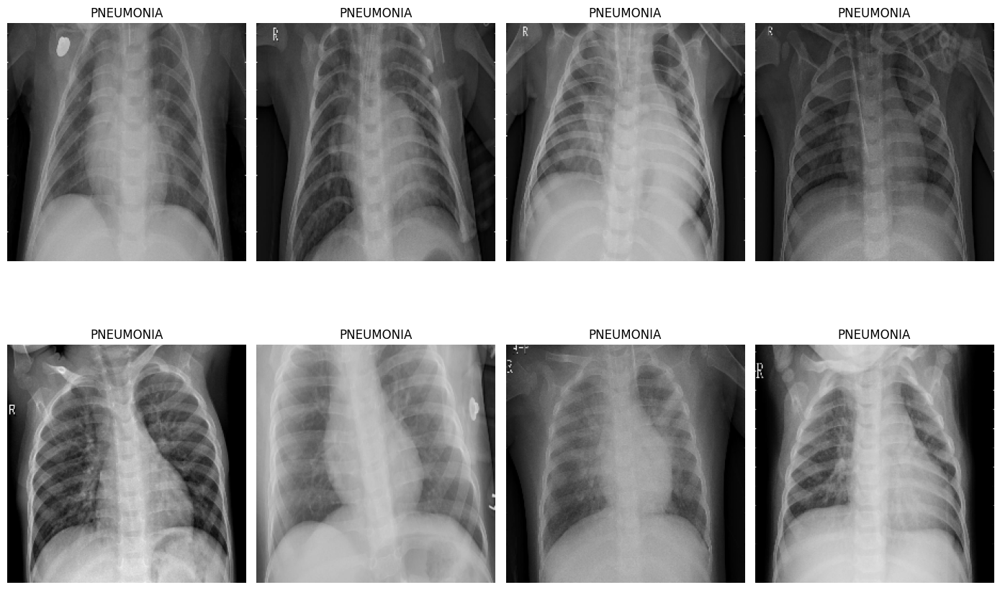

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os

# Define the correct path
splits_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits"

# Load cleaned training dataset
train_df = pd.read_csv(
    os.path.join(splits_path, "train_clean.csv")
)

print("Training images loaded:", len(train_df))
print("\nClass distribution:")
print(train_df["label"].value_counts())

# Select 8 sample images
sample_df = train_df.sample(
    n=8,
    random_state=42
).reset_index(drop=True)

# Display images
plt.figure(figsize=(14, 10))

for i, row in sample_df.iterrows():

    image = cv2.imread(row["filepath"])

    if image is None:
        print("Could not load:", row["filepath"])
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (224, 224))

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(row["label"])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Inspect both classes

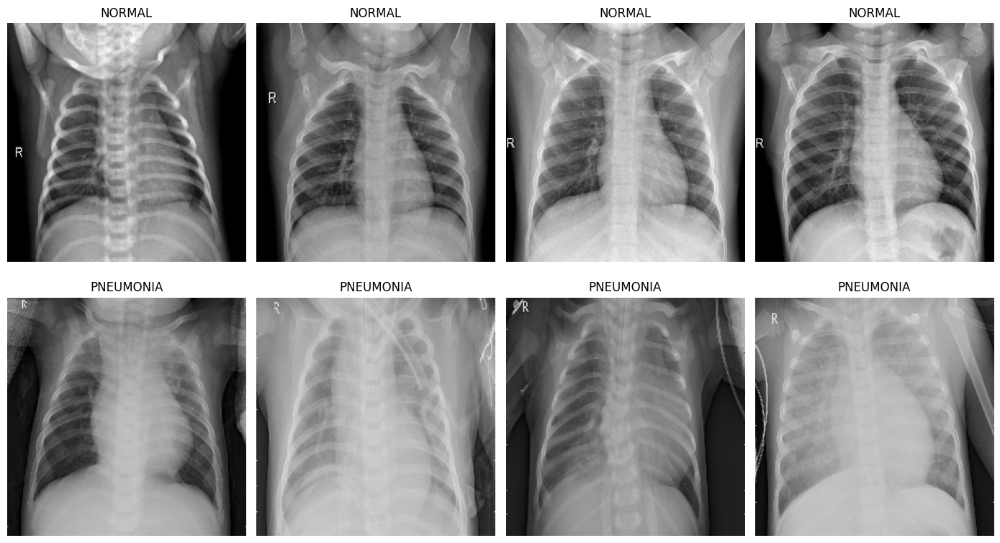

In [ ]:
import matplotlib.pyplot as plt
import cv2

# Select 4 images from each class
normal_samples = train_df[
    train_df["label"] == "NORMAL"
].sample(4, random_state=42)

pneumonia_samples = train_df[
    train_df["label"] == "PNEUMONIA"
].sample(4, random_state=42)

# Combine samples
balanced_samples = pd.concat([
    normal_samples,
    pneumonia_samples
]).reset_index(drop=True)

# Display images
plt.figure(figsize=(14, 8))

for i, row in balanced_samples.iterrows():

    image = cv2.imread(row["filepath"])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (224, 224))

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(row["label"])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Build the image-loading and label-encoding function

In [ ]:
import tensorflow as tf
import numpy as np

# ==========================================
# STEP 16A: IMAGE LOADING FUNCTION
# ==========================================

def load_and_preprocess_image(image_path, label, image_size):

    # Read image file
    image = tf.io.read_file(image_path)

    # Decode image into 3 RGB channels
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Set image shape
    image.set_shape([None, None, 3])

    # Resize while preserving aspect ratio
    image = tf.image.resize_with_pad(
        image,
        image_size[0],
        image_size[1]
    )

    # Ensure float32 pixel values (0–255)
    image = tf.cast(image, tf.float32)

    # Encode labels
    label = tf.where(
        tf.equal(label, "NORMAL"),
        0,
        1
    )

    return image, label


print("Image-loading function created successfully.")

Image-loading function created successfully.


# Test the function

In [ ]:
# Select one NORMAL image and one PNEUMONIA image

normal_row = train_df[
    train_df["label"] == "NORMAL"
].iloc[0]

pneumonia_row = train_df[
    train_df["label"] == "PNEUMONIA"
].iloc[0]


# Process NORMAL image
normal_image, normal_label = load_and_preprocess_image(
    normal_row["filepath"],
    normal_row["label"],
    (224, 224)
)

# Process PNEUMONIA image
pneumonia_image, pneumonia_label = load_and_preprocess_image(
    pneumonia_row["filepath"],
    pneumonia_row["label"],
    (224, 224)
)


# Display results
print("NORMAL IMAGE")
print("Image shape:", normal_image.shape)
print("Label:", normal_label.numpy())
print("Minimum pixel value:", tf.reduce_min(normal_image).numpy())
print("Maximum pixel value:", tf.reduce_max(normal_image).numpy())

print("\nPNEUMONIA IMAGE")
print("Image shape:", pneumonia_image.shape)
print("Label:", pneumonia_label.numpy())
print("Minimum pixel value:", tf.reduce_min(pneumonia_image).numpy())
print("Maximum pixel value:", tf.reduce_max(pneumonia_image).numpy())

NORMAL IMAGE
Image shape: (224, 224, 3)
Label: 0
Minimum pixel value: 0.0
Maximum pixel value: 255.0

PNEUMONIA IMAGE
Image shape: (224, 224, 3)
Label: 1
Minimum pixel value: 0.0
Maximum pixel value: 254.83746


# Implement model-specific preprocessing

In [ ]:
# ==========================================
# STEP 17: MODEL-SPECIFIC PREPROCESSING
# ==========================================

def apply_model_preprocessing(image, model_name):

    if model_name == "PneumoCNN":

        # Scale pixels from 0-255 to 0-1
        image = image / 255.0

    elif model_name == "VGG16":

        image = tf.keras.applications.vgg16.preprocess_input(
            image
        )

    elif model_name == "ResNet50":

        image = tf.keras.applications.resnet50.preprocess_input(
            image
        )

    elif model_name == "DenseNet121":

        image = tf.keras.applications.densenet.preprocess_input(
            image
        )

    elif model_name == "InceptionV3":

        image = tf.keras.applications.inception_v3.preprocess_input(
            image
        )

    else:
        raise ValueError("Unknown model name")

    return image


print("Model-specific preprocessing functions created.")

Model-specific preprocessing functions created.


# Test all five preprocessing **methods**

In [ ]:
# Test image for each architecture
models = [
    "PneumoCNN",
    "VGG16",
    "ResNet50",
    "DenseNet121",
    "InceptionV3"
]

for model_name in models:

    image_size = IMAGE_SIZE[model_name]

    # Load one NORMAL image
    image, label = load_and_preprocess_image(
        normal_row["filepath"],
        normal_row["label"],
        image_size
    )

    # Apply architecture-specific preprocessing
    processed_image = apply_model_preprocessing(
        image,
        model_name
    )

    print("\nModel:", model_name)
    print("Image shape:", processed_image.shape)
    print("Minimum value:", tf.reduce_min(processed_image).numpy())
    print("Maximum value:", tf.reduce_max(processed_image).numpy())


Model: PneumoCNN
Image shape: (224, 224, 3)
Minimum value: 0.0
Maximum value: 1.0

Model: VGG16
Image shape: (224, 224, 3)
Minimum value: -123.68
Maximum value: 151.061

Model: ResNet50
Image shape: (224, 224, 3)
Minimum value: -123.68
Maximum value: 151.061

Model: DenseNet121
Image shape: (224, 224, 3)
Minimum value: -2.117904
Maximum value: 2.64

Model: InceptionV3
Image shape: (299, 299, 3)
Minimum value: -1.0
Maximum value: 1.0


# Build the TensorFlow data **pipeline**

In [ ]:
# ==========================================
# STEP 18: TENSORFLOW DATA PIPELINE
# ==========================================

AUTOTUNE = tf.data.AUTOTUNE

def create_dataset(df, model_name, training=False):

    image_size = IMAGE_SIZE[model_name]

    # Extract image paths and labels
    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    # Create TensorFlow dataset
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    # Shuffle training data only
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=RANDOM_SEED,
            reshuffle_each_iteration=True
        )

    # Load and preprocess each image
    def process_image(image_path, label):

        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image,
            image_size[0],
            image_size[1]
        )

        image = tf.cast(image, tf.float32)

        image = apply_model_preprocessing(
            image,
            model_name
        )

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=AUTOTUNE
    )

    # Batch images
    dataset = dataset.batch(BATCH_SIZE)

    # Improve data loading efficiency
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


print("TensorFlow dataset pipeline created successfully.")

TensorFlow dataset pipeline created successfully.


# Test the pipeline with **PneumoCNN**

In [ ]:
# Create PneumoCNN training dataset
train_dataset = create_dataset(
    train_df,
    "PneumoCNN",
    training=True
)

# Retrieve one batch
images, labels = next(iter(train_dataset))

print("IMAGE BATCH DETAILS")
print("-------------------------")

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:",
      tf.reduce_min(images).numpy())

print("Maximum pixel value:",
      tf.reduce_max(images).numpy())

print("\nLabels in batch:")
print("NORMAL:", tf.reduce_sum(
    tf.cast(labels == 0, tf.int32)
).numpy())

print("PNEUMONIA:", tf.reduce_sum(
    tf.cast(labels == 1, tf.int32)
).numpy())

IMAGE BATCH DETAILS
-------------------------
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0

Labels in batch:
NORMAL: 7
PNEUMONIA: 25


# **Test all five model pipelines**

In [ ]:
# ==========================================
# STEP 18C: TEST ALL FIVE MODEL PIPELINES
# ==========================================

models = [
    "PneumoCNN",
    "VGG16",
    "ResNet50",
    "DenseNet121",
    "InceptionV3"
]

for model_name in models:

    print("\n================================")
    print("MODEL:", model_name)
    print("================================")

    dataset = create_dataset(
        train_df,
        model_name,
        training=True
    )

    images, labels = next(iter(dataset))

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print(
        "Minimum pixel value:",
        tf.reduce_min(images).numpy()
    )

    print(
        "Maximum pixel value:",
        tf.reduce_max(images).numpy()
    )

print("\nAll five pipeline tests completed.")


MODEL: PneumoCNN
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0

MODEL: VGG16
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: -123.68
Maximum pixel value: 151.061

MODEL: ResNet50
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: -123.68
Maximum pixel value: 151.061

MODEL: DenseNet121
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: -2.117904
Maximum pixel value: 2.64

MODEL: InceptionV3
Image batch shape: (32, 299, 299, 3)
Label batch shape: (32,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0

All five pipeline tests completed.


## Create the data augmentation pipeline

In [ ]:
# ==========================================
# STEP 19A: DATA AUGMENTATION
# ==========================================

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomRotation(
        factor=0.0278,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomFlip(
        mode="horizontal"
    ),

    tf.keras.layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255)
    )

], name="chest_xray_augmentation")

print("Data augmentation pipeline created successfully.")

data_augmentation.summary()

Data augmentation pipeline created successfully.


Model: "chest_xray_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ ?                      │   0 (unbuilt) │
│ (RandomBrightness)              │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

# **Inspect the augmented images**

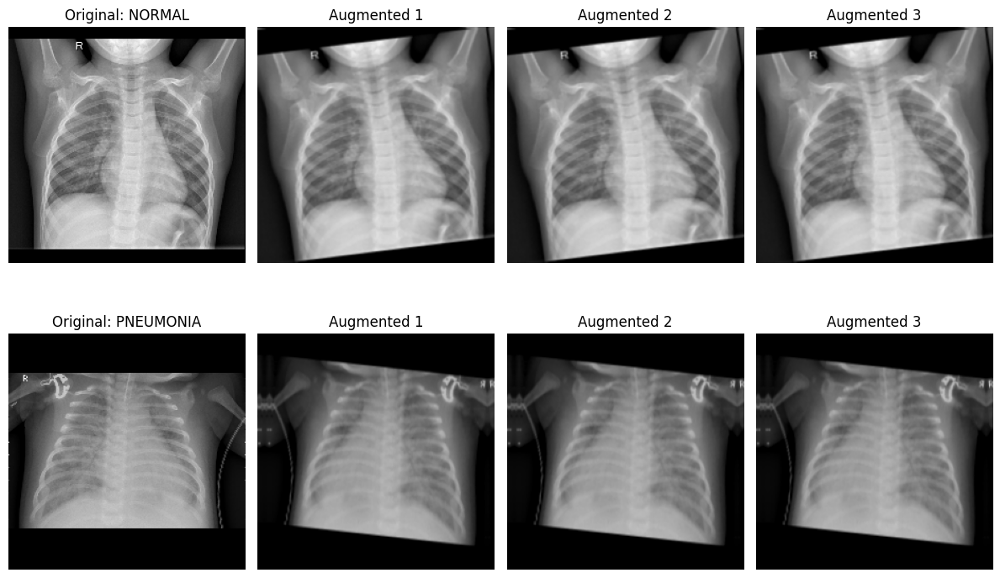

In [ ]:
# Select one NORMAL and one PNEUMONIA image
sample_images = [normal_image, pneumonia_image]

sample_labels = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(12, 8))

for i in range(2):

    original = sample_images[i]

    # Generate three augmented versions
    augmented = data_augmentation(
        tf.expand_dims(original, axis=0),
        training=True
    )

    plt.subplot(2, 4, i * 4 + 1)
    plt.imshow(original.numpy().astype("uint8"))
    plt.title(f"Original: {sample_labels[i]}")
    plt.axis("off")

    for j in range(3):

        plt.subplot(2, 4, i * 4 + j + 2)

        plt.imshow(
            tf.clip_by_value(
                augmented[0],
                0,
                255
            ).numpy().astype("uint8")
        )

        plt.title(f"Augmented {j + 1}")
        plt.axis("off")

plt.tight_layout()
plt.show()

# Integrate augmentation into the training **pipeline**

In [ ]:
# ==========================================
# STEP 20: UPDATED DATA PIPELINE
# ==========================================

def create_dataset(df, model_name, training=False):

    image_size = IMAGE_SIZE[model_name]

    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=RANDOM_SEED,
            reshuffle_each_iteration=True
        )

    def process_image(image_path, label):

        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image,
            image_size[0],
            image_size[1]
        )

        image = tf.cast(image, tf.float32)

        # Augmentation applies ONLY to training images
        if training:
            image = data_augmentation(
                tf.expand_dims(image, axis=0),
                training=True
            )[0]

        # Apply model-specific preprocessing
        image = apply_model_preprocessing(
            image,
            model_name
        )

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


print("Updated training pipeline created successfully.")

Updated training pipeline created successfully.


# **Verify training and validation pipelines**

In [ ]:
# Create training dataset
train_dataset = create_dataset(
    train_df,
    "PneumoCNN",
    training=True
)

# Create validation dataset
val_df = pd.read_csv(
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/splits/val_clean.csv"
)

val_dataset = create_dataset(
    val_df,
    "PneumoCNN",
    training=False
)

# Inspect one batch from each
train_images, train_labels = next(iter(train_dataset))
val_images, val_labels = next(iter(val_dataset))

print("TRAINING DATA")
print("Image shape:", train_images.shape)
print("Label shape:", train_labels.shape)

print("\nVALIDATION DATA")
print("Image shape:", val_images.shape)
print("Label shape:", val_labels.shape)

print("\nValidation pixel range:")
print("Minimum:", tf.reduce_min(val_images).numpy())
print("Maximum:", tf.reduce_max(val_images).numpy())

TRAINING DATA
Image shape: (32, 224, 224, 3)
Label shape: (32,)

VALIDATION DATA
Image shape: (32, 224, 224, 3)
Label shape: (32,)

Validation pixel range:
Minimum: 0.0
Maximum: 1.0


handling class imbalance and Calculate class weights

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Convert training labels to numerical values
y_train = train_df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).values

# Calculate balanced class weights
classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = {
    0: class_weights[0],
    1: class_weights[1]
}

print("CLASS WEIGHTS")
print("NORMAL (0):", class_weight_dict[0])
print("PNEUMONIA (1):", class_weight_dict[1])

CLASS WEIGHTS
NORMAL (0): 1.9313543599257885
PNEUMONIA (1): 0.6746597537265068


# **Set the training parameters**

In [ ]:
# ==========================================
# COMMON TRAINING CONFIGURATION
# ==========================================

EPOCHS = 100
BATCH_SIZE = 32

LEARNING_RATE = 0.0001

EARLY_STOPPING_PATIENCE = 10
LR_REDUCTION_PATIENCE = 3

LR_REDUCTION_FACTOR = 0.2
MIN_LEARNING_RATE = 0.000001

RANDOM_SEED = 42

print("TRAINING CONFIGURATION")
print("----------------------")
print("Maximum epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("LR reduction patience:", LR_REDUCTION_PATIENCE)
print("LR reduction factor:", LR_REDUCTION_FACTOR)
print("Minimum learning rate:", MIN_LEARNING_RATE)
print("Random seed:", RANDOM_SEED)

TRAINING CONFIGURATION
----------------------
Maximum epochs: 100
Batch size: 32
Learning rate: 0.0001
Early stopping patience: 10
LR reduction patience: 3
LR reduction factor: 0.2
Minimum learning rate: 1e-06
Random seed: 42


# Prepare the model output **directory**

In [ ]:
import os

# Main project directory
PROJECT_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

# Create directories for research outputs
MODEL_DIR = os.path.join(PROJECT_DIR, "saved_models")
HISTORY_DIR = os.path.join(PROJECT_DIR, "training_histories")
RESULTS_DIR = os.path.join(PROJECT_DIR, "evaluation_results")

for folder in [MODEL_DIR, HISTORY_DIR, RESULTS_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Research output directories created successfully.")

print("\nMODEL DIRECTORY:")
print(MODEL_DIR)

print("\nTRAINING HISTORY DIRECTORY:")
print(HISTORY_DIR)

print("\nEVALUATION RESULTS DIRECTORY:")
print(RESULTS_DIR)

Research output directories created successfully.

MODEL DIRECTORY:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models

TRAINING HISTORY DIRECTORY:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/training_histories

EVALUATION RESULTS DIRECTORY:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results


PneumoCNN – Custom Convolutional Neural Network.
# Define the PneumoCNN **architecture**

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

def build_pneumocnn(input_shape=(224, 224, 3)):

    inputs = layers.Input(shape=input_shape)

    # Convolutional Block 1
    x = layers.Conv2D(
        32, (3, 3),
        padding="same",
        kernel_regularizer=regularizers.l2(0.0001)
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Convolutional Block 2
    x = layers.Conv2D(
        64, (3, 3),
        padding="same",
        kernel_regularizer=regularizers.l2(0.0001)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Convolutional Block 3
    x = layers.Conv2D(
        128, (3, 3),
        padding="same",
        kernel_regularizer=regularizers.l2(0.0001)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Convolutional Block 4
    x = layers.Conv2D(
        256, (3, 3),
        padding="same",
        kernel_regularizer=regularizers.l2(0.0001)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Classification Head
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.0001)
    )(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid",
        name="pneumonia_output"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="PneumoCNN"
    )

    return model


# Build the model
pneumocnn = build_pneumocnn()

print("PneumoCNN architecture created successfully.")

PneumoCNN architecture created successfully.


Inspect the architecture

In [ ]:
pneumocnn.summary()

Model: "PneumoCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Compile PneumoCNN with Adam Optimizer

In [ ]:
# Compile the custom CNN

pneumocnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy"
    ]
)

print("PneumoCNN compiled successfully.")

print("\nOptimizer:", pneumocnn.optimizer.__class__.__name__)
print("Learning rate:", float(pneumocnn.optimizer.learning_rate.numpy()))
print("Loss function:", pneumocnn.loss)

PneumoCNN compiled successfully.

Optimizer: Adam
Learning rate: 9.999999747378752e-05
Loss function: binary_crossentropy


# Configure training **callbacks**

In [ ]:
# ==========================================
# PNEUMOCNN TRAINING CALLBACKS
# ==========================================

# 1. Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

# 2. Learning Rate Reduction
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_REDUCTION_FACTOR,
    patience=LR_REDUCTION_PATIENCE,
    min_lr=MIN_LEARNING_RATE,
    verbose=1
)

# 3. Model Checkpoint
checkpoint_path = os.path.join(
    MODEL_DIR,
    "pneumocnn_best.keras"
)

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Combine callbacks
pneumocnn_callbacks = [
    early_stopping,
    reduce_lr,
    model_checkpoint
]

print("PneumoCNN callbacks configured successfully.")
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Learning rate reduction patience:", LR_REDUCTION_PATIENCE)
print("Best model will be saved at:")
print(checkpoint_path)

PneumoCNN callbacks configured successfully.
Early stopping patience: 10
Learning rate reduction patience: 3
Best model will be saved at:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/pneumocnn_best.keras


# Train your custom **CNN**

In [ ]:
# ==========================================
# TRAIN THE CUSTOM CNN (PNEUMOCNN)
# ==========================================

history_pneumocnn = pneumocnn.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=pneumocnn_callbacks,
    verbose=1
)

print("\nPneumoCNN training completed.")

Epoch 1/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7719 - loss: 0.5225
Epoch 1: val_loss improved from None to 0.92100, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/pneumocnn_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/pneumocnn_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 1075s 8s/step - accuracy: 0.8237 - loss: 0.4385 - val_accuracy: 0.7409 - val_loss: 0.9210 - learning_rate: 1.0000e-04
Epoch 2/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 735ms/step - accuracy: 0.8723 - loss: 0.3442
Epoch 2: val_loss did not improve from 0.92100
131/131 ━━━━━━━━━━━━━━━━━━━━ 103s 787ms/step - accuracy: 0.8739 - loss: 0.3473 - val_accuracy: 0.7409 - val_loss: 1.0795 - learning_rate: 1.0000e-04
Epoch 3/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 740ms/step - accuracy: 0.8850 - loss: 0.3216
Epoch 3: val_loss improved from 0.92100 to 0.88403, saving model to /content/drive/MyDrive/MPhil_Pneumonia_De

# Identify the best epoch's **performance**

In [ ]:
import numpy as np
import pandas as pd

# Extract training history
pneumocnn_history_df = pd.DataFrame(history_pneumocnn.history)

# Find epoch with lowest validation loss
best_epoch = np.argmin(
    pneumocnn_history_df["val_loss"].values
) + 1

best_results = pneumocnn_history_df.iloc[best_epoch - 1]

print("PNEUMOCNN BEST EPOCH RESULTS")
print("----------------------------")
print("Best epoch:", best_epoch)

print("Training accuracy:",
      round(best_results["accuracy"], 4))

print("Training loss:",
      round(best_results["loss"], 4))

print("Validation accuracy:",
      round(best_results["val_accuracy"], 4))

print("Validation loss:",
      round(best_results["val_loss"], 4))

PNEUMOCNN BEST EPOCH RESULTS
----------------------------
Best epoch: 12
Training accuracy: 0.9179
Training loss: 0.2449
Validation accuracy: 0.9367
Validation loss: 0.2255


# Save PneumoCNN training **history**

In [ ]:
# Save PneumoCNN training history

history_path = os.path.join(
    HISTORY_DIR,
    "pneumocnn_training_history.csv"
)

pneumocnn_history_df.to_csv(
    history_path,
    index=False
)

print("PneumoCNN training history saved successfully.")
print("Location:", history_path)

# Confirm saved model exists
print("\nBest model checkpoint exists:",
      os.path.exists(checkpoint_path))

PneumoCNN training history saved successfully.
Location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/training_histories/pneumocnn_training_history.csv

Best model checkpoint exists: True


Google Drive for the original model and validation dataset.

In [ ]:
import os

search_location = "/content/drive/MyDrive"

print("SEARCHING GOOGLE DRIVE...")
print("--------------------------------")

found = []

for root, dirs, files in os.walk(search_location):
    for file in files:
        if file in [
            "pneumocnn_best.keras",
            "val_clean.csv",
            "test_clean.csv"
        ]:
            path = os.path.join(root, file)
            found.append(path)
            print("FOUND:", path)

print("--------------------------------")

if not found:
    print("No matching files found in My Drive.")

SEARCHING GOOGLE DRIVE...
--------------------------------
--------------------------------
No matching files found in My Drive.


Verify the files in Google Colab

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

VAL_CSV = os.path.join(PROJECT_DIR, "splits", "val_clean.csv")
MODEL_PATH = os.path.join(
    PROJECT_DIR, "saved_models", "pneumocnn_best.keras"
)

print("Validation CSV exists:", os.path.exists(VAL_CSV))
print("Custom CNN model exists:", os.path.exists(MODEL_PATH))

if os.path.exists(VAL_CSV):
    print("Validation CSV:", VAL_CSV)

if os.path.exists(MODEL_PATH):
    print("Custom CNN model:", MODEL_PATH)

Validation CSV exists: False
Custom CNN model exists: False


In [ ]:
import os

base = "/content/drive/MyDrive"

print("MY DRIVE FOLDERS:")
for item in os.listdir(base):
    print(item)

print("\nSEARCHING FOR YOUR RESEARCH FOLDER:")

for root, dirs, files in os.walk(base):
    for folder in dirs:
        if "MPhil_Pneumonia" in folder:
            print("FOUND FOLDER:", os.path.join(root, folder))

MY DRIVE FOLDERS:
MPhil_Pneumonia_Detection_Research
Getting started.pdf
ty (1).jpg
ty.jpg
Programming week 1.pptx
Programming Week 5.pptx
ElectroStats (2).ppt
Programming Assignment.docx
POWERPOINT.zip
2017-2018 First Semester Examination Timetable - 05.12.2017..xlsx
google-asscociate android developer content.pdf
PAUL DAWKINS CALC_II.pdf
encapsulation for car.cbp
assignment one.cbp
NetsparkerSetup.exe
CURRICULUM VITAE.docx
linear-guest.pdf 2.pdf
assignment2.zip
Classroom
DATA STRUCTURE OBJECTIVES .doc
Admissions_DevFin.pdf
BSc_ComputerScience (1).pdf
hwsoln06.pdf
CSC303A - Lecture1.pdf
CSC303A - Lecture3.pdf
Undergraduate-Forms1.pdf
CSC303A - Lecture2.pdf
Lecture 1 .pdf
Lecture 7.pdf
V Cs Report 2016.pdf
BScICT.pdf
CSC303A - Lecture4.pdf
web.ws25pkg.ws25_por
Lecture 9.pdf
DSA Exam.pdf
critical-section.pdf
Operating_Systems.pdf
Group 1 Marking Scheme.pdf
hwsoln06(1).pdf
AWUTU_SENYA_EAST_COORDINATE.pdf
OfficeProfessionalPlus_x64_en-us.img
Project Proposal Template (1).gdoc
Project Prop

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

print("Research folder exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("\nResearch folder contents:")
    for item in os.listdir(PROJECT_DIR):
        print("-", item)

    print("\nChecking required files:")
    files_to_check = [
        "splits/val_clean.csv",
        "saved_models/pneumocnn_best.keras",
        "saved_models/vgg16_best.keras",
        "saved_models/resnet50_best.keras",
        "saved_models/densenet121_best.keras",
        "saved_models/inceptionv3_best.keras"
    ]

    for file in files_to_check:
        path = os.path.join(PROJECT_DIR, file)
        print(file, ":", os.path.exists(path))

Research folder exists: True

Research folder contents:
- Untitled0.ipynb
- chest_xray
- splits
- saved_models
- training_histories
- evaluation_results
- defence_outputs

Checking required files:
splits/val_clean.csv : True
saved_models/pneumocnn_best.keras : True
saved_models/vgg16_best.keras : True
saved_models/resnet50_best.keras : True
saved_models/densenet121_best.keras : True
saved_models/inceptionv3_best.keras : True


Inspect the validation dataset

In [ ]:
import pandas as pd
import os

PROJECT_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

VAL_CSV = os.path.join(PROJECT_DIR, "splits", "val_clean.csv")

val_df = pd.read_csv(VAL_CSV)

print("VALIDATION DATASET INFORMATION")
print("--------------------------------")

print("Total validation images:", len(val_df))

print("\nColumn names:")
print(val_df.columns.tolist())

print("\nFirst 5 records:")
print(val_df.head().to_string(index=False))

print("\nClass distribution:")
print(val_df["label"].value_counts())

print("\nChecking first image path:")
first_path = str(val_df.iloc[0]["filepath"])
print("Image path:", first_path)
print("Image exists:", os.path.exists(first_path))

VALIDATION DATASET INFORMATION
--------------------------------
Total validation images: 1042

Column names:
['filepath', 'label']

First 5 records:
                                                                                           filepath  label
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/NORMAL/IM-0140-0001.jpeg NORMAL
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/NORMAL/IM-0143-0001.jpeg NORMAL
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/NORMAL/IM-0147-0001.jpeg NORMAL
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/NORMAL/IM-0149-0001.jpeg NORMAL
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/NORMAL/IM-0152-0001.jpeg NORMAL

Class distribution:
label
PNEUMONIA    772
NORMAL       270
Name: count, dtype: int64

Checking first image path:
Image path: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/NORMAL/

Load and inspect your original Custom CNN

In [ ]:
import tensorflow as tf
import os

PROJECT_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

MODEL_PATH = os.path.join(
    PROJECT_DIR, "saved_models", "pneumocnn_best.keras"
)

custom_cnn = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("CUSTOM CNN LOADED SUCCESSFULLY")
print("--------------------------------")
print("Input shape:", custom_cnn.input_shape)
print("Output shape:", custom_cnn.output_shape)
print("Number of layers:", len(custom_cnn.layers))

print("\nModel summary:")
custom_cnn.summary()

CUSTOM CNN LOADED SUCCESSFULLY
--------------------------------
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Number of layers: 21

Model summary:


Model: "PneumoCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Check your original training code

In [ ]:
import json
import os

notebook_path = (
    "/content/drive/MyDrive/"
    "MPhil_Pneumonia_Detection_Research/Untitled0.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "ImageDataGenerator",
    "flow_from_dataframe",
    "image_dataset_from_directory",
    "resize_with_pad",
    "rescale",
    "preprocess_input",
    "target_size"
]

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if any(word in source for word in keywords):
        print(f"\n--- CELL {i} ---")
        print(source[:4000])


--- CELL 46 ---
import tensorflow as tf
import numpy as np

# ==========================================
# STEP 16A: IMAGE LOADING FUNCTION
# ==========================================

def load_and_preprocess_image(image_path, label, image_size):

    # Read image file
    image = tf.io.read_file(image_path)

    # Decode image into 3 RGB channels
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Set image shape
    image.set_shape([None, None, 3])

    # Resize while preserving aspect ratio
    image = tf.image.resize_with_pad(
        image,
        image_size[0],
        image_size[1]
    )

    # Ensure float32 pixel values (0–255)
    image = tf.cast(image, tf.float32)

    # Encode labels
    label = tf.where(
        tf.equal(label, "NORMAL"),
        0,
        1
    )

    return image, label


print("Image-loading function created successfully.")

--- CELL 50 ---
# ==========================================
# STE

Calculate Custom CNN validation results at threshold 0.50

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

# Original validation dataset
val_df = pd.read_csv(VAL_CSV)

# Encode labels: NORMAL=0, PNEUMONIA=1
y_true = val_df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).values.astype(np.int32)

# Reconstruct the original Custom CNN preprocessing
def process_pneumocnn_validation(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(image, 224, 224)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_df["filepath"].values, y_true)
)

val_dataset = val_dataset.map(
    process_pneumocnn_validation,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_dataset = val_dataset.batch(32).prefetch(tf.data.AUTOTUNE)

# Generate predictions using the saved model
y_prob = custom_cnn.predict(val_dataset, verbose=1).ravel()

# Apply common threshold of 0.50
threshold = 0.50
y_pred = (y_prob >= threshold).astype(np.int32)

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

# Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
sensitivity = recall_score(y_true, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) else 0
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)
mcc = matthews_corrcoef(y_true, y_pred)

# Display results
print("CUSTOM CNN VALIDATION RESULTS (Threshold = 0.50)")
print("=" * 55)

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nClassification Metrics:")
print(f"Accuracy:     {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision:    {precision:.4f} ({precision*100:.2f}%)")
print(f"Sensitivity:  {sensitivity:.4f} ({sensitivity*100:.2f}%)")
print(f"Specificity:  {specificity:.4f} ({specificity*100:.2f}%)")
print(f"F1-Score:     {f1:.4f} ({f1*100:.2f}%)")
print(f"ROC-AUC:      {roc_auc:.4f} ({roc_auc*100:.2f}%)")
print(f"MCC:          {mcc:.4f}")

33/33 ━━━━━━━━━━━━━━━━━━━━ 166s 5s/step
CUSTOM CNN VALIDATION RESULTS (Threshold = 0.50)

Confusion Matrix:
[[250  20]
 [ 46 726]]

TN: 250
FP: 20
FN: 46
TP: 726

Classification Metrics:
Accuracy:     0.9367 (93.67%)
Precision:    0.9732 (97.32%)
Sensitivity:  0.9404 (94.04%)
Specificity:  0.9259 (92.59%)
F1-Score:     0.9565 (95.65%)
ROC-AUC:      0.9814 (98.14%)
MCC:          0.8417


# Next: Build **VGG16**
# **Load** the VGG16 pretrained model

In [ ]:
# ==========================================
# LOAD PRETRAINED VGG16
# ==========================================

vgg16_base = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
vgg16_base.trainable = False

print("VGG16 loaded successfully.")
print("Pretrained weights: ImageNet")
print("Input shape:", vgg16_base.input_shape)
print("Output shape:", vgg16_base.output_shape)
print("Total layers:", len(vgg16_base.layers))
print("Trainable:", vgg16_base.trainable)

VGG16 loaded successfully.
Pretrained weights: ImageNet
Input shape: (None, 224, 224, 3)
Output shape: (None, 7, 7, 512)
Total layers: 19
Trainable: False


# Build the VGG16 classification **head**

In [ ]:
# ==========================================
# BUILD VGG16 TRANSFER LEARNING MODEL
# ==========================================

vgg16_inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

# Extract features using pretrained VGG16
x = vgg16_base(vgg16_inputs, training=False)

# Classification head
x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(0.0001)
)(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Dropout(0.5)(x)

vgg16_outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="pneumonia_output"
)(x)

# Create complete model
vgg16_model = tf.keras.Model(
    inputs=vgg16_inputs,
    outputs=vgg16_outputs,
    name="VGG16_Pneumonia_Classifier"
)

print("VGG16 classification model created successfully.")

VGG16 classification model created successfully.


# Inspect the **architecture**

In [ ]:
vgg16_model.summary()

Model: "VGG16_Pneumonia_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,297 (56.64 MB)

 Trainable params: 132,097 (516.00 KB)

 Non-trainable params: 14,715,200 (56.13 MB)

# Compile **VGG16**

In [ ]:
# ==========================================
# COMPILE VGG16
# ==========================================

vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("VGG16 compiled successfully.")
print("Optimizer:", vgg16_model.optimizer.__class__.__name__)
print(
    "Learning rate:",
    float(vgg16_model.optimizer.learning_rate.numpy())
)
print("Loss function:", vgg16_model.loss)

VGG16 compiled successfully.
Optimizer: Adam
Learning rate: 9.999999747378752e-05
Loss function: binary_crossentropy


Configure VGG16 training callbacks

In [ ]:
# ==========================================
# VGG16 TRAINING CALLBACKS
# ==========================================

vgg16_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

vgg16_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_REDUCTION_FACTOR,
    patience=LR_REDUCTION_PATIENCE,
    min_lr=MIN_LEARNING_RATE,
    verbose=1
)

vgg16_checkpoint_path = os.path.join(
    MODEL_DIR,
    "vgg16_best.keras"
)

vgg16_model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=vgg16_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

vgg16_callbacks = [
    vgg16_early_stopping,
    vgg16_reduce_lr,
    vgg16_model_checkpoint
]

print("VGG16 callbacks configured successfully.")
print("Checkpoint location:", vgg16_checkpoint_path)

VGG16 callbacks configured successfully.
Checkpoint location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/vgg16_best.keras


Prepare the VGG16 datasets

In [ ]:
# ==========================================
# PREPARE VGG16 DATASETS
# ==========================================

# Create VGG16 training dataset
vgg16_train_dataset = create_dataset(
    train_df,
    "VGG16",
    training=True
)

# Create VGG16 validation dataset
vgg16_val_dataset = create_dataset(
    val_df,
    "VGG16",
    training=False
)

# Inspect training batch
vgg_train_images, vgg_train_labels = next(
    iter(vgg16_train_dataset)
)

# Inspect validation batch
vgg_val_images, vgg_val_labels = next(
    iter(vgg16_val_dataset)
)

print("VGG16 TRAINING DATA")
print("Image shape:", vgg_train_images.shape)
print("Label shape:", vgg_train_labels.shape)

print("\nVGG16 VALIDATION DATA")
print("Image shape:", vgg_val_images.shape)
print("Label shape:", vgg_val_labels.shape)

print("\nValidation pixel range:")
print("Minimum:", tf.reduce_min(vgg_val_images).numpy())
print("Maximum:", tf.reduce_max(vgg_val_images).numpy())

VGG16 TRAINING DATA
Image shape: (32, 224, 224, 3)
Label shape: (32,)

VGG16 VALIDATION DATA
Image shape: (32, 224, 224, 3)
Label shape: (32,)

Validation pixel range:
Minimum: -123.68
Maximum: 151.061


Train VGG16

In [ ]:
# ==========================================
# TRAIN VGG16
# ==========================================

history_vgg16 = vgg16_model.fit(
    vgg16_train_dataset,
    validation_data=vgg16_val_dataset,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=vgg16_callbacks,
    verbose=1
)

print("\nVGG16 training completed.")

Epoch 1/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 873ms/step - accuracy: 0.9498 - loss: 0.1605
Epoch 1: val_loss did not improve from 0.23226
131/131 ━━━━━━━━━━━━━━━━━━━━ 126s 958ms/step - accuracy: 0.9486 - loss: 0.1619 - val_accuracy: 0.9223 - val_loss: 0.2782 - learning_rate: 1.0000e-06
Epoch 2/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 877ms/step - accuracy: 0.9411 - loss: 0.1813
Epoch 2: val_loss did not improve from 0.23226
131/131 ━━━━━━━━━━━━━━━━━━━━ 124s 946ms/step - accuracy: 0.9462 - loss: 0.1698 - val_accuracy: 0.9232 - val_loss: 0.2702 - learning_rate: 1.0000e-06
Epoch 3/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 860ms/step - accuracy: 0.9433 - loss: 0.1659
Epoch 3: val_loss did not improve from 0.23226
131/131 ━━━━━━━━━━━━━━━━━━━━ 141s 941ms/step - accuracy: 0.9436 - loss: 0.1631 - val_accuracy: 0.9203 - val_loss: 0.2773 - learning_rate: 1.0000e-06
Epoch 4/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 839ms/step - accuracy: 0.9548 - loss: 0.1633
Epoch 4: val_loss did not improve from 0.23226
131/131 ━

# Inspect the second training **run**
# INSPECT VGG16 TRAINING **HISTORY**

In [ ]:
# ==========================================
# INSPECT VGG16 TRAINING HISTORY
# ==========================================

vgg16_history_df = pd.DataFrame(history_vgg16.history)

# Display important training metrics
columns_to_show = [
    "accuracy",
    "loss",
    "val_accuracy",
    "val_loss"
]

# Include learning rate if available
if "learning_rate" in vgg16_history_df.columns:
    columns_to_show.append("learning_rate")
elif "lr" in vgg16_history_df.columns:
    columns_to_show.append("lr")

vgg16_history_df.index = range(1, len(vgg16_history_df) + 1)
vgg16_history_df.index.name = "Epoch"

print("VGG16 EPOCH-BY-EPOCH RESULTS")
display(vgg16_history_df[columns_to_show].round(4))

# Identify best epoch
best_epoch_vgg16 = (
    vgg16_history_df["val_loss"].idxmin()
)

print("\nBest epoch:", best_epoch_vgg16)
print(
    "Best validation loss:",
    round(vgg16_history_df.loc[best_epoch_vgg16, "val_loss"], 4)
)
print(
    "Validation accuracy at best epoch:",
    round(vgg16_history_df.loc[best_epoch_vgg16, "val_accuracy"], 4)
)

VGG16 EPOCH-BY-EPOCH RESULTS


,accuracy,loss,val_accuracy,val_loss,learning_rate
Epoch,,,,,
1,0.9486,0.1619,0.9223,0.2782,0.0
2,0.9462,0.1698,0.9232,0.2702,0.0
3,0.9436,0.1631,0.9203,0.2773,0.0
4,0.9481,0.1623,0.9242,0.2670,0.0
5,0.9460,0.1618,0.9223,0.2713,0.0
6,0.9448,0.1647,0.9213,0.2752,0.0
7,0.9498,0.1581,0.9251,0.2731,0.0
8,0.9462,0.1622,0.9232,0.2691,0.0
9,0.9476,0.1593,0.9232,0.2689,0.0



Best epoch: 4
Best validation loss: 0.267
Validation accuracy at best epoch: 0.9242


# Verify the VGG16 training **records**

In [ ]:
# ==========================================
# VERIFY VGG16 TRAINING RECORDS
# ==========================================

print("VALIDATION LOSS BY EPOCH:")
for epoch, loss in enumerate(
    vgg16_history_df["val_loss"], start=1
):
    print(f"Epoch {epoch}: {loss:.6f}")

print("\nBEST EPOCH FROM HISTORY:")
print("Epoch:", vgg16_history_df["val_loss"].idxmin())
print("Validation loss:",
      vgg16_history_df["val_loss"].min())

print("\nEARLY STOPPING CALLBACK:")
print("Best epoch recorded by callback:",
      getattr(vgg16_early_stopping, "best_epoch", "Unavailable"))
print("Best validation loss recorded by callback:",
      getattr(vgg16_early_stopping, "best", "Unavailable"))

print("\nMODEL CHECKPOINT:")
print("Checkpoint exists:",
      os.path.exists(vgg16_checkpoint_path))

print("\nEXACT LEARNING RATE BY EPOCH:")
for epoch, lr in enumerate(
    vgg16_history_df["learning_rate"], start=1
):
    print(f"Epoch {epoch}: {lr:.10f}")

VALIDATION LOSS BY EPOCH:
Epoch 1: 0.278198
Epoch 2: 0.270198
Epoch 3: 0.277349
Epoch 4: 0.267021
Epoch 5: 0.271264
Epoch 6: 0.275244
Epoch 7: 0.273140
Epoch 8: 0.269067
Epoch 9: 0.268870
Epoch 10: 0.277665

BEST EPOCH FROM HISTORY:
Epoch: 4
Validation loss: 0.26702117919921875

EARLY STOPPING CALLBACK:
Best epoch recorded by callback: 0
Best validation loss recorded by callback: 0.23226243257522583

MODEL CHECKPOINT:
Checkpoint exists: True

EXACT LEARNING RATE BY EPOCH:
Epoch 1: 0.0000010000
Epoch 2: 0.0000010000
Epoch 3: 0.0000010000
Epoch 4: 0.0000010000
Epoch 5: 0.0000010000
Epoch 6: 0.0000010000
Epoch 7: 0.0000010000
Epoch 8: 0.0000010000
Epoch 9: 0.0000010000
Epoch 10: 0.0000010000


# Rebuild VGG16 from **scratch**

In [ ]:
# ==========================================
# FRESH VGG16 EXPERIMENT
# ==========================================

# Load fresh pretrained VGG16
vgg16_base_run3 = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
vgg16_base_run3.trainable = False

# Build a fresh classification head
inputs = tf.keras.Input(shape=(224, 224, 3))

x = vgg16_base_run3(inputs, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(0.0001)
)(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Dropout(0.5)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="pneumonia_output"
)(x)

vgg16_run3_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="VGG16_Fresh_Experiment"
)

# Compile with a fresh Adam optimiser
vgg16_run3_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Fresh VGG16 model created successfully.")
print("Initial learning rate:",
      float(vgg16_run3_model.optimizer.learning_rate.numpy()))
print("Base model trainable:",
      vgg16_base_run3.trainable)
print("Total parameters:",
      vgg16_run3_model.count_params())

Fresh VGG16 model created successfully.
Initial learning rate: 9.999999747378752e-05
Base model trainable: False
Total parameters: 14847297


# Create completely new **callbacks**

In [ ]:
# ==========================================
# FRESH VGG16 CALLBACKS
# ==========================================

vgg16_run3_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

vgg16_run3_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=0.000001,
    verbose=1
)

vgg16_run3_checkpoint_path = os.path.join(
    MODEL_DIR,
    "vgg16_run3_best.keras"
)

vgg16_run3_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=vgg16_run3_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

vgg16_run3_callbacks = [
    vgg16_run3_early_stopping,
    vgg16_run3_reduce_lr,
    vgg16_run3_checkpoint
]

print("Fresh VGG16 callbacks created successfully.")
print("Checkpoint:", vgg16_run3_checkpoint_path)
print("Initial learning rate:",
      float(vgg16_run3_model.optimizer.learning_rate.numpy()))
print("Early stopping patience:", 10)
print("LR reduction patience:", 3)

Fresh VGG16 callbacks created successfully.
Checkpoint: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/vgg16_run3_best.keras
Initial learning rate: 9.999999747378752e-05
Early stopping patience: 10
LR reduction patience: 3


# Verify the VGG16 **datasets**

In [ ]:
# ==========================================
# VERIFY VGG16 TRAINING DATASETS
# ==========================================

print("Training dataset available:",
      vgg16_train_dataset is not None)

print("Validation dataset available:",
      vgg16_val_dataset is not None)

# Inspect one batch
images, labels = next(iter(vgg16_train_dataset))

print("\nTraining image shape:", images.shape)
print("Training label shape:", labels.shape)

print("Current learning rate:",
      float(vgg16_run3_model.optimizer.learning_rate.numpy()))

Training dataset available: True
Validation dataset available: True

Training image shape: (32, 224, 224, 3)
Training label shape: (32,)
Current learning rate: 9.999999747378752e-05


# Start the third VGG16 training **experiment**

In [ ]:
# ==========================================
# TRAIN VGG16 - EXPERIMENT 3
# ==========================================

history_vgg16_run3 = vgg16_run3_model.fit(
    vgg16_train_dataset,
    validation_data=vgg16_val_dataset,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=vgg16_run3_callbacks,
    verbose=1
)

print("\nFresh VGG16 training completed.")

NameError: name 'vgg16_run3_model' is not defined

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("\nGPU devices:")
print(tf.config.list_physical_devices("GPU"))

print("\nVGG16 model exists:",
      "vgg16_run3_model" in globals())

print("Training dataset exists:",
      "vgg16_train_dataset" in globals())

print("Validation dataset exists:",
      "vgg16_val_dataset" in globals())

TensorFlow version: 2.21.0

GPU devices:
[]

VGG16 model exists: False
Training dataset exists: False
Validation dataset exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Verify your saved research files

In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

folders = [
    "splits",
    "saved_models",
    "training_histories",
    "evaluation_results"
]

for folder in folders:
    folder_path = os.path.join(PROJECT_PATH, folder)

    print(f"\n{folder.upper()}")

    if os.path.exists(folder_path):
        print(os.listdir(folder_path))
    else:
        print("Folder not found")


SPLITS
['train.csv', 'val.csv', 'test.csv', 'train_clean.csv', 'val_clean.csv', 'test_clean.csv']

SAVED_MODELS
['pneumocnn_best.keras', 'vgg16_best.keras', 'vgg16_run3_best.keras']

TRAINING_HISTORIES
['pneumocnn_training_history.csv']

EVALUATION_RESULTS
[]


Check GPU availability again

In [ ]:
import tensorflow as tf

gpu_devices = tf.config.list_physical_devices("GPU")

if gpu_devices:
    print("GPU AVAILABLE")
    print(gpu_devices)
else:
    print("GPU NOT AVAILABLE")
    print("Colab GPU usage limit may still be active.")

GPU NOT AVAILABLE
Colab GPU usage limit may still be active.


In [ ]:
import tensorflow as tf

gpu_devices = tf.config.list_physical_devices("GPU")

if gpu_devices:
    print("GPU AVAILABLE")
    print(gpu_devices)
else:
    print("GPU NOT AVAILABLE")
    print("Colab GPU usage limit may still be active.")

GPU AVAILABLE
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Inspect the saved VGG16 **checkpoints**

In [ ]:
import os

model_folder = os.path.join(PROJECT_PATH, "saved_models")

for filename in [
    "vgg16_best.keras",
    "vgg16_run3_best.keras"
]:
    filepath = os.path.join(model_folder, filename)

    print("\nFile:", filename)
    print("Exists:", os.path.exists(filepath))

    if os.path.exists(filepath):
        print("File size (MB):", round(os.path.getsize(filepath) / (1024 * 1024), 2))

NameError: name 'PROJECT_PATH' is not defined

Check the saved VGG16 checkpoints

In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

model_folder = os.path.join(PROJECT_PATH, "saved_models")

for filename in [
    "vgg16_best.keras",
    "vgg16_run3_best.keras"
]:
    filepath = os.path.join(model_folder, filename)

    print("\nFile:", filename)
    print("Exists:", os.path.exists(filepath))

    if os.path.exists(filepath):
        print(
            "File size (MB):",
            round(os.path.getsize(filepath) / (1024 * 1024), 2)
        )


File: vgg16_best.keras
Exists: False

File: vgg16_run3_best.keras
Exists: False


Verify the project folder

In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

print("Project folder exists:", os.path.exists(PROJECT_PATH))

if os.path.exists(PROJECT_PATH):
    print("\nProject folder contents:")
    print(os.listdir(PROJECT_PATH))

    model_folder = os.path.join(PROJECT_PATH, "saved_models")

    print("\nSaved models folder exists:", os.path.exists(model_folder))

    if os.path.exists(model_folder):
        print("\nSaved model files:")
        print(os.listdir(model_folder))

Project folder exists: False


Reconnect Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

print("MyDrive exists:",
      os.path.exists("/content/drive/MyDrive"))

if os.path.exists("/content/drive/MyDrive"):
    print("\nGoogle Drive folders:")
    print(os.listdir("/content/drive/MyDrive")[:30])

MyDrive exists: True

Google Drive folders:
['MPhil_Pneumonia_Detection_Research', 'Getting started.pdf', 'ty (1).jpg', 'ty.jpg', 'Programming week 1.pptx', 'Programming Week 5.pptx', 'ElectroStats (2).ppt', 'Programming Assignment.docx', 'POWERPOINT.zip', '2017-2018 First Semester Examination Timetable - 05.12.2017..xlsx', 'google-asscociate android developer content.pdf', 'PAUL DAWKINS CALC_II.pdf', 'encapsulation for car.cbp', 'assignment one.cbp', 'NetsparkerSetup.exe', 'CURRICULUM VITAE.docx', 'linear-guest.pdf 2.pdf', 'assignment2.zip', 'Classroom', 'DATA STRUCTURE OBJECTIVES .doc', 'Admissions_DevFin.pdf', 'BSc_ComputerScience (1).pdf', 'hwsoln06.pdf', 'CSC303A - Lecture1.pdf', 'CSC303A - Lecture3.pdf', 'Undergraduate-Forms1.pdf', 'CSC303A - Lecture2.pdf', 'Lecture 1 .pdf', 'Lecture 7.pdf', 'V Cs Report 2016.pdf']


# Inspect the project folder **again**

In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

print("Project folder exists:", os.path.exists(PROJECT_PATH))

if os.path.exists(PROJECT_PATH):

    print("\nProject folders:")
    print(os.listdir(PROJECT_PATH))

    MODEL_PATH = os.path.join(PROJECT_PATH, "saved_models")

    print("\nSaved models:")
    if os.path.exists(MODEL_PATH):
        print(os.listdir(MODEL_PATH))
    else:
        print("Saved models folder not found")

Project folder exists: True

Project folders:
['Untitled0.ipynb', 'chest_xray', 'splits', 'saved_models', 'training_histories', 'evaluation_results']

Saved models:
['pneumocnn_best.keras', 'vgg16_best.keras', 'vgg16_run3_best.keras']


# Check the VGG16 checkpoint **files**

In [ ]:
import os
from datetime import datetime

MODEL_PATH = os.path.join(PROJECT_PATH, "saved_models")

for filename in ["vgg16_best.keras", "vgg16_run3_best.keras"]:

    filepath = os.path.join(MODEL_PATH, filename)

    if os.path.exists(filepath):
        file_size = os.path.getsize(filepath) / (1024 * 1024)
        modified = datetime.fromtimestamp(
            os.path.getmtime(filepath)
        )

        print("\nModel:", filename)
        print("Size:", round(file_size, 2), "MB")
        print("Last modified:", modified)
    else:
        print(filename, "not found")


Model: vgg16_best.keras
Size: 57.74 MB
Last modified: 2026-11-01 15:44:48

Model: vgg16_run3_best.keras
Size: 57.74 MB
Last modified: 2026-11-01 17:00:26


# **Test whether the Run 3 checkpoint is valid**

In [ ]:
import tensorflow as tf
import os

run3_path = os.path.join(
    PROJECT_PATH,
    "saved_models",
    "vgg16_run3_best.keras"
)

try:
    vgg16_saved = tf.keras.models.load_model(
        run3_path,
        compile=False
    )

    print("VGG16 checkpoint loaded successfully!")

    print("\nInput shape:", vgg16_saved.input_shape)
    print("Output shape:", vgg16_saved.output_shape)
    print("Total parameters:", vgg16_saved.count_params())

except Exception as e:
    print("Error loading checkpoint:")
    print(e)

VGG16 checkpoint loaded successfully!

Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 14847297


# Reload the cleaned validation **dataset**

In [ ]:
import pandas as pd
import os

SPLIT_PATH = os.path.join(PROJECT_PATH, "splits")

val_df = pd.read_csv(
    os.path.join(SPLIT_PATH, "val_clean.csv")
)

print("Validation images:", len(val_df))

print("\nColumn names:")
print(val_df.columns.tolist())

print("\nClass distribution:")
print(val_df["label"].value_counts())

print("\nFirst five records:")
display(val_df.head())

Validation images: 1042

Column names:
['filepath', 'label']

Class distribution:
label
PNEUMONIA    772
NORMAL       270
Name: count, dtype: int64

First five records:


,filepath,label
0,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
1,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
2,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
3,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
4,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL


# Reconstruct the VGG16 validation **pipeline**

In [ ]:
import tensorflow as tf
import numpy as np

IMAGE_SIZE = {
    "VGG16": (224, 224)
}

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def create_vgg16_validation_dataset(df):

    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def process_image(image_path, label):

        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image, 224, 224
        )

        image = tf.cast(image, tf.float32)

        image = tf.keras.applications.vgg16.preprocess_input(
            image
        )

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


vgg16_val_dataset = create_vgg16_validation_dataset(val_df)

print("VGG16 validation dataset reconstructed.")

images, labels = next(iter(vgg16_val_dataset))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))

VGG16 validation dataset reconstructed.
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: -123.68000030517578
Maximum pixel value: 151.06100463867188


# **Evaluate VGG16 on the validation dataset**

In [ ]:
import numpy as np
import tensorflow as tf

# Compile the loaded model for evaluation
vgg16_saved.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Evaluate using validation data only
vgg16_val_results = vgg16_saved.evaluate(
    vgg16_val_dataset,
    verbose=1
)

print("\nVGG16 VALIDATION RESULTS")
print("------------------------")
print("Validation Loss:", round(vgg16_val_results[0], 4))
print("Validation Accuracy:", round(vgg16_val_results[1] * 100, 2), "%")

33/33 ━━━━━━━━━━━━━━━━━━━━ 216s 7s/step - accuracy: 0.9184 - loss: 0.2617

VGG16 VALIDATION RESULTS
------------------------
Validation Loss: 0.2617
Validation Accuracy: 91.84 %


:Calculate the classification performance metrics

In [ ]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

# Generate predictions
y_true = np.concatenate([
    labels.numpy() for images, labels in vgg16_val_dataset
])

y_prob = vgg16_saved.predict(
    vgg16_val_dataset,
    verbose=1
).ravel()

# Apply threshold of 0.5
y_pred = (y_prob >= 0.5).astype(int)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

TN, FP, FN, TP = cm.ravel()

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
sensitivity = recall_score(y_true, y_pred)
specificity = TN / (TN + FP)
f1 = f1_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_prob)
mcc = matthews_corrcoef(y_true, y_pred)

print("VGG16 VALIDATION PERFORMANCE")
print("============================")

print("\nConfusion Matrix:")
print(cm)

print("\nTrue Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives:", TP)

print("\nClassification Metrics:")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Sensitivity:", round(sensitivity * 100, 2), "%")
print("Specificity:", round(specificity * 100, 2), "%")
print("F1-score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("MCC:", round(mcc, 4))

33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 285ms/step
VGG16 VALIDATION PERFORMANCE

Confusion Matrix:
[[263   7]
 [ 78 694]]

True Negatives: 263
False Positives: 7
False Negatives: 78
True Positives: 694

Classification Metrics:
Accuracy: 91.84 %
Precision: 99.0 %
Sensitivity: 89.9 %
Specificity: 97.41 %
F1-score: 0.9423
ROC-AUC: 0.9886
MCC: 0.8152


Save the VGG16 validation results

In [ ]:
import pandas as pd
import os

RESULTS_PATH = os.path.join(
    PROJECT_PATH,
    "evaluation_results"
)

os.makedirs(RESULTS_PATH, exist_ok=True)

vgg16_metrics = {
    "Model": "VGG16",
    "Threshold": 0.5,
    "Validation_Loss": 0.2617,
    "Accuracy": accuracy,
    "Precision": precision,
    "Sensitivity": sensitivity,
    "Specificity": specificity,
    "F1_Score": f1,
    "ROC_AUC": roc_auc,
    "MCC": mcc,
    "True_Negatives": TN,
    "False_Positives": FP,
    "False_Negatives": FN,
    "True_Positives": TP
}

vgg16_results_df = pd.DataFrame([vgg16_metrics])

save_path = os.path.join(
    RESULTS_PATH,
    "vgg16_validation_results.csv"
)

vgg16_results_df.to_csv(save_path, index=False)

print("VGG16 validation results saved successfully.")
print("Location:", save_path)

display(vgg16_results_df)

VGG16 validation results saved successfully.
Location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/vgg16_validation_results.csv


,Model,Threshold,Validation_Loss,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,True_Negatives,False_Positives,False_Negatives,True_Positives
0,VGG16,0.5,0.2617,0.918426,0.990014,0.898964,0.974074,0.942295,0.98863,0.815244,263,7,78,694


# VGG16 threshold **optimisation**

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    sensitivity_value = tp / (tp + fn)
    specificity_value = tn / (tn + fp)

    precision_value = tp / (tp + fp) if (tp + fp) > 0 else 0

    f1_value = (
        2 * precision_value * sensitivity_value /
        (precision_value + sensitivity_value)
        if (precision_value + sensitivity_value) > 0
        else 0
    )

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Sensitivity": sensitivity_value,
        "Specificity": specificity_value,
        "Precision": precision_value,
        "F1_Score": f1_value
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

,Threshold,Sensitivity,Specificity,Precision,F1_Score
0,0.10,0.9637,0.9185,0.9713,0.9675
1,0.15,0.9560,0.9370,0.9775,0.9666
2,0.20,0.9482,0.9556,0.9839,0.9657
3,0.25,0.9417,0.9593,0.9851,0.9629
4,0.30,0.9301,0.9593,0.9849,0.9567
5,0.35,0.9210,0.9630,0.9861,0.9524
6,0.40,0.9106,0.9667,0.9874,0.9474
7,0.45,0.9028,0.9704,0.9887,0.9438
8,0.50,0.8990,0.9741,0.9900,0.9423
9,0.55,0.8938,0.9778,0.9914,0.9401


# Fine-tune the **threshold**

In [ ]:
fine_thresholds = np.arange(0.01, 0.151, 0.01)

fine_results = []

for threshold in fine_thresholds:

    predictions = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity_value = tp / (tp + fn)
    specificity_value = tn / (tn + fp)
    precision_value = tp / (tp + fp) if (tp + fp) else 0

    f1_value = (
        2 * precision_value * sensitivity_value /
        (precision_value + sensitivity_value)
        if (precision_value + sensitivity_value) else 0
    )

    fine_results.append({
        "Threshold": round(float(threshold), 2),
        "Sensitivity": sensitivity_value,
        "Specificity": specificity_value,
        "Precision": precision_value,
        "F1_Score": f1_value
    })

fine_threshold_df = pd.DataFrame(fine_results)

display(fine_threshold_df.round(4))

,Threshold,Sensitivity,Specificity,Precision,F1_Score
0,0.01,0.9961,0.7556,0.9210,0.9571
1,0.02,0.9922,0.8111,0.9376,0.9641
2,0.03,0.9870,0.8296,0.9431,0.9646
3,0.04,0.9780,0.8556,0.9509,0.9642
4,0.05,0.9767,0.8778,0.9581,0.9673
5,0.06,0.9728,0.8926,0.9628,0.9678
6,0.07,0.9689,0.8963,0.9639,0.9664
7,0.08,0.9663,0.9111,0.9688,0.9676
8,0.09,0.9650,0.9148,0.9701,0.9675
9,0.10,0.9637,0.9185,0.9713,0.9675


# Confirm the confusion matrix at threshold **0.08** **bold text**

In [ ]:
OPTIMAL_VGG16_THRESHOLD = 0.08

vgg16_optimized_pred = (
    y_prob >= OPTIMAL_VGG16_THRESHOLD
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_true,
    vgg16_optimized_pred,
    labels=[0, 1]
).ravel()

print("VGG16 OPTIMIZED VALIDATION RESULTS")
print("==================================")
print("Selected threshold:", OPTIMAL_VGG16_THRESHOLD)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, vgg16_optimized_pred))

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nSensitivity:", round(tp / (tp + fn) * 100, 2), "%")
print("Specificity:", round(tn / (tn + fp) * 100, 2), "%")

VGG16 OPTIMIZED VALIDATION RESULTS
Selected threshold: 0.08

Confusion Matrix:
[[246  24]
 [ 26 746]]

True Negatives: 246
False Positives: 24
False Negatives: 26
True Positives: 746

Sensitivity: 96.63 %
Specificity: 91.11 %


Save the optimized VGG16 results

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)
import pandas as pd
import os

vgg16_optimized_metrics = {
    "Model": "VGG16",
    "Threshold": OPTIMAL_VGG16_THRESHOLD,
    "Accuracy": accuracy_score(y_true, vgg16_optimized_pred),
    "Precision": precision_score(y_true, vgg16_optimized_pred),
    "Sensitivity": tp / (tp + fn),
    "Specificity": tn / (tn + fp),
    "F1_Score": f1_score(y_true, vgg16_optimized_pred),
    "ROC_AUC": roc_auc_score(y_true, y_prob),
    "MCC": matthews_corrcoef(y_true, vgg16_optimized_pred),
    "True_Negatives": tn,
    "False_Positives": fp,
    "False_Negatives": fn,
    "True_Positives": tp
}

vgg16_optimized_df = pd.DataFrame(
    [vgg16_optimized_metrics]
)

optimized_path = os.path.join(
    PROJECT_PATH,
    "evaluation_results",
    "vgg16_optimized_validation_results.csv"
)

vgg16_optimized_df.to_csv(optimized_path, index=False)

print("Optimized VGG16 results saved successfully.")
print("Location:", optimized_path)

display(vgg16_optimized_df.round(4))

Optimized VGG16 results saved successfully.
Location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/vgg16_optimized_validation_results.csv


,Model,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,True_Negatives,False_Positives,False_Negatives,True_Positives
0,VGG16,0.08,0.952,0.9688,0.9663,0.9111,0.9676,0.9886,0.8753,246,24,26,746


# **ResNet50**

In [ ]:
import tensorflow as tf
import os

print("GPU:", tf.config.list_physical_devices("GPU"))

print("\nProject folder:", os.path.exists(PROJECT_PATH))

print("\nCleaned training CSV:",
      os.path.exists(os.path.join(PROJECT_PATH, "splits", "train_clean.csv")))

print("Cleaned validation CSV:",
      os.path.exists(os.path.join(PROJECT_PATH, "splits", "val_clean.csv")))

print("VGG16 optimized results:",
      os.path.exists(os.path.join(
          PROJECT_PATH,
          "evaluation_results",
          "vgg16_optimized_validation_results.csv"
      )))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Project folder: True

Cleaned training CSV: True
Cleaned validation CSV: True
VGG16 optimized results: True


# Check TensorFlow and GPU **details**

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU device:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU device: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Load the cleaned training and validation **datasets**

In [ ]:
import os
import pandas as pd

PROJECT_PATH = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

train_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "splits", "train_clean.csv")
)

val_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "splits", "val_clean.csv")
)

print("Training dataset:", len(train_df))
print("Validation dataset:", len(val_df))

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

Training dataset: 4164
Validation dataset: 1042

Training class distribution:
label
PNEUMONIA    3086
NORMAL       1078
Name: count, dtype: int64

Validation class distribution:
label
PNEUMONIA    772
NORMAL       270
Name: count, dtype: int64


# Prepare the ResNet50 preprocessing **function**

In [ ]:
def preprocess_resnet50(image, label):
    image = tf.keras.applications.resnet50.preprocess_input(image)
    return image, label


print("ResNet50 preprocessing function created successfully.")

ResNet50 preprocessing function created successfully.


# Confirm the image **dimensions**

In [ ]:
RESNET50_IMAGE_SIZE = (224, 224)
CHANNELS = 3
BATCH_SIZE = 32

print("ResNet50 image size:", RESNET50_IMAGE_SIZE)
print("Channels:", CHANNELS)
print("Batch size:", BATCH_SIZE)

ResNet50 image size: (224, 224)
Channels: 3
Batch size: 32


# Create the ResNet50 dataset **pipeline**

In [ ]:
import numpy as np
import tensorflow as tf

def create_resnet50_dataset(df, training=False):

    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def process_image(image_path, label):
        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image, 224, 224
        )

        image = tf.cast(image, tf.float32)

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42,
            reshuffle_each_iteration=True
        )

        dataset = dataset.map(
            lambda image, label: (
                data_augmentation(image, training=True),
                label
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.map(
        preprocess_resnet50,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


print("ResNet50 dataset pipeline created successfully.")

ResNet50 dataset pipeline created successfully.


Build the ResNet50 training and validation datasets

In [ ]:
resnet50_train_dataset = create_resnet50_dataset(
    train_df,
    training=True
)

resnet50_val_dataset = create_resnet50_dataset(
    val_df,
    training=False
)

# Inspect one training batch
train_images, train_labels = next(iter(resnet50_train_dataset))

# Inspect one validation batch
val_images, val_labels = next(iter(resnet50_val_dataset))

print("Training image shape:", train_images.shape)
print("Training label shape:", train_labels.shape)

print("\nValidation image shape:", val_images.shape)
print("Validation label shape:", val_labels.shape)

print("\nTraining pixel range:",
      tf.reduce_min(train_images).numpy(),
      "to",
      tf.reduce_max(train_images).numpy())

Training image shape: (32, 224, 224, 3)
Training label shape: (32,)

Validation image shape: (32, 224, 224, 3)
Validation label shape: (32,)

Training pixel range: -123.68 to 151.061


Recreate the data augmentation layer

In [ ]:
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.0278,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomFlip(
        mode="horizontal"
    ),
    tf.keras.layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255)
    )
], name="chest_xray_augmentation")

print("Data augmentation recreated successfully.")

Data augmentation recreated successfully.


Build the ResNet50 architecture

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

# Load pretrained ResNet50
resnet50_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
resnet50_base.trainable = False

# Build classification head
inputs = Input(shape=(224, 224, 3))

x = resnet50_base(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu", kernel_regularizer=l2(0.0001))(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

outputs = Dense(1, activation="sigmoid")(x)

resnet50_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_Pneumonia_Detection"
)

resnet50_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50_Pneumonia_Detection"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,537 (91.99 MB)

 Trainable params: 525,313 (2.00 MB)

 Non-trainable params: 23,588,224 (89.98 MB)

Compile the ResNet50 model

In [ ]:
resnet50_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 model compiled successfully.")

ResNet50 model compiled successfully.


Configure training callbacks and checkpoint paths

In [ ]:
import os
import tensorflow as tf

# Create directories if they do not exist
os.makedirs(os.path.join(PROJECT_PATH, "saved_models"), exist_ok=True)
os.makedirs(os.path.join(PROJECT_PATH, "training_histories"), exist_ok=True)

# Model checkpoint path
resnet50_checkpoint_path = os.path.join(
    PROJECT_PATH,
    "saved_models",
    "resnet50_best.keras"
)

# Configure callbacks
resnet50_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=0.000001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=resnet50_checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("ResNet50 callbacks configured successfully.")
print("Checkpoint path:", resnet50_checkpoint_path)

ResNet50 callbacks configured successfully.
Checkpoint path: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/resnet50_best.keras


Calculate class weights

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

resnet50_class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values
)

resnet50_class_weights = {
    0: resnet50_class_weights_array[0],
    1: resnet50_class_weights_array[1]
}

print("ResNet50 class weights:")
print(resnet50_class_weights)

ResNet50 class weights:
{0: np.float64(1.9313543599257885), 1: np.float64(0.6746597537265068)}


Train the ResNet50 model

In [ ]:
resnet50_history = resnet50_model.fit(
    resnet50_train_dataset,
    validation_data=resnet50_val_dataset,
    epochs=100,
    class_weight=resnet50_class_weights,
    callbacks=resnet50_callbacks,
    verbose=1
)

Epoch 1/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step - accuracy: 0.7700 - loss: 0.4950
Epoch 1: val_loss improved from None to 0.25091, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/resnet50_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/resnet50_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 135s 676ms/step - accuracy: 0.8295 - loss: 0.3850 - val_accuracy: 0.9155 - val_loss: 0.2509 - learning_rate: 1.0000e-04
Epoch 2/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step - accuracy: 0.8868 - loss: 0.2840
Epoch 2: val_loss improved from 0.25091 to 0.21476, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/resnet50_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/resnet50_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 100s 543ms/step - accuracy: 0.8951 - loss: 0.2702 - val_accuracy: 0.9376 - va

Save the ResNet50 training history

In [ ]:
import pandas as pd
import os

resnet50_history_df = pd.DataFrame(resnet50_history.history)

resnet50_history_path = os.path.join(
    PROJECT_PATH,
    "training_histories",
    "resnet50_training_history.csv"
)

resnet50_history_df.to_csv(
    resnet50_history_path,
    index=False
)

best_epoch = (
    resnet50_history_df["val_loss"].idxmin() + 1
)

print("Training history saved successfully.")
print("Best epoch:", best_epoch)
print("Best validation loss:",
      resnet50_history_df["val_loss"].min())
print("Saved to:", resnet50_history_path)

Training history saved successfully.
Best epoch: 8
Best validation loss: 0.21434108912944794
Saved to: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/training_histories/resnet50_training_history.csv


# Load the best ResNet50 **checkpoint**

In [ ]:
resnet50_saved_path = os.path.join(
    PROJECT_PATH,
    "saved_models",
    "resnet50_best.keras"
)

resnet50_saved = tf.keras.models.load_model(
    resnet50_saved_path,
    compile=False
)

print("ResNet50 checkpoint loaded successfully.")
print("Model input shape:", resnet50_saved.input_shape)
print("Model output shape:", resnet50_saved.output_shape)

ResNet50 checkpoint loaded successfully.
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 1)


Compile the saved model for evaluation

In [ ]:
resnet50_saved.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 evaluation model compiled successfully.")

ResNet50 evaluation model compiled successfully.


Generate validation predictions

In [ ]:
# Obtain the true validation labels
resnet50_y_true = np.concatenate([
    labels.numpy()
    for images, labels in resnet50_val_dataset
])

# Generate predicted probabilities
resnet50_y_prob = resnet50_saved.predict(
    resnet50_val_dataset,
    verbose=1
).ravel()

print("Validation predictions generated successfully.")

print("Number of true labels:", len(resnet50_y_true))
print("Number of predictions:", len(resnet50_y_prob))

print("\nFirst 10 predicted probabilities:")
print(resnet50_y_prob[:10])

33/33 ━━━━━━━━━━━━━━━━━━━━ 16s 338ms/step
Validation predictions generated successfully.
Number of true labels: 1042
Number of predictions: 1042

First 10 predicted probabilities:
[4.2154338e-06 9.6921567e-03 4.1769734e-05 1.7133994e-02 2.9568987e-02
 6.1943976e-04 8.4261745e-03 3.8904093e-02 1.9875577e-02 6.2353564e-03]


Evaluate ResNet50 at the standard 0.5 threshold

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)
import numpy as np

# Standard classification threshold
resnet50_threshold = 0.50

resnet50_y_pred = (
    resnet50_y_prob >= resnet50_threshold
).astype(int)

# Confusion matrix
cm = confusion_matrix(
    resnet50_y_true,
    resnet50_y_pred
)

tn, fp, fn, tp = cm.ravel()

# Performance metrics
accuracy = accuracy_score(
    resnet50_y_true, resnet50_y_pred
)

precision = precision_score(
    resnet50_y_true, resnet50_y_pred,
    zero_division=0
)

sensitivity = recall_score(
    resnet50_y_true, resnet50_y_pred
)

specificity = tn / (tn + fp)

f1 = f1_score(
    resnet50_y_true, resnet50_y_pred
)

roc_auc = roc_auc_score(
    resnet50_y_true, resnet50_y_prob
)

mcc = matthews_corrcoef(
    resnet50_y_true, resnet50_y_pred
)

print("RESNET50 VALIDATION RESULTS (Threshold = 0.50)")
print("----------------------------------------------")
print("Confusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nAccuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))
print("F1-Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("MCC:", round(mcc, 4))

RESNET50 VALIDATION RESULTS (Threshold = 0.50)
----------------------------------------------
Confusion Matrix:
[[264   6]
 [ 55 717]]

TN: 264
FP: 6
FN: 55
TP: 717

Accuracy: 0.9415
Precision: 0.9917
Sensitivity: 0.9288
Specificity: 0.9778
F1-Score: 0.9592
ROC-AUC: 0.9937
MCC: 0.8618


Optimize the ResNet50 classification threshold

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

threshold_results = []

for threshold in np.arange(0.01, 1.00, 0.01):

    predictions = (
        resnet50_y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        resnet50_y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    precision = tp / (tp + fp) if (tp + fp) else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    f1 = (
        2 * precision * sensitivity /
        (precision + sensitivity)
        if (precision + sensitivity) else 0
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1_Score": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

threshold_df = pd.DataFrame(threshold_results)

# Keep thresholds with at least 90% specificity
eligible_thresholds = threshold_df[
    threshold_df["Specificity"] >= 0.90
]

# Select the threshold with the highest sensitivity
best_result = eligible_thresholds.sort_values(
    by=["Sensitivity", "Specificity"],
    ascending=[False, False]
).iloc[0]

print("OPTIMIZED RESNET50 THRESHOLD")
print("----------------------------")
print(best_result.to_string())

OPTIMIZED RESNET50 THRESHOLD
----------------------------
Threshold        0.030000
Accuracy         0.967370
Precision        0.968274
Sensitivity      0.988342
Specificity      0.907407
F1_Score         0.978205
TN             245.000000
FP              25.000000
FN               9.000000
TP             763.000000


Save the optimized ResNet50 validation results

In [ ]:
from sklearn.metrics import roc_auc_score, matthews_corrcoef
import pandas as pd
import os

# Selected threshold
resnet50_optimal_threshold = float(best_result["Threshold"])

# Generate optimized predictions
resnet50_optimized_pred = (
    resnet50_y_prob >= resnet50_optimal_threshold
).astype(int)

# Optimized confusion matrix
tn, fp, fn, tp = confusion_matrix(
    resnet50_y_true,
    resnet50_optimized_pred
).ravel()

# Calculate complete metrics
resnet50_optimized_results = {
    "Model": "ResNet50",
    "Threshold": resnet50_optimal_threshold,
    "Accuracy": accuracy_score(
        resnet50_y_true, resnet50_optimized_pred
    ),
    "Precision": precision_score(
        resnet50_y_true, resnet50_optimized_pred
    ),
    "Sensitivity": recall_score(
        resnet50_y_true, resnet50_optimized_pred
    ),
    "Specificity": tn / (tn + fp),
    "F1_Score": f1_score(
        resnet50_y_true, resnet50_optimized_pred
    ),
    "ROC_AUC": roc_auc_score(
        resnet50_y_true, resnet50_y_prob
    ),
    "MCC": matthews_corrcoef(
        resnet50_y_true, resnet50_optimized_pred
    ),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}

# Save optimized results
resnet50_results_df = pd.DataFrame([
    resnet50_optimized_results
])

resnet50_results_path = os.path.join(
    PROJECT_PATH,
    "evaluation_results",
    "resnet50_optimized_validation_results.csv"
)

os.makedirs(
    os.path.dirname(resnet50_results_path),
    exist_ok=True
)

resnet50_results_df.to_csv(
    resnet50_results_path,
    index=False
)

print("Optimized ResNet50 results saved successfully.")
print("\nComplete optimized metrics:")
print(resnet50_results_df.T)

print("\nSaved to:", resnet50_results_path)

Optimized ResNet50 results saved successfully.

Complete optimized metrics:
                    0
Model        ResNet50
Threshold        0.03
Accuracy      0.96737
Precision    0.968274
Sensitivity  0.988342
Specificity  0.907407
F1_Score     0.978205
ROC_AUC      0.993715
MCC          0.914107
TN                245
FP                 25
FN                  9
TP                763

Saved to: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/resnet50_optimized_validation_results.csv


Next: Prepare DenseNet121

In [ ]:
import os

files_to_check = [
    os.path.join(PROJECT_PATH, "saved_models", "resnet50_best.keras"),
    os.path.join(PROJECT_PATH, "training_histories", "resnet50_training_history.csv"),
    os.path.join(PROJECT_PATH, "evaluation_results", "resnet50_optimized_validation_results.csv")
]

for file_path in files_to_check:
    print(
        os.path.basename(file_path),
        ":", "Saved" if os.path.exists(file_path) else "Not found"
    )

resnet50_best.keras : Saved
resnet50_training_history.csv : Saved
resnet50_optimized_validation_results.csv : Saved


Create the DenseNet121 preprocessing function

In [ ]:
def preprocess_densenet121(image, label):
    image = tf.keras.applications.densenet.preprocess_input(image)
    return image, label


print("DenseNet121 preprocessing function created successfully.")

DenseNet121 preprocessing function created successfully.


Configure DenseNet121 image dimensions

In [ ]:
DENSENET121_IMAGE_SIZE = (224, 224)
CHANNELS = 3
BATCH_SIZE = 32

print("DenseNet121 image size:", DENSENET121_IMAGE_SIZE)
print("Channels:", CHANNELS)
print("Batch size:", BATCH_SIZE)

DenseNet121 image size: (224, 224)
Channels: 3
Batch size: 32


Create the DenseNet121 dataset pipeline

In [ ]:
def create_densenet121_dataset(df, training=False):

    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def process_image(image_path, label):
        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image, 224, 224
        )

        image = tf.cast(image, tf.float32)

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42,
            reshuffle_each_iteration=True
        )

        dataset = dataset.map(
            lambda image, label: (
                data_augmentation(image, training=True),
                label
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.map(
        preprocess_densenet121,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


print("DenseNet121 dataset pipeline created successfully.")

DenseNet121 dataset pipeline created successfully.


Build the DenseNet121 training and validation datasets

In [ ]:
densenet121_train_dataset = create_densenet121_dataset(
    train_df,
    training=True
)

densenet121_val_dataset = create_densenet121_dataset(
    val_df,
    training=False
)

# Inspect one batch from each dataset
train_images, train_labels = next(iter(densenet121_train_dataset))
val_images, val_labels = next(iter(densenet121_val_dataset))

print("Training image shape:", train_images.shape)
print("Training label shape:", train_labels.shape)

print("\nValidation image shape:", val_images.shape)
print("Validation label shape:", val_labels.shape)

print("\nTraining pixel range:",
      tf.reduce_min(train_images).numpy(),
      "to",
      tf.reduce_max(train_images).numpy())

Training image shape: (32, 224, 224, 3)
Training label shape: (32,)

Validation image shape: (32, 224, 224, 3)
Validation label shape: (32,)

Training pixel range: -2.117904 to 2.64


Build the DenseNet121 architecture

In [ ]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

# Load pretrained DenseNet121
densenet121_base = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
densenet121_base.trainable = False

# Build classification head
inputs = Input(shape=(224, 224, 3))

x = densenet121_base(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(
    256,
    activation="relu",
    kernel_regularizer=l2(0.0001)
)(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

outputs = Dense(1, activation="sigmoid")(x)

densenet121_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="DenseNet121_Pneumonia_Detection"
)

densenet121_model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet121_Pneumonia_Detection"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,301,185 (27.85 MB)

 Trainable params: 263,169 (1.00 MB)

 Non-trainable params: 7,038,016 (26.85 MB)

Compile DenseNet121

In [ ]:
densenet121_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("DenseNet121 model compiled successfully.")

DenseNet121 model compiled successfully.


Configure training callbacks and checkpoint paths

In [ ]:
import os
import tensorflow as tf

os.makedirs(
    os.path.join(PROJECT_PATH, "saved_models"),
    exist_ok=True
)

os.makedirs(
    os.path.join(PROJECT_PATH, "training_histories"),
    exist_ok=True
)

densenet121_checkpoint_path = os.path.join(
    PROJECT_PATH,
    "saved_models",
    "densenet121_best.keras"
)

densenet121_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=0.000001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=densenet121_checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("DenseNet121 callbacks configured successfully.")
print("Checkpoint path:", densenet121_checkpoint_path)

DenseNet121 callbacks configured successfully.
Checkpoint path: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/densenet121_best.keras


Calculate class weights

In [ ]:
class_weights = {
    0: 1.9313543599257885,  # NORMAL
    1: 0.6746597537265068   # PNEUMONIA
}

print("Class weights configured successfully.")
print("NORMAL:", class_weights[0])
print("PNEUMONIA:", class_weights[1])

Class weights configured successfully.
NORMAL: 1.9313543599257885
PNEUMONIA: 0.6746597537265068


Calculate class weights

In [ ]:
class_weights = {
    0: 1.9313543599257885,  # NORMAL
    1: 0.6746597537265068   # PNEUMONIA
}

print("Class weights configured successfully.")
print("NORMAL:", class_weights[0])
print("PNEUMONIA:", class_weights[1])

Class weights configured successfully.
NORMAL: 1.9313543599257885
PNEUMONIA: 0.6746597537265068


Train DenseNet121

In [ ]:
densenet121_history = densenet121_model.fit(
    densenet121_train_dataset,
    validation_data=densenet121_val_dataset,
    epochs=100,
    class_weight=class_weights,
    callbacks=densenet121_callbacks,
    verbose=1
)

print("DenseNet121 training completed.")

Epoch 1/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 551ms/step - accuracy: 0.7296 - loss: 0.5246
Epoch 1: val_loss improved from None to 0.64254, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/densenet121_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/densenet121_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 168s 806ms/step - accuracy: 0.7858 - loss: 0.4281 - val_accuracy: 0.6967 - val_loss: 0.6425 - learning_rate: 1.0000e-04
Epoch 2/100
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 459ms/step - accuracy: 0.8552 - loss: 0.3032
Epoch 2: val_loss improved from 0.64254 to 0.31680, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/densenet121_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/densenet121_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 97s 531ms/step - accuracy: 0.8638 - loss: 0.2983 - val_accuracy: 

Save the training history

In [ ]:
import pandas as pd
import os

densenet121_history_df = pd.DataFrame(
    densenet121_history.history
)

history_path = os.path.join(
    PROJECT_PATH,
    "training_histories",
    "densenet121_training_history.csv"
)

densenet121_history_df.to_csv(
    history_path,
    index=False
)

print("DenseNet121 training history saved successfully.")
print("Location:", history_path)
print("Total epochs recorded:", len(densenet121_history_df))

DenseNet121 training history saved successfully.
Location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/training_histories/densenet121_training_history.csv
Total epochs recorded: 18


Load the best saved DenseNet121 model

In [ ]:
import tensorflow as tf
import os

densenet121_saved_path = os.path.join(
    PROJECT_PATH,
    "saved_models",
    "densenet121_best.keras"
)

densenet121_saved = tf.keras.models.load_model(
    densenet121_saved_path,
    compile=False
)

print("DenseNet121 best model loaded successfully.")
print("Input shape:", densenet121_saved.input_shape)
print("Output shape:", densenet121_saved.output_shape)
print("Total parameters:", densenet121_saved.count_params())

DenseNet121 best model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 7301185


Compile the loaded model for evaluation

In [ ]:
densenet121_saved.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("DenseNet121 model compiled for evaluation.")

DenseNet121 model compiled for evaluation.


Evaluate DenseNet121 on the validation dataset

In [ ]:
densenet121_val_loss, densenet121_val_accuracy = (
    densenet121_saved.evaluate(
        densenet121_val_dataset,
        verbose=1
    )
)

print("\nDenseNet121 Validation Results")
print("--------------------------------")
print("Validation Loss:", round(densenet121_val_loss, 4))
print("Validation Accuracy:", round(densenet121_val_accuracy * 100, 2), "%")

33/33 ━━━━━━━━━━━━━━━━━━━━ 36s 486ms/step - accuracy: 0.9415 - loss: 0.2045

DenseNet121 Validation Results
--------------------------------
Validation Loss: 0.2045
Validation Accuracy: 94.15 %


Generate validation predictions

In [ ]:
import numpy as np

# Collect actual validation labels
densenet121_y_true = np.concatenate([
    labels.numpy()
    for images, labels in densenet121_val_dataset
])

# Generate predicted probabilities
densenet121_y_prob = densenet121_saved.predict(
    densenet121_val_dataset,
    verbose=1
).ravel()

print("Validation predictions generated successfully.")
print("Actual labels:", len(densenet121_y_true))
print("Predicted probabilities:", len(densenet121_y_prob))

print("\nFirst 10 predicted probabilities:")
print(densenet121_y_prob[:10])

33/33 ━━━━━━━━━━━━━━━━━━━━ 37s 581ms/step
Validation predictions generated successfully.
Actual labels: 1042
Predicted probabilities: 1042

First 10 predicted probabilities:
[2.77320214e-05 5.78298699e-04 4.52472932e-06 7.59212859e-03
 9.34738740e-02 1.10743313e-04 3.25205689e-03 1.08765274e-01
 4.88020927e-02 2.07532793e-02]


Calculate the baseline evaluation metrics

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

# Apply the standard threshold
densenet121_y_pred = (
    densenet121_y_prob >= 0.5
).astype(int)

# Calculate confusion matrix
densenet121_cm = confusion_matrix(
    densenet121_y_true,
    densenet121_y_pred
)

# Calculate evaluation metrics
densenet121_metrics = {
    "Accuracy": accuracy_score(
        densenet121_y_true, densenet121_y_pred
    ),
    "Precision": precision_score(
        densenet121_y_true, densenet121_y_pred
    ),
    "Sensitivity": recall_score(
        densenet121_y_true, densenet121_y_pred
    ),
    "Specificity": densenet121_cm[0, 0] / (
        densenet121_cm[0, 0] + densenet121_cm[0, 1]
    ),
    "F1-Score": f1_score(
        densenet121_y_true, densenet121_y_pred
    ),
    "ROC-AUC": roc_auc_score(
        densenet121_y_true, densenet121_y_prob
    ),
    "MCC": matthews_corrcoef(
        densenet121_y_true, densenet121_y_pred
    )
}

print("DenseNet121 Confusion Matrix:")
print(densenet121_cm)

print("\nDenseNet121 Baseline Metrics (Threshold = 0.5)")
print("-" * 50)

for metric, value in densenet121_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

DenseNet121 Confusion Matrix:
[[267   3]
 [ 58 714]]

DenseNet121 Baseline Metrics (Threshold = 0.5)
--------------------------------------------------
Accuracy: 0.9415 (94.15%)
Precision: 0.9958 (99.58%)
Sensitivity: 0.9249 (92.49%)
Specificity: 0.9889 (98.89%)
F1-Score: 0.9590 (95.90%)
ROC-AUC: 0.9935 (99.35%)
MCC: 0.8642 (86.42%)


Optimise the DenseNet121 classification threshold

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)
import numpy as np
import pandas as pd

threshold_results = []

for threshold in np.arange(0.01, 1.00, 0.01):

    y_pred = (
        densenet121_y_prob >= threshold
    ).astype(int)

    cm = confusion_matrix(
        densenet121_y_true,
        y_pred
    )

    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(
            densenet121_y_true, y_pred
        ),
        "Precision": precision_score(
            densenet121_y_true, y_pred,
            zero_division=0
        ),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1-Score": f1_score(
            densenet121_y_true, y_pred,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            densenet121_y_true, densenet121_y_prob
        ),
        "MCC": matthews_corrcoef(
            densenet121_y_true, y_pred
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

threshold_df = pd.DataFrame(threshold_results)

# Keep thresholds with at least 90% specificity
eligible_thresholds = threshold_df[
    threshold_df["Specificity"] >= 0.90
]

# Select the threshold with the highest sensitivity
best_densenet121_result = eligible_thresholds.sort_values(
    by=["Sensitivity", "Specificity"],
    ascending=[False, False]
).iloc[0]

print("DenseNet121 Optimised Threshold Results")
print("-" * 45)
print(best_densenet121_result.to_string())

DenseNet121 Optimised Threshold Results
---------------------------------------------
Threshold        0.040000
Accuracy         0.963532
Precision        0.968112
Sensitivity      0.983161
Specificity      0.907407
F1-Score         0.975578
ROC-AUC          0.993466
MCC              0.904044
TN             245.000000
FP              25.000000
FN              13.000000
TP             759.000000


Save the optimised DenseNet121 results

In [ ]:
import os
import pandas as pd

densenet121_optimized_path = os.path.join(
    PROJECT_PATH,
    "evaluation_results",
    "densenet121_optimized_validation_results.csv"
)

os.makedirs(
    os.path.dirname(densenet121_optimized_path),
    exist_ok=True
)

densenet121_optimized_df = pd.DataFrame(
    [best_densenet121_result]
)

densenet121_optimized_df.to_csv(
    densenet121_optimized_path,
    index=False
)

print("DenseNet121 optimised results saved successfully.")
print("Location:", densenet121_optimized_path)
print(densenet121_optimized_df.to_string(index=False))

DenseNet121 optimised results saved successfully.
Location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/densenet121_optimized_validation_results.csv
 Threshold  Accuracy  Precision  Sensitivity  Specificity  F1-Score  ROC-AUC      MCC    TN   FP   FN    TP
      0.04  0.963532   0.968112     0.983161     0.907407  0.975578 0.993466 0.904044 245.0 25.0 13.0 759.0


Verify all three DenseNet121 files

In [ ]:
import os

files_to_check = {
    "Best Model": os.path.join(
        PROJECT_PATH, "saved_models",
        "densenet121_best.keras"
    ),

    "Training History": os.path.join(
        PROJECT_PATH, "training_histories",
        "densenet121_training_history.csv"
    ),

    "Optimised Validation Results": os.path.join(
        PROJECT_PATH, "evaluation_results",
        "densenet121_optimized_validation_results.csv"
    )
}

print("DENSENET121 FILE VERIFICATION")
print("-" * 45)

for name, path in files_to_check.items():
    if os.path.exists(path):
        print(f"{name}: VERIFIED")
        print(f"Size: {os.path.getsize(path) / (1024 * 1024):.2f} MB")
    else:
        print(f"{name}: NOT FOUND")

DENSENET121 FILE VERIFICATION
---------------------------------------------
Best Model: VERIFIED
Size: 31.32 MB
Training History: VERIFIED
Size: 0.00 MB
Optimised Validation Results: VERIFIED
Size: 0.00 MB


Prepare InceptionV3 image preprocessing

In [ ]:
def preprocess_inceptionv3(image, label):
    image = tf.keras.applications.inception_v3.preprocess_input(image)
    return image, label

print("InceptionV3 preprocessing function created successfully.")

InceptionV3 preprocessing function created successfully.


Create the InceptionV3 dataset pipeline

In [ ]:
IMAGE_SIZE_INCEPTION = (299, 299)

def create_inceptionv3_dataset(df, training=False):

    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def process_image(image_path, label):

        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image,
            299,
            299
        )

        image = tf.cast(image, tf.float32)

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42,
            reshuffle_each_iteration=True
        )

        dataset = dataset.map(
            lambda image, label: (
                data_augmentation(image, training=True),
                label
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.map(
        preprocess_inceptionv3,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


print("InceptionV3 dataset pipeline created successfully.")

InceptionV3 dataset pipeline created successfully.


Create the training and validation datasets

Reload the cleaned training and validation CSV files

Reconnect Google Drive and restore the project path

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive', force_remount=True)

PROJECT_PATH = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

print("Google Drive mounted successfully.")
print("Project folder exists:", os.path.exists(PROJECT_PATH))
print("Project path:", PROJECT_PATH)

Mounted at /content/drive
Google Drive mounted successfully.
Project folder exists: True
Project path: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research


Reload the cleaned training and validation dataframes

In [ ]:
import pandas as pd
import os

train_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "splits", "train_clean.csv")
)

val_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "splits", "val_clean.csv")
)

print("Training and validation dataframes loaded successfully.")

print("\nTraining records:", len(train_df))
print("Validation records:", len(val_df))

print("\nTraining classes:")
print(train_df["label"].value_counts())

print("\nValidation classes:")
print(val_df["label"].value_counts())

Training and validation dataframes loaded successfully.

Training records: 4164
Validation records: 1042

Training classes:
label
PNEUMONIA    3086
NORMAL       1078
Name: count, dtype: int64

Validation classes:
label
PNEUMONIA    772
NORMAL       270
Name: count, dtype: int64


Import NumPy

In [ ]:
import numpy as np

print("NumPy imported successfully.")
print("NumPy version:", np.__version__)

NumPy imported successfully.
NumPy version: 2.1.3


Recreate the InceptionV3 datasets

In [ ]:
inceptionv3_train_dataset = create_inceptionv3_dataset(
    train_df,
    training=True
)

inceptionv3_val_dataset = create_inceptionv3_dataset(
    val_df,
    training=False
)

print("InceptionV3 training and validation datasets created successfully.")

InceptionV3 training and validation datasets created successfully.


Import TensorFlow

In [ ]:
import tensorflow as tf

print("TensorFlow imported successfully.")
print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow imported successfully.
TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Check the pipeline dependencies

In [ ]:
required_items = [
    "tf",
    "np",
    "train_df",
    "val_df",
    "BATCH_SIZE",
    "data_augmentation",
    "preprocess_inceptionv3",
    "create_inceptionv3_dataset"
]

print("INCEPTIONV3 PIPELINE CHECK")
print("-" * 40)

for item in required_items:
    print(f"{item}: {'Available' if item in globals() else 'Missing'}")

INCEPTIONV3 PIPELINE CHECK
----------------------------------------
tf: Available
np: Available
train_df: Available
val_df: Available
BATCH_SIZE: Missing
data_augmentation: Missing
preprocess_inceptionv3: Available
create_inceptionv3_dataset: Available


Restore the missing components

In [ ]:
BATCH_SIZE = 32

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.0278,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomFlip(
        mode="horizontal"
    ),
    tf.keras.layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255)
    )
], name="chest_xray_augmentation")

print("Batch size restored:", BATCH_SIZE)
print("Data augmentation restored successfully.")

Batch size restored: 32
Data augmentation restored successfully.


Verify the dataset dimensions and preprocessing

In [ ]:
# Get one batch from each dataset
inception_train_images, inception_train_labels = next(
    iter(inceptionv3_train_dataset)
)

inception_val_images, inception_val_labels = next(
    iter(inceptionv3_val_dataset)
)

print("INCEPTIONV3 DATASET VERIFICATION")
print("-" * 45)

print("\nTraining images:", inception_train_images.shape)
print("Training labels:", inception_train_labels.shape)

print("\nValidation images:", inception_val_images.shape)
print("Validation labels:", inception_val_labels.shape)

print("\nTraining pixel range:",
      float(tf.reduce_min(inception_train_images)),
      "to",
      float(tf.reduce_max(inception_train_images)))

print("\nValidation pixel range:",
      float(tf.reduce_min(inception_val_images)),
      "to",
      float(tf.reduce_max(inception_val_images)))

INCEPTIONV3 DATASET VERIFICATION
---------------------------------------------

Training images: (32, 299, 299, 3)
Training labels: (32,)

Validation images: (32, 299, 299, 3)
Validation labels: (32,)

Training pixel range: -1.0 to 1.0

Validation pixel range: -1.0 to 1.0


Build the InceptionV3 model

In [ ]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    BatchNormalization,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

# Load pretrained InceptionV3
inceptionv3_base = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(299, 299, 3)
)

# Freeze pretrained layers
inceptionv3_base.trainable = False

# Build classification head
inputs = Input(shape=(299, 299, 3))

x = inceptionv3_base(inputs, training=False)

x = GlobalAveragePooling2D()(x)

x = Dense(
    256,
    activation="relu",
    kernel_regularizer=l2(0.0001)
)(x)

x = BatchNormalization()(x)

x = Dropout(0.5)(x)

outputs = Dense(
    1,
    activation="sigmoid"
)(x)

# Create final model
inceptionv3_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="InceptionV3_Pneumonia_Detection"
)

inceptionv3_model.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "InceptionV3_Pneumonia_Detection"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_94          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,328,609 (85.18 MB)

 Trainable params: 525,313 (2.00 MB)

 Non-trainable params: 21,803,296 (83.17 MB)

Compile the InceptionV3 model

In [ ]:
inceptionv3_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("InceptionV3 model compiled successfully.")

InceptionV3 model compiled successfully.


Configure training callbacks and checkpoint paths

In [ ]:
import os
import tensorflow as tf

os.makedirs(
    os.path.join(PROJECT_PATH, "saved_models"),
    exist_ok=True
)

os.makedirs(
    os.path.join(PROJECT_PATH, "training_histories"),
    exist_ok=True
)

inceptionv3_checkpoint_path = os.path.join(
    PROJECT_PATH,
    "saved_models",
    "inceptionv3_best.keras"
)

inceptionv3_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=0.000001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=inceptionv3_checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("InceptionV3 callbacks configured successfully.")
print("Checkpoint path:", inceptionv3_checkpoint_path)

InceptionV3 callbacks configured successfully.
Checkpoint path: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/inceptionv3_best.keras


Configure class weights

In [ ]:
class_weights = {
    0: 1.9313543599257885,  # NORMAL
    1: 0.6746597537265068   # PNEUMONIA
}

print("InceptionV3 class weights configured successfully.")
print("NORMAL:", class_weights[0])
print("PNEUMONIA:", class_weights[1])

InceptionV3 class weights configured successfully.
NORMAL: 1.9313543599257885
PNEUMONIA: 0.6746597537265068


Train InceptionV3

In [ ]:
inceptionv3_history = inceptionv3_model.fit(
    inceptionv3_train_dataset,
    validation_data=inceptionv3_val_dataset,
    epochs=100,
    class_weight=class_weights,
    callbacks=inceptionv3_callbacks,
    verbose=1
)

print("InceptionV3 training completed.")

Epoch 1/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 988ms/step - accuracy: 0.7363 - loss: 0.5302
Epoch 1: val_loss improved from None to 0.28533, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/inceptionv3_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/inceptionv3_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 586s 4s/step - accuracy: 0.8004 - loss: 0.4112 - val_accuracy: 0.9347 - val_loss: 0.2853 - learning_rate: 1.0000e-04
Epoch 2/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 932ms/step - accuracy: 0.8638 - loss: 0.3087
Epoch 2: val_loss did not improve from 0.28533
131/131 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.8722 - loss: 0.2956 - val_accuracy: 0.8704 - val_loss: 0.3759 - learning_rate: 1.0000e-04
Epoch 3/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 935ms/step - accuracy: 0.8942 - loss: 0.2618
Epoch 3: val_loss improved from 0.28533 to 0.19947, saving model to /content/drive/MyDrive/MPhil_Pneumonia

Save the training history

In [ ]:
inceptionv3_history_df = pd.DataFrame(inceptionv3_history.history)

history_path = os.path.join(
    PROJECT_PATH,
    "training_histories",
    "inceptionv3_training_history.csv"
)

inceptionv3_history_df.to_csv(history_path, index=False)

print("InceptionV3 training history saved successfully.")
print("Location:", history_path)
print("Total epochs:", len(inceptionv3_history_df))

InceptionV3 training history saved successfully.
Location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/training_histories/inceptionv3_training_history.csv
Total epochs: 13


Load the best InceptionV3 model

In [ ]:
inceptionv3_checkpoint_path = os.path.join(
    PROJECT_PATH,
    "saved_models",
    "inceptionv3_best.keras"
)

inceptionv3_saved = tf.keras.models.load_model(
    inceptionv3_checkpoint_path,
    compile=False
)

print("Best InceptionV3 model loaded successfully.")
print("Input shape:", inceptionv3_saved.input_shape)
print("Output shape:", inceptionv3_saved.output_shape)
print("Total parameters:", inceptionv3_saved.count_params())

Best InceptionV3 model loaded successfully.
Input shape: (None, 299, 299, 3)
Output shape: (None, 1)
Total parameters: 22328609


Compile and evaluate InceptionV3

In [ ]:
inceptionv3_saved.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

inceptionv3_val_loss, inceptionv3_val_accuracy = (
    inceptionv3_saved.evaluate(
        inceptionv3_val_dataset,
        verbose=1
    )
)

print("\nInceptionV3 Validation Results")
print("Validation Loss:", round(inceptionv3_val_loss, 4))
print("Validation Accuracy:", round(inceptionv3_val_accuracy * 100, 2), "%")

33/33 ━━━━━━━━━━━━━━━━━━━━ 40s 486ms/step - accuracy: 0.9463 - loss: 0.1995

InceptionV3 Validation Results
Validation Loss: 0.1995
Validation Accuracy: 94.63 %


Generate validation predictions

In [ ]:
# Extract the true validation labels
inceptionv3_y_true = np.concatenate([
    labels.numpy()
    for images, labels in inceptionv3_val_dataset
])

# Generate predicted probabilities
inceptionv3_y_prob = inceptionv3_saved.predict(
    inceptionv3_val_dataset,
    verbose=1
).ravel()

print("InceptionV3 predictions generated successfully.")
print("Number of true labels:", len(inceptionv3_y_true))
print("Number of predictions:", len(inceptionv3_y_prob))
print("First 10 predicted probabilities:")
print(inceptionv3_y_prob[:10])

33/33 ━━━━━━━━━━━━━━━━━━━━ 28s 587ms/step
InceptionV3 predictions generated successfully.
Number of true labels: 1042
Number of predictions: 1042
First 10 predicted probabilities:
[2.0484901e-04 1.8270722e-02 2.3223676e-02 2.6487063e-03 2.8007823e-01
 8.0313411e-04 5.2138131e-02 2.3722318e-01 3.3124638e-01 1.8329015e-02]


Calculate baseline evaluation metrics

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

# Apply the standard threshold
inceptionv3_y_pred = (
    inceptionv3_y_prob >= 0.50
).astype(int)

# Calculate confusion matrix
inceptionv3_cm = confusion_matrix(
    inceptionv3_y_true,
    inceptionv3_y_pred
)

tn, fp, fn, tp = inceptionv3_cm.ravel()

# Calculate metrics
inceptionv3_accuracy = accuracy_score(
    inceptionv3_y_true, inceptionv3_y_pred
)

inceptionv3_precision = precision_score(
    inceptionv3_y_true, inceptionv3_y_pred
)

inceptionv3_sensitivity = recall_score(
    inceptionv3_y_true, inceptionv3_y_pred
)

inceptionv3_specificity = tn / (tn + fp)

inceptionv3_f1 = f1_score(
    inceptionv3_y_true, inceptionv3_y_pred
)

inceptionv3_auc = roc_auc_score(
    inceptionv3_y_true, inceptionv3_y_prob
)

inceptionv3_mcc = matthews_corrcoef(
    inceptionv3_y_true, inceptionv3_y_pred
)

print("INCEPTIONV3 BASELINE VALIDATION RESULTS")
print("---------------------------------------")
print("Confusion Matrix:")
print(inceptionv3_cm)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)
print("---------------------------------------")
print(f"Accuracy:     {inceptionv3_accuracy:.4f}")
print(f"Precision:    {inceptionv3_precision:.4f}")
print(f"Sensitivity:  {inceptionv3_sensitivity:.4f}")
print(f"Specificity:  {inceptionv3_specificity:.4f}")
print(f"F1-Score:     {inceptionv3_f1:.4f}")
print(f"ROC-AUC:      {inceptionv3_auc:.4f}")
print(f"MCC:          {inceptionv3_mcc:.4f}")

INCEPTIONV3 BASELINE VALIDATION RESULTS
---------------------------------------
Confusion Matrix:
[[261   9]
 [ 47 725]]
TN: 261
FP: 9
FN: 47
TP: 725
---------------------------------------
Accuracy:     0.9463
Precision:    0.9877
Sensitivity:  0.9391
Specificity:  0.9667
F1-Score:     0.9628
ROC-AUC:      0.9888
MCC:          0.8697


Optimise the classification threshold

In [ ]:
from sklearn.metrics import confusion_matrix

threshold_results = []

for threshold in np.arange(0.01, 1.00, 0.01):

    y_pred = (inceptionv3_y_prob >= threshold).astype(int)

    cm = confusion_matrix(inceptionv3_y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    f1 = (
        2 * precision * sensitivity / (precision + sensitivity)
        if (precision + sensitivity) > 0 else 0
    )

    if specificity >= 0.90:
        threshold_results.append({
            "threshold": round(threshold, 2),
            "accuracy": accuracy,
            "precision": precision,
            "sensitivity": sensitivity,
            "specificity": specificity,
            "f1_score": f1,
            "tn": tn,
            "fp": fp,
            "fn": fn,
            "tp": tp
        })

# Select the threshold with maximum sensitivity
inceptionv3_threshold_df = pd.DataFrame(threshold_results)

inceptionv3_best_threshold = inceptionv3_threshold_df.sort_values(
    by=["sensitivity", "specificity"],
    ascending=[False, False]
).iloc[0]

print("INCEPTIONV3 OPTIMISED THRESHOLD")
print("--------------------------------")
print(inceptionv3_best_threshold)

INCEPTIONV3 OPTIMISED THRESHOLD
--------------------------------
threshold        0.230000
accuracy         0.955854
precision        0.965385
sensitivity      0.975389
specificity      0.900000
f1_score         0.970361
tn             243.000000
fp              27.000000
fn              19.000000
tp             753.000000
Name: 0, dtype: float64


Calculate and save the final optimised metrics

In [ ]:
# Apply the selected threshold
inceptionv3_optimized_threshold = float(
    inceptionv3_best_threshold["threshold"]
)

inceptionv3_optimized_pred = (
    inceptionv3_y_prob >= inceptionv3_optimized_threshold
).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(
    inceptionv3_y_true,
    inceptionv3_optimized_pred
)

tn, fp, fn, tp = cm.ravel()

# Calculate final metrics
inceptionv3_optimized_accuracy = accuracy_score(
    inceptionv3_y_true, inceptionv3_optimized_pred
)

inceptionv3_optimized_precision = precision_score(
    inceptionv3_y_true, inceptionv3_optimized_pred
)

inceptionv3_optimized_sensitivity = recall_score(
    inceptionv3_y_true, inceptionv3_optimized_pred
)

inceptionv3_optimized_specificity = tn / (tn + fp)

inceptionv3_optimized_f1 = f1_score(
    inceptionv3_y_true, inceptionv3_optimized_pred
)

inceptionv3_optimized_auc = roc_auc_score(
    inceptionv3_y_true, inceptionv3_y_prob
)

inceptionv3_optimized_mcc = matthews_corrcoef(
    inceptionv3_y_true, inceptionv3_optimized_pred
)

print("INCEPTIONV3 FINAL OPTIMISED RESULTS")
print("-----------------------------------")
print("Selected Threshold:", inceptionv3_optimized_threshold)
print("Confusion Matrix:")
print(cm)
print("TN:", tn, "| FP:", fp)
print("FN:", fn, "| TP:", tp)
print("-----------------------------------")
print(f"Accuracy:     {inceptionv3_optimized_accuracy:.4f}")
print(f"Precision:    {inceptionv3_optimized_precision:.4f}")
print(f"Sensitivity:  {inceptionv3_optimized_sensitivity:.4f}")
print(f"Specificity:  {inceptionv3_optimized_specificity:.4f}")
print(f"F1-Score:     {inceptionv3_optimized_f1:.4f}")
print(f"ROC-AUC:      {inceptionv3_optimized_auc:.4f}")
print(f"MCC:          {inceptionv3_optimized_mcc:.4f}")

INCEPTIONV3 FINAL OPTIMISED RESULTS
-----------------------------------
Selected Threshold: 0.23
Confusion Matrix:
[[243  27]
 [ 19 753]]
TN: 243 | FP: 27
FN: 19 | TP: 753
-----------------------------------
Accuracy:     0.9559
Precision:    0.9654
Sensitivity:  0.9754
Specificity:  0.9000
F1-Score:     0.9704
ROC-AUC:      0.9888
MCC:          0.8841


Save the optimised evaluation results

In [ ]:
inceptionv3_results = pd.DataFrame([{
    "Model": "InceptionV3",
    "Threshold": inceptionv3_optimized_threshold,
    "Accuracy": inceptionv3_optimized_accuracy,
    "Precision": inceptionv3_optimized_precision,
    "Sensitivity": inceptionv3_optimized_sensitivity,
    "Specificity": inceptionv3_optimized_specificity,
    "F1_Score": inceptionv3_optimized_f1,
    "ROC_AUC": inceptionv3_optimized_auc,
    "MCC": inceptionv3_optimized_mcc,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}])

results_path = os.path.join(
    PROJECT_PATH,
    "evaluation_results",
    "inceptionv3_optimized_validation_results.csv"
)

inceptionv3_results.to_csv(results_path, index=False)

print("InceptionV3 optimised results saved successfully.")
print("Location:", results_path)
print(inceptionv3_results.to_string(index=False))

InceptionV3 optimised results saved successfully.
Location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/inceptionv3_optimized_validation_results.csv
      Model  Threshold  Accuracy  Precision  Sensitivity  Specificity  F1_Score  ROC_AUC      MCC  TN  FP  FN  TP
InceptionV3       0.23  0.955854   0.965385     0.975389          0.9  0.970361 0.988836 0.884084 243  27  19 753


Verify all InceptionV3 files

In [ ]:
inceptionv3_files = [
    os.path.join(PROJECT_PATH, "saved_models", "inceptionv3_best.keras"),
    os.path.join(PROJECT_PATH, "training_histories", "inceptionv3_training_history.csv"),
    os.path.join(PROJECT_PATH, "evaluation_results", "inceptionv3_optimized_validation_results.csv")
]

print("INCEPTIONV3 FILE VERIFICATION")
print("--------------------------------")

for file_path in inceptionv3_files:
    if os.path.exists(file_path):
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print("FOUND:", os.path.basename(file_path))
        print("Size:", round(size_mb, 2), "MB")
    else:
        print("MISSING:", file_path)

INCEPTIONV3 FILE VERIFICATION
--------------------------------
FOUND: inceptionv3_best.keras
Size: 90.24 MB
FOUND: inceptionv3_training_history.csv
Size: 0.0 MB
FOUND: inceptionv3_optimized_validation_results.csv
Size: 0.0 MB


Load the five optimised validation result files

In [ ]:
model_names = [
    "pneumocnn",
    "vgg16",
    "resnet50",
    "densenet121",
    "inceptionv3"
]

results_list = []

for model_name in model_names:

    file_path = os.path.join(
        PROJECT_PATH,
        "evaluation_results",
        f"{model_name}_optimized_validation_results.csv"
    )

    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        results_list.append(df)
        print("Loaded:", model_name)
    else:
        print("MISSING:", model_name)

comparison_df = pd.concat(results_list, ignore_index=True)

print("\nFIVE-MODEL COMPARISON")
display(comparison_df)

MISSING: pneumocnn
Loaded: vgg16
Loaded: resnet50
Loaded: densenet121
Loaded: inceptionv3

FIVE-MODEL COMPARISON


,Model,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,True_Negatives,False_Positives,False_Negatives,True_Positives,TN,FP,FN,TP,F1-Score,ROC-AUC
0,VGG16,0.08,0.952015,0.968831,0.966321,0.911111,0.967575,0.988630,0.875335,246.0,24.0,26.0,746.0,NaN,NaN,NaN,NaN,NaN,NaN
1,ResNet50,0.03,0.967370,0.968274,0.988342,0.907407,0.978205,0.993715,0.914107,NaN,NaN,NaN,NaN,245.0,25.0,9.0,763.0,NaN,NaN
2,NaN,0.04,0.963532,0.968112,0.983161,0.907407,NaN,NaN,0.904044,NaN,NaN,NaN,NaN,245.0,25.0,13.0,759.0,0.975578,0.993466
3,InceptionV3,0.23,0.955854,0.965385,0.975389,0.900000,0.970361,0.988836,0.884084,NaN,NaN,NaN,NaN,243.0,27.0,19.0,753.0,NaN,NaN


Inspect the evaluation results folder

In [ ]:
evaluation_folder = os.path.join(
    PROJECT_PATH,
    "evaluation_results"
)

print("FILES IN EVALUATION RESULTS FOLDER")
print("-----------------------------------")

for filename in sorted(os.listdir(evaluation_folder)):
    print(filename)

FILES IN EVALUATION RESULTS FOLDER
-----------------------------------
densenet121_optimized_validation_results.csv
inceptionv3_optimized_validation_results.csv
resnet50_optimized_validation_results.csv
vgg16_optimized_validation_results.csv
vgg16_validation_results.csv


Check the saved PneumoCNN model

In [ ]:
pneumocnn_model_path = os.path.join(
    PROJECT_PATH,
    "saved_models",
    "pneumocnn_best.keras"
)

print("PNEUMOCNN MODEL CHECK")
print("---------------------")

if os.path.exists(pneumocnn_model_path):
    print("PneumoCNN model found successfully.")
    print(
        "File size:",
        round(os.path.getsize(pneumocnn_model_path) / (1024 * 1024), 2),
        "MB"
    )
else:
    print("PneumoCNN model not found.")

PNEUMOCNN MODEL CHECK
---------------------
PneumoCNN model found successfully.
File size: 4.93 MB


Check the PneumoCNN evaluation requirements

In [ ]:
print("PNEUMOCNN EVALUATION READINESS")
print("--------------------------------")

print("Validation dataframe:", "val_df" in globals())
print("NumPy:", "np" in globals())
print("TensorFlow:", "tf" in globals())
print("Dataset function:", "create_dataset" in globals())
print("Project path:", "PROJECT_PATH" in globals())

PNEUMOCNN EVALUATION READINESS
--------------------------------
Validation dataframe: True
NumPy: True
TensorFlow: True
Dataset function: False
Project path: True


Reconstruct the PneumoCNN validation dataset

In [ ]:
def create_pneumocnn_validation_dataset(df):

    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def process_image(image_path, label):

        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image, 224, 224
        )

        image = tf.cast(image, tf.float32) / 255.0

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


pneumocnn_val_dataset = create_pneumocnn_validation_dataset(
    val_df
)

for images, labels in pneumocnn_val_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("PneumoCNN validation dataset reconstructed successfully.")

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
PneumoCNN validation dataset reconstructed successfully.


Load the saved PneumoCNN model

In [ ]:
pneumocnn_saved = tf.keras.models.load_model(
    pneumocnn_model_path,
    compile=False
)

print("PneumoCNN loaded successfully.")
print("Input shape:", pneumocnn_saved.input_shape)
print("Output shape:", pneumocnn_saved.output_shape)
print("Total parameters:", pneumocnn_saved.count_params())

PneumoCNN loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 423361


Generate PneumoCNN validation predictions

In [ ]:
# Extract true validation labels
pneumocnn_y_true = np.concatenate([
    labels.numpy()
    for images, labels in pneumocnn_val_dataset
])

# Generate predicted probabilities
pneumocnn_y_prob = pneumocnn_saved.predict(
    pneumocnn_val_dataset,
    verbose=1
).ravel()

print("PneumoCNN predictions generated successfully.")
print("Number of true labels:", len(pneumocnn_y_true))
print("Number of predictions:", len(pneumocnn_y_prob))
print("First 10 predicted probabilities:")
print(pneumocnn_y_prob[:10])

33/33 ━━━━━━━━━━━━━━━━━━━━ 15s 293ms/step
PneumoCNN predictions generated successfully.
Number of true labels: 1042
Number of predictions: 1042
First 10 predicted probabilities:
[0.03166828 0.05695066 0.32186052 0.01632644 0.21784241 0.18924844
 0.10086375 0.11461314 0.09883657 0.20813398]


Optimise the PneumoCNN threshold

In [ ]:
pneumocnn_threshold_results = []

for threshold in np.arange(0.01, 1.00, 0.01):

    y_pred = (pneumocnn_y_prob >= threshold).astype(int)

    cm = confusion_matrix(pneumocnn_y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    precision = precision_score(
        pneumocnn_y_true, y_pred, zero_division=0
    )

    accuracy = accuracy_score(pneumocnn_y_true, y_pred)

    f1 = f1_score(
        pneumocnn_y_true, y_pred, zero_division=0
    )

    if specificity >= 0.90:
        pneumocnn_threshold_results.append({
            "Model": "PneumoCNN",
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy,
            "Precision": precision,
            "Sensitivity": sensitivity,
            "Specificity": specificity,
            "F1_Score": f1,
            "ROC_AUC": roc_auc_score(
                pneumocnn_y_true, pneumocnn_y_prob
            ),
            "MCC": matthews_corrcoef(
                pneumocnn_y_true, y_pred
            ),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

pneumocnn_threshold_df = pd.DataFrame(
    pneumocnn_threshold_results
)

pneumocnn_best_result = (
    pneumocnn_threshold_df
    .sort_values(
        by=["Sensitivity", "Specificity"],
        ascending=[False, False]
    )
    .iloc[0]
)

print("PNEUMOCNN OPTIMISED VALIDATION RESULTS")
print("--------------------------------------")
print(pneumocnn_best_result.to_string())

PNEUMOCNN OPTIMISED VALIDATION RESULTS
--------------------------------------
Model          PneumoCNN
Threshold           0.42
Accuracy        0.943378
Precision       0.966013
Sensitivity     0.957254
Specificity     0.903704
F1_Score        0.961614
ROC_AUC          0.98141
MCC              0.85389
TN                   244
FP                    26
FN                    33
TP                   739


Save the recovered PneumoCNN results

In [ ]:
pneumocnn_results = pd.DataFrame([
    pneumocnn_best_result.to_dict()
])

pneumocnn_results_path = os.path.join(
    PROJECT_PATH,
    "evaluation_results",
    "pneumocnn_optimized_validation_results.csv"
)

pneumocnn_results.to_csv(
    pneumocnn_results_path,
    index=False
)

print("PneumoCNN optimised results saved successfully.")
print("Location:", pneumocnn_results_path)
print(pneumocnn_results.to_string(index=False))

PneumoCNN optimised results saved successfully.
Location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/pneumocnn_optimized_validation_results.csv
    Model  Threshold  Accuracy  Precision  Sensitivity  Specificity  F1_Score  ROC_AUC     MCC  TN  FP  FN  TP
PneumoCNN       0.42  0.943378   0.966013     0.957254     0.903704  0.961614  0.98141 0.85389 244  26  33 739


Combine and standardise all five models

In [ ]:
import pandas as pd
import os

model_names = [
    "pneumocnn",
    "vgg16",
    "resnet50",
    "densenet121",
    "inceptionv3"
]

all_results = []

for model_name in model_names:

    file_path = os.path.join(
        PROJECT_PATH,
        "evaluation_results",
        f"{model_name}_optimized_validation_results.csv"
    )

    df = pd.read_csv(file_path)

    # Standardise column names
    df.columns = [
        col.strip().replace("-", "_").replace(" ", "_")
        for col in df.columns
    ]

    # Standardise alternative column names
    df = df.rename(columns={
        "F1Score": "F1_Score",
        "ROC_AUC": "ROC_AUC",
        "True_Negatives": "TN",
        "False_Positives": "FP",
        "False_Negatives": "FN",
        "True_Positives": "TP"
    })

    # Use filename as the authoritative model identity
    df["Model"] = model_name.replace(
        "pneumocnn", "PneumoCNN"
    ).replace(
        "vgg16", "VGG16"
    ).replace(
        "resnet50", "ResNet50"
    ).replace(
        "densenet121", "DenseNet121"
    ).replace(
        "inceptionv3", "InceptionV3"
    )

    all_results.append(df)

# Combine all five models
comparison_df = pd.concat(
    all_results,
    ignore_index=True
)

# Select consistent columns
comparison_columns = [
    "Model",
    "Threshold",
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1_Score",
    "ROC_AUC",
    "MCC",
    "TN",
    "FP",
    "FN",
    "TP"
]

comparison_df = comparison_df[comparison_columns]

# Display results
print("COMPLETE FIVE-MODEL COMPARISON")
print("--------------------------------")
print("Number of models:", len(comparison_df))

display(comparison_df.round(4))

COMPLETE FIVE-MODEL COMPARISON
--------------------------------
Number of models: 5


,Model,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,PneumoCNN,0.42,0.9434,0.9660,0.9573,0.9037,0.9616,0.9814,0.8539,244.0,26.0,33.0,739.0
1,VGG16,0.08,0.9520,0.9688,0.9663,0.9111,0.9676,0.9886,0.8753,246.0,24.0,26.0,746.0
2,ResNet50,0.03,0.9674,0.9683,0.9883,0.9074,0.9782,0.9937,0.9141,245.0,25.0,9.0,763.0
3,DenseNet121,0.04,0.9635,0.9681,0.9832,0.9074,0.9756,0.9935,0.9040,245.0,25.0,13.0,759.0
4,InceptionV3,0.23,0.9559,0.9654,0.9754,0.9000,0.9704,0.9888,0.8841,243.0,27.0,19.0,753.0


Save the comparative results

In [ ]:
comparison_path = os.path.join(
    PROJECT_PATH,
    "evaluation_results",
    "five_model_comparison_validation.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("Five-model comparison saved successfully.")
print("Location:", comparison_path)
print("Models included:", len(comparison_df))

Five-model comparison saved successfully.
Location: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/five_model_comparison_validation.csv
Models included: 5


Independent test-set evaluation for all the five models
# Load and verify the untouched test **dataset**

In [ ]:
test_csv_path = os.path.join(
    PROJECT_PATH,
    "splits",
    "test_clean.csv"
)

test_df = pd.read_csv(test_csv_path)

print("TEST DATASET VERIFICATION")
print("--------------------------")
print("Total test images:", len(test_df))
print("\nClass distribution:")
print(test_df["label"].value_counts())

print("\nMissing image paths:",
      (~test_df["filepath"].apply(os.path.exists)).sum())

print("\nTest dataset loaded successfully.")

TEST DATASET VERIFICATION
--------------------------
Total test images: 618

Class distribution:
label
PNEUMONIA    387
NORMAL       231
Name: count, dtype: int64

Missing image paths: 0

Test dataset loaded successfully.


Prepare the test dataset for PneumoCNN

In [ ]:
pneumocnn_test_dataset = create_pneumocnn_validation_dataset(test_df)

for images, labels in pneumocnn_test_dataset.take(1):
    print("Test image batch shape:", images.shape)
    print("Test label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("PneumoCNN test dataset prepared successfully.")

Test image batch shape: (32, 224, 224, 3)
Test label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
PneumoCNN test dataset prepared successfully.


Generate PneumoCNN test predictions

In [ ]:
pneumocnn_test_model = tf.keras.models.load_model(
    os.path.join(PROJECT_PATH, "saved_models", "pneumocnn_best.keras")
)

pneumocnn_test_y_true = np.concatenate([
    labels.numpy() for _, labels in pneumocnn_test_dataset
])

pneumocnn_test_y_prob = pneumocnn_test_model.predict(
    pneumocnn_test_dataset
).ravel()

print("Actual test labels:", len(pneumocnn_test_y_true))
print("Predicted probabilities:", len(pneumocnn_test_y_prob))
print("Minimum probability:", pneumocnn_test_y_prob.min())
print("Maximum probability:", pneumocnn_test_y_prob.max())
print("PneumoCNN test predictions generated successfully.")

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 274ms/step
Actual test labels: 618
Predicted probabilities: 618
Minimum probability: 0.009668093
Maximum probability: 0.9979335
PneumoCNN test predictions generated successfully.


Evaluate PneumoCNN on the test set

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

pneumocnn_test_threshold = 0.42

pneumocnn_test_y_pred = (
    pneumocnn_test_y_prob >= pneumocnn_test_threshold
).astype(int)

cm = confusion_matrix(
    pneumocnn_test_y_true,
    pneumocnn_test_y_pred
)

tn, fp, fn, tp = cm.ravel()

pneumocnn_test_metrics = {
    "Threshold": pneumocnn_test_threshold,
    "Accuracy": accuracy_score(
        pneumocnn_test_y_true, pneumocnn_test_y_pred
    ),
    "Precision": precision_score(
        pneumocnn_test_y_true, pneumocnn_test_y_pred
    ),
    "Sensitivity": recall_score(
        pneumocnn_test_y_true, pneumocnn_test_y_pred
    ),
    "Specificity": tn / (tn + fp),
    "F1-score": f1_score(
        pneumocnn_test_y_true, pneumocnn_test_y_pred
    ),
    "ROC-AUC": roc_auc_score(
        pneumocnn_test_y_true, pneumocnn_test_y_prob
    ),
    "MCC": matthews_corrcoef(
        pneumocnn_test_y_true, pneumocnn_test_y_pred
    )
}

print("PNEUMOCNN TEST CONFUSION MATRIX")
print(cm)

print("\nPNEUMOCNN TEST PERFORMANCE")
for metric, value in pneumocnn_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nTN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

PNEUMOCNN TEST CONFUSION MATRIX
[[105 126]
 [ 13 374]]

PNEUMOCNN TEST PERFORMANCE
Threshold: 0.4200
Accuracy: 0.7751
Precision: 0.7480
Sensitivity: 0.9664
Specificity: 0.4545
F1-score: 0.8433
ROC-AUC: 0.9033
MCC: 0.5182

TN: 105 | FP: 126 | FN: 13 | TP: 374


Prepare the VGG16 test dataset

Check available VGG16 functions

In [ ]:
[name for name in globals() if "vgg16" in name.lower()]

[]

Recreate the VGG16 test dataset function

In [ ]:
def create_vgg16_dataset(df, training=False):

    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def process_image(image_path, label):

        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image, 224, 224
        )

        image = tf.cast(image, tf.float32)

        image = tf.keras.applications.vgg16.preprocess_input(
            image
        )

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


print("VGG16 dataset function recreated successfully.")

VGG16 dataset function recreated successfully.


Prepare and verify the VGG16 test dataset

In [ ]:
vgg16_test_dataset = create_vgg16_dataset(
    test_df,
    training=False
)

for images, labels in vgg16_test_dataset.take(1):
    print("Test image batch shape:", images.shape)
    print("Test label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("VGG16 test dataset prepared successfully.")

Test image batch shape: (32, 224, 224, 3)
Test label batch shape: (32,)
Minimum pixel value: -123.68
Maximum pixel value: 151.061
VGG16 test dataset prepared successfully.


Generate VGG16 test predictions

In [ ]:
vgg16_test_model = tf.keras.models.load_model(
    os.path.join(PROJECT_PATH, "saved_models", "vgg16_run3_best.keras")
)

vgg16_test_y_true = np.concatenate([
    labels.numpy()
    for _, labels in vgg16_test_dataset
])

vgg16_test_y_prob = vgg16_test_model.predict(
    vgg16_test_dataset
).ravel()

print("Actual test labels:", len(vgg16_test_y_true))
print("Predicted probabilities:", len(vgg16_test_y_prob))
print("Minimum probability:", vgg16_test_y_prob.min())
print("Maximum probability:", vgg16_test_y_prob.max())
print("VGG16 test predictions generated successfully.")

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 384ms/step
Actual test labels: 618
Predicted probabilities: 618
Minimum probability: 6.048911e-09
Maximum probability: 0.9999008
VGG16 test predictions generated successfully.


Evaluate VGG16 on the independent test set

In [ ]:
vgg16_test_threshold = 0.08

vgg16_test_y_pred = (
    vgg16_test_y_prob >= vgg16_test_threshold
).astype(int)

cm = confusion_matrix(
    vgg16_test_y_true,
    vgg16_test_y_pred
)

tn, fp, fn, tp = cm.ravel()

vgg16_test_metrics = {
    "Threshold": vgg16_test_threshold,
    "Accuracy": accuracy_score(
        vgg16_test_y_true, vgg16_test_y_pred
    ),
    "Precision": precision_score(
        vgg16_test_y_true, vgg16_test_y_pred
    ),
    "Sensitivity": recall_score(
        vgg16_test_y_true, vgg16_test_y_pred
    ),
    "Specificity": tn / (tn + fp),
    "F1-score": f1_score(
        vgg16_test_y_true, vgg16_test_y_pred
    ),
    "ROC-AUC": roc_auc_score(
        vgg16_test_y_true, vgg16_test_y_prob
    ),
    "MCC": matthews_corrcoef(
        vgg16_test_y_true, vgg16_test_y_pred
    )
}

print("VGG16 TEST CONFUSION MATRIX")
print(cm)

print("\nVGG16 TEST PERFORMANCE")
for metric, value in vgg16_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nTN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

VGG16 TEST CONFUSION MATRIX
[[ 98 133]
 [  6 381]]

VGG16 TEST PERFORMANCE
Threshold: 0.0800
Accuracy: 0.7751
Precision: 0.7412
Sensitivity: 0.9845
Specificity: 0.4242
F1-score: 0.8457
ROC-AUC: 0.9298
MCC: 0.5286

TN: 98 | FP: 133 | FN: 6 | TP: 381


Prepare the ResNet50 test dataset

In [ ]:
resnet50_test_dataset = create_resnet50_dataset(
    test_df,
    training=False
)

for images, labels in resnet50_test_dataset.take(1):
    print("Test image batch shape:", images.shape)
    print("Test label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("ResNet50 test dataset prepared successfully.")

Test image batch shape: (32, 224, 224, 3)
Test label batch shape: (32,)
Minimum pixel value: -123.68
Maximum pixel value: 151.061
ResNet50 test dataset prepared successfully.


Check available ResNet50 functions

In [ ]:
[name for name in globals() if "resnet50" in name.lower()]

[]

Recreate the ResNet50 dataset function

In [ ]:
def create_resnet50_dataset(df, training=False):

    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def process_image(image_path, label):

        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image, 224, 224
        )

        image = tf.cast(image, tf.float32)

        image = tf.keras.applications.resnet50.preprocess_input(
            image
        )

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


print("ResNet50 dataset function recreated successfully.")

ResNet50 dataset function recreated successfully.


Generate ResNet50 test predictions

In [ ]:
resnet50_test_model = tf.keras.models.load_model(
    os.path.join(PROJECT_PATH, "saved_models", "resnet50_best.keras")
)

resnet50_test_y_true = np.concatenate([
    labels.numpy()
    for _, labels in resnet50_test_dataset
])

resnet50_test_y_prob = resnet50_test_model.predict(
    resnet50_test_dataset
).ravel()

print("Actual test labels:", len(resnet50_test_y_true))
print("Predicted probabilities:", len(resnet50_test_y_prob))
print("Minimum probability:", resnet50_test_y_prob.min())
print("Maximum probability:", resnet50_test_y_prob.max())
print("ResNet50 test predictions generated successfully.")

20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 497ms/step
Actual test labels: 618
Predicted probabilities: 618
Minimum probability: 2.4076423e-06
Maximum probability: 0.9999832
ResNet50 test predictions generated successfully.


Evaluate ResNet50 on the independent test set

In [ ]:
resnet50_test_threshold = 0.03

resnet50_test_y_pred = (
    resnet50_test_y_prob >= resnet50_test_threshold
).astype(int)

cm = confusion_matrix(
    resnet50_test_y_true,
    resnet50_test_y_pred
)

tn, fp, fn, tp = cm.ravel()

resnet50_test_metrics = {
    "Threshold": resnet50_test_threshold,
    "Accuracy": accuracy_score(
        resnet50_test_y_true, resnet50_test_y_pred
    ),
    "Precision": precision_score(
        resnet50_test_y_true, resnet50_test_y_pred
    ),
    "Sensitivity": recall_score(
        resnet50_test_y_true, resnet50_test_y_pred
    ),
    "Specificity": tn / (tn + fp),
    "F1-score": f1_score(
        resnet50_test_y_true, resnet50_test_y_pred
    ),
    "ROC-AUC": roc_auc_score(
        resnet50_test_y_true, resnet50_test_y_prob
    ),
    "MCC": matthews_corrcoef(
        resnet50_test_y_true, resnet50_test_y_pred
    )
}

print("RESNET50 TEST CONFUSION MATRIX")
print(cm)

print("\nRESNET50 TEST PERFORMANCE")
for metric, value in resnet50_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nTN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

RESNET50 TEST CONFUSION MATRIX
[[ 85 146]
 [  2 385]]

RESNET50 TEST PERFORMANCE
Threshold: 0.0300
Accuracy: 0.7605
Precision: 0.7250
Sensitivity: 0.9948
Specificity: 0.3680
F1-score: 0.8388
ROC-AUC: 0.9388
MCC: 0.5047

TN: 85 | FP: 146 | FN: 2 | TP: 385


Prepare the DenseNet121 test dataset

In [ ]:
densenet121_test_dataset = create_densenet121_dataset(
    test_df,
    training=False
)

for images, labels in densenet121_test_dataset.take(1):
    print("Test image batch shape:", images.shape)
    print("Test label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("DenseNet121 test dataset prepared successfully.")

Test image batch shape: (32, 224, 224, 3)
Test label batch shape: (32,)
Minimum pixel value: -2.117904
Maximum pixel value: 2.64
DenseNet121 test dataset prepared successfully.


Recreate the DenseNet121 dataset function

In [ ]:
def create_densenet121_dataset(df, training=False):

    image_paths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def process_image(image_path, label):

        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize_with_pad(
            image, 224, 224
        )

        image = tf.cast(image, tf.float32)

        image = tf.keras.applications.densenet.preprocess_input(
            image
        )

        return image, label

    dataset = dataset.map(
        process_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


print("DenseNet121 dataset function recreated successfully.")

DenseNet121 dataset function recreated successfully.


Generate DenseNet121 test predictions

In [ ]:
densenet121_test_model = tf.keras.models.load_model(
    os.path.join(PROJECT_PATH, "saved_models", "densenet121_best.keras")
)

densenet121_test_y_true = np.concatenate([
    labels.numpy()
    for _, labels in densenet121_test_dataset
])

densenet121_test_y_prob = densenet121_test_model.predict(
    densenet121_test_dataset
).ravel()

print("Actual test labels:", len(densenet121_test_y_true))
print("Predicted probabilities:", len(densenet121_test_y_prob))
print("Minimum probability:", densenet121_test_y_prob.min())
print("Maximum probability:", densenet121_test_y_prob.max())
print("DenseNet121 test predictions generated successfully.")

20/20 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step
Actual test labels: 618
Predicted probabilities: 618
Minimum probability: 1.9066565e-06
Maximum probability: 0.99991465
DenseNet121 test predictions generated successfully.


Evaluate DenseNet121 on the independent test set

In [ ]:
densenet121_test_threshold = 0.04

densenet121_test_y_pred = (
    densenet121_test_y_prob >= densenet121_test_threshold
).astype(int)

cm = confusion_matrix(
    densenet121_test_y_true,
    densenet121_test_y_pred
)

tn, fp, fn, tp = cm.ravel()

densenet121_test_metrics = {
    "Threshold": densenet121_test_threshold,
    "Accuracy": accuracy_score(
        densenet121_test_y_true, densenet121_test_y_pred
    ),
    "Precision": precision_score(
        densenet121_test_y_true, densenet121_test_y_pred
    ),
    "Sensitivity": recall_score(
        densenet121_test_y_true, densenet121_test_y_pred
    ),
    "Specificity": tn / (tn + fp),
    "F1-score": f1_score(
        densenet121_test_y_true, densenet121_test_y_pred
    ),
    "ROC-AUC": roc_auc_score(
        densenet121_test_y_true, densenet121_test_y_prob
    ),
    "MCC": matthews_corrcoef(
        densenet121_test_y_true, densenet121_test_y_pred
    )
}

print("DENSENET121 TEST CONFUSION MATRIX")
print(cm)

print("\nDENSENET121 TEST PERFORMANCE")
for metric, value in densenet121_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nTN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

DENSENET121 TEST CONFUSION MATRIX
[[102 129]
 [  4 383]]

DENSENET121 TEST PERFORMANCE
Threshold: 0.0400
Accuracy: 0.7848
Precision: 0.7480
Sensitivity: 0.9897
Specificity: 0.4416
F1-score: 0.8521
ROC-AUC: 0.9600
MCC: 0.5534

TN: 102 | FP: 129 | FN: 4 | TP: 383


Prepare the InceptionV3 test dataset

In [ ]:
inceptionv3_test_dataset = create_inceptionv3_dataset(
    test_df,
    training=False
)

for images, labels in inceptionv3_test_dataset.take(1):
    print("Test image batch shape:", images.shape)
    print("Test label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("InceptionV3 test dataset prepared successfully.")

Test image batch shape: (32, 299, 299, 3)
Test label batch shape: (32,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0
InceptionV3 test dataset prepared successfully.


Generate InceptionV3 test predictions

In [ ]:
inceptionv3_test_model = tf.keras.models.load_model(
    os.path.join(PROJECT_PATH, "saved_models", "inceptionv3_best.keras")
)

inceptionv3_test_y_true = np.concatenate([
    labels.numpy()
    for _, labels in inceptionv3_test_dataset
])

inceptionv3_test_y_prob = inceptionv3_test_model.predict(
    inceptionv3_test_dataset
).ravel()

print("Actual test labels:", len(inceptionv3_test_y_true))
print("Predicted probabilities:", len(inceptionv3_test_y_prob))
print("Minimum probability:", inceptionv3_test_y_prob.min())
print("Maximum probability:", inceptionv3_test_y_prob.max())
print("InceptionV3 test predictions generated successfully.")

20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 812ms/step
Actual test labels: 618
Predicted probabilities: 618
Minimum probability: 0.00020555436
Maximum probability: 0.99957377
InceptionV3 test predictions generated successfully.


Evaluate InceptionV3 on the independent test set

In [ ]:
inceptionv3_test_threshold = 0.23

inceptionv3_test_y_pred = (
    inceptionv3_test_y_prob >= inceptionv3_test_threshold
).astype(int)

cm = confusion_matrix(
    inceptionv3_test_y_true,
    inceptionv3_test_y_pred
)

tn, fp, fn, tp = cm.ravel()

inceptionv3_test_metrics = {
    "Threshold": inceptionv3_test_threshold,
    "Accuracy": accuracy_score(
        inceptionv3_test_y_true, inceptionv3_test_y_pred
    ),
    "Precision": precision_score(
        inceptionv3_test_y_true, inceptionv3_test_y_pred
    ),
    "Sensitivity": recall_score(
        inceptionv3_test_y_true, inceptionv3_test_y_pred
    ),
    "Specificity": tn / (tn + fp),
    "F1-score": f1_score(
        inceptionv3_test_y_true, inceptionv3_test_y_pred
    ),
    "ROC-AUC": roc_auc_score(
        inceptionv3_test_y_true, inceptionv3_test_y_prob
    ),
    "MCC": matthews_corrcoef(
        inceptionv3_test_y_true, inceptionv3_test_y_pred
    )
}

print("INCEPTIONV3 TEST CONFUSION MATRIX")
print(cm)

print("\nINCEPTIONV3 TEST PERFORMANCE")
for metric, value in inceptionv3_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nTN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

INCEPTIONV3 TEST CONFUSION MATRIX
[[ 83 148]
 [  5 382]]

INCEPTIONV3 TEST PERFORMANCE
Threshold: 0.2300
Accuracy: 0.7524
Precision: 0.7208
Sensitivity: 0.9871
Specificity: 0.3593
F1-score: 0.8332
ROC-AUC: 0.9142
MCC: 0.4796

TN: 83 | FP: 148 | FN: 5 | TP: 382


Save the five-model test comparison to Google Drive

In [ ]:
import pandas as pd
import os
from sklearn.metrics import confusion_matrix

test_results = []

models = [
    ("PneumoCNN", pneumocnn_test_metrics,
     pneumocnn_test_y_true, pneumocnn_test_y_pred),
    ("VGG16", vgg16_test_metrics,
     vgg16_test_y_true, vgg16_test_y_pred),
    ("ResNet50", resnet50_test_metrics,
     resnet50_test_y_true, resnet50_test_y_pred),
    ("DenseNet121", densenet121_test_metrics,
     densenet121_test_y_true, densenet121_test_y_pred),
    ("InceptionV3", inceptionv3_test_metrics,
     inceptionv3_test_y_true, inceptionv3_test_y_pred)
]

for model_name, metrics, y_true, y_pred in models:

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred
    ).ravel()

    row = {
        "Model": model_name,
        **metrics,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    test_results.append(row)

test_comparison_df = pd.DataFrame(test_results)

output_path = os.path.join(
    PROJECT_PATH,
    "evaluation_results",
    "five_model_comparison_test.csv"
)

test_comparison_df.to_csv(output_path, index=False)

print("FIVE-MODEL TEST COMPARISON")
display(test_comparison_df.round(4))

print("\nResults saved successfully:")
print(output_path)

FIVE-MODEL TEST COMPARISON


,Model,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1-score,ROC-AUC,MCC,TN,FP,FN,TP
0,PneumoCNN,0.42,0.7751,0.7480,0.9664,0.4545,0.8433,0.9033,0.5182,105,126,13,374
1,VGG16,0.08,0.7751,0.7412,0.9845,0.4242,0.8457,0.9298,0.5286,98,133,6,381
2,ResNet50,0.03,0.7605,0.7250,0.9948,0.3680,0.8388,0.9388,0.5047,85,146,2,385
3,DenseNet121,0.04,0.7848,0.7480,0.9897,0.4416,0.8521,0.9600,0.5534,102,129,4,383
4,InceptionV3,0.23,0.7524,0.7208,0.9871,0.3593,0.8332,0.9142,0.4796,83,148,5,382



Results saved successfully:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/five_model_comparison_test.csv


Generate the five confusion matrices

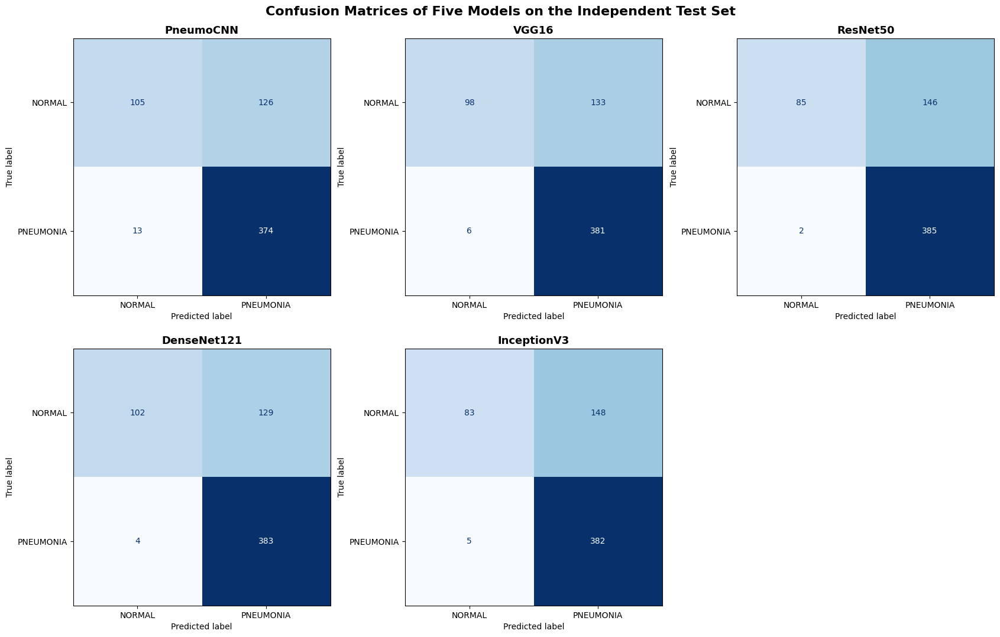

Confusion matrices saved successfully:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/five_model_test_confusion_matrices.png


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import os

models = [
    ("PneumoCNN", pneumocnn_test_y_true, pneumocnn_test_y_pred),
    ("VGG16", vgg16_test_y_true, vgg16_test_y_pred),
    ("ResNet50", resnet50_test_y_true, resnet50_test_y_pred),
    ("DenseNet121", densenet121_test_y_true, densenet121_test_y_pred),
    ("InceptionV3", inceptionv3_test_y_true, inceptionv3_test_y_pred)
]

fig, axes = plt.subplots(2, 3, figsize=(17, 11))
axes = axes.flatten()

for i, (name, y_true, y_pred) in enumerate(models):

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        display_labels=["NORMAL", "PNEUMONIA"],
        cmap="Blues",
        ax=axes[i],
        colorbar=False
    )

    axes[i].set_title(name, fontsize=13, fontweight="bold")

axes[5].axis("off")

plt.suptitle(
    "Confusion Matrices of Five Models on the Independent Test Set",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

save_path = os.path.join(
    PROJECT_PATH,
    "evaluation_results",
    "five_model_test_confusion_matrices.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrices saved successfully:")
print(save_path)

Generate ROC curves for all five models

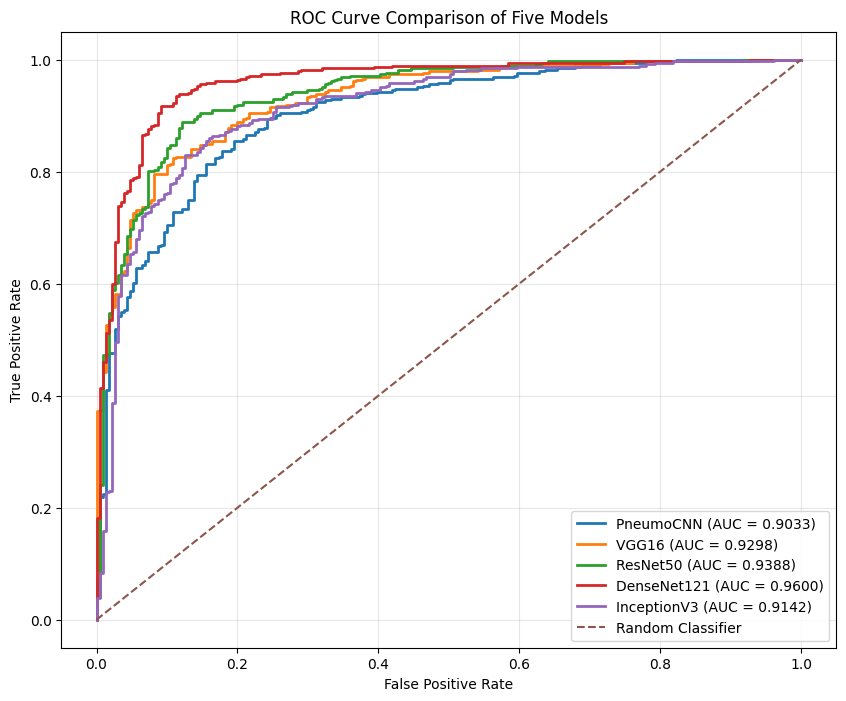

ROC curves saved successfully:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/evaluation_results/five_model_test_roc_curves.png


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import os

models = [
    ("PneumoCNN", pneumocnn_test_y_true, pneumocnn_test_y_prob),
    ("VGG16", vgg16_test_y_true, vgg16_test_y_prob),
    ("ResNet50", resnet50_test_y_true, resnet50_test_y_prob),
    ("DenseNet121", densenet121_test_y_true, densenet121_test_y_prob),
    ("InceptionV3", inceptionv3_test_y_true, inceptionv3_test_y_prob)
]

plt.figure(figsize=(10, 8))

for name, y_true, y_prob in models:

    fpr, tpr, thresholds = roc_curve(y_true, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Five Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

save_path = os.path.join(
    PROJECT_PATH,
    "evaluation_results",
    "five_model_test_roc_curves.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("ROC curves saved successfully:")
print(save_path)

Identify the final convolutional layer in DenseNet121

In [ ]:
# Display the DenseNet121 model structure

print("DENSENET121 MODEL LAYERS")

for layer in densenet121_test_model.layers:
    print(
        "Layer name:", layer.name,
        "| Layer type:", type(layer).__name__
    )

    if isinstance(layer, tf.keras.Model):
        print("\nNested model:", layer.name)

        for nested_layer in layer.layers[-15:]:
            print(
                nested_layer.name,
                "|",
                type(nested_layer).__name__
            )

DENSENET121 MODEL LAYERS
Layer name: input_layer_4 | Layer type: InputLayer
Layer name: densenet121 | Layer type: Functional

Nested model: densenet121
conv5_block15_0_relu | Activation
conv5_block15_1_conv | Conv2D
conv5_block15_1_bn | BatchNormalization
conv5_block15_1_relu | Activation
conv5_block15_2_conv | Conv2D
conv5_block15_concat | Concatenate
conv5_block16_0_bn | BatchNormalization
conv5_block16_0_relu | Activation
conv5_block16_1_conv | Conv2D
conv5_block16_1_bn | BatchNormalization
conv5_block16_1_relu | Activation
conv5_block16_2_conv | Conv2D
conv5_block16_concat | Concatenate
bn | BatchNormalization
relu | Activation
Layer name: global_average_pooling2d_1 | Layer type: GlobalAveragePooling2D
Layer name: dense_2 | Layer type: Dense
Layer name: batch_normalization_1 | Layer type: BatchNormalization
Layer name: dropout_1 | Layer type: Dropout
Layer name: dense_3 | Layer type: Dense


Create the DenseNet121 Grad-CAM function

In [ ]:
def generate_gradcam(model, image, last_conv_layer_name="relu"):

    base_model = model.get_layer("densenet121")

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            base_model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image,
            training=False
        )

        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), float(predictions[0][0].numpy())


print("DenseNet121 Grad-CAM function created successfully.")

DenseNet121 Grad-CAM function created successfully.


Select one pneumonia image from the independent test set

In [ ]:
# Select one pneumonia image from the test set
sample = test_df[test_df["label"] == 1].iloc[0]

image_path = sample["filepath"]

print("Selected image:", image_path)
print("Actual class: PNEUMONIA")

IndexError: single positional indexer is out-of-bounds

Check the test dataset labels

In [ ]:
print("Columns:", test_df.columns.tolist())

print("\nFirst five rows:")
display(test_df.head())

print("\nLabel values:")
print(test_df["label"].value_counts(dropna=False))

Columns: ['filepath', 'label']

First five rows:


,filepath,label
0,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
1,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
2,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
3,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
4,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL



Label values:
label
PNEUMONIA    387
NORMAL       231
Name: count, dtype: int64


Select a pneumonia test image

In [ ]:
sample = test_df[test_df["label"] == "PNEUMONIA"].iloc[0]

image_path = sample["filepath"]

print("Selected image:", image_path)
print("Actual class:", sample["label"])

Selected image: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg
Actual class: PNEUMONIA


Load and preprocess the image

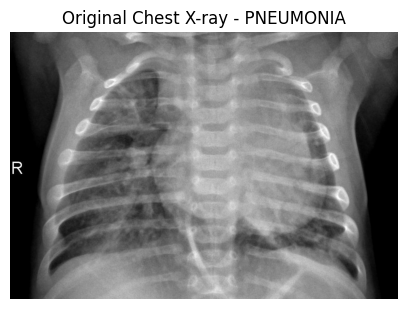

Image prepared successfully.
Model input shape: (1, 224, 224, 3)


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load the original image
original_image = cv2.imread(image_path)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

# Resize to DenseNet121 input size
resized_image = cv2.resize(original_image, (224, 224))

# Prepare model input
image_array = resized_image.astype(np.float32)
image_array = tf.keras.applications.densenet.preprocess_input(image_array)
image_array = np.expand_dims(image_array, axis=0)

# Display original image
plt.figure(figsize=(5, 5))
plt.imshow(original_image)
plt.title("Original Chest X-ray - PNEUMONIA")
plt.axis("off")
plt.show()

print("Image prepared successfully.")
print("Model input shape:", image_array.shape)

Generate the DenseNet121 Grad-CAM heatmap

inspect the model layers

In [ ]:
print("DENSENET121 MODEL LAYERS")

for i, layer in enumerate(densenet121_test_model.layers):
    print(i, layer.name, type(layer).__name__)

print("\nCLASSIFICATION MODEL OUTPUT:")
print(densenet121_test_model.output_shape)

print("\nDENSENET121 BASE MODEL OUTPUT:")
print(densenet121_test_model.get_layer("densenet121").output_shape)

DENSENET121 MODEL LAYERS
0 input_layer_4 InputLayer
1 densenet121 Functional
2 global_average_pooling2d_1 GlobalAveragePooling2D
3 dense_2 Dense
4 batch_normalization_1 BatchNormalization
5 dropout_1 Dropout
6 dense_3 Dense

CLASSIFICATION MODEL OUTPUT:
(None, 1)

DENSENET121 BASE MODEL OUTPUT:
(None, 7, 7, 1024)


Replace the Grad-CAM function

In [ ]:
def generate_gradcam(model, image, last_conv_layer_name="relu"):

    # Get the DenseNet121 feature extractor
    base_model = model.get_layer("densenet121")

    # Get the final convolutional feature map
    conv_layer = base_model.get_layer(last_conv_layer_name)

    # Reconnect the existing classification head
    x = base_model.output

    x = model.get_layer("global_average_pooling2d_1")(x)
    x = model.get_layer("dense_2")(x)
    x = model.get_layer("batch_normalization_1")(x)
    x = model.get_layer("dropout_1")(x)
    predictions = model.get_layer("dense_3")(x)

    # Build a connected Grad-CAM model
    grad_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=[conv_layer.output, predictions]
    )

    image_tensor = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image_tensor,
            training=False
        )

        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), float(predictions[0][0].numpy())


print("Corrected DenseNet121 Grad-CAM function created.")

Corrected DenseNet121 Grad-CAM function created.


Generate the Grad-CAM heatmap

In [ ]:
heatmap, prediction = generate_gradcam(
    densenet121_test_model,
    image_array,
    last_conv_layer_name="relu"
)

predicted_class = "PNEUMONIA" if prediction >= 0.5 else "NORMAL"

print("Grad-CAM generated successfully.")
print("Actual class: PNEUMONIA")
print("Predicted class:", predicted_class)
print("Pneumonia probability:", round(prediction * 100, 2), "%")
print("Heatmap shape:", heatmap.shape)

Grad-CAM generated successfully.
Actual class: PNEUMONIA
Predicted class: NORMAL
Pneumonia probability: 5.73 %
Heatmap shape: (7, 7)


Overlay the Grad-CAM heatmap

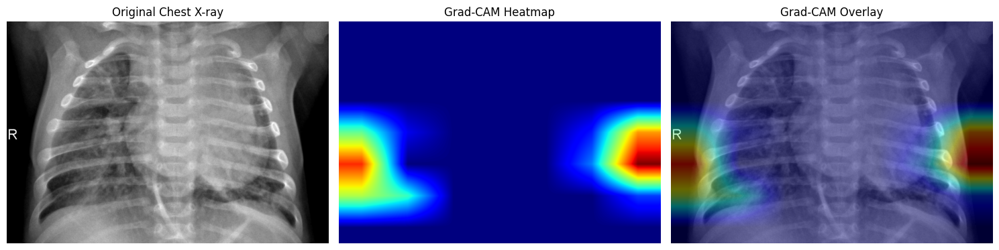

In [ ]:
# Resize heatmap to match the original image
heatmap_resized = cv2.resize(
    heatmap,
    (original_image.shape[1], original_image.shape[0])
)

# Convert heatmap to colour
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

# Convert BGR to RGB
heatmap_colored = cv2.cvtColor(
    heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap on original image
overlay = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Chest X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Examine a NORMAL image

In [ ]:
# Select one NORMAL image from the independent test set
normal_sample = test_df[
    test_df["label"] == "NORMAL"
].iloc[0]

normal_image_path = normal_sample["filepath"]

print("Selected image:", normal_image_path)
print("Actual class:", normal_sample["label"])

Selected image: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/NORMAL/IM-0001-0001.jpeg
Actual class: NORMAL


Load and preprocess the NORMAL image

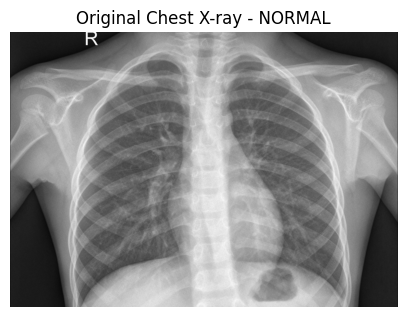

NORMAL image prepared successfully.
Model input shape: (1, 224, 224, 3)


In [ ]:
# Load the NORMAL chest X-ray
normal_original_image = cv2.imread(normal_image_path)

normal_original_image = cv2.cvtColor(
    normal_original_image,
    cv2.COLOR_BGR2RGB
)

# Resize to DenseNet121 input size
normal_resized_image = cv2.resize(
    normal_original_image,
    (224, 224)
)

# Apply DenseNet121 preprocessing
normal_image_array = normal_resized_image.astype(np.float32)

normal_image_array = tf.keras.applications.densenet.preprocess_input(
    normal_image_array
)

normal_image_array = np.expand_dims(
    normal_image_array,
    axis=0
)

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(normal_original_image)
plt.title("Original Chest X-ray - NORMAL")
plt.axis("off")
plt.show()

print("NORMAL image prepared successfully.")
print("Model input shape:", normal_image_array.shape)

Generate Grad-CAM for the NORMAL image

In [ ]:
# Generate Grad-CAM heatmap
normal_heatmap, normal_prediction = generate_gradcam(
    densenet121_test_model,
    normal_image_array,
    last_conv_layer_name="relu"
)

# Apply your research threshold
normal_predicted_class = (
    "PNEUMONIA" if normal_prediction >= 0.04 else "NORMAL"
)

print("NORMAL image Grad-CAM generated successfully.")
print("Actual class: NORMAL")
print("Predicted class:", normal_predicted_class)
print(
    "Pneumonia probability:",
    round(normal_prediction * 100, 2),
    "%"
)
print("Research threshold: 4.00%")
print("Heatmap shape:", normal_heatmap.shape)

NORMAL image Grad-CAM generated successfully.
Actual class: NORMAL
Predicted class: NORMAL
Pneumonia probability: 0.02 %
Research threshold: 4.00%
Heatmap shape: (7, 7)


Overlay the NORMAL image heatmap

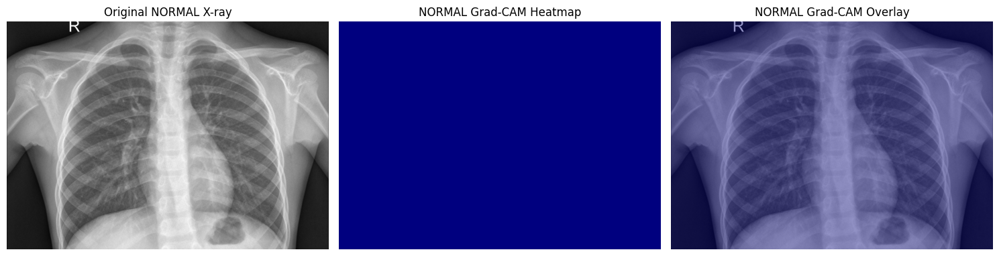

In [ ]:
# Resize heatmap to original image dimensions
normal_heatmap_resized = cv2.resize(
    normal_heatmap,
    (normal_original_image.shape[1],
     normal_original_image.shape[0])
)

# Convert heatmap to colour
normal_heatmap_uint8 = np.uint8(
    255 * normal_heatmap_resized
)

normal_heatmap_colored = cv2.applyColorMap(
    normal_heatmap_uint8,
    cv2.COLORMAP_JET
)

normal_heatmap_colored = cv2.cvtColor(
    normal_heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap
normal_overlay = cv2.addWeighted(
    normal_original_image,
    0.6,
    normal_heatmap_colored,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(normal_original_image)
plt.title("Original NORMAL X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(normal_heatmap_resized, cmap="jet")
plt.title("NORMAL Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(normal_overlay)
plt.title("NORMAL Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Correct the Grad-CAM function

In [ ]:
def generate_gradcam(model, image, target_class="PNEUMONIA",
                     last_conv_layer_name="relu"):

    base_model = model.get_layer("densenet121")
    conv_layer = base_model.get_layer(last_conv_layer_name)

    # Reconnect classification head
    x = base_model.output
    x = model.get_layer("global_average_pooling2d_1")(x)
    x = model.get_layer("dense_2")(x)
    x = model.get_layer("batch_normalization_1")(x)
    x = model.get_layer("dropout_1")(x)
    predictions = model.get_layer("dense_3")(x)

    grad_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=[conv_layer.output, predictions]
    )

    image_tensor = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image_tensor,
            training=False
        )

        if target_class == "PNEUMONIA":
            score = predictions[:, 0]
        elif target_class == "NORMAL":
            score = 1.0 - predictions[:, 0]
        else:
            raise ValueError("target_class must be NORMAL or PNEUMONIA")

    grads = tape.gradient(score, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), float(predictions[0][0].numpy())


print("Class-specific Grad-CAM function created successfully.")

Class-specific Grad-CAM function created successfully.


Regenerate the NORMAL Grad-CAM heatmap

In [ ]:
normal_heatmap, normal_prediction = generate_gradcam(
    densenet121_test_model,
    normal_image_array,
    target_class="NORMAL",
    last_conv_layer_name="relu"
)

print("Class-specific NORMAL Grad-CAM generated.")
print("Actual class: NORMAL")
print("Pneumonia probability:", round(normal_prediction * 100, 4), "%")
print("NORMAL probability:", round((1 - normal_prediction) * 100, 4), "%")
print("Heatmap shape:", normal_heatmap.shape)
print("Maximum heatmap activation:", normal_heatmap.max())

Class-specific NORMAL Grad-CAM generated.
Actual class: NORMAL
Pneumonia probability: 0.0181 %
NORMAL probability: 99.9819 %
Heatmap shape: (7, 7)
Maximum heatmap activation: 0.99905485


Display the corrected NORMAL Grad-CAM overlay

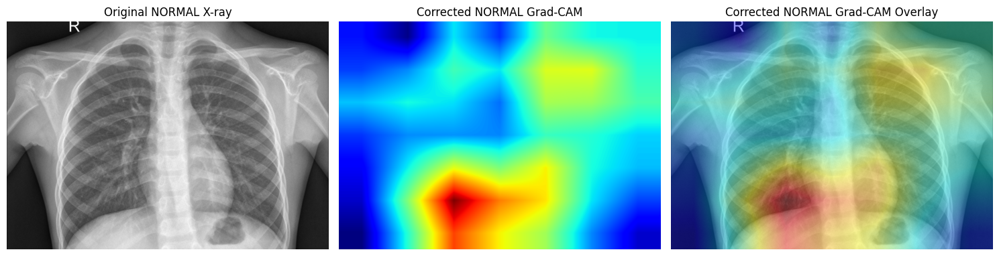

In [ ]:
# Resize corrected heatmap
normal_heatmap_resized = cv2.resize(
    normal_heatmap,
    (normal_original_image.shape[1],
     normal_original_image.shape[0])
)

# Convert to colour
normal_heatmap_uint8 = np.uint8(
    255 * normal_heatmap_resized
)

normal_heatmap_colored = cv2.applyColorMap(
    normal_heatmap_uint8,
    cv2.COLORMAP_JET
)

normal_heatmap_colored = cv2.cvtColor(
    normal_heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Create overlay
normal_overlay = cv2.addWeighted(
    normal_original_image,
    0.6,
    normal_heatmap_colored,
    0.4,
    0
)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(normal_original_image)
plt.title("Original NORMAL X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(normal_heatmap_resized, cmap="jet")
plt.title("Corrected NORMAL Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(normal_overlay)
plt.title("Corrected NORMAL Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Regenerate the PNEUMONIA Grad-CAM

In [ ]:
id="pneumonia_corrected"
heatmap, prediction = generate_gradcam(
    densenet121_test_model,
    image_array,
    target_class="PNEUMONIA",
    last_conv_layer_name="relu"
)

print("Corrected PNEUMONIA Grad-CAM generated.")
print("Actual class: PNEUMONIA")
print("Pneumonia probability:", round(prediction * 100, 4), "%")
print("Research threshold: 4.00%")
print("Heatmap shape:", heatmap.shape)

Corrected PNEUMONIA Grad-CAM generated.
Actual class: PNEUMONIA
Pneumonia probability: 5.7264 %
Research threshold: 4.00%
Heatmap shape: (7, 7)


Display the corrected PNEUMONIA overlay

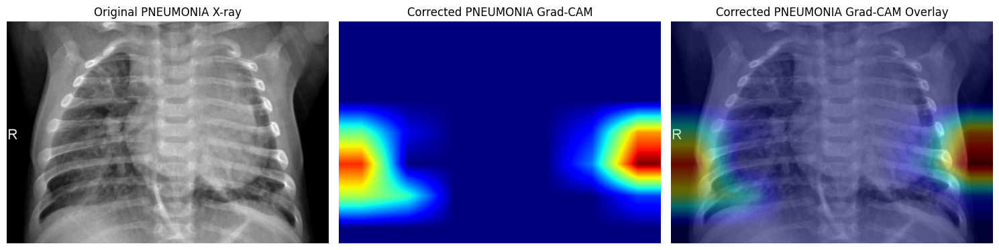

In [ ]:
# Resize heatmap to original image dimensions
heatmap_resized = cv2.resize(
    heatmap,
    (original_image.shape[1], original_image.shape[0])
)

# Convert heatmap to colour
heatmap_uint8 = np.uint8(255 * heatmap_resized)

heatmap_colored = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_colored = cv2.cvtColor(
    heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap
overlay = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original PNEUMONIA X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Corrected PNEUMONIA Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Corrected PNEUMONIA Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Create the corrected DenseNet121 image-preparation function

In [ ]:
def prepare_densenet_gradcam_image(image_path):

    # Read and decode the original image
    image_bytes = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    # Convert to float32
    image = tf.cast(image, tf.float32)

    # Preserve aspect ratio using padding
    image = tf.image.resize_with_pad(
        image,
        target_height=224,
        target_width=224
    )

    # Apply the same DenseNet121 preprocessing
    image = tf.keras.applications.densenet.preprocess_input(image)

    # Add batch dimension
    image = tf.expand_dims(image, axis=0)

    return image


print("Corrected DenseNet121 preprocessing function created.")

Corrected DenseNet121 preprocessing function created.


Prepare the PNEUMONIA image again

In [ ]:
image_array = prepare_densenet_gradcam_image(image_path)

print("PNEUMONIA image prepared.")
print("Input shape:", image_array.shape)
print("Data type:", image_array.dtype)

PNEUMONIA image prepared.
Input shape: (1, 224, 224, 3)
Data type: <dtype: 'float32'>


Regenerate the PNEUMONIA Grad-CAM

In [ ]:
heatmap, prediction = generate_gradcam(
    densenet121_test_model,
    image_array,
    target_class="PNEUMONIA",
    last_conv_layer_name="relu"
)

print("PNEUMONIA Grad-CAM regenerated.")
print("Actual class:", "PNEUMONIA")
print("Pneumonia probability:", round(prediction * 100, 4), "%")
print("Classification threshold:", 4.00, "%")
print(
    "Predicted class:",
    "PNEUMONIA" if prediction >= 0.04 else "NORMAL"
)
print("Heatmap shape:", heatmap.shape)

PNEUMONIA Grad-CAM regenerated.
Actual class: PNEUMONIA
Pneumonia probability: 81.041 %
Classification threshold: 4.0 %
Predicted class: PNEUMONIA
Heatmap shape: (7, 7)


display the corrected heatmap over the properly resized image.

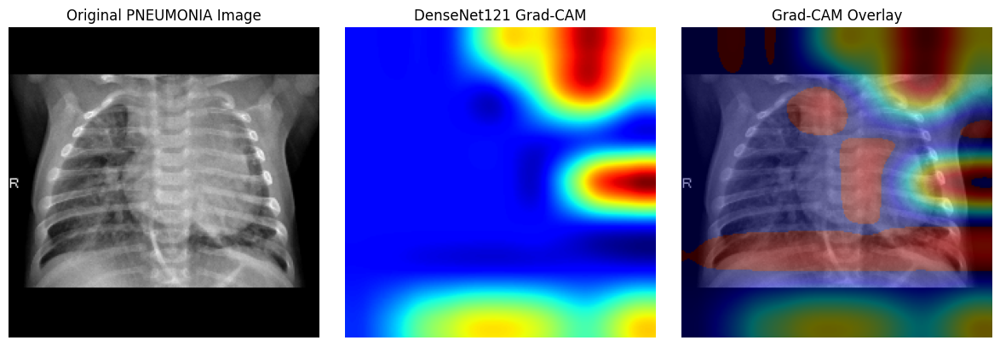

In [ ]:
# Prepare the original image using the same resize_with_pad method
display_image = tf.io.read_file(image_path)
display_image = tf.image.decode_image(
    display_image, channels=3, expand_animations=False
)
display_image = tf.cast(display_image, tf.float32)
display_image = tf.image.resize_with_pad(
    display_image, 224, 224
).numpy().astype(np.uint8)

# Resize the 7x7 heatmap to match the image dimensions
heatmap_resized = cv2.resize(
    heatmap, (224, 224), interpolation=cv2.INTER_CUBIC
)

# Create the coloured heatmap
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(
    heatmap_uint8, cv2.COLORMAP_JET
)
heatmap_colored = cv2.cvtColor(
    heatmap_colored, cv2.COLOR_BGR2RGB
)

# Overlay the heatmap on the image
overlay = cv2.addWeighted(
    display_image, 0.6, heatmap_colored, 0.4, 0
)

# Display the results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(display_image)
plt.title("Original PNEUMONIA Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("DenseNet121 Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Correctly classified NORMAL image

In [ ]:
normal_image_path = (
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/"
    "chest_xray/test/NORMAL/IM-0001-0001.jpeg"
)

normal_image_array = prepare_densenet_gradcam_image(
    normal_image_path
)

print("NORMAL image prepared.")
print("Input shape:", normal_image_array.shape)
print("Data type:", normal_image_array.dtype)

NORMAL image prepared.
Input shape: (1, 224, 224, 3)
Data type: <dtype: 'float32'>


In [ ]:
normal_heatmap, normal_prediction = generate_gradcam(
    densenet121_test_model,
    normal_image_array,
    target_class="NORMAL",
    last_conv_layer_name="relu"
)

print("NORMAL Grad-CAM generated.")
print("Actual class: NORMAL")
print(
    "Pneumonia probability:",
    round(normal_prediction * 100, 4), "%"
)
print("NORMAL probability:", round((1 - normal_prediction) * 100, 4), "%")
print("Classification threshold: 4.00%")
print(
    "Predicted class:",
    "PNEUMONIA" if normal_prediction >= 0.04 else "NORMAL"
)
print("Heatmap shape:", normal_heatmap.shape)

NORMAL Grad-CAM generated.
Actual class: NORMAL
Pneumonia probability: 15.9319 %
NORMAL probability: 84.0681 %
Classification threshold: 4.00%
Predicted class: PNEUMONIA
Heatmap shape: (7, 7)


Generate the false-positive Grad-CAM

In [ ]:
fp_heatmap, fp_prediction = generate_gradcam(
    densenet121_test_model,
    normal_image_array,
    target_class="PNEUMONIA",
    last_conv_layer_name="relu"
)

print("False Positive Grad-CAM generated.")
print("Actual class: NORMAL")
print("Predicted class: PNEUMONIA")
print("Pneumonia probability:", round(fp_prediction * 100, 4), "%")
print("Heatmap shape:", fp_heatmap.shape)

False Positive Grad-CAM generated.
Actual class: NORMAL
Predicted class: PNEUMONIA
Pneumonia probability: 15.9319 %
Heatmap shape: (7, 7)


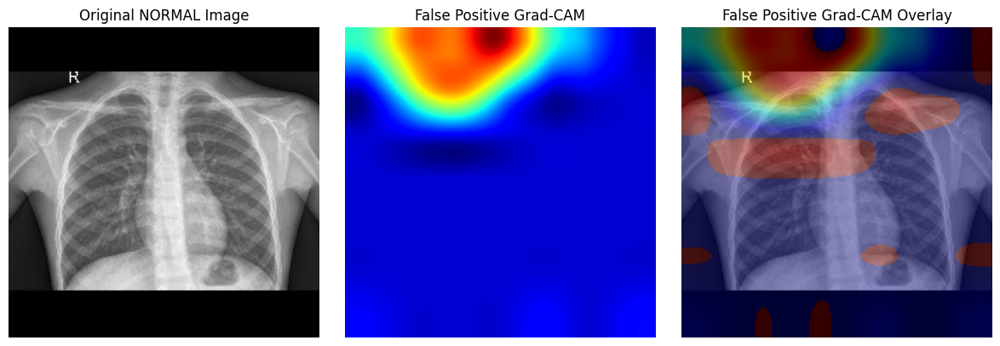

In [ ]:
# Load and prepare the original NORMAL image for display
fp_display_image = tf.io.read_file(normal_image_path)

fp_display_image = tf.image.decode_image(
    fp_display_image,
    channels=3,
    expand_animations=False
)

fp_display_image = tf.cast(fp_display_image, tf.float32)

fp_display_image = tf.image.resize_with_pad(
    fp_display_image,
    224,
    224
).numpy().astype(np.uint8)

# Resize the Grad-CAM heatmap
fp_heatmap_resized = cv2.resize(
    fp_heatmap,
    (224, 224),
    interpolation=cv2.INTER_CUBIC
)

# Apply colour map
fp_heatmap_uint8 = np.uint8(255 * fp_heatmap_resized)

fp_heatmap_colored = cv2.applyColorMap(
    fp_heatmap_uint8,
    cv2.COLORMAP_JET
)

fp_heatmap_colored = cv2.cvtColor(
    fp_heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Create overlay
fp_overlay = cv2.addWeighted(
    fp_display_image,
    0.6,
    fp_heatmap_colored,
    0.4,
    0
)

# Display
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(fp_display_image)
plt.title("Original NORMAL Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(fp_heatmap_resized, cmap="jet")
plt.title("False Positive Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(fp_overlay)
plt.title("False Positive Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Identify a False Negative (FN)

In [ ]:
# Convert predictions and actual labels to arrays
y_true = np.asarray(densenet121_test_y_true).reshape(-1)
y_pred = np.asarray(densenet121_test_y_pred).reshape(-1)
y_prob = np.asarray(densenet121_test_prob).reshape(-1)

# Check alignment with the test dataframe
test_check = test_df.reset_index(drop=True).copy()

print("Number of test images:", len(test_check))
print("Number of actual labels:", len(y_true))
print("Number of predictions:", len(y_pred))
print("Number of probabilities:", len(y_prob))

# Confirm that dataframe labels match the actual labels
actual_labels = np.where(y_true == 1, "PNEUMONIA", "NORMAL")

print(
    "Dataframe and model labels match:",
    np.array_equal(test_check["label"].values, actual_labels)
)

# Identify False Negatives
fn_indices = np.where((y_true == 1) & (y_pred == 0))[0]

print("\nNumber of False Negatives:", len(fn_indices))

# Display the first False Negative
if len(fn_indices) > 0:
    fn_index = fn_indices[0]

    fn_image_path = test_check.loc[fn_index, "filepath"]

    print("\nSelected False Negative:")
    print("Image path:", fn_image_path)
    print("Actual class: PNEUMONIA")
    print("Predicted class: NORMAL")
    print("Pneumonia probability:", round(y_prob[fn_index] * 100, 4), "%")
    print("Classification threshold: 4.00%")
else:
    print("No False Negative found.")

NameError: name 'densenet121_test_prob' is not defined

In [ ]:
# Find DenseNet121 variables containing probability information
for name in globals():
    if "densenet121" in name.lower() and "prob" in name.lower():
        print(name)

densenet121_test_y_prob


In [ ]:
# Convert predictions, actual labels and probabilities to arrays
y_true = np.asarray(densenet121_test_y_true).reshape(-1)
y_pred = np.asarray(densenet121_test_y_pred).reshape(-1)
y_prob = np.asarray(densenet121_test_y_prob).reshape(-1)

# Check alignment with the test dataframe
test_check = test_df.reset_index(drop=True).copy()

print("Number of test images:", len(test_check))
print("Number of actual labels:", len(y_true))
print("Number of predictions:", len(y_pred))
print("Number of probabilities:", len(y_prob))

# Confirm that dataframe labels match actual labels
actual_labels = np.where(y_true == 1, "PNEUMONIA", "NORMAL")

print(
    "Dataframe and model labels match:",
    np.array_equal(test_check["label"].values, actual_labels)
)

# Identify False Negatives
fn_indices = np.where((y_true == 1) & (y_pred == 0))[0]

print("\nNumber of False Negatives:", len(fn_indices))

# Display the first False Negative
if len(fn_indices) > 0:
    fn_index = fn_indices[0]

    fn_image_path = test_check.loc[fn_index, "filepath"]

    print("\nSelected False Negative:")
    print("Image path:", fn_image_path)
    print("Actual class: PNEUMONIA")
    print("Predicted class: NORMAL")
    print(
        "Pneumonia probability:",
        round(y_prob[fn_index] * 100, 4), "%"
    )
    print("Classification threshold: 4.00%")
else:
    print("No False Negative found.")

Number of test images: 618
Number of actual labels: 618
Number of predictions: 618
Number of probabilities: 618
Dataframe and model labels match: True

Number of False Negatives: 4

Selected False Negative:
Image path: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/PNEUMONIA/person153_bacteria_726.jpeg
Actual class: PNEUMONIA
Predicted class: NORMAL
Pneumonia probability: 0.6398 %
Classification threshold: 4.00%


repare the False Negative image

In [ ]:
fn_image_array = prepare_densenet_gradcam_image(
    fn_image_path
)

print("False Negative image prepared.")
print("Input shape:", fn_image_array.shape)
print("Data type:", fn_image_array.dtype)

False Negative image prepared.
Input shape: (1, 224, 224, 3)
Data type: <dtype: 'float32'>


In [ ]:
fn_heatmap, fn_prediction = generate_gradcam(
    densenet121_test_model,
    fn_image_array,
    target_class="NORMAL",
    last_conv_layer_name="relu"
)

print("False Negative Grad-CAM generated.")
print("Actual class: PNEUMONIA")
print("Predicted class: NORMAL")
print("Pneumonia probability:", round(fn_prediction * 100, 4), "%")
print("NORMAL probability:", round((1 - fn_prediction) * 100, 4), "%")
print("Heatmap shape:", fn_heatmap.shape)

False Negative Grad-CAM generated.
Actual class: PNEUMONIA
Predicted class: NORMAL
Pneumonia probability: 0.6398 %
NORMAL probability: 99.3602 %
Heatmap shape: (7, 7)


Display the False Negative overlay

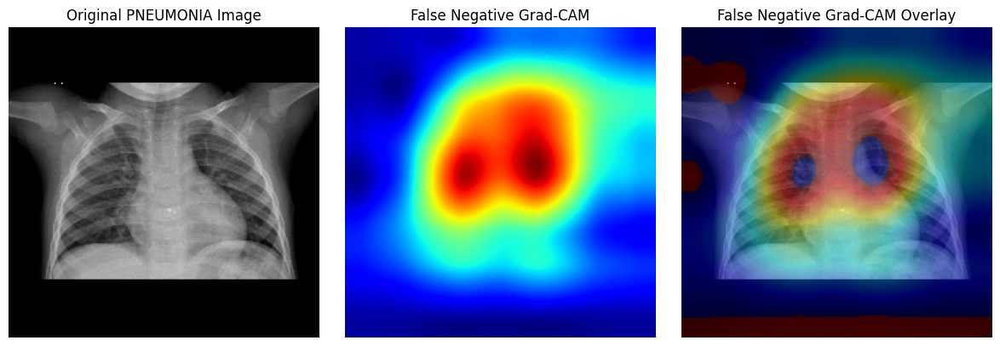

In [ ]:
# Load the original image and apply the same padding
fn_display_image = tf.io.read_file(fn_image_path)

fn_display_image = tf.image.decode_image(
    fn_display_image,
    channels=3,
    expand_animations=False
)

fn_display_image = tf.cast(fn_display_image, tf.float32)

fn_display_image = tf.image.resize_with_pad(
    fn_display_image, 224, 224
).numpy().astype(np.uint8)

# Resize heatmap
fn_heatmap_resized = cv2.resize(
    fn_heatmap,
    (224, 224),
    interpolation=cv2.INTER_CUBIC
)

# Apply colour map
fn_heatmap_uint8 = np.uint8(255 * fn_heatmap_resized)

fn_heatmap_colored = cv2.applyColorMap(
    fn_heatmap_uint8,
    cv2.COLORMAP_JET
)

fn_heatmap_colored = cv2.cvtColor(
    fn_heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Overlay
fn_overlay = cv2.addWeighted(
    fn_display_image, 0.6,
    fn_heatmap_colored, 0.4, 0
)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(fn_display_image)
plt.title("Original PNEUMONIA Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(fn_heatmap_resized, cmap="jet")
plt.title("False Negative Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(fn_overlay)
plt.title("False Negative Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

dentify a genuine True Negative (TN)

In [ ]:
# Identify correctly classified NORMAL images (True Negatives)
tn_indices = np.where((y_true == 0) & (y_pred == 0))[0]

print("Number of True Negatives:", len(tn_indices))

if len(tn_indices) > 0:
    tn_index = tn_indices[0]

    tn_image_path = test_check.loc[tn_index, "filepath"]

    print("\nSelected True Negative:")
    print("Image path:", tn_image_path)
    print("Actual class: NORMAL")
    print("Predicted class: NORMAL")
    print(
        "Pneumonia probability:",
        round(y_prob[tn_index] * 100, 4), "%"
    )
    print("Classification threshold: 4.00%")
else:
    print("No True Negative found.")

Number of True Negatives: 102

Selected True Negative:
Image path: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/NORMAL/IM-0005-0001.jpeg
Actual class: NORMAL
Predicted class: NORMAL
Pneumonia probability: 0.5785 %
Classification threshold: 4.00%


Prepare the True Negative image

In [ ]:
tn_image_array = prepare_densenet_gradcam_image(
    tn_image_path
)

print("True Negative image prepared.")
print("Input shape:", tn_image_array.shape)
print("Data type:", tn_image_array.dtype)

True Negative image prepared.
Input shape: (1, 224, 224, 3)
Data type: <dtype: 'float32'>


NORMAL-specific Grad-CAM.

In [ ]:
tn_heatmap, tn_prediction = generate_gradcam(
    densenet121_test_model,
    tn_image_array,
    target_class="NORMAL",
    last_conv_layer_name="relu"
)

print("True Negative Grad-CAM generated.")
print("Actual class: NORMAL")
print("Predicted class: NORMAL")
print("Pneumonia probability:", round(tn_prediction * 100, 4), "%")
print("NORMAL probability:", round((1 - tn_prediction) * 100, 4), "%")
print("Heatmap shape:", tn_heatmap.shape)

True Negative Grad-CAM generated.
Actual class: NORMAL
Predicted class: NORMAL
Pneumonia probability: 0.5785 %
NORMAL probability: 99.4215 %
Heatmap shape: (7, 7)


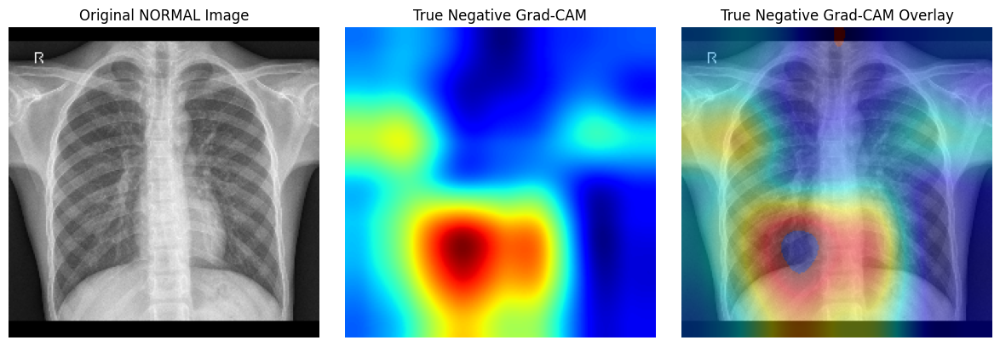

In [ ]:
# Load and prepare the original NORMAL image
tn_display_image = tf.io.read_file(tn_image_path)

tn_display_image = tf.image.decode_image(
    tn_display_image,
    channels=3,
    expand_animations=False
)

tn_display_image = tf.cast(tn_display_image, tf.float32)

tn_display_image = tf.image.resize_with_pad(
    tn_display_image, 224, 224
).numpy().astype(np.uint8)

# Resize heatmap
tn_heatmap_resized = cv2.resize(
    tn_heatmap,
    (224, 224),
    interpolation=cv2.INTER_CUBIC
)

# Apply colour map
tn_heatmap_uint8 = np.uint8(255 * tn_heatmap_resized)

tn_heatmap_colored = cv2.applyColorMap(
    tn_heatmap_uint8,
    cv2.COLORMAP_JET
)

tn_heatmap_colored = cv2.cvtColor(
    tn_heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Create overlay
tn_overlay = cv2.addWeighted(
    tn_display_image, 0.6,
    tn_heatmap_colored, 0.4,
    0
)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(tn_display_image)
plt.title("Original NORMAL Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(tn_heatmap_resized, cmap="jet")
plt.title("True Negative Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tn_overlay)
plt.title("True Negative Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Final verification before moving to PneumoCNN

In [ ]:
print("DENSENET121 GRAD-CAM VERIFICATION")
print("----------------------------------")

print("True Positives (TP):",
      np.sum((y_true == 1) & (y_pred == 1)))

print("True Negatives (TN):",
      np.sum((y_true == 0) & (y_pred == 0)))

print("False Positives (FP):",
      np.sum((y_true == 0) & (y_pred == 1)))

print("False Negatives (FN):",
      np.sum((y_true == 1) & (y_pred == 0)))

print("----------------------------------")
print("Total test images:", len(y_true))
print("All four Grad-CAM categories visualised.")

DENSENET121 GRAD-CAM VERIFICATION
----------------------------------
True Positives (TP): 383
True Negatives (TN): 102
False Positives (FP): 129
False Negatives (FN): 4
----------------------------------
Total test images: 618
All four Grad-CAM categories visualised.


Custom CNN (PneumoCNN)

In [ ]:
print("CUSTOM CNN MODEL CHECK")
print("----------------------")

print("Model variable exists:", "pneumocnn_test_model" in globals())

print("\nAvailable PneumoCNN model variables:")

for name in globals():
    if "pneumocnn" in name.lower() and "model" in name.lower():
        print(name)

CUSTOM CNN MODEL CHECK
----------------------
Model variable exists: True

Available PneumoCNN model variables:
pneumocnn_model_path
pneumocnn_test_model


Inspect the custom CNN layers

In [ ]:
print("CUSTOM CNN ARCHITECTURE")
print("-----------------------")

pneumocnn_test_model.summary()

print("\nLayer names and output shapes:")

for layer in pneumocnn_test_model.layers:
    try:
        print(layer.name, layer.output.shape)
    except:
        print(layer.name, "Shape unavailable")

CUSTOM CNN ARCHITECTURE
-----------------------


Model: "PneumoCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,268,165 (4.84 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 844,804 (3.22 MB)


Layer names and output shapes:
input_layer_1 (None, 224, 224, 3)
conv2d (None, 224, 224, 32)
batch_normalization (None, 224, 224, 32)
activation (None, 224, 224, 32)
max_pooling2d (None, 112, 112, 32)
conv2d_1 (None, 112, 112, 64)
batch_normalization_1 (None, 112, 112, 64)
activation_1 (None, 112, 112, 64)
max_pooling2d_1 (None, 56, 56, 64)
conv2d_2 (None, 56, 56, 128)
batch_normalization_2 (None, 56, 56, 128)
activation_2 (None, 56, 56, 128)
max_pooling2d_2 (None, 28, 28, 128)
conv2d_3 (None, 28, 28, 256)
batch_normalization_3 (None, 28, 28, 256)
activation_3 (None, 28, 28, 256)
max_pooling2d_3 (None, 14, 14, 256)
global_average_pooling2d (None, 256)
dense (None, 128)
dropout (None, 128)
pneumonia_output (None, 1)


Confirm the model's preprocessing

In [ ]:
print("CUSTOM CNN PREPROCESSING CHECK")
print("--------------------------------")
print("Input shape:", pneumocnn_test_model.input_shape)
print("Final convolutional feature layer:",
      pneumocnn_test_model.get_layer("activation_3").output.shape)

print("\nExpected preprocessing: pixel values divided by 255")

CUSTOM CNN PREPROCESSING CHECK
--------------------------------
Input shape: (None, 224, 224, 3)
Final convolutional feature layer: (None, 28, 28, 256)

Expected preprocessing: pixel values divided by 255


Create the custom CNN Grad-CAM function

In [ ]:
def generate_pneumocnn_gradcam(
    model,
    image,
    target_class="PNEUMONIA",
    last_conv_layer_name="activation_3"
):

    # Get the selected convolutional feature layer
    conv_layer = model.get_layer(last_conv_layer_name)

    # Create a connected Grad-CAM model
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[conv_layer.output, model.output]
    )

    image_tensor = tf.convert_to_tensor(
        image, dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image_tensor, training=False
        )

        pneumonia_score = predictions[:, 0]

        if target_class == "PNEUMONIA":
            score = pneumonia_score

        elif target_class == "NORMAL":
            score = 1.0 - pneumonia_score

        else:
            raise ValueError(
                "target_class must be NORMAL or PNEUMONIA"
            )

    # Calculate gradients
    grads = tape.gradient(score, conv_outputs)

    # Average gradients across spatial dimensions
    pooled_grads = tf.reduce_mean(
        grads, axis=(0, 1, 2)
    )

    # Generate heatmap
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) +
        tf.keras.backend.epsilon()
    )

    return (
        heatmap.numpy(),
        float(predictions[0][0].numpy())
    )


print("Custom CNN Grad-CAM function created successfully.")

Custom CNN Grad-CAM function created successfully.


Prepare the first PNEUMONIA test image

In [ ]:
def prepare_pneumocnn_gradcam_image(image_path):

    image_bytes = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image = tf.cast(image, tf.float32)

    image = tf.image.resize_with_pad(
        image,
        target_height=224,
        target_width=224
    )

    # Custom CNN preprocessing
    image = image / 255.0

    image = tf.expand_dims(image, axis=0)

    return image


pneumocnn_image_path = (
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/"
    "chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg"
)

pneumocnn_image_array = prepare_pneumocnn_gradcam_image(
    pneumocnn_image_path
)

print("PNEUMONIA image prepared for custom CNN.")
print("Input shape:", pneumocnn_image_array.shape)
print("Data type:", pneumocnn_image_array.dtype)
print("Minimum pixel value:", float(tf.reduce_min(pneumocnn_image_array)))
print("Maximum pixel value:", float(tf.reduce_max(pneumocnn_image_array)))

PNEUMONIA image prepared for custom CNN.
Input shape: (1, 224, 224, 3)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Generate the custom CNN PNEUMONIA Grad-CAM

In [ ]:
pneumocnn_heatmap, pneumocnn_prediction = generate_pneumocnn_gradcam(
    pneumocnn_test_model,
    pneumocnn_image_array,
    target_class="PNEUMONIA",
    last_conv_layer_name="activation_3"
)

print("Custom CNN PNEUMONIA Grad-CAM generated.")
print("Actual class: PNEUMONIA")
print(
    "Pneumonia probability:",
    round(pneumocnn_prediction * 100, 4), "%"
)
print("Classification threshold: 42.00%")
print(
    "Predicted class:",
    "PNEUMONIA" if pneumocnn_prediction >= 0.42 else "NORMAL"
)
print("Heatmap shape:", pneumocnn_heatmap.shape)

Custom CNN PNEUMONIA Grad-CAM generated.
Actual class: PNEUMONIA
Pneumonia probability: 31.5762 %
Classification threshold: 42.00%
Predicted class: NORMAL
Heatmap shape: (28, 28)


Display the custom CNN Grad-CAM

In [ ]:
pneumocnn_fn_heatmap, pneumocnn_fn_prediction = generate_pneumocnn_gradcam(
    pneumocnn_test_model,
    pneumocnn_image_array,
    target_class="NORMAL",
    last_conv_layer_name="activation_3"
)

print("Custom CNN False Negative Grad-CAM generated.")
print("Actual class: PNEUMONIA")
print("Predicted class: NORMAL")
print("Pneumonia probability:",
      round(pneumocnn_fn_prediction * 100, 4), "%")
print("NORMAL probability:",
      round((1 - pneumocnn_fn_prediction) * 100, 4), "%")
print("Heatmap shape:", pneumocnn_fn_heatmap.shape)

Custom CNN False Negative Grad-CAM generated.
Actual class: PNEUMONIA
Predicted class: NORMAL
Pneumonia probability: 31.5762 %
NORMAL probability: 68.4238 %
Heatmap shape: (28, 28)


Display the Grad-CAM overlay

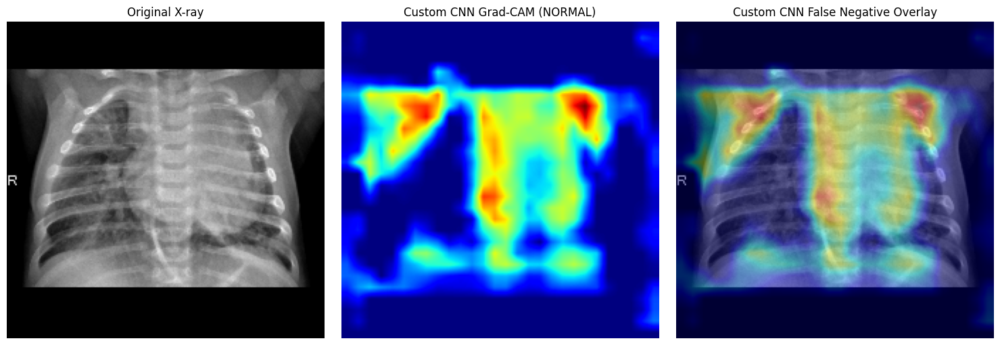

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import cv2

# Load the original image
image_bytes = tf.io.read_file(pneumocnn_image_path)
original_image = tf.image.decode_image(
    image_bytes, channels=3, expand_animations=False
)

# Resize using the same method as the model
display_image = tf.image.resize_with_pad(
    tf.cast(original_image, tf.float32),
    target_height=224,
    target_width=224
).numpy().astype(np.uint8)

# Resize Grad-CAM heatmap
heatmap_resized = cv2.resize(
    pneumocnn_fn_heatmap, (224, 224)
)

# Convert heatmap to colour
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(
    heatmap_uint8, cv2.COLORMAP_JET
)
heatmap_colored = cv2.cvtColor(
    heatmap_colored, cv2.COLOR_BGR2RGB
)

# Overlay heatmap on original image
overlay = cv2.addWeighted(
    display_image, 0.6,
    heatmap_colored, 0.4, 0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_image)
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Custom CNN Grad-CAM (NORMAL)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Custom CNN False Negative Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

True Negative (TN) example

In [ ]:
# Identify a True Negative example for the Custom CNN

tn_indices_pneumocnn = np.where(
    (pneumocnn_test_y_true == 0) &
    (pneumocnn_test_y_pred == 0)
)[0]

print("Number of True Negative cases:", len(tn_indices_pneumocnn))

# Select the first True Negative example
pneumocnn_tn_index = tn_indices_pneumocnn[0]

pneumocnn_tn_path = test_df.iloc[pneumocnn_tn_index]["filepath"]

print("Selected image:", pneumocnn_tn_path)
print("Actual class: NORMAL")
print("Predicted class: NORMAL")
print(
    "Pneumonia probability:",
    round(float(pneumocnn_test_y_prob[pneumocnn_tn_index]) * 100, 4),
    "%"
)

Number of True Negative cases: 105
Selected image: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/NORMAL/IM-0003-0001.jpeg
Actual class: NORMAL
Predicted class: NORMAL
Pneumonia probability: 40.3577 %


Generate the TN Grad-CAM

In [ ]:
# Prepare the selected True Negative image
pneumocnn_tn_image_array = prepare_pneumocnn_gradcam_image(
    pneumocnn_tn_path
)

# Generate Grad-CAM for the predicted class: NORMAL
pneumocnn_tn_heatmap, pneumocnn_tn_prediction = generate_pneumocnn_gradcam(
    pneumocnn_test_model,
    pneumocnn_tn_image_array,
    target_class="NORMAL",
    last_conv_layer_name="activation_3"
)

print("Custom CNN True Negative Grad-CAM generated.")
print("Actual class: NORMAL")
print("Predicted class: NORMAL")
print("Pneumonia probability:", round(pneumocnn_tn_prediction * 100, 4), "%")
print("NORMAL probability:", round((1 - pneumocnn_tn_prediction) * 100, 4), "%")
print("Heatmap shape:", pneumocnn_tn_heatmap.shape)

Custom CNN True Negative Grad-CAM generated.
Actual class: NORMAL
Predicted class: NORMAL
Pneumonia probability: 40.3577 %
NORMAL probability: 59.6423 %
Heatmap shape: (28, 28)


Display the TN Grad-CAM overlay

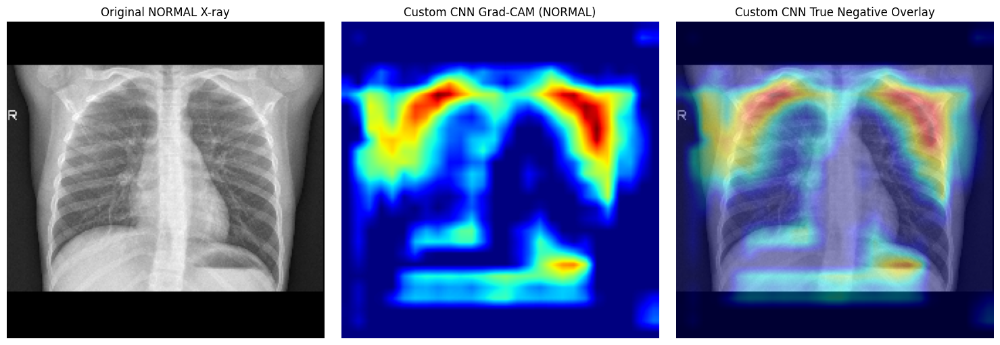

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import cv2

# Load original X-ray
image_bytes = tf.io.read_file(pneumocnn_tn_path)
original_image = tf.image.decode_image(
    image_bytes, channels=3, expand_animations=False
)

# Resize for display
display_image = tf.image.resize_with_pad(
    tf.cast(original_image, tf.float32),
    target_height=224,
    target_width=224
).numpy().astype(np.uint8)

# Resize Grad-CAM heatmap
heatmap_resized = cv2.resize(
    pneumocnn_tn_heatmap, (224, 224)
)

# Apply colour map
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(
    heatmap_uint8, cv2.COLORMAP_JET
)
heatmap_colored = cv2.cvtColor(
    heatmap_colored, cv2.COLOR_BGR2RGB
)

# Create overlay
overlay = cv2.addWeighted(
    display_image, 0.6,
    heatmap_colored, 0.4, 0
)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_image)
plt.title("Original NORMAL X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Custom CNN Grad-CAM (NORMAL)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Custom CNN True Negative Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

False Positive (FP) example

In [ ]:
# Identify False Positive cases
fp_indices_pneumocnn = np.where(
    (pneumocnn_test_y_true == 0) &
    (pneumocnn_test_y_pred == 1)
)[0]

print("Number of False Positive cases:", len(fp_indices_pneumocnn))

# Select the first False Positive example
pneumocnn_fp_index = fp_indices_pneumocnn[0]

pneumocnn_fp_path = test_df.iloc[pneumocnn_fp_index]["filepath"]

print("Selected image:", pneumocnn_fp_path)
print("Actual class: NORMAL")
print("Predicted class: PNEUMONIA")
print(
    "Pneumonia probability:",
    round(float(pneumocnn_test_y_prob[pneumocnn_fp_index]) * 100, 4),
    "%"
)

Number of False Positive cases: 126
Selected image: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/NORMAL/IM-0001-0001.jpeg
Actual class: NORMAL
Predicted class: PNEUMONIA
Pneumonia probability: 62.4647 %


Generate the FP Grad-CAM

In [ ]:
# Prepare the selected False Positive image
pneumocnn_fp_image_array = prepare_pneumocnn_gradcam_image(
    pneumocnn_fp_path
)

# Generate Grad-CAM for the predicted class: PNEUMONIA
pneumocnn_fp_heatmap, pneumocnn_fp_prediction = generate_pneumocnn_gradcam(
    pneumocnn_test_model,
    pneumocnn_fp_image_array,
    target_class="PNEUMONIA",
    last_conv_layer_name="activation_3"
)

print("Custom CNN False Positive Grad-CAM generated.")
print("Actual class: NORMAL")
print("Predicted class: PNEUMONIA")
print("Pneumonia probability:", round(pneumocnn_fp_prediction * 100, 4), "%")
print("NORMAL probability:", round((1 - pneumocnn_fp_prediction) * 100, 4), "%")
print("Heatmap shape:", pneumocnn_fp_heatmap.shape)

Custom CNN False Positive Grad-CAM generated.
Actual class: NORMAL
Predicted class: PNEUMONIA
Pneumonia probability: 62.4648 %
NORMAL probability: 37.5352 %
Heatmap shape: (28, 28)


Display the FP Grad-CAM overlay

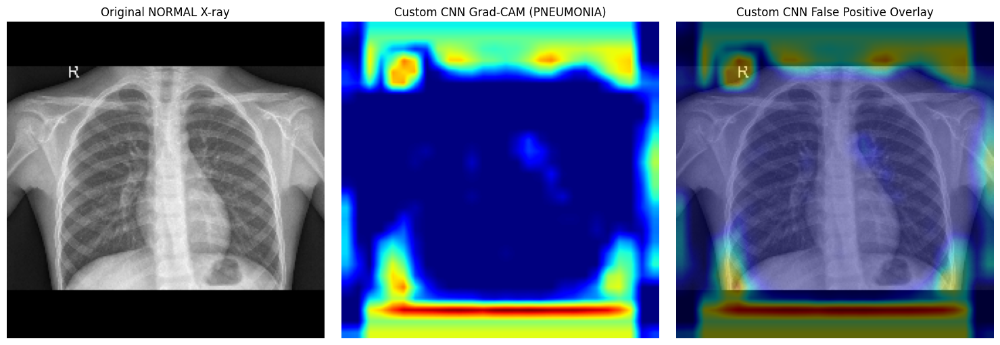

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import cv2

# Load original X-ray
image_bytes = tf.io.read_file(pneumocnn_fp_path)
original_image = tf.image.decode_image(
    image_bytes, channels=3, expand_animations=False
)

# Resize for display
display_image = tf.image.resize_with_pad(
    tf.cast(original_image, tf.float32),
    target_height=224,
    target_width=224
).numpy().astype(np.uint8)

# Resize Grad-CAM heatmap
heatmap_resized = cv2.resize(
    pneumocnn_fp_heatmap, (224, 224)
)

# Apply colour map
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(
    heatmap_uint8, cv2.COLORMAP_JET
)
heatmap_colored = cv2.cvtColor(
    heatmap_colored, cv2.COLOR_BGR2RGB
)

# Create overlay
overlay = cv2.addWeighted(
    display_image, 0.6,
    heatmap_colored, 0.4, 0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_image)
plt.title("Original NORMAL X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Custom CNN Grad-CAM (PNEUMONIA)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Custom CNN False Positive Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

True Positive (TP) example

In [ ]:
# Identify True Positive cases
tp_indices_pneumocnn = np.where(
    (pneumocnn_test_y_true == 1) &
    (pneumocnn_test_y_pred == 1)
)[0]

print("Number of True Positive cases:", len(tp_indices_pneumocnn))

# Select the first True Positive example
pneumocnn_tp_index = tp_indices_pneumocnn[0]

pneumocnn_tp_path = test_df.iloc[pneumocnn_tp_index]["filepath"]

print("Selected image:", pneumocnn_tp_path)
print("Actual class: PNEUMONIA")
print("Predicted class: PNEUMONIA")
print(
    "Pneumonia probability:",
    round(float(pneumocnn_test_y_prob[pneumocnn_tp_index]) * 100, 4),
    "%"
)

Number of True Positive cases: 374
Selected image: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/PNEUMONIA/person100_bacteria_477.jpeg
Actual class: PNEUMONIA
Predicted class: PNEUMONIA
Pneumonia probability: 98.9358 %


Generate the TP Grad-CAM

In [ ]:
# Prepare the selected True Positive image
pneumocnn_tp_image_array = prepare_pneumocnn_gradcam_image(
    pneumocnn_tp_path
)

# Generate Grad-CAM for the predicted class: PNEUMONIA
pneumocnn_tp_heatmap, pneumocnn_tp_prediction = generate_pneumocnn_gradcam(
    pneumocnn_test_model,
    pneumocnn_tp_image_array,
    target_class="PNEUMONIA",
    last_conv_layer_name="activation_3"
)

print("Custom CNN True Positive Grad-CAM generated.")
print("Actual class: PNEUMONIA")
print("Predicted class: PNEUMONIA")
print("Pneumonia probability:", round(pneumocnn_tp_prediction * 100, 4), "%")
print("NORMAL probability:", round((1 - pneumocnn_tp_prediction) * 100, 4), "%")
print("Heatmap shape:", pneumocnn_tp_heatmap.shape)

Custom CNN True Positive Grad-CAM generated.
Actual class: PNEUMONIA
Predicted class: PNEUMONIA
Pneumonia probability: 98.9358 %
NORMAL probability: 1.0642 %
Heatmap shape: (28, 28)


Display the final TP Grad-CAM overlay

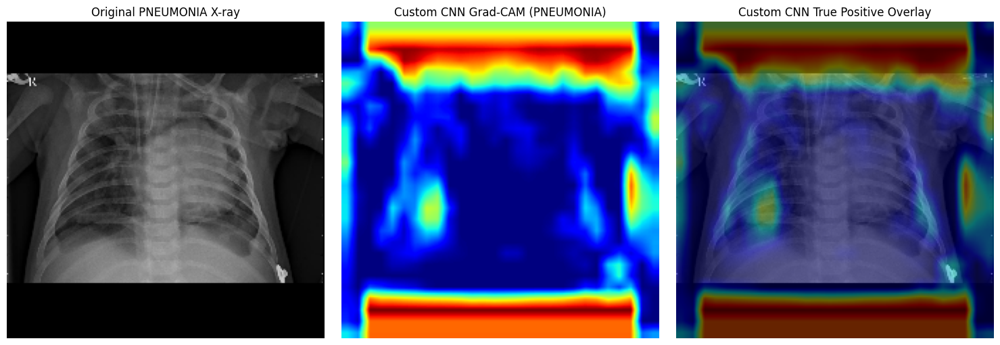

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import cv2

# Load original X-ray
image_bytes = tf.io.read_file(pneumocnn_tp_path)
original_image = tf.image.decode_image(
    image_bytes, channels=3, expand_animations=False
)

# Resize for display
display_image = tf.image.resize_with_pad(
    tf.cast(original_image, tf.float32),
    target_height=224,
    target_width=224
).numpy().astype(np.uint8)

# Resize Grad-CAM heatmap
heatmap_resized = cv2.resize(
    pneumocnn_tp_heatmap, (224, 224)
)

# Apply colour map
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(
    heatmap_uint8, cv2.COLORMAP_JET
)
heatmap_colored = cv2.cvtColor(
    heatmap_colored, cv2.COLOR_BGR2RGB
)

# Create overlay
overlay = cv2.addWeighted(
    display_image, 0.6,
    heatmap_colored, 0.4, 0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_image)
plt.title("Original PNEUMONIA X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Custom CNN Grad-CAM (PNEUMONIA)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Custom CNN True Positive Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Let's restore it step by step

In [ ]:
pneumocnn_tp_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/PNEUMONIA/person100_bacteria_477.jpeg"

import os

print("Image exists:", os.path.exists(pneumocnn_tp_path))
print("Image path:", pneumocnn_tp_path)

Image exists: False
Image path: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/PNEUMONIA/person100_bacteria_477.jpeg


Check Google Drive connection

In [ ]:
import os

print("Google Drive mounted:", os.path.exists("/content/drive/MyDrive"))

if os.path.exists("/content/drive/MyDrive"):
    print("Drive is connected.")
else:
    print("Google Drive is NOT connected.")

Google Drive mounted: True
Drive is connected.


Reconnect Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Confirm the connection

In [ ]:
import os

project_dir = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

print("Google Drive mounted:",
      os.path.exists("/content/drive/MyDrive"))

print("Research folder exists:",
      os.path.exists(project_dir))

if os.path.exists(project_dir):
    print("\nResearch folder contents:")
    print(os.listdir(project_dir))

Google Drive mounted: True
Research folder exists: True

Research folder contents:
['Untitled0.ipynb', 'chest_xray', 'splits', 'saved_models', 'training_histories', 'evaluation_results']


Let's inspect your saved models

In [ ]:
import os

saved_models_dir = (
    "/content/drive/MyDrive/"
    "MPhil_Pneumonia_Detection_Research/saved_models"
)

print("SAVED MODEL FILES:\n")

for root, dirs, files in os.walk(saved_models_dir):
    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"{file}  |  {size_mb:.2f} MB")

SAVED MODEL FILES:

pneumocnn_best.keras  |  4.93 MB
vgg16_best.keras  |  57.74 MB
vgg16_run3_best.keras  |  57.74 MB
resnet50_best.keras  |  96.63 MB
densenet121_best.keras  |  31.32 MB
inceptionv3_best.keras  |  90.24 MB


Load DenseNet121

In [ ]:
import os
import tensorflow as tf

densenet_path = (
    "/content/drive/MyDrive/"
    "MPhil_Pneumonia_Detection_Research/"
    "saved_models/densenet121_best.keras"
)

print("Model file exists:", os.path.exists(densenet_path))

densenet_demo_model = tf.keras.models.load_model(
    densenet_path,
    compile=False
)

print("\nDenseNet121 loaded successfully!")
print("Input shape:", densenet_demo_model.input_shape)
print("Output shape:", densenet_demo_model.output_shape)

Model file exists: True

DenseNet121 loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


Test the model on one chest X-ray

In [ ]:
import os

test_folder = (
    "/content/drive/MyDrive/"
    "MPhil_Pneumonia_Detection_Research/"
    "chest_xray/test"
)

print("Test folder exists:", os.path.exists(test_folder))

for category in ["NORMAL", "PNEUMONIA"]:
    folder = os.path.join(test_folder, category)

    print(f"\n{category} folder exists:", os.path.exists(folder))

    if os.path.exists(folder):
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpeg", ".jpg", ".png"))
        ]
        print("Number of images:", len(images))
        print("Example image:", images[0] if images else "No images found")

Test folder exists: True

NORMAL folder exists: True
Number of images: 234
Example image: IM-0001-0001.jpeg

PNEUMONIA folder exists: True
Number of images: 390
Example image: person100_bacteria_475.jpeg


Confirm the cleaned test dataset

In [ ]:
import pandas as pd
import os

test_csv = (
    "/content/drive/MyDrive/"
    "MPhil_Pneumonia_Detection_Research/"
    "splits/test_clean.csv"
)

test_df_demo = pd.read_csv(test_csv)

print("Cleaned test dataset loaded successfully.")
print("Total images:", len(test_df_demo))
print("\nColumns:")
print(test_df_demo.columns.tolist())

print("\nClass distribution:")
print(test_df_demo.iloc[:, -1].value_counts())

Cleaned test dataset loaded successfully.
Total images: 618

Columns:
['filepath', 'label']

Class distribution:
label
PNEUMONIA    387
NORMAL       231
Name: count, dtype: int64


In [ ]:
pneumocnn_tp_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/PNEUMONIA/person100_bacteria_477.jpeg"

print("True Positive image path restored.")
print(pneumocnn_tp_path)
print("File exists:", os.path.exists(pneumocnn_tp_path))

True Positive image path restored.
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/PNEUMONIA/person100_bacteria_477.jpeg
File exists: True


In [ ]:
image_bytes = tf.io.read_file(pneumocnn_tp_path)

In [ ]:
# Prepare the True Positive image
pneumocnn_tp_image_array = prepare_pneumocnn_gradcam_image(
    pneumocnn_tp_path
)

# Regenerate the True Positive Grad-CAM heatmap
pneumocnn_tp_heatmap, pneumocnn_tp_prediction = generate_pneumocnn_gradcam(
    pneumocnn_test_model,
    pneumocnn_tp_image_array,
    target_class="PNEUMONIA",
    last_conv_layer_name="activation_3"
)

print("True Positive Grad-CAM heatmap restored successfully.")
print("Pneumonia probability:", round(pneumocnn_tp_prediction * 100, 4), "%")
print("Heatmap shape:", pneumocnn_tp_heatmap.shape)

NameError: name 'prepare_pneumocnn_gradcam_image' is not defined

In [ ]:
import tensorflow as tf

def prepare_pneumocnn_gradcam_image(image_path):
    image_bytes = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image = tf.cast(image, tf.float32)

    image = tf.image.resize_with_pad(
        image,
        target_height=224,
        target_width=224
    )

    image = image / 255.0

    image = tf.expand_dims(image, axis=0)

    return image

print("Custom CNN image preparation function restored.")

Custom CNN image preparation function restored.


In [ ]:
import tensorflow as tf
import numpy as np

def generate_pneumocnn_gradcam(
    model,
    image,
    target_class="PNEUMONIA",
    last_conv_layer_name="activation_3"
):
    conv_layer = model.get_layer(last_conv_layer_name)

    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[conv_layer.output, model.output]
    )

    image_tensor = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image_tensor, training=False
        )

        pneumonia_score = predictions[:, 0]

        if target_class == "PNEUMONIA":
            score = pneumonia_score
        elif target_class == "NORMAL":
            score = 1.0 - pneumonia_score
        else:
            raise ValueError("Invalid target class")

    grads = tape.gradient(score, conv_outputs)

    pooled_grads = tf.reduce_mean(
        grads, axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) +
        tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), float(predictions[0][0].numpy())


print("Custom CNN Grad-CAM generation function restored.")

Custom CNN Grad-CAM generation function restored.


In [ ]:
print("Custom CNN model loaded:", "pneumocnn_test_model" in globals())

Custom CNN model loaded: False


In [ ]:
import os

project_folder = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

for root, dirs, files in os.walk(project_folder):
    for file in files:
        if file.endswith((".keras", ".h5", ".hdf5")):
            print(os.path.join(root, file))

/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/pneumocnn_best.keras
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/vgg16_best.keras
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/vgg16_run3_best.keras
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/resnet50_best.keras
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/densenet121_best.keras
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/saved_models/inceptionv3_best.keras


In [ ]:
import tensorflow as tf

pneumocnn_model_path = (
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/"
    "saved_models/pneumocnn_best.keras"
)

pneumocnn_test_model = tf.keras.models.load_model(
    pneumocnn_model_path,
    compile=False
)

print("Custom CNN model loaded successfully.")
print("Input shape:", pneumocnn_test_model.input_shape)
print("Output shape:", pneumocnn_test_model.output_shape)

Custom CNN model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [ ]:
pneumocnn_tp_image_array = prepare_pneumocnn_gradcam_image(
    pneumocnn_tp_path
)

pneumocnn_tp_heatmap, pneumocnn_tp_prediction = generate_pneumocnn_gradcam(
    pneumocnn_test_model,
    pneumocnn_tp_image_array,
    target_class="PNEUMONIA",
    last_conv_layer_name="activation_3"
)

print("TP Grad-CAM heatmap regenerated successfully.")
print("Prediction score:", round(pneumocnn_tp_prediction * 100, 2), "%")
print("Heatmap shape:", pneumocnn_tp_heatmap.shape)

TP Grad-CAM heatmap regenerated successfully.
Prediction score: 98.94 %
Heatmap shape: (28, 28)


First, let's make it compatible with your actual dataset

In [ ]:
import pandas as pd

test_csv_path = (
    "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/"
    "splits/test_clean.csv"
)

test_df = pd.read_csv(test_csv_path)

print("Dataset columns:")
print(test_df.columns.tolist())

print("\nFirst five records:")
display(test_df.head())

print("\nTotal test images:", len(test_df))

Dataset columns:
['filepath', 'label']

First five records:


,filepath,label
0,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
1,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
2,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
3,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
4,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL



Total test images: 618


How to save the CSV

In [ ]:
import os

os.makedirs("training_histories", exist_ok=True)

vgg16_history_df.to_csv(
    "training_histories/vgg16_training_history.csv",
    index=False
)

print("VGG16 history saved successfully.")

NameError: name 'vgg16_history_df' is not defined

In [ ]:

import os
import pandas as pd
from google.colab import files

# Create the training_histories folder
os.makedirs("training_histories", exist_ok=True)

# Convert VGG16 training history into a DataFrame
vgg16_history_df = pd.DataFrame(history_vgg16.history)

# Save the history as a CSV file
csv_path = "training_histories/vgg16_training_history.csv"
vgg16_history_df.to_csv(csv_path, index=False)

# Download the CSV file
files.download(csv_path)

print("VGG16 training history exported successfully!")
print(vgg16_history_df)


NameError: name 'history_vgg16' is not defined

In [ ]:

# Check whether the VGG16 training variables exist
for name in ["history_vgg16", "vgg16_history_df", "vgg16_model"]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT AVAILABLE'}")


history_vgg16: NOT AVAILABLE
vgg16_history_df: NOT AVAILABLE
vgg16_model: NOT AVAILABLE


In [ ]:

import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if "vgg16" in file.lower():
            print(os.path.join(root, file))


In [ ]:

print("Current working directory:")
print(os.getcwd())

print("\nAvailable VGG16-related variables:")
for name in globals():
    if "vgg" in name.lower():
        print(name)


Current working directory:
/content

Available VGG16-related variables:


In [ ]:

import pandas as pd
from google.colab import files

vgg16_data = {
    "accuracy": [
        0.9486, 0.9462, 0.9436, 0.9481, 0.9460,
        0.9448, 0.9498, 0.9462, 0.9476, 0.9467
    ],
    "loss": [
        0.1619, 0.1698, 0.1631, 0.1623, 0.1618,
        0.1647, 0.1581, 0.1622, 0.1593, 0.1576
    ],
    "val_accuracy": [
        0.9223, 0.9232, 0.9203, 0.9242, 0.9223,
        0.9213, 0.9251, 0.9232, 0.9232, 0.9194
    ],
    "val_loss": [
        0.278198, 0.270198, 0.277349, 0.267021, 0.271264,
        0.275244, 0.273140, 0.269067, 0.268870, 0.277665
    ],
    "learning_rate": [0.000001] * 10
}

df = pd.DataFrame(vgg16_data)
df.insert(0, "epoch", range(1, 11))

df.to_csv("vgg16_training_history.csv", index=False)

files.download("vgg16_training_history.csv")

print("VGG16 history CSV created successfully.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

VGG16 history CSV created successfully.


In [ ]:

import os

print("Checking dataset folders...\n")

paths = [
    "/content/chest_xray",
    "/content/chest_xray/train",
    "/content/chest_xray/val",
    "/content/chest_xray/test",
    "/content/drive/MyDrive/chest_xray"
]

for path in paths:
    print(f"{path}: {'EXISTS' if os.path.exists(path) else 'NOT FOUND'}")


Checking dataset folders...

/content/chest_xray: NOT FOUND
/content/chest_xray/train: NOT FOUND
/content/chest_xray/val: NOT FOUND
/content/chest_xray/test: NOT FOUND
/content/drive/MyDrive/chest_xray: NOT FOUND


In [ ]:

import os

print("FILES IN /content:")
for item in os.listdir("/content"):
    print(item)

print("\nIS GOOGLE DRIVE MOUNTED?")
print(os.path.exists("/content/drive/MyDrive"))

if os.path.exists("/content/drive/MyDrive"):
    print("\nFILES IN GOOGLE DRIVE:")
    for item in os.listdir("/content/drive/MyDrive"):
        print(item)


FILES IN /content:
.config
training_histories
vgg16_training_history.csv
sample_data

IS GOOGLE DRIVE MOUNTED?
False


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

search_locations = [
    "/content/drive/MyDrive",
    "/content/drive/Shareddrives"
]

keywords = ["chest_xray", "chest-xray", "pneumonia"]

print("Searching Google Drive for your dataset...\n")

for location in search_locations:
    if os.path.exists(location):
        for root, dirs, files in os.walk(location):
            dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]

            if any(keyword in os.path.basename(root).lower()
                   for keyword in keywords):
                print("POSSIBLE DATASET FOUND:")
                print(root)


Searching Google Drive for your dataset...

POSSIBLE DATASET FOUND:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research
POSSIBLE DATASET FOUND:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray
POSSIBLE DATASET FOUND:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/test/PNEUMONIA
POSSIBLE DATASET FOUND:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/val/PNEUMONIA
POSSIBLE DATASET FOUND:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/PNEUMONIA


In [ ]:

import os

DATASET_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray"

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()} DATASET")

    for category in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(DATASET_DIR, split, category)

        if os.path.exists(folder):
            images = [
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]
            print(f"{category}: {len(images)} images")
        else:
            print(f"{category}: Folder NOT FOUND")



TRAIN DATASET
NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL DATASET
NORMAL: 8 images
PNEUMONIA: 8 images

TEST DATASET
NORMAL: 234 images
PNEUMONIA: 390 images


In [ ]:

import os

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

for root, dirs, files in os.walk(BASE):
    level = root.replace(BASE, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}    {file}")


MPhil_Pneumonia_Detection_Research/
    Untitled0.ipynb
    chest_xray/
        test/
            NORMAL/
                IM-0001-0001.jpeg
                IM-0003-0001.jpeg
                IM-0005-0001.jpeg
                IM-0006-0001.jpeg
                IM-0007-0001.jpeg
                IM-0009-0001.jpeg
                IM-0010-0001.jpeg
                IM-0011-0001-0001.jpeg
                IM-0011-0001-0002.jpeg
                IM-0011-0001.jpeg
            PNEUMONIA/
                person100_bacteria_475.jpeg
                person100_bacteria_477.jpeg
                person100_bacteria_478.jpeg
                person100_bacteria_479.jpeg
                person100_bacteria_480.jpeg
                person100_bacteria_481.jpeg
                person100_bacteria_482.jpeg
                person101_bacteria_483.jpeg
                person101_bacteria_484.jpeg
                person101_bacteria_485.jpeg
        val/
            .DS_Store
            PNEUMONIA/
                .DS_Sto

In [ ]:

import pandas as pd
import os

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"
SPLIT_DIR = os.path.join(BASE, "splits")

for filename in ["train_clean.csv", "val_clean.csv", "test_clean.csv"]:
    path = os.path.join(SPLIT_DIR, filename)
    df = pd.read_csv(path)

    print("\n" + "=" * 50)
    print(filename)
    print("Total records:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nFirst five records:")
    print(df.head())

    # Display class distribution if a label column exists
    for col in df.columns:
        if col.lower() in ["label", "class", "category", "target"]:
            print("\nClass distribution:")
            print(df[col].value_counts())



train_clean.csv
Total records: 4164
Columns: ['filepath', 'label']

First five records:
                                            filepath   label
0  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL
1  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL
2  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL
3  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL
4  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL

Class distribution:
label
PNEUMONIA    3086
NORMAL       1078
Name: count, dtype: int64

val_clean.csv
Total records: 1042
Columns: ['filepath', 'label']

First five records:
                                            filepath   label
0  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL
1  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL
2  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL
3  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL
4  /content/drive/MyDrive/MPhil_Pneumonia_Detecti...  NORMAL

Cl

In [ ]:

import os
import pandas as pd
import tensorflow as tf

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"
SPLIT_DIR = os.path.join(BASE, "splits")

datasets = {}

for split in ["train", "val", "test"]:
    df = pd.read_csv(os.path.join(SPLIT_DIR, f"{split}_clean.csv"))
    datasets[split] = df

    missing = sum(not os.path.exists(p) for p in df["filepath"])

    print(f"\n{split.upper()}")
    print("Total images:", len(df))
    print("Missing images:", missing)

# Check for overlapping image paths between splits
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = set(datasets[a]["filepath"]) & set(datasets[b]["filepath"])
    print(f"\nOverlap between {a} and {b}: {len(overlap)}")

# Check GPU availability
print("\nGPU INFORMATION:")
print(tf.config.list_physical_devices("GPU"))



TRAIN
Total images: 4164
Missing images: 0

VAL
Total images: 1042
Missing images: 0

TEST
Total images: 618
Missing images: 0

Overlap between train and val: 0

Overlap between train and test: 0

Overlap between val and test: 0

GPU INFORMATION:
[]


In [ ]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

!nvidia-smi


TensorFlow version: 2.21.0
Thu Nov 19 07:59:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------------

In [ ]:
TensorFlow version: 2.21.0
Thu Nov 19 07:59:30 2026
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+------------------------+----------------------+

+-----------------------------------------------------------------------------------------+
| Processes:                                                                              |
|  GPU   GI   CI              PID   Type   Process name                        GPU Memory |
|        ID   ID                                                               Usage      |
|=========================================================================================|
|  No running processes found                                                             |
+-----------------------------------------------------------------------------------------+


SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (2649040165.py, line 2)

In [ ]:

import json

notebook_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Untitled0.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if any(term in source.lower() for term in [
        "build_pneumocnn",
        "pneumocnn_best",
        "pneumocnn.fit",
        "earlystopping",
        "reduce_lr"
    ]):
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print(source[:5000])


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Untitled0.ipynb'

In [ ]:

import os

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

print("Does the research folder exist?", os.path.exists(BASE))

if os.path.exists(BASE):
    print("\nFiles and folders available:")
    for item in os.listdir(BASE):
        print(item)


Does the research folder exist? False


In [ ]:

from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:

import os

print("Google Drive mounted:",
      os.path.exists("/content/drive/MyDrive"))

print("\nMy Drive folders:")
for item in os.listdir("/content/drive/MyDrive"):
    print(item)


Google Drive mounted: True

My Drive folders:
Getting started.pdf
ty (1).jpg
ty.jpg
Programming week 1.pptx
Programming Week 5.pptx
ElectroStats (2).ppt
Programming Assignment.docx
POWERPOINT.zip
2017-2018 First Semester Examination Timetable - 05.12.2017..xlsx
google-asscociate android developer content.pdf
PAUL DAWKINS CALC_II.pdf
encapsulation for car.cbp
assignment one.cbp
NetsparkerSetup.exe
CURRICULUM VITAE.docx
linear-guest.pdf 2.pdf
assignment2.zip
Classroom
DATA STRUCTURE OBJECTIVES .doc
Admissions_DevFin.pdf
BSc_ComputerScience (1).pdf
hwsoln06.pdf
CSC303A - Lecture1.pdf
CSC303A - Lecture3.pdf
Undergraduate-Forms1.pdf
CSC303A - Lecture2.pdf
Lecture 1 .pdf
Lecture 7.pdf
V Cs Report 2016.pdf
BScICT.pdf
CSC303A - Lecture4.pdf
web.ws25pkg.ws25_por
Lecture 9.pdf
DSA Exam.pdf
critical-section.pdf
Operating_Systems.pdf
Group 1 Marking Scheme.pdf
hwsoln06(1).pdf
AWUTU_SENYA_EAST_COORDINATE.pdf
OfficeProfessionalPlus_x64_en-us.img
Project Proposal Template (1).gdoc
Project Proposal Te

In [ ]:

import os

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

print("Research folder exists:", os.path.exists(BASE))

if os.path.exists(BASE):
    print("\nAvailable files:")
    for item in os.listdir(BASE):
        print(item)

    notebook_path = os.path.join(BASE, "Untitled0.ipynb")
    print("\nOriginal notebook exists:", os.path.exists(notebook_path))


Research folder exists: True

Available files:
chest_xray
splits
saved_models
training_histories
evaluation_results
defence_outputs
Untitled0.ipynb

Original notebook exists: True


In [ ]:

import json
import os

notebook_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Untitled0.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "pneumocnn",
    "build_model",
    "randomrotation",
    "randomtranslation",
    "randomzoom",
    "earlystopping",
    "reducelronplateau",
    "batch_size"
]

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if any(keyword in source.lower() for keyword in keywords):
        print("\n" + "=" * 70)
        print("CELL:", i)
        print(source[:4000])



CELL: 37
# ==========================================
# STEP 13: IMAGE PREPROCESSING CONFIGURATION
# ==========================================

IMAGE_SIZE = {
    "PneumoCNN": (224, 224),
    "VGG16": (224, 224),
    "ResNet50": (224, 224),
    "DenseNet121": (224, 224),
    "InceptionV3": (299, 299)
}

CHANNELS = 3

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

BATCH_SIZE = 32

RANDOM_SEED = 42

print("PREPROCESSING CONFIGURATION")
print("--------------------------------")

for model, dimensions in IMAGE_SIZE.items():
    print(f"{model}: {dimensions} x {CHANNELS} channels")

print("\nClass names:", CLASS_NAMES)
print("Batch size:", BATCH_SIZE)
print("Random seed:", RANDOM_SEED)

CELL: 50
# ==========================================
# STEP 17: MODEL-SPECIFIC PREPROCESSING
# ==========================================

def apply_model_preprocessing(image, model_name):

    if model_name == "PneumoCNN":

        # Scale pixels from 0-255 to 0-1
        image = image / 255.0

    elif model_na

In [ ]:

import os

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

files_to_check = [
    "saved_models/pneumocnn_best.keras",
    "training_histories/pneumocnn_training_history.csv",
    "splits/train_clean.csv",
    "splits/val_clean.csv",
    "splits/test_clean.csv"
]

for file in files_to_check:
    path = os.path.join(BASE, file)
    print(file, ":", "AVAILABLE" if os.path.exists(path) else "MISSING")


saved_models/pneumocnn_best.keras : AVAILABLE
training_histories/pneumocnn_training_history.csv : AVAILABLE
splits/train_clean.csv : AVAILABLE
splits/val_clean.csv : AVAILABLE
splits/test_clean.csv : AVAILABLE


In [ ]:

import os

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

ABLATION_DIR = os.path.join(BASE, "augmentation_ablation")

folders = [
    "models",
    "training_histories",
    "predictions",
    "evaluation_results",
    "figures"
]

for folder in folders:
    path = os.path.join(ABLATION_DIR, folder)
    os.makedirs(path, exist_ok=True)
    print("Created/verified:", path)

print("\nAugmentation ablation workspace is ready.")


Created/verified: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/models
Created/verified: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/training_histories
Created/verified: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/predictions
Created/verified: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/evaluation_results
Created/verified: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/figures

Augmentation ablation workspace is ready.


In [ ]:

import os
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"
ABLATION_DIR = os.path.join(BASE, "augmentation_ablation")

# Load original cleaned splits
train_df = pd.read_csv(os.path.join(BASE, "splits/train_clean.csv"))
val_df = pd.read_csv(os.path.join(BASE, "splits/val_clean.csv"))
test_df = pd.read_csv(os.path.join(BASE, "splits/test_clean.csv"))

# Encode labels: NORMAL=0, PNEUMONIA=1
y_train = train_df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).values.astype(np.int32)

# Calculate class weights using training data only
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weight_dict = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("DATASET SUMMARY")
print("-------------------------")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nCLASS WEIGHTS")
print(class_weight_dict)

print("\nGPU:")
print(tf.config.list_physical_devices("GPU"))

print("\nDataset preparation completed.")


DATASET SUMMARY
-------------------------
Training: 4164
Validation: 1042
Testing: 618

CLASS WEIGHTS
{0: 1.9313543599257885, 1: 0.6746597537265068}

GPU:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Dataset preparation completed.


In [ ]:
import tensorflow as tf
import numpy as np
import os

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Original five augmentation techniques
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.0278, fill_mode="reflect"
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomFlip(mode="horizontal"),
    tf.keras.layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255)
    )
])

def load_image(filepath, label, use_augmentation=False):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image, IMG_SIZE, IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    # Apply augmentation before normalization
    if use_augmentation:
        image = data_augmentation(
            tf.expand_dims(image, axis=0),
            training=True
        )[0]

    image = image / 255.0

    return image, tf.cast(label, tf.float32)


def create_dataset(df, use_augmentation=False, shuffle=False):
    filepaths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda x, y: load_image(
            x, y, use_augmentation
        ),
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


print("Data pipeline defined successfully.")

Data pipeline defined successfully.


In [ ]:
# Create small test batches
train_test_ds = create_dataset(
    train_df,
    use_augmentation=False,
    shuffle=False
)

val_test_ds = create_dataset(
    val_df,
    use_augmentation=False,
    shuffle=False
)

# Inspect one training batch
images, labels = next(iter(train_test_ds))

print("IMAGE PIPELINE TEST")
print("-------------------")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))
print("Unique labels:", np.unique(labels.numpy()))

print("\nVALIDATION DATASET")
print("-------------------")
print("Validation batches:", tf.data.experimental.cardinality(val_test_ds).numpy())

print("\nPipeline test completed.")

IMAGE PIPELINE TEST
-------------------
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Unique labels: [0.]

VALIDATION DATASET
-------------------
Validation batches: 33

Pipeline test completed.


In [ ]:
from tensorflow.keras import layers, models, regularizers

def build_pneumocnn():

    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(32, (3, 3), padding="same",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding="same",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding="same",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), padding="same",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu",
                     kernel_regularizer=regularizers.l2(0.0001)),

        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid",
                     name="pneumonia_output")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Build a temporary model to inspect the architecture
test_model = build_pneumocnn()

test_model.summary()

print("\nPneumoCNN architecture defined successfully.")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)


PneumoCNN architecture defined successfully.


In [ ]:
def create_training_callbacks(experiment_name):

    model_path = os.path.join(
        ABLATION_DIR,
        "models",
        f"{experiment_name}_best.keras"
    )

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=model_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=0.000001,
            verbose=1
        )
    ]

    return callbacks


print("Training callbacks defined successfully.")

Training callbacks defined successfully.


Experiment A — Train without data augmentation

In [ ]:
# Set reproducibility seed
tf.keras.utils.set_random_seed(42)

# Create datasets WITHOUT augmentation
train_no_aug = create_dataset(
    train_df,
    use_augmentation=False,
    shuffle=True
)

val_no_aug = create_dataset(
    val_df,
    use_augmentation=False,
    shuffle=False
)

# Build a fresh PneumoCNN model
model_no_aug = build_pneumocnn()

# Create callbacks
callbacks_no_aug = create_training_callbacks("pneumocnn_no_augmentation")

# Train the model
history_no_aug = model_no_aug.fit(
    train_no_aug,
    validation_data=val_no_aug,
    epochs=100,
    class_weight=class_weight_dict,
    callbacks=callbacks_no_aug,
    verbose=1
)

print("\nExperiment A completed.")

Epoch 1/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7815 - loss: 0.4854
Epoch 1: val_loss improved from None to 0.92188, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/models/pneumocnn_no_augmentation_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/models/pneumocnn_no_augmentation_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 854s 6s/step - accuracy: 0.8480 - loss: 0.3846 - val_accuracy: 0.7409 - val_loss: 0.9219 - learning_rate: 1.0000e-04
Epoch 2/100
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - accuracy: 0.9044 - loss: 0.2803
Epoch 2: val_loss improved from 0.92188 to 0.85101, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/models/pneumocnn_no_augmentation_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/models/pneumocnn_no_augm

In [ ]:
import pandas as pd
import os
import numpy as np

# Convert training history to a DataFrame
history_no_aug_df = pd.DataFrame(history_no_aug.history)

# Add epoch numbers
history_no_aug_df.insert(
    0, "epoch",
    range(1, len(history_no_aug_df) + 1)
)

# Save training history
history_path = os.path.join(
    ABLATION_DIR,
    "training_histories",
    "pneumocnn_no_augmentation_history.csv"
)

history_no_aug_df.to_csv(history_path, index=False)

# Identify best epoch using validation loss
best_epoch = np.argmin(history_no_aug.history["val_loss"])

print("EXPERIMENT A RESULTS")
print("--------------------")
print("Epochs completed:", len(history_no_aug.history["loss"]))
print("Best epoch:", best_epoch + 1)
print("Best validation loss:",
      history_no_aug.history["val_loss"][best_epoch])
print("Validation accuracy at best epoch:",
      history_no_aug.history["val_accuracy"][best_epoch])
print("Training accuracy at best epoch:",
      history_no_aug.history["accuracy"][best_epoch])

print("\nTraining history saved to:")
print(history_path)

EXPERIMENT A RESULTS
--------------------
Epochs completed: 29
Best epoch: 19
Best validation loss: 0.14155924320220947
Validation accuracy at best epoch: 0.9606525897979736
Training accuracy at best epoch: 0.9654178619384766

Training history saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/training_histories/pneumocnn_no_augmentation_history.csv


In [ ]:
# Reset seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Create datasets WITH augmentation
train_aug = create_dataset(
    train_df,
    use_augmentation=True,
    shuffle=True
)

val_aug = create_dataset(
    val_df,
    use_augmentation=False,
    shuffle=False
)

# Build a fresh PneumoCNN model
model_aug = build_pneumocnn()

# Create callbacks
callbacks_aug = create_training_callbacks(
    "pneumocnn_with_augmentation"
)

# Train the model
history_aug = model_aug.fit(
    train_aug,
    validation_data=val_aug,
    epochs=100,
    class_weight=class_weight_dict,
    callbacks=callbacks_aug,
    verbose=1
)

print("\nExperiment B completed.")

Epoch 1/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 882ms/step - accuracy: 0.7509 - loss: 0.5335
Epoch 1: val_loss improved from None to 0.94808, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/models/pneumocnn_with_augmentation_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/models/pneumocnn_with_augmentation_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 155s 978ms/step - accuracy: 0.8160 - loss: 0.4355 - val_accuracy: 0.7409 - val_loss: 0.9481 - learning_rate: 1.0000e-04
Epoch 2/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 862ms/step - accuracy: 0.8736 - loss: 0.3443
Epoch 2: val_loss did not improve from 0.94808
131/131 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.8739 - loss: 0.3454 - val_accuracy: 0.7409 - val_loss: 1.2478 - learning_rate: 1.0000e-04
Epoch 3/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 853ms/step - accuracy: 0.8863 - loss: 0.3194
Epoch 3: val_loss did not improve from 

In [ ]:
import pandas as pd
import numpy as np
import os

# Convert training history to DataFrame
history_aug_df = pd.DataFrame(history_aug.history)

# Add epoch numbers
history_aug_df.insert(
    0, "epoch",
    range(1, len(history_aug_df) + 1)
)

# Save training history
history_path = os.path.join(
    ABLATION_DIR,
    "training_histories",
    "pneumocnn_with_augmentation_history.csv"
)

history_aug_df.to_csv(history_path, index=False)

# Identify best epoch
best_epoch = np.argmin(history_aug.history["val_loss"])

print("EXPERIMENT B RESULTS")
print("--------------------")
print("Epochs completed:", len(history_aug.history["loss"]))
print("Best epoch:", best_epoch + 1)

print("Best validation loss:",
      history_aug.history["val_loss"][best_epoch])

print("Validation accuracy at best epoch:",
      history_aug.history["val_accuracy"][best_epoch])

print("Training accuracy at best epoch:",
      history_aug.history["accuracy"][best_epoch])

print("\nTraining history saved to:")
print(history_path)

EXPERIMENT B RESULTS
--------------------
Epochs completed: 30
Best epoch: 20
Best validation loss: 0.16659487783908844
Validation accuracy at best epoch: 0.9625719785690308
Training accuracy at best epoch: 0.9464457035064697

Training history saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/training_histories/pneumocnn_with_augmentation_history.csv


In [ ]:
# Create the untouched test dataset
test_ds = create_dataset(
    test_df,
    use_augmentation=False,
    shuffle=False
)

# Evaluate model without augmentation
print("EXPERIMENT A: WITHOUT AUGMENTATION")
results_no_aug = model_no_aug.evaluate(
    test_ds,
    verbose=1
)

# Evaluate model with augmentation
print("\nEXPERIMENT B: WITH AUGMENTATION")
results_aug = model_aug.evaluate(
    test_ds,
    verbose=1
)

print("\nTEST EVALUATION SUMMARY")
print("-----------------------")

print("Without augmentation:")
print("Test loss:", results_no_aug[0])
print("Test accuracy:", results_no_aug[1])

print("\nWith augmentation:")
print("Test loss:", results_aug[0])
print("Test accuracy:", results_aug[1])

EXPERIMENT A: WITHOUT AUGMENTATION
20/20 ━━━━━━━━━━━━━━━━━━━━ 110s 5s/step - accuracy: 0.7654 - loss: 0.7085

EXPERIMENT B: WITH AUGMENTATION
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 295ms/step - accuracy: 0.7961 - loss: 0.5329

TEST EVALUATION SUMMARY
-----------------------
Without augmentation:
Test loss: 0.7084890604019165
Test accuracy: 0.7653721570968628

With augmentation:
Test loss: 0.5329456329345703
Test accuracy: 0.7961165308952332


In [ ]:
import numpy as np
import pandas as pd
import os

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Actual test labels
y_true = test_df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).values.astype(int)

# Predictions from both models
pred_no_aug = model_no_aug.predict(test_ds, verbose=1).ravel()
pred_aug = model_aug.predict(test_ds, verbose=1).ravel()

# Apply the same threshold
y_pred_no_aug = (pred_no_aug >= 0.50).astype(int)
y_pred_aug = (pred_aug >= 0.50).astype(int)


def calculate_metrics(y_true, y_pred, name):

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) else 0
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print("\n", name)
    print("=" * 45)
    print("Confusion Matrix:")
    print(cm)

    print("\nTN:", tn)
    print("FP:", fp)
    print("FN:", fn)
    print("TP:", tp)

    print("\nAccuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Sensitivity:", round(sensitivity, 4))
    print("Specificity:", round(specificity, 4))
    print("F1-score:", round(f1, 4))

    return {
        "Model": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1-score": f1
    }


results_A = calculate_metrics(
    y_true, y_pred_no_aug,
    "PneumoCNN Without Augmentation"
)

results_B = calculate_metrics(
    y_true, y_pred_aug,
    "PneumoCNN With Augmentation"
)

# Save comparison
comparison_df = pd.DataFrame([results_A, results_B])

save_path = os.path.join(
    ABLATION_DIR,
    "evaluation_results",
    "augmentation_ablation_comparison.csv"
)

comparison_df.to_csv(save_path, index=False)

print("\nComparison saved to:")
print(save_path)

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 548ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 385ms/step

 PneumoCNN Without Augmentation
Confusion Matrix:
[[ 87 144]
 [  1 386]]

TN: 87
FP: 144
FN: 1
TP: 386

Accuracy: 0.7654
Precision: 0.7283
Sensitivity: 0.9974
Specificity: 0.3766
F1-score: 0.8419

 PneumoCNN With Augmentation
Confusion Matrix:
[[109 122]
 [  4 383]]

TN: 109
FP: 122
FN: 4
TP: 383

Accuracy: 0.7961
Precision: 0.7584
Sensitivity: 0.9897
Specificity: 0.4719
F1-score: 0.8587

Comparison saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/evaluation_results/augmentation_ablation_comparison.csv


In [ ]:
import os

print("TRAINING IMAGE FILENAMES")
print("------------------------")
for path in train_df["filepath"].head(10):
    print(os.path.basename(path))

print("\nVALIDATION IMAGE FILENAMES")
print("--------------------------")
for path in val_df["filepath"].head(10):
    print(os.path.basename(path))

print("\nTEST IMAGE FILENAMES")
print("--------------------")
for path in test_df["filepath"].head(10):
    print(os.path.basename(path))

TRAINING IMAGE FILENAMES
------------------------
IM-0115-0001.jpeg
IM-0117-0001.jpeg
IM-0119-0001.jpeg
IM-0122-0001.jpeg
IM-0125-0001.jpeg
IM-0127-0001.jpeg
IM-0128-0001.jpeg
IM-0129-0001.jpeg
IM-0131-0001.jpeg
IM-0133-0001.jpeg

VALIDATION IMAGE FILENAMES
--------------------------
IM-0140-0001.jpeg
IM-0143-0001.jpeg
IM-0147-0001.jpeg
IM-0149-0001.jpeg
IM-0152-0001.jpeg
IM-0154-0001.jpeg
IM-0156-0001.jpeg
IM-0164-0001.jpeg
IM-0170-0001.jpeg
IM-0189-0001.jpeg

TEST IMAGE FILENAMES
--------------------
IM-0001-0001.jpeg
IM-0003-0001.jpeg
IM-0005-0001.jpeg
IM-0006-0001.jpeg
IM-0007-0001.jpeg
IM-0009-0001.jpeg
IM-0010-0001.jpeg
IM-0011-0001-0001.jpeg
IM-0011-0001-0002.jpeg
IM-0011-0001.jpeg


In [ ]:
import os
import pandas as pd

splits = {
    "TRAIN": train_df,
    "VALIDATION": val_df,
    "TEST": test_df
}

print("IMAGE SOURCE AND FILENAME INVESTIGATION")
print("=" * 55)

for split_name, df in splits.items():

    print(f"\n{split_name}")
    print("-" * 40)

    for label in ["NORMAL", "PNEUMONIA"]:

        class_df = df[df["label"] == label]

        print(f"\n{label}: {len(class_df)} images")

        for path in class_df["filepath"].head(5):
            print("Folder:", os.path.basename(os.path.dirname(path)))
            print("Filename:", os.path.basename(path))


# Check exact filename overlap across splits
filename_sets = {
    name: set(df["filepath"].apply(
        lambda x: os.path.basename(x).lower()
    ))
    for name, df in splits.items()
}

print("\nEXACT FILENAME OVERLAP")
print("=" * 55)

for first, second in [
    ("TRAIN", "VALIDATION"),
    ("TRAIN", "TEST"),
    ("VALIDATION", "TEST")
]:
    overlap = filename_sets[first] & filename_sets[second]

    print(f"{first} vs {second}: {len(overlap)} matching filenames")

print("\nInvestigation completed.")

IMAGE SOURCE AND FILENAME INVESTIGATION

TRAIN
----------------------------------------

NORMAL: 1078 images
Folder: NORMAL
Filename: IM-0115-0001.jpeg
Folder: NORMAL
Filename: IM-0117-0001.jpeg
Folder: NORMAL
Filename: IM-0119-0001.jpeg
Folder: NORMAL
Filename: IM-0122-0001.jpeg
Folder: NORMAL
Filename: IM-0125-0001.jpeg

PNEUMONIA: 3086 images
Folder: PNEUMONIA
Filename: person1000_bacteria_2931.jpeg
Folder: PNEUMONIA
Filename: person1000_virus_1681.jpeg
Folder: PNEUMONIA
Filename: person1001_bacteria_2932.jpeg
Folder: PNEUMONIA
Filename: person1003_bacteria_2934.jpeg
Folder: PNEUMONIA
Filename: person1003_virus_1685.jpeg

VALIDATION
----------------------------------------

NORMAL: 270 images
Folder: NORMAL
Filename: IM-0140-0001.jpeg
Folder: NORMAL
Filename: IM-0143-0001.jpeg
Folder: NORMAL
Filename: IM-0147-0001.jpeg
Folder: NORMAL
Filename: IM-0149-0001.jpeg
Folder: NORMAL
Filename: IM-0152-0001.jpeg

PNEUMONIA: 772 images
Folder: PNEUMONIA
Filename: person1002_bacteria_2933.jpeg

In [ ]:
import os
import re

def get_patient_id(filepath):
    filename = os.path.basename(filepath)

    # Extract pneumonia patient identifier
    match = re.match(r"(person\d+)_", filename, re.IGNORECASE)

    if match:
        return match.group(1).lower()

    # NORMAL filenames do not provide a reliable patient ID
    return None


patient_sets = {}

for split_name, df in {
    "TRAIN": train_df,
    "VALIDATION": val_df,
    "TEST": test_df
}.items():

    ids = set(
        patient_id
        for patient_id in df["filepath"].apply(get_patient_id)
        if patient_id is not None
    )

    patient_sets[split_name] = ids

    print(f"{split_name} pneumonia patient IDs: {len(ids)}")


print("\nPATIENT-LEVEL OVERLAP")
print("=" * 40)

for first, second in [
    ("TRAIN", "VALIDATION"),
    ("TRAIN", "TEST"),
    ("VALIDATION", "TEST")
]:

    overlap = patient_sets[first] & patient_sets[second]

    print(f"{first} vs {second}: {len(overlap)} overlapping IDs")

    if overlap:
        print("Examples:", list(sorted(overlap))[:10])

TRAIN pneumonia patient IDs: 1471
VALIDATION pneumonia patient IDs: 600
TEST pneumonia patient IDs: 202

PATIENT-LEVEL OVERLAP
TRAIN vs VALIDATION: 429 overlapping IDs
Examples: ['person1', 'person101', 'person1015', 'person1016', 'person1018', 'person1019', 'person1031', 'person1034', 'person1043', 'person1048']
TRAIN vs TEST: 150 overlapping IDs
Examples: ['person1', 'person100', 'person101', 'person102', 'person103', 'person108', 'person109', 'person11', 'person110', 'person111']
VALIDATION vs TEST: 62 overlapping IDs
Examples: ['person1', 'person10', 'person101', 'person104', 'person108', 'person110', 'person111', 'person113', 'person125', 'person131']


In [ ]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

DATA_DIR = os.path.join(BASE, "chest_xray")

print("ORIGINAL DATASET STRUCTURE")
print("=" * 50)

for root, dirs, files in os.walk(DATA_DIR):

    level = root.replace(DATA_DIR, "").count(os.sep)

    if level <= 2:
        indent = " " * (level * 4)

        print(
            f"{indent}{os.path.basename(root)}/ "
            f"({len(files)} files)"
        )

print("\nORIGINAL SPLIT CSV INFORMATION")
print("=" * 50)

for split in ["train_clean.csv", "val_clean.csv", "test_clean.csv"]:

    path = os.path.join(BASE, "splits", split)
    df = pd.read_csv(path)

    print(f"\n{split}")
    print("Columns:", df.columns.tolist())
    print("Total images:", len(df))
    print("Class distribution:")
    print(df["label"].value_counts())

    print("\nExample image paths:")
    for filepath in df["filepath"].head(3):
        print(filepath)

print("\nDataset inspection completed.")

ORIGINAL DATASET STRUCTURE
chest_xray/ (0 files)
    test/ (0 files)
        NORMAL/ (234 files)
        PNEUMONIA/ (390 files)
    val/ (1 files)
        PNEUMONIA/ (9 files)
        NORMAL/ (9 files)
    train/ (1 files)
        PNEUMONIA/ (3876 files)
        NORMAL/ (1342 files)

ORIGINAL SPLIT CSV INFORMATION

train_clean.csv
Columns: ['filepath', 'label']
Total images: 4164
Class distribution:
label
PNEUMONIA    3086
NORMAL       1078
Name: count, dtype: int64

Example image paths:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/NORMAL/IM-0115-0001.jpeg
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/NORMAL/IM-0117-0001.jpeg
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/chest_xray/train/NORMAL/IM-0119-0001.jpeg

val_clean.csv
Columns: ['filepath', 'label']
Total images: 1042
Class distribution:
label
PNEUMONIA    772
NORMAL       270
Name: count, dtype: int64

Example image paths:
/content/drive/MyDrive/MPhil_Pneum

In [ ]:
import os
import re
from collections import Counter

DATA_DIR = os.path.join(BASE, "chest_xray")

original_splits = ["train", "val", "test"]

print("ORIGINAL PNEUMONIA PATIENT DISTRIBUTION")
print("=" * 55)

for split in original_splits:

    folder = os.path.join(DATA_DIR, split, "PNEUMONIA")

    patient_counts = Counter()

    if not os.path.isdir(folder):
        print(f"\n{split}: Folder not found")
        continue

    for filename in os.listdir(folder):

        match = re.match(
            r"(person\d+)_",
            filename,
            re.IGNORECASE
        )

        if match:
            patient_counts[match.group(1).lower()] += 1

    print(f"\n{split.upper()}")
    print("Unique pneumonia patients:", len(patient_counts))
    print("Total identified images:", sum(patient_counts.values()))
    print("Patients with multiple images:",
          sum(1 for count in patient_counts.values() if count > 1))

    print("Sample patient groups:")
    for patient, count in list(patient_counts.items())[:10]:
        print(f"{patient}: {count} images")

print("\nInspection completed.")

ORIGINAL PNEUMONIA PATIENT DISTRIBUTION

TRAIN
Unique pneumonia patients: 1635
Total identified images: 3875
Patients with multiple images: 1005
Sample patient groups:
person540: 4 images
person541: 3 images
person542: 2 images
person543: 7 images
person544: 7 images
person545: 5 images
person546: 1 images
person547: 4 images
person548: 7 images
person549: 6 images

VAL
Unique pneumonia patients: 7
Total identified images: 8
Patients with multiple images: 1
Sample patient groups:
person1946: 2 images
person1947: 1 images
person1949: 1 images
person1950: 1 images
person1951: 1 images
person1952: 1 images
person1954: 1 images

TEST
Unique pneumonia patients: 202
Total identified images: 390
Patients with multiple images: 77
Sample patient groups:
person100: 7 images
person101: 4 images
person102: 1 images
person103: 3 images
person104: 2 images
person108: 4 images
person109: 9 images
person10: 1 images
person110: 1 images
person111: 5 images

Inspection completed.


In [ ]:
import os
import re
from collections import defaultdict

DATA_DIR = os.path.join(BASE, "chest_xray")

original_splits = ["train", "val", "test"]
patient_sets = {}

for split in original_splits:

    folder = os.path.join(DATA_DIR, split, "PNEUMONIA")
    ids = set()

    for filename in os.listdir(folder):

        match = re.match(
            r"(person\d+)_",
            filename,
            re.IGNORECASE
        )

        if match:
            ids.add(match.group(1).lower())

    patient_sets[split] = ids


print("ORIGINAL FOLDER PATIENT OVERLAP")
print("=" * 50)

for first, second in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:

    overlap = patient_sets[first] & patient_sets[second]

    print(f"\n{first.upper()} vs {second.upper()}")
    print("Overlapping patients:", len(overlap))

    if overlap:
        print("Examples:", sorted(overlap)[:15])

print("\nCheck completed.")

ORIGINAL FOLDER PATIENT OVERLAP

TRAIN vs VAL
Overlapping patients: 0

TRAIN vs TEST
Overlapping patients: 170
Examples: ['person1', 'person10', 'person100', 'person101', 'person102', 'person103', 'person104', 'person108', 'person109', 'person11', 'person110', 'person111', 'person112', 'person113', 'person114']

VAL vs TEST
Overlapping patients: 0

Check completed.


In [ ]:
import os
import re
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit, train_test_split

DATA_DIR = os.path.join(BASE, "chest_xray")

CORRECTED_DIR = os.path.join(BASE, "corrected_experiments")
SPLIT_DIR = os.path.join(CORRECTED_DIR, "splits")

os.makedirs(SPLIT_DIR, exist_ok=True)

# Collect all images from the original folders
records = []

for split in ["train", "val", "test"]:
    for label in ["NORMAL", "PNEUMONIA"]:

        folder = os.path.join(DATA_DIR, split, label)

        for filename in os.listdir(folder):

            if filename.lower().endswith(
                (".jpeg", ".jpg", ".png")
            ):
                filepath = os.path.join(folder, filename)

                records.append({
                    "filepath": filepath,
                    "label": label
                })

all_df = pd.DataFrame(records)

print("TOTAL IMAGES COLLECTED:", len(all_df))
print("\nOriginal class distribution:")
print(all_df["label"].value_counts())


# Separate the two classes
normal_df = all_df[all_df["label"] == "NORMAL"].copy()
pneumonia_df = all_df[all_df["label"] == "PNEUMONIA"].copy()

# Extract pneumonia patient IDs
pneumonia_df["patient_id"] = pneumonia_df["filepath"].apply(
    lambda x: re.match(
        r"(person\d+)_",
        os.path.basename(x),
        re.IGNORECASE
    ).group(1).lower()
)

# Split pneumonia by patient group
group_split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

p_train_idx, p_test_idx = next(
    group_split_1.split(
        pneumonia_df,
        groups=pneumonia_df["patient_id"]
    )
)

p_train_val = pneumonia_df.iloc[p_train_idx]
p_test = pneumonia_df.iloc[p_test_idx]

group_split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1764706,
    random_state=42
)

p_train_idx2, p_val_idx = next(
    group_split_2.split(
        p_train_val,
        groups=p_train_val["patient_id"]
    )
)

p_train = p_train_val.iloc[p_train_idx2]
p_val = p_train_val.iloc[p_val_idx]


# Split NORMAL images at image level
n_train_val, n_test = train_test_split(
    normal_df,
    test_size=0.15,
    random_state=42,
    shuffle=True
)

n_train, n_val = train_test_split(
    n_train_val,
    test_size=0.1764706,
    random_state=42,
    shuffle=True
)


# Combine both classes
train_new = pd.concat([
    n_train, p_train
]).sample(frac=1, random_state=42).reset_index(drop=True)

val_new = pd.concat([
    n_val, p_val
]).sample(frac=1, random_state=42).reset_index(drop=True)

test_new = pd.concat([
    n_test, p_test
]).sample(frac=1, random_state=42).reset_index(drop=True)


# Save corrected CSV files
train_new[["filepath", "label"]].to_csv(
    os.path.join(SPLIT_DIR, "train_grouped.csv"),
    index=False
)

val_new[["filepath", "label"]].to_csv(
    os.path.join(SPLIT_DIR, "val_grouped.csv"),
    index=False
)

test_new[["filepath", "label"]].to_csv(
    os.path.join(SPLIT_DIR, "test_grouped.csv"),
    index=False
)


print("\nCORRECTED SPLIT SUMMARY")
print("=" * 45)

for name, df in [
    ("TRAIN", train_new),
    ("VALIDATION", val_new),
    ("TEST", test_new)
]:
    print(f"\n{name}: {len(df)} images")
    print(df["label"].value_counts())

print("\nCorrected CSV files saved in:")
print(SPLIT_DIR)

TOTAL IMAGES COLLECTED: 5856

Original class distribution:
label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

CORRECTED SPLIT SUMMARY

TRAIN: 4093 images
label
PNEUMONIA    2986
NORMAL       1107
Name: count, dtype: int64

VALIDATION: 897 images
label
PNEUMONIA    659
NORMAL       238
Name: count, dtype: int64

TEST: 866 images
label
PNEUMONIA    628
NORMAL       238
Name: count, dtype: int64

Corrected CSV files saved in:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/splits


In [ ]:
import os
import re
import pandas as pd

SPLIT_DIR = os.path.join(
    BASE, "corrected_experiments", "splits"
)

train_new = pd.read_csv(
    os.path.join(SPLIT_DIR, "train_grouped.csv")
)

val_new = pd.read_csv(
    os.path.join(SPLIT_DIR, "val_grouped.csv")
)

test_new = pd.read_csv(
    os.path.join(SPLIT_DIR, "test_grouped.csv")
)

splits = {
    "TRAIN": train_new,
    "VALIDATION": val_new,
    "TEST": test_new
}

# Check pneumonia patient IDs
def extract_patient_id(filepath):
    filename = os.path.basename(filepath)

    match = re.match(
        r"(person\d+)_",
        filename,
        re.IGNORECASE
    )

    return match.group(1).lower() if match else None


patient_sets = {}

for name, df in splits.items():

    ids = set(
        df[df["label"] == "PNEUMONIA"]["filepath"]
        .apply(extract_patient_id)
        .dropna()
    )

    patient_sets[name] = ids

print("PATIENT OVERLAP VERIFICATION")
print("=" * 45)

for first, second in [
    ("TRAIN", "VALIDATION"),
    ("TRAIN", "TEST"),
    ("VALIDATION", "TEST")
]:

    overlap = patient_sets[first] & patient_sets[second]

    print(f"{first} vs {second}: {len(overlap)}")


# Check exact filepath overlap
print("\nIMAGE PATH OVERLAP VERIFICATION")
print("=" * 45)

for first, second in [
    ("TRAIN", "VALIDATION"),
    ("TRAIN", "TEST"),
    ("VALIDATION", "TEST")
]:

    overlap = (
        set(splits[first]["filepath"])
        & set(splits[second]["filepath"])
    )

    print(f"{first} vs {second}: {len(overlap)}")


# Check missing files
print("\nFILE EXISTENCE VERIFICATION")
print("=" * 45)

for name, df in splits.items():

    missing = sum(
        not os.path.isfile(path)
        for path in df["filepath"]
    )

    print(f"{name} missing files: {missing}")


print("\nVERIFICATION COMPLETED.")

PATIENT OVERLAP VERIFICATION
TRAIN vs VALIDATION: 0
TRAIN vs TEST: 0
VALIDATION vs TEST: 0

IMAGE PATH OVERLAP VERIFICATION
TRAIN vs VALIDATION: 0
TRAIN vs TEST: 0
VALIDATION vs TEST: 0

FILE EXISTENCE VERIFICATION
TRAIN missing files: 0
VALIDATION missing files: 0
TEST missing files: 0

VERIFICATION COMPLETED.


In [ ]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight

# Corrected experiment directory
CORRECTED_DIR = os.path.join(
    BASE, "corrected_experiments"
)

SPLIT_DIR = os.path.join(
    CORRECTED_DIR, "splits"
)

# Load corrected datasets
train_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "train_grouped.csv")
)

val_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "val_grouped.csv")
)

test_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "test_grouped.csv")
)

# Calculate new class weights
y_train = train_df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).values.astype(np.int32)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weight_dict = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("CORRECTED DATASET SUMMARY")
print("=" * 40)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nCLASS WEIGHTS")
print(class_weight_dict)

print("\nGPU")
print(tf.config.list_physical_devices("GPU"))

print("\nCorrected datasets loaded successfully.")

CORRECTED DATASET SUMMARY
Training: 4093
Validation: 897
Testing: 866

CLASS WEIGHTS
{0: 1.8486901535682023, 1: 0.6853650368385801}

GPU
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Corrected datasets loaded successfully.


In [ ]:
import tensorflow as tf
import numpy as np
import os

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Original five augmentation techniques
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.0278, fill_mode="reflect"
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomFlip(mode="horizontal"),
    tf.keras.layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255)
    )
])

def load_image(filepath, label, use_augmentation=False):

    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image, IMG_SIZE, IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    if use_augmentation:
        image = data_augmentation(
            tf.expand_dims(image, axis=0),
            training=True
        )[0]

    image = image / 255.0

    return image, tf.cast(label, tf.float32)


def create_dataset(df, use_augmentation=False, shuffle=False):

    filepaths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda x, y: load_image(
            x, y, use_augmentation
        ),
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


print("Corrected data pipeline defined successfully.")

Corrected data pipeline defined successfully.


In [ ]:
# Create test batches
train_test_ds = create_dataset(
    train_df,
    use_augmentation=False,
    shuffle=False
)

val_test_ds = create_dataset(
    val_df,
    use_augmentation=False,
    shuffle=False
)

test_ds = create_dataset(
    test_df,
    use_augmentation=False,
    shuffle=False
)

# Inspect one training batch
images, labels = next(iter(train_test_ds))

print("CORRECTED IMAGE PIPELINE TEST")
print("=" * 40)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:",
      float(tf.reduce_min(images)))

print("Maximum pixel value:",
      float(tf.reduce_max(images)))

print("Unique labels:",
      np.unique(labels.numpy()))

print("\nDATASET BATCHES")
print("Training batches:",
      tf.data.experimental.cardinality(train_test_ds).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(val_test_ds).numpy())

print("Testing batches:",
      tf.data.experimental.cardinality(test_ds).numpy())

print("\nCorrected pipeline test completed.")

CORRECTED IMAGE PIPELINE TEST
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Unique labels: [0. 1.]

DATASET BATCHES
Training batches: 128
Validation batches: 29
Testing batches: 28

Corrected pipeline test completed.


In [ ]:
# Create corrected experiment folders
ABLATION_DIR = os.path.join(
    CORRECTED_DIR, "augmentation_ablation"
)

for folder in [
    "models",
    "training_histories",
    "predictions",
    "evaluation_results",
    "figures"
]:
    os.makedirs(
        os.path.join(ABLATION_DIR, folder),
        exist_ok=True
    )

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Training datasets without augmentation
train_no_aug = create_dataset(
    train_df,
    use_augmentation=False,
    shuffle=True
)

val_no_aug = create_dataset(
    val_df,
    use_augmentation=False,
    shuffle=False
)

# Build fresh model
model_no_aug = build_pneumocnn()

# Create callbacks
callbacks_no_aug = create_training_callbacks(
    "pneumocnn_no_augmentation"
)

# Train
history_no_aug = model_no_aug.fit(
    train_no_aug,
    validation_data=val_no_aug,
    epochs=100,
    class_weight=class_weight_dict,
    callbacks=callbacks_no_aug,
    verbose=1
)

print("\nCorrected Experiment A completed.")

Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - accuracy: 0.7602 - loss: 0.5341
Epoch 1: val_loss improved from None to 0.90741, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/models/pneumocnn_no_augmentation_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/models/pneumocnn_no_augmentation_best.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 85s 529ms/step - accuracy: 0.8204 - loss: 0.4364 - val_accuracy: 0.7347 - val_loss: 0.9074 - learning_rate: 1.0000e-04
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.8684 - loss: 0.3483
Epoch 2: val_loss did not improve from 0.90741
128/128 ━━━━━━━━━━━━━━━━━━━━ 46s 353ms/step - accuracy: 0.8803 - loss: 0.3365 - val_accuracy: 0.7347 - val_loss: 1.0157 - learning_rate: 1.0000e-04
Epoch 3/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - accuracy: 0.9005 - loss: 0.297

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import tensorflow as tf
import pandas as pd
import numpy as np

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

CORRECTED_DIR = os.path.join(
    BASE, "corrected_experiments"
)

ABLATION_DIR = os.path.join(
    CORRECTED_DIR, "augmentation_ablation"
)

print("\nGoogle Drive connected successfully.")

Mounted at /content/drive
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Google Drive connected successfully.


In [ ]:
model_dir = os.path.join(ABLATION_DIR, "models")

print("SAVED MODEL CHECKPOINTS")
print("-----------------------")

for filename in os.listdir(model_dir):
    print(filename)

SAVED MODEL CHECKPOINTS
-----------------------
pneumocnn_no_augmentation_best.keras


In [ ]:
import tensorflow as tf
import os

checkpoint_path = os.path.join(
    ABLATION_DIR,
    "models",
    "pneumocnn_no_augmentation_best.keras"
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))

# Load the saved model
recovered_model = tf.keras.models.load_model(
    checkpoint_path
)

print("\nRECOVERED MODEL INFORMATION")
print("---------------------------")

print("Model name:", recovered_model.name)
print("Input shape:", recovered_model.input_shape)
print("Output shape:", recovered_model.output_shape)
print("Total parameters:", recovered_model.count_params())

print("\nOptimizer:", recovered_model.optimizer.__class__.__name__)
print("Optimizer iterations:",
      int(recovered_model.optimizer.iterations.numpy()))

print("\nModel recovered successfully.")

Checkpoint exists: True

RECOVERED MODEL INFORMATION
---------------------------
Model name: sequential_5
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 423361

Optimizer: Adam
Optimizer iterations: 1920

Model recovered successfully.


In [ ]:
# Use a smaller, controlled parallel workload
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

def create_stable_dataset(
    df,
    use_augmentation=False,
    shuffle=False
):

    filepaths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda x, y: load_image(
            x, y, use_augmentation
        ),
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)

    # Limit prefetching to reduce memory pressure
    dataset = dataset.prefetch(1)

    return dataset


print("Stable data pipeline defined successfully.")

Stable data pipeline defined successfully.


In [ ]:
# Create stable datasets
train_no_aug = create_stable_dataset(
    train_df,
    use_augmentation=False,
    shuffle=True
)

val_no_aug = create_stable_dataset(
    val_df,
    use_augmentation=False,
    shuffle=False
)

# Test the first 10 training batches
print("TESTING STABLE DATA PIPELINE")
print("=" * 40)

for i, (images, labels) in enumerate(train_no_aug.take(10)):
    print(
        f"Batch {i+1}: "
        f"Images={images.shape}, "
        f"Labels={labels.shape}"
    )

print("\nStable pipeline test completed.")

NameError: name 'train_df' is not defined

In [ ]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf

BASE = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

CORRECTED_DIR = os.path.join(BASE, "corrected_experiments")

SPLIT_DIR = os.path.join(CORRECTED_DIR, "splits")

ABLATION_DIR = os.path.join(
    CORRECTED_DIR, "augmentation_ablation"
)

train_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "train_grouped.csv")
)

val_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "val_grouped.csv")
)

test_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "test_grouped.csv")
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nDatasets reloaded successfully.")

Training: 4093
Validation: 897
Testing: 866

Datasets reloaded successfully.


In [ ]:
# Recreate the stable pipeline if necessary
IMG_SIZE = 224
BATCH_SIZE = 32

def load_image(filepath, label, use_augmentation=False):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image, IMG_SIZE, IMG_SIZE
    )
    image = tf.cast(image, tf.float32)

    if use_augmentation:
        image = data_augmentation(
            tf.expand_dims(image, axis=0),
            training=True
        )[0]

    image = image / 255.0
    return image, tf.cast(label, tf.float32)


def create_stable_dataset(
    df, use_augmentation=False, shuffle=False
):
    filepaths = df["filepath"].values

    labels = df["label"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            len(df), seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda x, y: load_image(
            x, y, use_augmentation
        ),
        num_parallel_calls=2
    )

    return dataset.batch(32).prefetch(1)


# Test ten batches
train_no_aug = create_stable_dataset(
    train_df,
    use_augmentation=False,
    shuffle=True
)

print("TESTING STABLE DATA PIPELINE")
print("=" * 40)

for i, (images, labels) in enumerate(train_no_aug.take(10)):
    print(
        f"Batch {i+1}: "
        f"Images={images.shape}, "
        f"Labels={labels.shape}"
    )

print("\nStable pipeline test completed.")

TESTING STABLE DATA PIPELINE
Batch 1: Images=(32, 224, 224, 3), Labels=(32,)
Batch 2: Images=(32, 224, 224, 3), Labels=(32,)
Batch 3: Images=(32, 224, 224, 3), Labels=(32,)
Batch 4: Images=(32, 224, 224, 3), Labels=(32,)
Batch 5: Images=(32, 224, 224, 3), Labels=(32,)
Batch 6: Images=(32, 224, 224, 3), Labels=(32,)
Batch 7: Images=(32, 224, 224, 3), Labels=(32,)
Batch 8: Images=(32, 224, 224, 3), Labels=(32,)
Batch 9: Images=(32, 224, 224, 3), Labels=(32,)
Batch 10: Images=(32, 224, 224, 3), Labels=(32,)

Stable pipeline test completed.


In [ ]:
import os
import pandas as pd
import tensorflow as tf

RECOVERY_DIR = os.path.join(
    ABLATION_DIR, "recovery"
)

os.makedirs(RECOVERY_DIR, exist_ok=True)

def create_safe_callbacks(experiment_name):

    best_path = os.path.join(
        ABLATION_DIR,
        "models",
        f"{experiment_name}_best.keras"
    )

    latest_path = os.path.join(
        RECOVERY_DIR,
        f"{experiment_name}_latest.keras"
    )

    history_path = os.path.join(
        ABLATION_DIR,
        "training_histories",
        f"{experiment_name}_history.csv"
    )

    class SaveHistoryCallback(tf.keras.callbacks.Callback):

        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}

            history_file = pd.DataFrame(self.model.history.history)
            history_file.insert(
                0, "epoch",
                range(1, len(history_file) + 1)
            )

            history_file.to_csv(
                history_path,
                index=False
            )

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=best_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),

        tf.keras.callbacks.ModelCheckpoint(
            filepath=latest_path,
            save_best_only=False,
            save_freq="epoch",
            verbose=0
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=0.000001,
            verbose=1
        ),

        SaveHistoryCallback()
    ]

    return callbacks


print("Safe recovery callbacks defined successfully.")

Safe recovery callbacks defined successfully.


In [ ]:
import os
import tensorflow as tf

RECOVERY_DIR = os.path.join(ABLATION_DIR, "recovery")
os.makedirs(RECOVERY_DIR, exist_ok=True)

def create_safe_callbacks(experiment_name):

    best_path = os.path.join(
        ABLATION_DIR, "models",
        f"{experiment_name}_best.keras"
    )

    latest_path = os.path.join(
        RECOVERY_DIR,
        f"{experiment_name}_latest.keras"
    )

    history_path = os.path.join(
        ABLATION_DIR, "training_histories",
        f"{experiment_name}_history.csv"
    )

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=best_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),

        tf.keras.callbacks.ModelCheckpoint(
            filepath=latest_path,
            save_best_only=False,
            save_freq="epoch",
            verbose=0
        ),

        tf.keras.callbacks.CSVLogger(
            history_path,
            append=False
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=0.000001,
            verbose=1
        )
    ]

    return callbacks


print("Improved recovery callbacks configured successfully.")

Improved recovery callbacks configured successfully.


In [ ]:
import os
import tensorflow as tf

RECOVERY_DIR = os.path.join(ABLATION_DIR, "recovery")
os.makedirs(RECOVERY_DIR, exist_ok=True)

def create_safe_callbacks(experiment_name):

    best_path = os.path.join(
        ABLATION_DIR, "models",
        f"{experiment_name}_best.keras"
    )

    latest_path = os.path.join(
        RECOVERY_DIR,
        f"{experiment_name}_latest.keras"
    )

    history_path = os.path.join(
        ABLATION_DIR, "training_histories",
        f"{experiment_name}_history.csv"
    )

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=best_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),

        tf.keras.callbacks.ModelCheckpoint(
            filepath=latest_path,
            save_best_only=False,
            save_freq="epoch",
            verbose=0
        ),

        tf.keras.callbacks.CSVLogger(
            history_path,
            append=False
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=0.000001,
            verbose=1
        )
    ]

    return callbacks


print("Improved recovery callbacks configured successfully.")

Improved recovery callbacks configured successfully.


In [ ]:
from tensorflow.keras import layers, models, regularizers

def build_pneumocnn():

    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(32, (3, 3), padding="same",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding="same",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding="same",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), padding="same",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu",
                     kernel_regularizer=regularizers.l2(0.0001)),

        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid",
                     name="pneumonia_output")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


test_model = build_pneumocnn()

print("Architecture rebuilt successfully.")
print("Total parameters:", test_model.count_params())
print("Input shape:", test_model.input_shape)
print("Output shape:", test_model.output_shape)

Architecture rebuilt successfully.
Total parameters: 423361
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [ ]:
# Preserve the recovered checkpoint
import shutil

old_checkpoint = os.path.join(
    ABLATION_DIR,
    "models",
    "pneumocnn_no_augmentation_best.keras"
)

backup_checkpoint = os.path.join(
    ABLATION_DIR,
    "recovery",
    "pneumocnn_previous_checkpoint_backup.keras"
)

if os.path.exists(old_checkpoint):
    shutil.copy2(old_checkpoint, backup_checkpoint)

print("Previous checkpoint preserved:",
      os.path.exists(backup_checkpoint))

# Prepare training datasets
train_no_aug = create_stable_dataset(
    train_df,
    use_augmentation=False,
    shuffle=True
)

val_no_aug = create_stable_dataset(
    val_df,
    use_augmentation=False,
    shuffle=False
)

# Create a fresh model
tf.keras.utils.set_random_seed(42)
model_no_aug = build_pneumocnn()

# Use separate filenames for the corrected run
callbacks_no_aug = create_safe_callbacks(
    "corrected_pneumocnn_no_augmentation"
)

print("\nExperiment A is ready.")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Model parameters:", model_no_aug.count_params())

Previous checkpoint preserved: True

Experiment A is ready.
Training images: 4093
Validation images: 897
Model parameters: 423361


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Recalculate class weights
y_train = train_df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).values.astype(np.int32)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weight_dict = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("Class weights:", class_weight_dict)

# Start training
history_no_aug = model_no_aug.fit(
    train_no_aug,
    validation_data=val_no_aug,
    epochs=100,
    class_weight=class_weight_dict,
    callbacks=callbacks_no_aug,
    verbose=1
)

print("\nCorrected Experiment A completed.")

Class weights: {0: 1.8486901535682023, 1: 0.6853650368385801}
Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7837 - loss: 0.5106
Epoch 1: val_loss improved from None to 0.92183, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/models/corrected_pneumocnn_no_augmentation_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/models/corrected_pneumocnn_no_augmentation_best.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 757s 6s/step - accuracy: 0.8290 - loss: 0.4286 - val_accuracy: 0.7347 - val_loss: 0.9218 - learning_rate: 1.0000e-04
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.8805 - loss: 0.3395
Epoch 2: val_loss improved from 0.92183 to 0.86218, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/models/corrected_pneumocnn_no_augme

In [ ]:
import pandas as pd
import numpy as np
import os

# Save training history
history_df = pd.DataFrame(history_no_aug.history)
history_df.insert(0, "epoch", range(1, len(history_df) + 1))

history_path = os.path.join(
    ABLATION_DIR,
    "training_histories",
    "corrected_pneumocnn_no_augmentation_history.csv"
)

history_df.to_csv(history_path, index=False)

# Identify best epoch
best_idx = np.argmin(history_no_aug.history["val_loss"])

print("CORRECTED EXPERIMENT A RESULTS")
print("=" * 45)
print("Epochs completed:", len(history_no_aug.history["loss"]))
print("Best epoch:", best_idx + 1)

print("Best validation loss:",
      history_no_aug.history["val_loss"][best_idx])

print("Validation accuracy:",
      history_no_aug.history["val_accuracy"][best_idx])

print("Training accuracy:",
      history_no_aug.history["accuracy"][best_idx])

print("\nHistory saved to:")
print(history_path)

CORRECTED EXPERIMENT A RESULTS
Epochs completed: 35
Best epoch: 25
Best validation loss: 0.1928064078092575
Validation accuracy: 0.9476031064987183
Training accuracy: 0.9447838068008423

History saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/training_histories/corrected_pneumocnn_no_augmentation_history.csv


In [ ]:
# Original five augmentation techniques

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.0278,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomFlip(
        mode="horizontal"
    ),

    tf.keras.layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255)
    )
])

print("Five augmentation techniques recreated successfully.")

Five augmentation techniques recreated successfully.


In [ ]:
# Set reproducibility seed
tf.keras.utils.set_random_seed(42)

# Create training dataset WITH augmentation
train_aug = create_stable_dataset(
    train_df,
    use_augmentation=True,
    shuffle=True
)

# Validation dataset WITHOUT augmentation
val_aug = create_stable_dataset(
    val_df,
    use_augmentation=False,
    shuffle=False
)

# Build a fresh PneumoCNN model
model_aug = build_pneumocnn()

# Create separate recovery callbacks
callbacks_aug = create_safe_callbacks(
    "corrected_pneumocnn_with_augmentation"
)

print("CORRECTED EXPERIMENT B PREPARED")
print("--------------------------------")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Model parameters:", model_aug.count_params())
print("Augmentation techniques: 5")
print("Recovery checkpoints: Enabled")

CORRECTED EXPERIMENT B PREPARED
--------------------------------
Training images: 4093
Validation images: 897
Model parameters: 423361
Augmentation techniques: 5
Recovery checkpoints: Enabled


In [ ]:
history_aug = model_aug.fit(
    train_aug,
    validation_data=val_aug,
    epochs=100,
    class_weight=class_weight_dict,
    callbacks=callbacks_aug,
    verbose=1
)

print("\nCorrected Experiment B completed.")

Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step - accuracy: 0.7391 - loss: 0.5723
Epoch 1: val_loss improved from None to 0.94664, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/models/corrected_pneumocnn_with_augmentation_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/models/corrected_pneumocnn_with_augmentation_best.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 75s 513ms/step - accuracy: 0.7948 - loss: 0.4791 - val_accuracy: 0.7347 - val_loss: 0.9466 - learning_rate: 1.0000e-04
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.8492 - loss: 0.3919
Epoch 2: val_loss did not improve from 0.94664
128/128 ━━━━━━━━━━━━━━━━━━━━ 63s 495ms/step - accuracy: 0.8546 - loss: 0.3853 - val_accuracy: 0.7347 - val_loss: 1.3303 - learning_rate: 1.0000e-04
Epoch 3/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - accura

In [ ]:
import pandas as pd
import numpy as np
import os

# Convert training history to DataFrame
history_aug_df = pd.DataFrame(history_aug.history)

# Add epoch numbers
history_aug_df.insert(
    0, "epoch",
    range(1, len(history_aug_df) + 1)
)

# Save training history
history_path = os.path.join(
    ABLATION_DIR,
    "training_histories",
    "corrected_pneumocnn_with_augmentation_history.csv"
)

history_aug_df.to_csv(history_path, index=False)

# Identify best epoch
best_idx = np.argmin(history_aug.history["val_loss"])

print("CORRECTED EXPERIMENT B RESULTS")
print("=" * 45)

print("Epochs completed:", len(history_aug.history["loss"]))
print("Best epoch:", best_idx + 1)

print("Best validation loss:",
      history_aug.history["val_loss"][best_idx])

print("Validation accuracy:",
      history_aug.history["val_accuracy"][best_idx])

print("Training accuracy:",
      history_aug.history["accuracy"][best_idx])

print("\nHistory saved to:")
print(history_path)

CORRECTED EXPERIMENT B RESULTS
Epochs completed: 14
Best epoch: 4
Best validation loss: 0.29487985372543335
Validation accuracy: 0.8985507488250732
Training accuracy: 0.8793061375617981

History saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/training_histories/corrected_pneumocnn_with_augmentation_history.csv


In [ ]:
# Create corrected test dataset
test_ds = create_stable_dataset(
    test_df,
    use_augmentation=False,
    shuffle=False
)

print("EXPERIMENT A: WITHOUT AUGMENTATION")

results_no_aug = model_no_aug.evaluate(
    test_ds,
    verbose=1
)

print("\nEXPERIMENT B: WITH AUGMENTATION")

results_aug = model_aug.evaluate(
    test_ds,
    verbose=1
)

print("\nCORRECTED TEST EVALUATION")
print("=" * 40)

print("Without augmentation:")
print("Test loss:", results_no_aug[0])
print("Test accuracy:", results_no_aug[1])

print("\nWith augmentation:")
print("Test loss:", results_aug[0])
print("Test accuracy:", results_aug[1])

EXPERIMENT A: WITHOUT AUGMENTATION
28/28 ━━━━━━━━━━━━━━━━━━━━ 137s 5s/step - accuracy: 0.9492 - loss: 0.1684

EXPERIMENT B: WITH AUGMENTATION
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 178ms/step - accuracy: 0.8995 - loss: 0.2887

CORRECTED TEST EVALUATION
Without augmentation:
Test loss: 0.1683928370475769
Test accuracy: 0.949191689491272

With augmentation:
Test loss: 0.2887267768383026
Test accuracy: 0.8995380997657776


In [ ]:
import numpy as np
import pandas as pd
import os

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Actual test labels
y_true = test_df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).values.astype(int)

# Get predictions
pred_no_aug = model_no_aug.predict(
    test_ds, verbose=1
).ravel()

pred_aug = model_aug.predict(
    test_ds, verbose=1
).ravel()

# Apply common threshold
y_pred_no_aug = (pred_no_aug >= 0.50).astype(int)
y_pred_aug = (pred_aug >= 0.50).astype(int)


def calculate_metrics(y_true, y_pred, name):

    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, zero_division=0
    )
    sensitivity = recall_score(
        y_true, y_pred, zero_division=0
    )
    specificity = tn / (tn + fp)
    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    print("\n", name)
    print("=" * 45)
    print("Confusion Matrix:")
    print(cm)

    print("\nTN:", tn)
    print("FP:", fp)
    print("FN:", fn)
    print("TP:", tp)

    print("\nAccuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Sensitivity:", round(sensitivity, 4))
    print("Specificity:", round(specificity, 4))
    print("F1-score:", round(f1, 4))

    return {
        "Model": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1-score": f1
    }


results_A = calculate_metrics(
    y_true,
    y_pred_no_aug,
    "PneumoCNN Without Augmentation"
)

results_B = calculate_metrics(
    y_true,
    y_pred_aug,
    "PneumoCNN With Augmentation"
)

# Save comparison
comparison_df = pd.DataFrame([
    results_A,
    results_B
])

save_path = os.path.join(
    ABLATION_DIR,
    "evaluation_results",
    "corrected_augmentation_comparison.csv"
)

comparison_df.to_csv(save_path, index=False)

print("\nComparison saved to:")
print(save_path)

28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 155ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 158ms/step

 PneumoCNN Without Augmentation
Confusion Matrix:
[[222  16]
 [ 28 600]]

TN: 222
FP: 16
FN: 28
TP: 600

Accuracy: 0.9492
Precision: 0.974
Sensitivity: 0.9554
Specificity: 0.9328
F1-score: 0.9646

 PneumoCNN With Augmentation
Confusion Matrix:
[[171  67]
 [ 20 608]]

TN: 171
FP: 67
FN: 20
TP: 608

Accuracy: 0.8995
Precision: 0.9007
Sensitivity: 0.9682
Specificity: 0.7185
F1-score: 0.9332

Comparison saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/evaluation_results/corrected_augmentation_comparison.csv


In [ ]:
import os
import numpy as np
import pandas as pd

# Save best models
model_no_aug.save(
    os.path.join(
        ABLATION_DIR,
        "models",
        "corrected_pneumocnn_no_augmentation_final.keras"
    )
)

model_aug.save(
    os.path.join(
        ABLATION_DIR,
        "models",
        "corrected_pneumocnn_with_augmentation_final.keras"
    )
)

# Save prediction probabilities and actual labels
prediction_df = pd.DataFrame({
    "actual_label": y_true,
    "no_augmentation_probability": pred_no_aug,
    "with_augmentation_probability": pred_aug,
    "no_augmentation_prediction": y_pred_no_aug,
    "with_augmentation_prediction": y_pred_aug
})

prediction_path = os.path.join(
    ABLATION_DIR,
    "predictions",
    "corrected_ablation_predictions.csv"
)

prediction_df.to_csv(prediction_path, index=False)

print("FINAL EXPERIMENTAL FILES SAVED")
print("Models and predictions saved successfully.")
print("\nPrediction file:")
print(prediction_path)

FINAL EXPERIMENTAL FILES SAVED
Models and predictions saved successfully.

Prediction file:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/predictions/corrected_ablation_predictions.csv


In [ ]:

import pandas as pd
import os

# Path to the saved prediction file
file_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/predictions/corrected_ablation_predictions.csv"

# Check whether the file exists
if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    print("FILE LOADED SUCCESSFULLY")
    print("\nDataset shape:", df.shape)

    print("\nCOLUMN NAMES:")
    print(df.columns.tolist())

    print("\nFIRST 10 ROWS:")
    display(df.head(10))

    print("\nMISSING VALUES:")
    print(df.isnull().sum())

else:
    print("FILE NOT FOUND. Please check the Google Drive path.")


FILE LOADED SUCCESSFULLY

Dataset shape: (866, 5)

COLUMN NAMES:
['actual_label', 'no_augmentation_probability', 'with_augmentation_probability', 'no_augmentation_prediction', 'with_augmentation_prediction']

FIRST 10 ROWS:


,actual_label,no_augmentation_probability,with_augmentation_probability,no_augmentation_prediction,with_augmentation_prediction
0,1,0.998234,0.981916,1,1
1,1,0.996842,0.988385,1,1
2,1,0.999255,0.993883,1,1
3,1,0.916570,0.958361,1,1
4,0,0.025906,0.269366,0,0
5,0,0.112274,0.369073,0,0
6,1,0.954851,0.956492,1,1
7,1,0.999112,0.986564,1,1
8,1,0.516779,0.239288,1,0
9,1,0.994928,0.970657,1,1



MISSING VALUES:
actual_label                     0
no_augmentation_probability      0
with_augmentation_probability    0
no_augmentation_prediction       0
with_augmentation_prediction     0
dtype: int64


Conduct McNemar's test

In [ ]:

import pandas as pd
from scipy.stats import binomtest

# Load the saved predictions
file_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/predictions/corrected_ablation_predictions.csv"

df = pd.read_csv(file_path)

# Determine whether each model classified each image correctly
no_aug_correct = (
    df["actual_label"] == df["no_augmentation_prediction"]
)

aug_correct = (
    df["actual_label"] == df["with_augmentation_prediction"]
)

# Count paired outcomes
both_correct = ((no_aug_correct) & (aug_correct)).sum()
no_aug_only_correct = ((no_aug_correct) & (~aug_correct)).sum()
aug_only_correct = ((~no_aug_correct) & (aug_correct)).sum()
both_wrong = ((~no_aug_correct) & (~aug_correct)).sum()

# McNemar's exact test:
# Compare the two discordant groups
b = no_aug_only_correct
c = aug_only_correct

discordant = b + c

if discordant > 0:
    result = binomtest(
        k=min(b, c),
        n=discordant,
        p=0.5,
        alternative="two-sided"
    )
    p_value = result.pvalue
else:
    p_value = 1.0

print("MCNEMAR'S TEST RESULTS")
print("-" * 40)

print("Both models correct:", both_correct)
print("Only WITHOUT augmentation correct:", b)
print("Only WITH augmentation correct:", c)
print("Both models incorrect:", both_wrong)

print("\nDiscordant pairs:", discordant)
print("Exact McNemar p-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("\nConclusion: Statistically significant difference.")
else:
    print("\nConclusion: No statistically significant difference.")

print("Significance level:", alpha)


MCNEMAR'S TEST RESULTS
----------------------------------------
Both models correct: 762
Only WITHOUT augmentation correct: 60
Only WITH augmentation correct: 17
Both models incorrect: 27

Discordant pairs: 77
Exact McNemar p-value: 8.909847968334875e-07

Conclusion: Statistically significant difference.
Significance level: 0.05


DeLong test

In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.metrics import roc_auc_score

# Load predictions
file_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/predictions/corrected_ablation_predictions.csv"

df = pd.read_csv(file_path)

y_true = df["actual_label"].to_numpy()

scores_no_aug = df["no_augmentation_probability"].to_numpy()
scores_aug = df["with_augmentation_probability"].to_numpy()

def delong_test(y, score1, score2):
    """
    Paired DeLong test for two correlated ROC-AUC values.
    """

    positive = y == 1
    negative = y == 0

    def placements(scores):
        pos_scores = scores[positive]
        neg_scores = scores[negative]

        comparisons = (
            pos_scores[:, None] - neg_scores[None, :]
        )

        phi = (
            (comparisons > 0).astype(float)
            + 0.5 * (comparisons == 0)
        )

        v10 = np.mean(phi, axis=1)
        v01 = np.mean(phi, axis=0)

        auc = np.mean(v10)

        return auc, v10, v01

    auc1, v10_1, v01_1 = placements(score1)
    auc2, v10_2, v01_2 = placements(score2)

    m = np.sum(positive)
    n = np.sum(negative)

    # Paired DeLong covariance matrices
    cov_v10 = np.cov(np.vstack([v10_1, v10_2]), ddof=1)
    cov_v01 = np.cov(np.vstack([v01_1, v01_2]), ddof=1)

    covariance = cov_v10 / m + cov_v01 / n

    auc_difference = auc1 - auc2

    variance_difference = (
        covariance[0, 0]
        + covariance[1, 1]
        - 2 * covariance[0, 1]
    )

    if variance_difference <= 0:
        raise ValueError("Non-positive variance; check the prediction data.")

    z_statistic = auc_difference / np.sqrt(variance_difference)

    p_value = 2 * norm.sf(abs(z_statistic))

    return auc1, auc2, auc_difference, z_statistic, p_value


auc_no_aug, auc_aug, difference, z, p = delong_test(
    y_true,
    scores_no_aug,
    scores_aug
)

print("DELONG TEST RESULTS")
print("-" * 45)

print(f"ROC-AUC without augmentation: {auc_no_aug:.6f}")
print(f"ROC-AUC with augmentation:    {auc_aug:.6f}")
print(f"AUC difference:               {difference:.6f}")
print(f"Z-statistic:                  {z:.6f}")
print(f"Two-sided p-value:            {p:.10f}")

if p < 0.05:
    print("\nConclusion: Statistically significant difference in ROC-AUC.")
else:
    print("\nConclusion: No statistically significant difference in ROC-AUC.")

print("Significance level: 0.05")


DELONG TEST RESULTS
---------------------------------------------
ROC-AUC without augmentation: 0.987990
ROC-AUC with augmentation:    0.960606
AUC difference:               0.027385
Z-statistic:                  5.589529
Two-sided p-value:            0.0000000228

Conclusion: Statistically significant difference in ROC-AUC.
Significance level: 0.05


Run the bootstrap analysis

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Load saved predictions
file_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/predictions/corrected_ablation_predictions.csv"

df = pd.read_csv(file_path)

y = df["actual_label"].to_numpy()
pred_no = df["no_augmentation_prediction"].to_numpy()
pred_aug = df["with_augmentation_prediction"].to_numpy()
prob_no = df["no_augmentation_probability"].to_numpy()
prob_aug = df["with_augmentation_probability"].to_numpy()

# Metrics to calculate
def calculate_metrics(y, pred, prob):
    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Sensitivity": recall_score(y, pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1-score": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, prob)
    }

# Original test-set results
original_no = calculate_metrics(y, pred_no, prob_no)
original_aug = calculate_metrics(y, pred_aug, prob_aug)

# Bootstrap settings
N_BOOTSTRAP = 10000
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

metric_names = list(original_no.keys())

boot_no = {m: [] for m in metric_names}
boot_aug = {m: [] for m in metric_names}
boot_diff = {m: [] for m in metric_names}

# Paired bootstrap: resample the same image indices
# for both models in every iteration.
for i in range(N_BOOTSTRAP):
    indices = rng.integers(0, len(y), size=len(y))

    y_sample = y[indices]

    # Skip a sample if it contains only one class
    if len(np.unique(y_sample)) < 2:
        continue

    result_no = calculate_metrics(
        y_sample,
        pred_no[indices],
        prob_no[indices]
    )

    result_aug = calculate_metrics(
        y_sample,
        pred_aug[indices],
        prob_aug[indices]
    )

    for metric in metric_names:
        boot_no[metric].append(result_no[metric])
        boot_aug[metric].append(result_aug[metric])
        boot_diff[metric].append(
            result_no[metric] - result_aug[metric]
        )

# Calculate percentile 95% confidence intervals
def confidence_interval(values):
    lower, upper = np.percentile(values, [2.5, 97.5])
    return lower, upper

print("BOOTSTRAP 95% CONFIDENCE INTERVALS")
print("=" * 85)
print("Valid bootstrap samples:", len(boot_no["Accuracy"]))

rows = []

for metric in metric_names:
    no_low, no_high = confidence_interval(boot_no[metric])
    aug_low, aug_high = confidence_interval(boot_aug[metric])
    diff_low, diff_high = confidence_interval(boot_diff[metric])

    rows.append({
        "Metric": metric,
        "Without Augmentation": round(original_no[metric], 4),
        "Without Aug. 95% CI": f"({no_low:.4f}, {no_high:.4f})",
        "With Augmentation": round(original_aug[metric], 4),
        "With Aug. 95% CI": f"({aug_low:.4f}, {aug_high:.4f})",
        "Difference 95% CI": f"({diff_low:.4f}, {diff_high:.4f})"
    })

results_df = pd.DataFrame(rows)

display(results_df)

print("\nINTERPRETATION OF DIFFERENCES")
print("-" * 85)

for metric in metric_names:
    low, high = confidence_interval(boot_diff[metric])

    if low > 0 or high < 0:
        conclusion = "Difference excludes zero"
    else:
        conclusion = "Difference includes zero"

    print(f"{metric}: {conclusion}")


BOOTSTRAP 95% CONFIDENCE INTERVALS
Valid bootstrap samples: 10000


,Metric,Without Augmentation,Without Aug. 95% CI,With Augmentation,With Aug. 95% CI,Difference 95% CI
0,Accuracy,0.9492,"(0.9342, 0.9630)",0.8995,"(0.8788, 0.9192)","(0.0300, 0.0693)"
1,Precision,0.9740,"(0.9611, 0.9857)",0.9007,"(0.8778, 0.9225)","(0.0535, 0.0941)"
2,Sensitivity,0.9554,"(0.9387, 0.9706)",0.9682,"(0.9538, 0.9811)","(-0.0276, 0.0016)"
3,Specificity,0.9328,"(0.8996, 0.9634)",0.7185,"(0.6610, 0.7750)","(0.1600, 0.2691)"
4,F1-score,0.9646,"(0.9539, 0.9745)",0.9332,"(0.9188, 0.9467)","(0.0184, 0.0450)"
5,ROC-AUC,0.9880,"(0.9811, 0.9938)",0.9606,"(0.9464, 0.9734)","(0.0181, 0.0376)"



INTERPRETATION OF DIFFERENCES
-------------------------------------------------------------------------------------
Accuracy: Difference excludes zero
Precision: Difference excludes zero
Sensitivity: Difference includes zero
Specificity: Difference excludes zero
F1-score: Difference excludes zero
ROC-AUC: Difference excludes zero


In [ ]:

import os

base_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

folders_to_check = {
    "Corrected dataset splits": "corrected_experiments/splits",
    "Existing saved models": "saved_models",
    "Corrected experiment models": "corrected_experiments/augmentation_ablation/models",
    "Existing training histories": "training_histories",
    "Existing evaluation results": "evaluation_results"
}

print("EXISTING RESEARCH FILES")
print("=" * 60)

for folder_name, relative_path in folders_to_check.items():

    folder_path = os.path.join(base_path, relative_path)

    print(f"\n{folder_name}")
    print("-" * 50)

    if os.path.exists(folder_path):
        files = os.listdir(folder_path)

        if files:
            for file in files:
                print(file)
        else:
            print("Folder is empty.")
    else:
        print("Folder does not exist.")


EXISTING RESEARCH FILES

Corrected dataset splits
--------------------------------------------------
train_grouped.csv
val_grouped.csv
test_grouped.csv

Existing saved models
--------------------------------------------------
pneumocnn_best.keras
vgg16_best.keras
vgg16_run3_best.keras
resnet50_best.keras
densenet121_best.keras
inceptionv3_best.keras

Corrected experiment models
--------------------------------------------------
pneumocnn_no_augmentation_best.keras
corrected_pneumocnn_no_augmentation_best.keras
corrected_pneumocnn_with_augmentation_best.keras
corrected_pneumocnn_no_augmentation_final.keras
corrected_pneumocnn_with_augmentation_final.keras

Existing training histories
--------------------------------------------------
pneumocnn_training_history.csv
resnet50_training_history.csv
densenet121_training_history.csv
inceptionv3_training_history.csv

Existing evaluation results
--------------------------------------------------
vgg16_validation_results.csv
vgg16_optimized_valid

In [ ]:

import os
import pandas as pd

base_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

files_to_inspect = [
    "evaluation_results/five_model_comparison_test.csv",
    "evaluation_results/five_model_comparison_validation.csv"
]

for relative_path in files_to_inspect:

    file_path = os.path.join(base_path, relative_path)

    print("\n" + "=" * 75)
    print("FILE:", relative_path)
    print("=" * 75)

    if os.path.exists(file_path):

        data = pd.read_csv(file_path)

        print("Shape:", data.shape)
        print("\nColumns:")
        print(data.columns.tolist())

        print("\nComplete contents:")
        display(data)

    else:
        print("File not found.")



FILE: evaluation_results/five_model_comparison_test.csv
Shape: (5, 13)

Columns:
['Model', 'Threshold', 'Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1-score', 'ROC-AUC', 'MCC', 'TN', 'FP', 'FN', 'TP']

Complete contents:


,Model,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1-score,ROC-AUC,MCC,TN,FP,FN,TP
0,PneumoCNN,0.42,0.775081,0.748000,0.966408,0.454545,0.843292,0.903263,0.518167,105,126,13,374
1,VGG16,0.08,0.775081,0.741245,0.984496,0.424242,0.845727,0.929763,0.528578,98,133,6,381
2,ResNet50,0.03,0.760518,0.725047,0.994832,0.367965,0.838780,0.938812,0.504683,85,146,2,385
3,DenseNet121,0.04,0.784790,0.748047,0.989664,0.441558,0.852058,0.960010,0.553446,102,129,4,383
4,InceptionV3,0.23,0.752427,0.720755,0.987080,0.359307,0.833152,0.914169,0.479562,83,148,5,382



FILE: evaluation_results/five_model_comparison_validation.csv
Shape: (5, 13)

Columns:
['Model', 'Threshold', 'Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1_Score', 'ROC_AUC', 'MCC', 'TN', 'FP', 'FN', 'TP']

Complete contents:


,Model,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,PneumoCNN,0.42,0.943378,0.966013,0.957254,0.903704,0.961614,0.981410,0.853890,244.0,26.0,33.0,739.0
1,VGG16,0.08,0.952015,0.968831,0.966321,0.911111,0.967575,0.988630,0.875335,246.0,24.0,26.0,746.0
2,ResNet50,0.03,0.967370,0.968274,0.988342,0.907407,0.978205,0.993715,0.914107,245.0,25.0,9.0,763.0
3,DenseNet121,0.04,0.963532,0.968112,0.983161,0.907407,0.975578,0.993466,0.904044,245.0,25.0,13.0,759.0
4,InceptionV3,0.23,0.955854,0.965385,0.975389,0.900000,0.970361,0.988836,0.884084,243.0,27.0,19.0,753.0


In [ ]:

import pandas as pd
import os

base_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/splits"

split_files = [
    "train_grouped.csv",
    "val_grouped.csv",
    "test_grouped.csv"
]

for filename in split_files:

    path = os.path.join(base_path, filename)
    df = pd.read_csv(path)

    print("\n" + "=" * 65)
    print("FILE:", filename)
    print("=" * 65)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nFirst five records:")
    display(df.head())

    print("\nClass distribution:")
    print(df.iloc[:, -1].value_counts() if df.iloc[:, -1].dtype == "object"
          else df.iloc[:, -1].value_counts())



FILE: train_grouped.csv
Shape: (4093, 2)
Columns: ['filepath', 'label']

First five records:


,filepath,label
0,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
1,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
2,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA
3,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL
4,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA



Class distribution:
label
PNEUMONIA    2986
NORMAL       1107
Name: count, dtype: int64

FILE: val_grouped.csv
Shape: (897, 2)
Columns: ['filepath', 'label']

First five records:


,filepath,label
0,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA
1,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA
2,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA
3,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA
4,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL



Class distribution:
label
PNEUMONIA    659
NORMAL       238
Name: count, dtype: int64

FILE: test_grouped.csv
Shape: (866, 2)
Columns: ['filepath', 'label']

First five records:


,filepath,label
0,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA
1,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA
2,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA
3,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,PNEUMONIA
4,/content/drive/MyDrive/MPhil_Pneumonia_Detecti...,NORMAL



Class distribution:
label
PNEUMONIA    628
NORMAL       238
Name: count, dtype: int64


In [ ]:

import os
import pandas as pd

base_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/splits"

files = [
    "train_grouped.csv",
    "val_grouped.csv",
    "test_grouped.csv"
]

total_images = 0
total_missing = 0

for filename in files:

    df = pd.read_csv(os.path.join(base_path, filename))

    missing = df[~df["filepath"].apply(os.path.isfile)]

    total_images += len(df)
    total_missing += len(missing)

    print("\n", filename)
    print("Total images:", len(df))
    print("Accessible images:", len(df) - len(missing))
    print("Missing images:", len(missing))

    if len(missing) > 0:
        print("\nFirst missing paths:")
        print(missing["filepath"].head().to_list())

print("\n" + "=" * 50)
print("FINAL FILE VERIFICATION")
print("=" * 50)
print("Total images checked:", total_images)
print("Total missing images:", total_missing)

if total_missing == 0:
    print("SUCCESS: All corrected dataset images are accessible.")
else:
    print("WARNING: Some image files are missing.")



 train_grouped.csv
Total images: 4093
Accessible images: 4093
Missing images: 0

 val_grouped.csv
Total images: 897
Accessible images: 897
Missing images: 0

 test_grouped.csv
Total images: 866
Accessible images: 866
Missing images: 0

FINAL FILE VERIFICATION
Total images checked: 5856
Total missing images: 0
SUCCESS: All corrected dataset images are accessible.


In [ ]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    CSVLogger
)

# Set random seeds
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Research directory
ROOT = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

SPLIT_DIR = os.path.join(
    ROOT, "corrected_experiments", "splits"
)

OUTPUT_DIR = os.path.join(
    ROOT, "corrected_experiments",
    "five_model_comparison", "vgg16"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "histories"), exist_ok=True)

# Load corrected splits
train_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "train_grouped.csv")
)

val_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "val_grouped.csv")
)

test_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "test_grouped.csv")
)

# Convert labels to binary values
label_map = {
    "NORMAL": 0,
    "PNEUMONIA": 1
}

train_df["label_num"] = train_df["label"].map(label_map)
val_df["label_num"] = val_df["label"].map(label_map)
test_df["label_num"] = test_df["label"].map(label_map)

# Class weights
class_weights = {
    0: len(train_df) / (
        2 * (train_df["label_num"] == 0).sum()
    ),
    1: len(train_df) / (
        2 * (train_df["label_num"] == 1).sum()
    )
}

print("VGG16 EXPERIMENT SETUP")
print("=" * 50)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nClass weights:", class_weights)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nVGG16 setup data loaded successfully.")


VGG16 EXPERIMENT SETUP
TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Training images: 4093
Validation images: 897
Testing images: 866

Class weights: {0: np.float64(1.8486901535682023), 1: np.float64(0.6853650368385801)}

Output directory:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16

VGG16 setup data loaded successfully.


In [ ]:

# Image preprocessing and data pipeline

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = 2

def load_vgg_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # VGG16 ImageNet preprocessing
    image = preprocess_input(image)

    label = tf.cast(label, tf.float32)

    return image, label


def create_vgg_dataset(dataframe, training=False):

    paths = dataframe["filepath"].values
    labels = dataframe["label_num"].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_vgg_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset


# Create datasets
train_ds = create_vgg_dataset(train_df, training=True)
val_ds = create_vgg_dataset(val_df)
test_ds = create_vgg_dataset(test_df)

# Load pretrained VGG16
vgg_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained convolutional layers
vgg_base.trainable = False

# Build classification model
inputs = layers.Input(shape=(224, 224, 3))

x = vgg_base(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="pneumonia_output"
)(x)

vgg_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="VGG16_Pneumonia"
)

# Compile model
vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("VGG16 MODEL CREATED SUCCESSFULLY")
print("=" * 50)

vgg_model.summary()

print("\nTraining batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 MODEL CREATED SUCCESSFULLY


Model: "VGG16_Pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)


Training batches: 128
Validation batches: 29
Testing batches: 28


In [ ]:

# VGG16 training callbacks

best_model_path = os.path.join(
    OUTPUT_DIR,
    "models",
    "vgg16_corrected_best.keras"
)

final_model_path = os.path.join(
    OUTPUT_DIR,
    "models",
    "vgg16_corrected_final.keras"
)

history_path = os.path.join(
    OUTPUT_DIR,
    "histories",
    "vgg16_corrected_training_history.csv"
)

callbacks = [
    ModelCheckpoint(
        filepath=best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=0.000001,
        verbose=1
    ),

    CSVLogger(
        history_path,
        append=False
    )
]

print("VGG16 CALLBACKS CONFIGURED")
print("=" * 45)
print("Best model:", best_model_path)
print("Final model:", final_model_path)
print("Training history:", history_path)
print("Early stopping patience: 10")
print("Maximum epochs: 100")
print("Batch size:", BATCH_SIZE)


VGG16 CALLBACKS CONFIGURED
Best model: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/models/vgg16_corrected_best.keras
Final model: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/models/vgg16_corrected_final.keras
Training history: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/histories/vgg16_corrected_training_history.csv
Early stopping patience: 10
Maximum epochs: 100
Batch size: 32


In [ ]:

print("STARTING VGG16 TRAINING")
print("=" * 50)

vgg_history = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

# Save final model after training
vgg_model.save(final_model_path)

print("\nVGG16 TRAINING COMPLETED")
print("=" * 50)

print("Epochs completed:", len(vgg_history.history["loss"]))
print("Best validation accuracy:",
      max(vgg_history.history["val_accuracy"]))

print("Best validation loss:",
      min(vgg_history.history["val_loss"]))

print("Final model saved:", final_model_path)


STARTING VGG16 TRAINING
Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.5662 - loss: 1.4038
Epoch 1: val_loss improved from None to 0.24720, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/models/vgg16_corrected_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/models/vgg16_corrected_best.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 61s 353ms/step - accuracy: 0.6675 - loss: 1.0014 - val_accuracy: 0.9008 - val_loss: 0.2472 - learning_rate: 1.0000e-04
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.8222 - loss: 0.4858
Epoch 2: val_loss improved from 0.24720 to 0.19397, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/models/vgg16_corrected_best.keras

Epoch 2: finished saving model to /content/drive/MyDriv

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    matthews_corrcoef
)

# Generate test probabilities
vgg_probabilities = vgg_model.predict(
    test_ds,
    verbose=1
).ravel()

# Actual test labels
y_true = test_df["label_num"].to_numpy()

# Use the standard 0.50 threshold
VGG_THRESHOLD = 0.50

vgg_predictions = (
    vgg_probabilities >= VGG_THRESHOLD
).astype(int)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_true,
    vgg_predictions,
    labels=[0, 1]
).ravel()

# Calculate evaluation metrics
vgg_results = {
    "Model": "VGG16",
    "Threshold": VGG_THRESHOLD,
    "Accuracy": accuracy_score(y_true, vgg_predictions),
    "Precision": precision_score(y_true, vgg_predictions),
    "Sensitivity": recall_score(y_true, vgg_predictions),
    "Specificity": tn / (tn + fp),
    "F1-score": f1_score(y_true, vgg_predictions),
    "ROC-AUC": roc_auc_score(y_true, vgg_probabilities),
    "MCC": matthews_corrcoef(y_true, vgg_predictions),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}

print("VGG16 CORRECTED TEST RESULTS")
print("=" * 50)

for metric, value in vgg_results.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.6f}")
    else:
        print(f"{metric}: {value}")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, vgg_predictions))


28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 281ms/step
VGG16 CORRECTED TEST RESULTS
Model: VGG16
Threshold: 0.500000
Accuracy: 0.959584
Precision: 0.975923
Sensitivity: 0.968153
Specificity: 0.936975
F1-score: 0.972022
ROC-AUC: 0.988305
MCC: 0.899355
TN: 223
FP: 15
FN: 20
TP: 608

CONFUSION MATRIX
[[223  15]
 [ 20 608]]


In [ ]:

# Save VGG16 test predictions
vgg_prediction_df = pd.DataFrame({
    "actual_label": y_true,
    "vgg16_probability": vgg_probabilities,
    "vgg16_prediction": vgg_predictions
})

prediction_path = os.path.join(
    OUTPUT_DIR,
    "vgg16_corrected_test_predictions.csv"
)

vgg_prediction_df.to_csv(
    prediction_path,
    index=False
)

# Save VGG16 evaluation metrics
vgg_results_df = pd.DataFrame([vgg_results])

results_path = os.path.join(
    OUTPUT_DIR,
    "vgg16_corrected_test_results.csv"
)

vgg_results_df.to_csv(
    results_path,
    index=False
)

print("VGG16 RESULTS SAVED SUCCESSFULLY")
print("Predictions:", prediction_path)
print("Evaluation:", results_path)


VGG16 RESULTS SAVED SUCCESSFULLY
Predictions: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/vgg16_corrected_test_predictions.csv
Evaluation: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/vgg16_corrected_test_results.csv


In [ ]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models, regularizers

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    CSVLogger
)

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# ResNet50 output directory
RESNET_DIR = os.path.join(
    ROOT,
    "corrected_experiments",
    "five_model_comparison",
    "resnet50"
)

os.makedirs(os.path.join(RESNET_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(RESNET_DIR, "histories"), exist_ok=True)

# Load corrected dataset splits
train_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "train_grouped.csv")
)

val_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "val_grouped.csv")
)

test_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "test_grouped.csv")
)

# Encode labels
label_map = {"NORMAL": 0, "PNEUMONIA": 1}

for dataframe in [train_df, val_df, test_df]:
    dataframe["label_num"] = dataframe["label"].map(label_map)

# ResNet50 class weights
class_weights = {
    0: len(train_df) / (2 * (train_df["label_num"] == 0).sum()),
    1: len(train_df) / (2 * (train_df["label_num"] == 1).sum())
}

print("RESNET50 EXPERIMENT SETUP")
print("=" * 50)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Class weights:", class_weights)
print("Output directory:", RESNET_DIR)


RESNET50 EXPERIMENT SETUP
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training images: 4093
Validation images: 897
Testing images: 866
Class weights: {0: np.float64(1.8486901535682023), 1: np.float64(0.6853650368385801)}
Output directory: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50


In [ ]:

# ResNet50 image preprocessing

IMG_SIZE = 224
BATCH_SIZE = 32

def load_resnet_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = preprocess_input(image)

    label = tf.cast(label, tf.float32)

    return image, label


def create_resnet_dataset(dataframe, training=False):

    paths = dataframe["filepath"].values
    labels = dataframe["label_num"].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_resnet_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset


# Create datasets
train_ds = create_resnet_dataset(train_df, training=True)
val_ds = create_resnet_dataset(val_df)
test_ds = create_resnet_dataset(test_df)

# Load pretrained ResNet50
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
resnet_base.trainable = False

# Build classification head
inputs = layers.Input(shape=(224, 224, 3))

x = resnet_base(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="pneumonia_output"
)(x)

resnet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_Pneumonia"
)

# Compile
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("RESNET50 MODEL CREATED SUCCESSFULLY")
print("=" * 50)

resnet_model.summary()

print("\nTraining batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
RESNET50 MODEL CREATED SUCCESSFULLY


Model: "ResNet50_Pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)


Training batches: 128
Validation batches: 29
Testing batches: 28


In [ ]:
# Create folders for saving model and training history
os.makedirs(os.path.join(RESNET_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(RESNET_DIR, "histories"), exist_ok=True)

# Define file paths
best_model_path = os.path.join(
    RESNET_DIR, "models", "resnet50_corrected_best.keras"
)

final_model_path = os.path.join(
    RESNET_DIR, "models", "resnet50_corrected_final.keras"
)

history_path = os.path.join(
    RESNET_DIR, "histories", "resnet50_corrected_training_history.csv"
)

# Define callbacks
resnet_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(history_path)
]

# Train ResNet50
resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    class_weight=class_weights,
    callbacks=resnet_callbacks,
    verbose=1
)

# Save final model
resnet_model.save(final_model_path)

print("RESNET50 TRAINING COMPLETED SUCCESSFULLY")
print("Best model:", best_model_path)
print("Final model:", final_model_path)
print("Training history:", history_path)

Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.7346 - loss: 0.5553
Epoch 1: val_loss improved from None to 0.20987, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/models/resnet50_corrected_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/models/resnet50_corrected_best.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 63s 363ms/step - accuracy: 0.8370 - loss: 0.3754 - val_accuracy: 0.9275 - val_loss: 0.2099 - learning_rate: 1.0000e-04
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.9187 - loss: 0.2263
Epoch 2: val_loss improved from 0.20987 to 0.17144, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/models/resnet50_corrected_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/MPhi

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    matthews_corrcoef
)

# Generate predictions
resnet_probabilities = resnet_model.predict(test_ds).ravel()

# Actual labels
y_true = test_df["label_num"].to_numpy()

# Apply the same threshold used for other models
threshold = 0.50
y_pred = (resnet_probabilities >= threshold).astype(int)

# Calculate evaluation metrics
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

results = {
    "Model": "ResNet50",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Sensitivity": recall_score(y_true, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp),
    "F1_Score": f1_score(y_true, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_true, resnet_probabilities),
    "MCC": matthews_corrcoef(y_true, y_pred),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}

results_df = pd.DataFrame([results])

print("RESNET50 TEST RESULTS")
display(results_df.round(4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))

# Save predictions
predictions_df = pd.DataFrame({
    "actual_label": y_true,
    "resnet50_probability": resnet_probabilities,
    "resnet50_prediction": y_pred
})

predictions_df.to_csv(
    os.path.join(RESNET_DIR, "resnet50_corrected_test_predictions.csv"),
    index=False
)

# Save evaluation results
results_df.to_csv(
    os.path.join(RESNET_DIR, "resnet50_corrected_test_results.csv"),
    index=False
)

print("\nEvaluation results and predictions saved successfully.")

NameError: name 'test_ds' is not defined

In [ ]:
import tensorflow as tf
import os

best_model_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/models/resnet50_corrected_best.keras"

resnet_model = tf.keras.models.load_model(best_model_path)

print("ResNet50 model loaded successfully!")

ResNet50 model loaded successfully!


In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Check the ResNet50 model directory
resnet_dir = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50"

print("Checking directory:", resnet_dir)

if os.path.exists(resnet_dir):
    print("\nDirectory exists.")
    for root, dirs, files in os.walk(resnet_dir):
        for file in files:
            print(os.path.join(root, file))
else:
    print("\nResNet50 directory not found. Checking the experiment folder...")

    experiment_dir = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison"

    if os.path.exists(experiment_dir):
        for root, dirs, files in os.walk(experiment_dir):
            for file in files:
                if "resnet50" in file.lower():
                    print(os.path.join(root, file))
    else:
        print("Experiment folder also not found.")

Mounted at /content/drive
Checking directory: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50

Directory exists.
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/models/resnet50_corrected_best.keras
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/models/resnet50_corrected_final.keras
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/histories/resnet50_corrected_training_history.csv


In [ ]:
import tensorflow as tf

best_model_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/models/resnet50_corrected_best.keras"

resnet_model = tf.keras.models.load_model(
    best_model_path,
    compile=False
)

print("RESNET50 MODEL LOADED SUCCESSFULLY!")
resnet_model.summary()

RESNET50 MODEL LOADED SUCCESSFULLY!


Model: "ResNet50_Pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
import numpy as np
import pandas as pd
import os

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    matthews_corrcoef
)

# Generate predictions
resnet_probabilities = resnet_model.predict(test_ds).ravel()

# Actual test labels
y_true = test_df["label_num"].to_numpy()

# Classification threshold
y_pred = (resnet_probabilities >= 0.50).astype(int)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

# Calculate evaluation metrics
results = {
    "Model": "ResNet50",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Sensitivity": recall_score(y_true, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp),
    "F1_Score": f1_score(y_true, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_true, resnet_probabilities),
    "MCC": matthews_corrcoef(y_true, y_pred),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}

results_df = pd.DataFrame([results])

print("RESNET50 TEST RESULTS")
display(results_df.round(4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))

# Save predictions
predictions_df = pd.DataFrame({
    "actual_label": y_true,
    "resnet50_probability": resnet_probabilities,
    "resnet50_prediction": y_pred
})

predictions_df.to_csv(
    os.path.join(RESNET_DIR, "resnet50_corrected_test_predictions.csv"),
    index=False
)

# Save evaluation metrics
results_df.to_csv(
    os.path.join(RESNET_DIR, "resnet50_corrected_test_results.csv"),
    index=False
)

print("\nEvaluation results and predictions saved successfully.")

NameError: name 'test_ds' is not defined

In [ ]:
import tensorflow as tf
import pandas as pd
import os

from tensorflow.keras.applications.resnet50 import preprocess_input

# Dataset location
SPLIT_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/splits"

# Load corrected test CSV
test_df = pd.read_csv(os.path.join(SPLIT_DIR, "test_grouped.csv"))

# Convert labels to numerical values
test_df["label_num"] = test_df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
})

IMG_SIZE = 224
BATCH_SIZE = 32

# Image loading and preprocessing
def load_resnet_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = preprocess_input(image)

    return image, tf.cast(label, tf.float32)

# Create test dataset
test_ds = tf.data.Dataset.from_tensor_slices((
    test_df["filepath"].values,
    test_df["label_num"].values.astype("float32")
))

test_ds = test_ds.map(
    load_resnet_image,
    num_parallel_calls=2
)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(1)

print("TEST DATASET RECREATED SUCCESSFULLY")
print("Total test images:", len(test_df))
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())
print(test_df["label"].value_counts())

TEST DATASET RECREATED SUCCESSFULLY
Total test images: 866
Testing batches: 28
label
PNEUMONIA    628
NORMAL       238
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd
import os

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    matthews_corrcoef
)

# Generate predictions
resnet_probabilities = resnet_model.predict(test_ds).ravel()

# Actual labels
y_true = test_df["label_num"].to_numpy()

# Apply threshold of 0.50
y_pred = (resnet_probabilities >= 0.50).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

# Calculate performance metrics
results = {
    "Model": "ResNet50",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Sensitivity": recall_score(y_true, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp),
    "F1_Score": f1_score(y_true, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_true, resnet_probabilities),
    "MCC": matthews_corrcoef(y_true, y_pred),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}

results_df = pd.DataFrame([results])

print("RESNET50 TEST RESULTS")
display(results_df.round(4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))

# Save predictions and results
RESNET_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50"

predictions_df = pd.DataFrame({
    "actual_label": y_true,
    "resnet50_probability": resnet_probabilities,
    "resnet50_prediction": y_pred
})

predictions_df.to_csv(
    os.path.join(RESNET_DIR, "resnet50_corrected_test_predictions.csv"),
    index=False
)

results_df.to_csv(
    os.path.join(RESNET_DIR, "resnet50_corrected_test_results.csv"),
    index=False
)

print("\nResults and predictions saved successfully.")

28/28 ━━━━━━━━━━━━━━━━━━━━ 131s 4s/step
RESNET50 TEST RESULTS


,Model,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,ResNet50,0.9619,0.97,0.9777,0.9202,0.9738,0.9925,0.9039,219,19,14,614



CONFUSION MATRIX
[[219  19]
 [ 14 614]]

Results and predictions saved successfully.


In [ ]:
import pandas as pd
import os

result_path = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/resnet50_corrected_test_results.csv"

resnet_results = pd.read_csv(result_path)

print("RESNET50 TEST PERFORMANCE")
display(resnet_results.round(4))

RESNET50 TEST PERFORMANCE


,Model,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,ResNet50,0.9619,0.97,0.9777,0.9202,0.9738,0.9925,0.9039,219,19,14,614


In [ ]:
import os
import tensorflow as tf
import pandas as pd
import numpy as np

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications.densenet import (
    DenseNet121,
    preprocess_input
)

# Set random seed
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Dataset directory
ROOT = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

SPLIT_DIR = os.path.join(
    ROOT, "corrected_experiments", "splits"
)

# Load corrected dataset splits
train_df = pd.read_csv(os.path.join(SPLIT_DIR, "train_grouped.csv"))
val_df = pd.read_csv(os.path.join(SPLIT_DIR, "val_grouped.csv"))
test_df = pd.read_csv(os.path.join(SPLIT_DIR, "test_grouped.csv"))

# Convert labels
label_map = {"NORMAL": 0, "PNEUMONIA": 1}

for df in [train_df, val_df, test_df]:
    df["label_num"] = df["label"].map(label_map)

# Output directory
DENSENET_DIR = os.path.join(
    ROOT, "corrected_experiments",
    "five_model_comparison", "densenet121"
)

os.makedirs(DENSENET_DIR, exist_ok=True)

print("DENSENET121 SETUP SUCCESSFUL")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

DENSENET121 SETUP SUCCESSFUL
Training images: 4093
Validation images: 897
Testing images: 866


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

# Image loading and preprocessing
def load_densenet_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = preprocess_input(image)

    return image, tf.cast(label, tf.float32)


# Create dataset pipeline
def create_densenet_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label_num"].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_densenet_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset


# Create datasets
train_ds = create_densenet_dataset(train_df, training=True)
val_ds = create_densenet_dataset(val_df)
test_ds = create_densenet_dataset(test_df)


# Load pretrained DenseNet121
densenet_base = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

densenet_base.trainable = False


# Build classification model
inputs = layers.Input(shape=(224, 224, 3))

x = densenet_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="pneumonia_output"
)(x)

densenet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="DenseNet121_Pneumonia"
)


# Compile model
densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("DENSENET121 MODEL CREATED SUCCESSFULLY")
densenet_model.summary()

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
DENSENET121 MODEL CREATED SUCCESSFULLY


Model: "DenseNet121_Pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,168,833 (27.35 MB)

 Trainable params: 131,329 (513.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

Training batches: 128
Validation batches: 29
Testing batches: 28


In [ ]:
# Create folders
os.makedirs(os.path.join(DENSENET_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(DENSENET_DIR, "histories"), exist_ok=True)

# Model paths
best_model_path = os.path.join(
    DENSENET_DIR, "models", "densenet121_corrected_best.keras"
)

final_model_path = os.path.join(
    DENSENET_DIR, "models", "densenet121_corrected_final.keras"
)

history_path = os.path.join(
    DENSENET_DIR, "histories",
    "densenet121_corrected_training_history.csv"
)

# Training callbacks
densenet_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(history_path)
]

# Train DenseNet121
densenet_history = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    class_weight=class_weights,
    callbacks=densenet_callbacks,
    verbose=1
)

# Save final model
densenet_model.save(final_model_path)

print("DENSENET121 TRAINING COMPLETED SUCCESSFULLY")
print("Best model:", best_model_path)
print("Final model:", final_model_path)
print("Training history:", history_path)

Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6429 - loss: 0.6908
Epoch 1: val_loss improved from None to 0.29830, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/densenet121/models/densenet121_corrected_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/densenet121/models/densenet121_corrected_best.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 721s 5s/step - accuracy: 0.7542 - loss: 0.5163 - val_accuracy: 0.8919 - val_loss: 0.2983 - learning_rate: 1.0000e-04
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.8724 - loss: 0.3162
Epoch 2: val_loss improved from 0.29830 to 0.23682, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/densenet121/models/densenet121_corrected_best.keras

Epoch 2: finished saving model to /content/drive

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label_num"].values
)

class_weights = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("CLASS WEIGHTS RESTORED")
print(class_weights)

CLASS WEIGHTS RESTORED
{0: 1.8486901535682023, 1: 0.6853650368385801}


In [ ]:
print("DenseNet121 model available:", "densenet_model" in globals())
print("Test dataset available:", "test_ds" in globals())
print("Test dataframe available:", "test_df" in globals())

DenseNet121 model available: True
Test dataset available: True
Test dataframe available: True


In [ ]:
import numpy as np
import pandas as pd
import os

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    matthews_corrcoef
)

# Generate predictions
densenet_probabilities = densenet_model.predict(test_ds).ravel()

# Actual labels
y_true = test_df["label_num"].to_numpy()

# Apply threshold of 0.50
y_pred = (densenet_probabilities >= 0.50).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

# Calculate metrics
results = {
    "Model": "DenseNet121",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Sensitivity": recall_score(y_true, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp),
    "F1_Score": f1_score(y_true, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_true, densenet_probabilities),
    "MCC": matthews_corrcoef(y_true, y_pred),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}

results_df = pd.DataFrame([results])

print("DENSENET121 TEST RESULTS")
display(results_df.round(4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))

# Save results
DENSENET_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/densenet121"

predictions_df = pd.DataFrame({
    "actual_label": y_true,
    "densenet121_probability": densenet_probabilities,
    "densenet121_prediction": y_pred
})

predictions_df.to_csv(
    os.path.join(DENSENET_DIR, "densenet121_corrected_test_predictions.csv"),
    index=False
)

results_df.to_csv(
    os.path.join(DENSENET_DIR, "densenet121_corrected_test_results.csv"),
    index=False
)

print("\nDenseNet121 evaluation results and predictions saved successfully.")

28/28 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step
DENSENET121 TEST RESULTS


,Model,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,DenseNet121,0.9515,0.9741,0.9586,0.9328,0.9663,0.9895,0.8803,222,16,26,602



CONFUSION MATRIX
[[222  16]
 [ 26 602]]

DenseNet121 evaluation results and predictions saved successfully.


In [ ]:
import os
import tensorflow as tf
import pandas as pd
import numpy as np

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications.inception_v3 import (
    InceptionV3,
    preprocess_input
)

# Random seed
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Dataset directory
ROOT = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

SPLIT_DIR = os.path.join(
    ROOT, "corrected_experiments", "splits"
)

# Load corrected dataset
train_df = pd.read_csv(os.path.join(SPLIT_DIR, "train_grouped.csv"))
val_df = pd.read_csv(os.path.join(SPLIT_DIR, "val_grouped.csv"))
test_df = pd.read_csv(os.path.join(SPLIT_DIR, "test_grouped.csv"))

# Convert labels
label_map = {"NORMAL": 0, "PNEUMONIA": 1}

for df in [train_df, val_df, test_df]:
    df["label_num"] = df["label"].map(label_map)

# Output directory
INCEPTION_DIR = os.path.join(
    ROOT, "corrected_experiments",
    "five_model_comparison", "inceptionv3"
)

os.makedirs(INCEPTION_DIR, exist_ok=True)

print("INCEPTIONV3 SETUP SUCCESSFUL")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

INCEPTIONV3 SETUP SUCCESSFUL
Training images: 4093
Validation images: 897
Testing images: 866


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

# Image loading and preprocessing
def load_inception_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = preprocess_input(image)

    return image, tf.cast(label, tf.float32)


# Create dataset pipeline
def create_inception_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label_num"].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_inception_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset


# Create datasets
train_ds = create_inception_dataset(train_df, training=True)
val_ds = create_inception_dataset(val_df)
test_ds = create_inception_dataset(test_df)


# Load pretrained InceptionV3
inception_base = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

inception_base.trainable = False


# Build classification model
inputs = layers.Input(shape=(224, 224, 3))

x = inception_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="pneumonia_output"
)(x)

inception_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="InceptionV3_Pneumonia"
)


# Compile model
inception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("INCEPTIONV3 MODEL CREATED SUCCESSFULLY")
inception_model.summary()

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
INCEPTIONV3 MODEL CREATED SUCCESSFULLY


Model: "InceptionV3_Pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,065,185 (84.17 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

Training batches: 128
Validation batches: 29
Testing batches: 28


In [ ]:
# Create folders
os.makedirs(os.path.join(INCEPTION_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(INCEPTION_DIR, "histories"), exist_ok=True)

# Model paths
best_model_path = os.path.join(
    INCEPTION_DIR, "models", "inceptionv3_corrected_best.keras"
)

final_model_path = os.path.join(
    INCEPTION_DIR, "models", "inceptionv3_corrected_final.keras"
)

history_path = os.path.join(
    INCEPTION_DIR, "histories",
    "inceptionv3_corrected_training_history.csv"
)

# Training callbacks
inception_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(history_path)
]

# Train InceptionV3
inception_history = inception_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    class_weight=class_weights,
    callbacks=inception_callbacks,
    verbose=1
)

# Save final model
inception_model.save(final_model_path)

print("INCEPTIONV3 TRAINING COMPLETED SUCCESSFULLY")
print("Best model:", best_model_path)
print("Final model:", final_model_path)
print("Training history:", history_path)

Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - accuracy: 0.6990 - loss: 0.5946
Epoch 1: val_loss improved from None to 0.32834, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/inceptionv3/models/inceptionv3_corrected_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/inceptionv3/models/inceptionv3_corrected_best.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 82s 445ms/step - accuracy: 0.7808 - loss: 0.4741 - val_accuracy: 0.8785 - val_loss: 0.3283 - learning_rate: 1.0000e-04
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.8693 - loss: 0.3404
Epoch 2: val_loss improved from 0.32834 to 0.26093, saving model to /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/inceptionv3/models/inceptionv3_corrected_best.keras

Epoch 2: finished saving model to /content/

In [ ]:
print("InceptionV3 model available:", "inception_model" in globals())
print("Test dataset available:", "test_ds" in globals())
print("Test dataframe available:", "test_df" in globals())

InceptionV3 model available: True
Test dataset available: True
Test dataframe available: True


In [ ]:
import numpy as np
import pandas as pd
import os

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    matthews_corrcoef
)

# Generate predictions
inception_probabilities = inception_model.predict(test_ds).ravel()

# Actual labels
y_true = test_df["label_num"].to_numpy()

# Apply threshold of 0.50
y_pred = (inception_probabilities >= 0.50).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

# Calculate evaluation metrics
results = {
    "Model": "InceptionV3",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Sensitivity": recall_score(y_true, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp),
    "F1_Score": f1_score(y_true, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_true, inception_probabilities),
    "MCC": matthews_corrcoef(y_true, y_pred),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}

results_df = pd.DataFrame([results])

print("INCEPTIONV3 TEST RESULTS")
display(results_df.round(4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))

# Save predictions and results
INCEPTION_DIR = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/inceptionv3"

predictions_df = pd.DataFrame({
    "actual_label": y_true,
    "inceptionv3_probability": inception_probabilities,
    "inceptionv3_prediction": y_pred
})

predictions_df.to_csv(
    os.path.join(INCEPTION_DIR, "inceptionv3_corrected_test_predictions.csv"),
    index=False
)

results_df.to_csv(
    os.path.join(INCEPTION_DIR, "inceptionv3_corrected_test_results.csv"),
    index=False
)

print("\nInceptionV3 evaluation results and predictions saved successfully.")

28/28 ━━━━━━━━━━━━━━━━━━━━ 26s 732ms/step
INCEPTIONV3 TEST RESULTS


,Model,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,InceptionV3,0.9469,0.9619,0.965,0.8992,0.9634,0.9843,0.8664,214,24,22,606



CONFUSION MATRIX
[[214  24]
 [ 22 606]]

InceptionV3 evaluation results and predictions saved successfully.


In [ ]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

# Locations of the five model evaluation files
result_files = {
    "PneumoCNN": os.path.join(
        ROOT, "corrected_experiments",
        "augmentation_ablation", "evaluation_results",
        "corrected_augmentation_comparison.csv"
    ),

    "VGG16": os.path.join(
        ROOT, "corrected_experiments",
        "five_model_comparison", "vgg16",
        "vgg16_corrected_test_results.csv"
    ),

    "ResNet50": os.path.join(
        ROOT, "corrected_experiments",
        "five_model_comparison", "resnet50",
        "resnet50_corrected_test_results.csv"
    ),

    "DenseNet121": os.path.join(
        ROOT, "corrected_experiments",
        "five_model_comparison", "densenet121",
        "densenet121_corrected_test_results.csv"
    ),

    "InceptionV3": os.path.join(
        ROOT, "corrected_experiments",
        "five_model_comparison", "inceptionv3",
        "inceptionv3_corrected_test_results.csv"
    )
}

print("VERIFYING FIVE-MODEL EVALUATION FILES")
print("=" * 60)

for model_name, file_path in result_files.items():
    print(f"\n{model_name}")

    if os.path.exists(file_path):
        print("File found:", file_path)
        df = pd.read_csv(file_path)
        display(df)
    else:
        print("FILE NOT FOUND:", file_path)

VERIFYING FIVE-MODEL EVALUATION FILES

PneumoCNN
File found: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/evaluation_results/corrected_augmentation_comparison.csv


,Model,TN,FP,FN,TP,Accuracy,Precision,Sensitivity,Specificity,F1-score
0,PneumoCNN Without Augmentation,222,16,28,600,0.949192,0.974026,0.955414,0.932773,0.964630
1,PneumoCNN With Augmentation,171,67,20,608,0.899538,0.900741,0.968153,0.718487,0.933231



VGG16
File found: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/vgg16_corrected_test_results.csv


,Model,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1-score,ROC-AUC,MCC,TN,FP,FN,TP
0,VGG16,0.5,0.959584,0.975923,0.968153,0.936975,0.972022,0.988305,0.899355,223,15,20,608



ResNet50
File found: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/resnet50_corrected_test_results.csv


,Model,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,ResNet50,0.961894,0.969984,0.977707,0.920168,0.97383,0.99248,0.903867,219,19,14,614



DenseNet121
File found: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/densenet121/densenet121_corrected_test_results.csv


,Model,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,DenseNet121,0.951501,0.97411,0.958599,0.932773,0.966292,0.989529,0.880252,222,16,26,602



InceptionV3
File found: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/inceptionv3/inceptionv3_corrected_test_results.csv


,Model,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,InceptionV3,0.946882,0.961905,0.964968,0.89916,0.963434,0.984311,0.866403,214,24,22,606


In [ ]:
import os
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    matthews_corrcoef
)

ROOT = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

BASE_DIR = os.path.join(
    ROOT, "corrected_experiments"
)

# Load PneumoCNN results
pneumo_file = os.path.join(
    BASE_DIR,
    "augmentation_ablation",
    "evaluation_results",
    "corrected_augmentation_comparison.csv"
)

pneumo_df = pd.read_csv(pneumo_file)

# Select the no-augmentation experiment
pneumo = pneumo_df[
    pneumo_df["Model"] == "PneumoCNN Without Augmentation"
].iloc[0]

# Load PneumoCNN prediction probabilities
pneumo_predictions_file = os.path.join(
    BASE_DIR,
    "augmentation_ablation",
    "predictions",
    "corrected_ablation_predictions.csv"
)

pneumo_predictions = pd.read_csv(pneumo_predictions_file)

pneumo_auc = roc_auc_score(
    pneumo_predictions["actual_label"],
    pneumo_predictions["no_augmentation_probability"]
)

pneumo_mcc = matthews_corrcoef(
    pneumo_predictions["actual_label"],
    pneumo_predictions["no_augmentation_prediction"]
)

# Create PneumoCNN master row
pneumo_row = {
    "Model": "Custom PneumoCNN",
    "Threshold": 0.50,
    "Accuracy": pneumo["Accuracy"],
    "Precision": pneumo["Precision"],
    "Sensitivity": pneumo["Sensitivity"],
    "Specificity": pneumo["Specificity"],
    "F1_Score": pneumo["F1-score"],
    "ROC_AUC": pneumo_auc,
    "MCC": pneumo_mcc,
    "TN": pneumo["TN"],
    "FP": pneumo["FP"],
    "FN": pneumo["FN"],
    "TP": pneumo["TP"]
}

# Load the four transfer-learning results
model_names = [
    "VGG16",
    "ResNet50",
    "DenseNet121",
    "InceptionV3"
]

all_rows = [pneumo_row]

for model_name in model_names:

    file_path = os.path.join(
        BASE_DIR,
        "five_model_comparison",
        model_name.lower(),
        f"{model_name.lower()}_corrected_test_results.csv"
    )

    df = pd.read_csv(file_path)
    row = df.iloc[0]

    all_rows.append({
        "Model": model_name,
        "Threshold": 0.50,
        "Accuracy": row["Accuracy"],
        "Precision": row["Precision"],
        "Sensitivity": row["Sensitivity"],
        "Specificity": row["Specificity"],
        "F1_Score": row.get("F1_Score", row.get("F1-score")),
        "ROC_AUC": row["ROC_AUC"],
        "MCC": row["MCC"],
        "TN": row["TN"],
        "FP": row["FP"],
        "FN": row["FN"],
        "TP": row["TP"]
    })

# Create master comparison table
master_df = pd.DataFrame(all_rows)

# Save master CSV
master_file = os.path.join(
    BASE_DIR,
    "five_model_comparison",
    "five_model_comparison_master_results.csv"
)

os.makedirs(os.path.dirname(master_file), exist_ok=True)

master_df.to_csv(master_file, index=False)

print("FIVE-MODEL MASTER RESULTS CREATED SUCCESSFULLY")
print("=" * 65)

display(master_df.round(4))

print("\nSaved location:")
print(master_file)

KeyError: 'ROC_AUC'

In [ ]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

folders = {
    "VGG16": "vgg16",
    "ResNet50": "resnet50",
    "DenseNet121": "densenet121",
    "InceptionV3": "inceptionv3"
}

for model, folder in folders.items():

    path = os.path.join(
        ROOT,
        "corrected_experiments",
        "five_model_comparison",
        folder,
        f"{folder}_corrected_test_results.csv"
    )

    df = pd.read_csv(path)

    print("\n", model)
    print("Available columns:")
    print(df.columns.tolist())


 VGG16
Available columns:
['Model', 'Threshold', 'Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1-score', 'ROC-AUC', 'MCC', 'TN', 'FP', 'FN', 'TP']

 ResNet50
Available columns:
['Model', 'Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1_Score', 'ROC_AUC', 'MCC', 'TN', 'FP', 'FN', 'TP']

 DenseNet121
Available columns:
['Model', 'Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1_Score', 'ROC_AUC', 'MCC', 'TN', 'FP', 'FN', 'TP']

 InceptionV3
Available columns:
['Model', 'Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1_Score', 'ROC_AUC', 'MCC', 'TN', 'FP', 'FN', 'TP']


In [ ]:
import os
import pandas as pd
from sklearn.metrics import roc_auc_score, matthews_corrcoef

ROOT = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"
BASE_DIR = os.path.join(ROOT, "corrected_experiments")

def get_column(row, *names):
    for name in names:
        if name in row.index:
            return row[name]
    raise KeyError(f"None of these columns found: {names}")

all_rows = []

# 1. Custom PneumoCNN without augmentation
pneumo_file = os.path.join(
    BASE_DIR, "augmentation_ablation",
    "evaluation_results", "corrected_augmentation_comparison.csv"
)

pneumo_df = pd.read_csv(pneumo_file)

pneumo = pneumo_df[
    pneumo_df["Model"] == "PneumoCNN Without Augmentation"
].iloc[0]

pred_file = os.path.join(
    BASE_DIR, "augmentation_ablation",
    "predictions", "corrected_ablation_predictions.csv"
)

pred_df = pd.read_csv(pred_file)

pneumo_auc = roc_auc_score(
    pred_df["actual_label"],
    pred_df["no_augmentation_probability"]
)

pneumo_mcc = matthews_corrcoef(
    pred_df["actual_label"],
    pred_df["no_augmentation_prediction"]
)

all_rows.append({
    "Model": "Custom PneumoCNN",
    "Threshold": 0.50,
    "Accuracy": pneumo["Accuracy"],
    "Precision": pneumo["Precision"],
    "Sensitivity": pneumo["Sensitivity"],
    "Specificity": pneumo["Specificity"],
    "F1_Score": pneumo["F1-score"],
    "ROC_AUC": pneumo_auc,
    "MCC": pneumo_mcc,
    "TN": pneumo["TN"],
    "FP": pneumo["FP"],
    "FN": pneumo["FN"],
    "TP": pneumo["TP"]
})

# 2. Four transfer-learning models
model_folders = ["vgg16", "resnet50", "densenet121", "inceptionv3"]

for folder in model_folders:

    path = os.path.join(
        BASE_DIR, "five_model_comparison",
        folder, f"{folder}_corrected_test_results.csv"
    )

    df = pd.read_csv(path)
    row = df.iloc[0]

    all_rows.append({
        "Model": row["Model"],
        "Threshold": row["Threshold"] if "Threshold" in row.index else 0.50,
        "Accuracy": row["Accuracy"],
        "Precision": row["Precision"],
        "Sensitivity": row["Sensitivity"],
        "Specificity": row["Specificity"],
        "F1_Score": get_column(row, "F1_Score", "F1-score"),
        "ROC_AUC": get_column(row, "ROC_AUC", "ROC-AUC"),
        "MCC": row["MCC"],
        "TN": row["TN"],
        "FP": row["FP"],
        "FN": row["FN"],
        "TP": row["TP"]
    })

# 3. Create master table
master_df = pd.DataFrame(all_rows)

# 4. Save CSV
output_dir = os.path.join(
    BASE_DIR, "five_model_comparison"
)

os.makedirs(output_dir, exist_ok=True)

master_path = os.path.join(
    output_dir, "five_model_comparison_master_results.csv"
)

master_df.to_csv(master_path, index=False)

print("MASTER RESULTS CREATED SUCCESSFULLY")
print("=" * 60)

display(master_df.round(4))

print("\nSaved to:")
print(master_path)

MASTER RESULTS CREATED SUCCESSFULLY


,Model,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1_Score,ROC_AUC,MCC,TN,FP,FN,TP
0,Custom PneumoCNN,0.5,0.9492,0.9740,0.9554,0.9328,0.9646,0.9880,0.8750,222,16,28,600
1,VGG16,0.5,0.9596,0.9759,0.9682,0.9370,0.9720,0.9883,0.8994,223,15,20,608
2,ResNet50,0.5,0.9619,0.9700,0.9777,0.9202,0.9738,0.9925,0.9039,219,19,14,614
3,DenseNet121,0.5,0.9515,0.9741,0.9586,0.9328,0.9663,0.9895,0.8803,222,16,26,602
4,InceptionV3,0.5,0.9469,0.9619,0.9650,0.8992,0.9634,0.9843,0.8664,214,24,22,606



Saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/five_model_comparison_master_results.csv


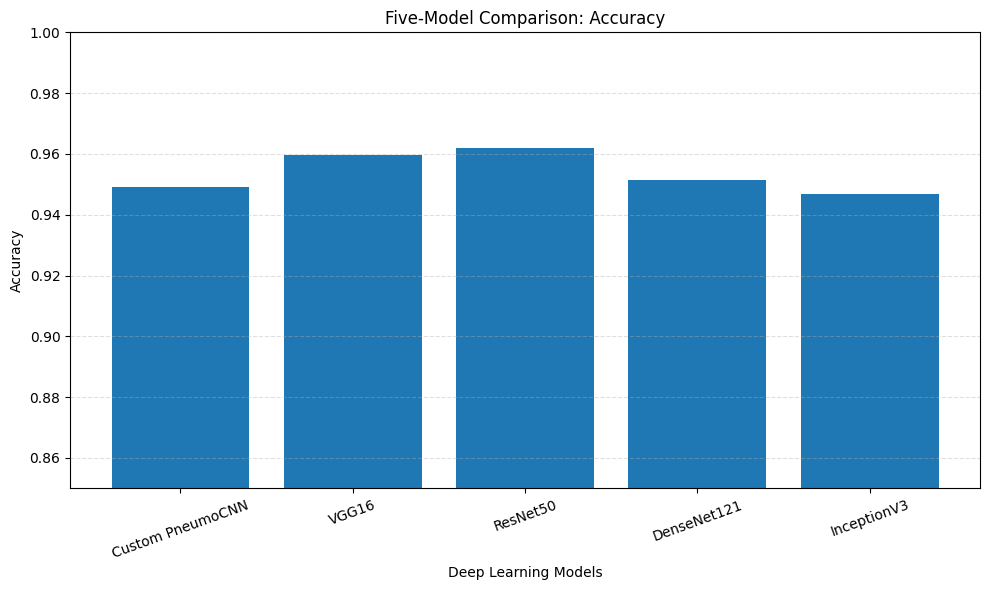

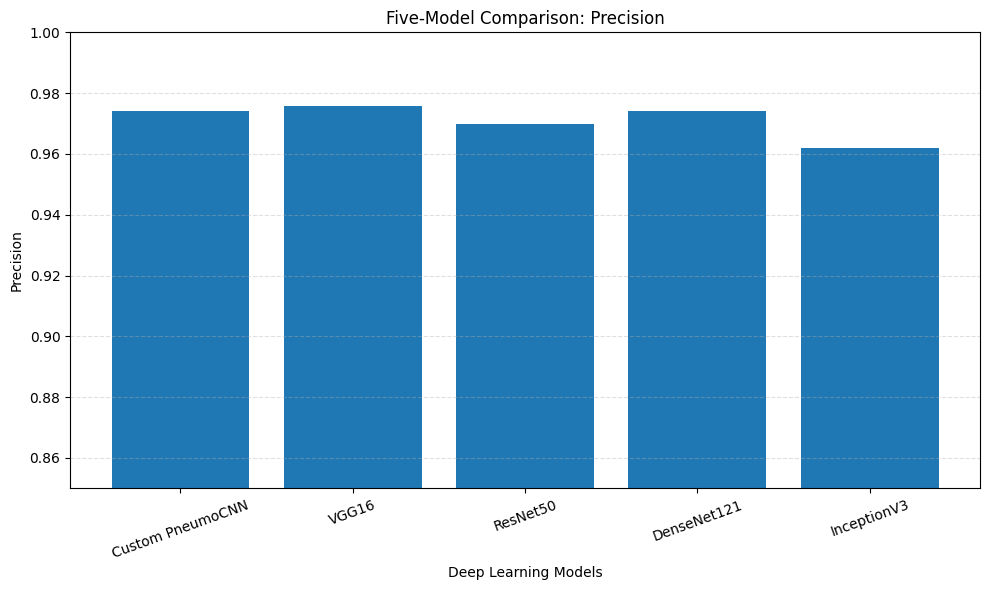

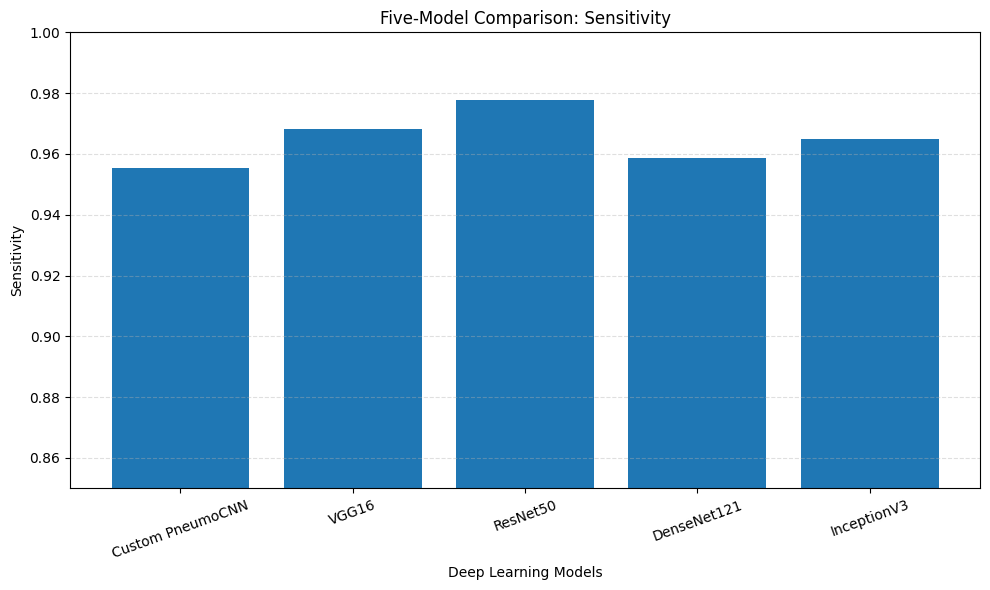

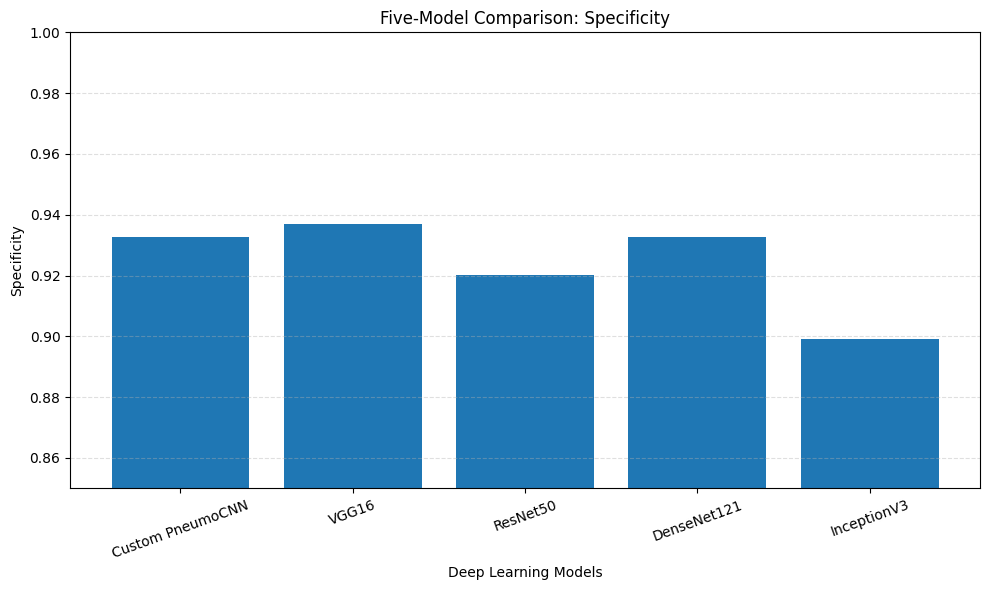

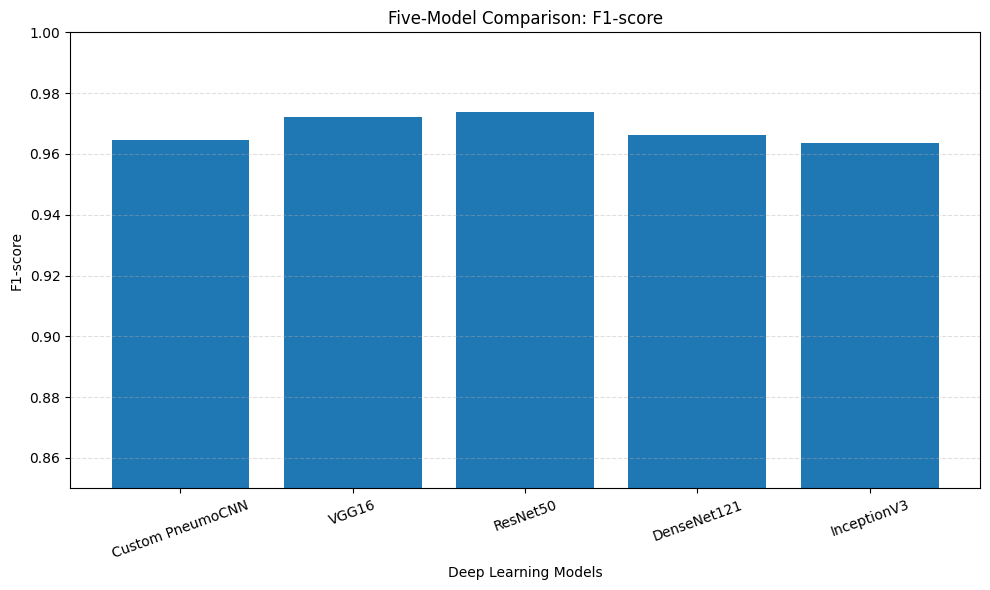

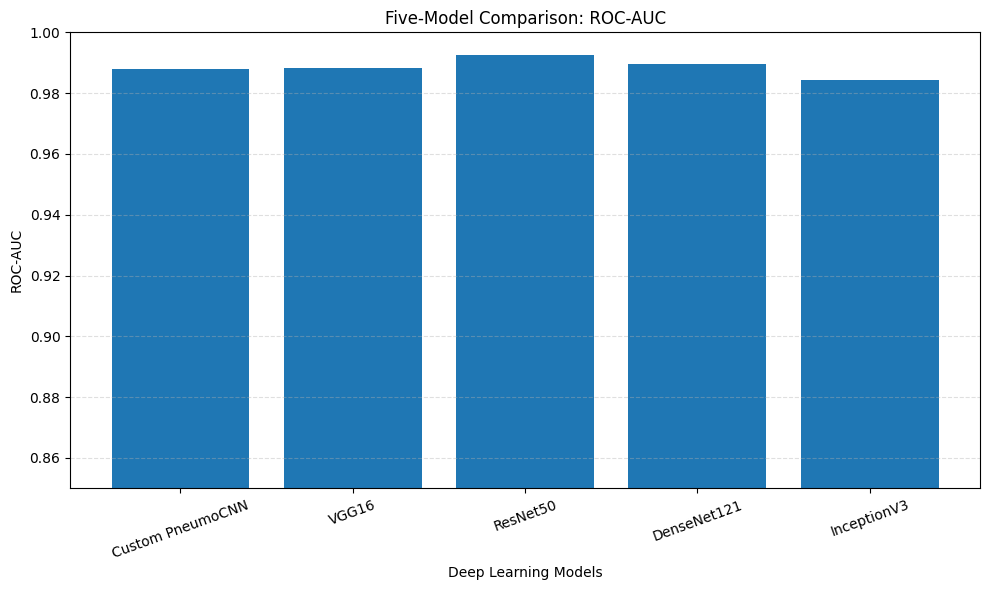

ALL SIX COMPARISON CHARTS GENERATED SUCCESSFULLY
Saved in: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/comparison_charts


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Load master results
ROOT = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

RESULT_DIR = os.path.join(
    ROOT, "corrected_experiments",
    "five_model_comparison"
)

master_path = os.path.join(
    RESULT_DIR,
    "five_model_comparison_master_results.csv"
)

df = pd.read_csv(master_path)

# Metrics to visualize
metrics = {
    "Accuracy": "Accuracy",
    "Precision": "Precision",
    "Sensitivity": "Sensitivity",
    "Specificity": "Specificity",
    "F1_Score": "F1-score",
    "ROC_AUC": "ROC-AUC"
}

# Folder for charts
chart_dir = os.path.join(RESULT_DIR, "comparison_charts")
os.makedirs(chart_dir, exist_ok=True)

# Generate individual charts
for column, title in metrics.items():

    plt.figure(figsize=(10, 6))

    plt.bar(df["Model"], df[column])

    plt.title(f"Five-Model Comparison: {title}")
    plt.xlabel("Deep Learning Models")
    plt.ylabel(title)

    plt.ylim(0.85, 1.00)
    plt.xticks(rotation=20)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()

    filename = f"{column.lower()}_comparison.png"

    plt.savefig(
        os.path.join(chart_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("ALL SIX COMPARISON CHARTS GENERATED SUCCESSFULLY")
print("Saved in:", chart_dir)


In [ ]:
import os
import pandas as pd
import numpy as np

ROOT = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

BASE_DIR = os.path.join(
    ROOT, "corrected_experiments"
)

prediction_files = {
    "Custom PneumoCNN": os.path.join(
        BASE_DIR,
        "augmentation_ablation",
        "predictions",
        "corrected_ablation_predictions.csv"
    ),

    "VGG16": os.path.join(
        BASE_DIR,
        "five_model_comparison",
        "vgg16",
        "vgg16_corrected_test_predictions.csv"
    ),

    "ResNet50": os.path.join(
        BASE_DIR,
        "five_model_comparison",
        "resnet50",
        "resnet50_corrected_test_predictions.csv"
    ),

    "DenseNet121": os.path.join(
        BASE_DIR,
        "five_model_comparison",
        "densenet121",
        "densenet121_corrected_test_predictions.csv"
    ),

    "InceptionV3": os.path.join(
        BASE_DIR,
        "five_model_comparison",
        "inceptionv3",
        "inceptionv3_corrected_test_predictions.csv"
    )
}

prediction_data = {}

print("VERIFYING FIVE-MODEL PREDICTION FILES")
print("=" * 65)

for model, path in prediction_files.items():

    print("\nModel:", model)

    if not os.path.exists(path):
        print("ERROR: File not found:", path)
        continue

    df = pd.read_csv(path)

    prediction_data[model] = df

    print("File found")
    print("Number of images:", len(df))
    print("Columns:", df.columns.tolist())

# Verify that all five files exist
assert len(prediction_data) == 5, (
    "One or more prediction files are missing."
)

print("\n" + "=" * 65)
print("CHECKING TEST LABEL CONSISTENCY")

reference_labels = (
    prediction_data["Custom PneumoCNN"]["actual_label"]
    .to_numpy()
)

for model, df in prediction_data.items():

    labels = df["actual_label"].to_numpy()

    assert len(labels) == 866, (
        f"{model} does not contain 866 images."
    )

    assert np.array_equal(reference_labels, labels), (
        f"Actual labels do not match for {model}."
    )

print("SUCCESS: All five models have matching actual labels.")
print("Total paired test images:", len(reference_labels))

VERIFYING FIVE-MODEL PREDICTION FILES

Model: Custom PneumoCNN
File found
Number of images: 866
Columns: ['actual_label', 'no_augmentation_probability', 'with_augmentation_probability', 'no_augmentation_prediction', 'with_augmentation_prediction']

Model: VGG16
File found
Number of images: 866
Columns: ['actual_label', 'vgg16_probability', 'vgg16_prediction']

Model: ResNet50
File found
Number of images: 866
Columns: ['actual_label', 'resnet50_probability', 'resnet50_prediction']

Model: DenseNet121
File found
Number of images: 866
Columns: ['actual_label', 'densenet121_probability', 'densenet121_prediction']

Model: InceptionV3
File found
Number of images: 866
Columns: ['actual_label', 'inceptionv3_probability', 'inceptionv3_prediction']

CHECKING TEST LABEL CONSISTENCY
SUCCESS: All five models have matching actual labels.
Total paired test images: 866


In [ ]:
import pandas as pd
import numpy as np
import os
from itertools import combinations
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests

# Map prediction columns
prediction_columns = {
    "Custom PneumoCNN": "no_augmentation_prediction",
    "VGG16": "vgg16_prediction",
    "ResNet50": "resnet50_prediction",
    "DenseNet121": "densenet121_prediction",
    "InceptionV3": "inceptionv3_prediction"
}

# Actual labels
y_true = prediction_data["Custom PneumoCNN"]["actual_label"].to_numpy()

# Store correct/incorrect classification for each model
correctness = {}

for model, column in prediction_columns.items():
    predictions = prediction_data[model][column].to_numpy().astype(int)
    correctness[model] = (predictions == y_true)

# Perform pairwise exact McNemar tests
results = []

for model_a, model_b in combinations(prediction_columns.keys(), 2):

    correct_a = correctness[model_a]
    correct_b = correctness[model_b]

    # Paired classification outcomes
    both_correct = int(np.sum(correct_a & correct_b))
    only_a_correct = int(np.sum(correct_a & ~correct_b))
    only_b_correct = int(np.sum(~correct_a & correct_b))
    both_wrong = int(np.sum(~correct_a & ~correct_b))

    discordant = only_a_correct + only_b_correct

    # Exact two-sided McNemar test
    if discordant == 0:
        p_value = 1.0
    else:
        p_value = binomtest(
            only_a_correct,
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue

    results.append({
        "Model_A": model_a,
        "Model_B": model_b,
        "Both_Correct": both_correct,
        "Only_A_Correct": only_a_correct,
        "Only_B_Correct": only_b_correct,
        "Both_Wrong": both_wrong,
        "Discordant_Pairs": discordant,
        "McNemar_P_Value": p_value
    })

# Create results table
mcnemar_df = pd.DataFrame(results)

# Holm multiple-comparison correction
reject, adjusted_p, _, _ = multipletests(
    mcnemar_df["McNemar_P_Value"],
    alpha=0.05,
    method="holm"
)

mcnemar_df["Holm_Adjusted_P_Value"] = adjusted_p
mcnemar_df["Significant_After_Holm"] = reject

# Save results
RESULT_DIR = os.path.join(
    ROOT, "corrected_experiments",
    "five_model_comparison"
)

output_path = os.path.join(
    RESULT_DIR,
    "five_model_mcnemar_results.csv"
)

mcnemar_df.to_csv(output_path, index=False)

print("PAIRWISE McNEMAR TEST RESULTS")
print("=" * 75)

display(mcnemar_df.round(6))

print("\nNumber of model comparisons:", len(mcnemar_df))
print("Significant comparisons after Holm correction:",
      int(reject.sum()))

print("\nSaved to:")
print(output_path)

PAIRWISE McNEMAR TEST RESULTS


,Model_A,Model_B,Both_Correct,Only_A_Correct,Only_B_Correct,Both_Wrong,Discordant_Pairs,McNemar_P_Value,Holm_Adjusted_P_Value,Significant_After_Holm
0,Custom PneumoCNN,VGG16,807,15,24,20,39,0.199591,1.000000,False
1,Custom PneumoCNN,ResNet50,809,13,24,20,37,0.098872,0.889846,False
2,Custom PneumoCNN,DenseNet121,805,17,19,25,36,0.867939,1.000000,False
3,Custom PneumoCNN,InceptionV3,796,26,24,20,50,0.887725,1.000000,False
4,VGG16,ResNet50,817,14,16,19,30,0.855536,1.000000,False
5,VGG16,DenseNet121,811,20,13,22,33,0.296206,1.000000,False
6,VGG16,InceptionV3,803,28,17,18,45,0.135156,1.000000,False
7,ResNet50,DenseNet121,813,20,11,22,31,0.149613,1.000000,False
8,ResNet50,InceptionV3,808,25,12,21,37,0.047031,0.470310,False
9,DenseNet121,InceptionV3,802,22,18,24,40,0.635828,1.000000,False



Number of model comparisons: 10
Significant comparisons after Holm correction: 0

Saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/five_model_mcnemar_results.csv


In [ ]:
import numpy as np
import pandas as pd
import os

from scipy.stats import norm
from sklearn.metrics import roc_auc_score
from itertools import combinations
from statsmodels.stats.multitest import multipletests


# --------------------------------------------------
# 1. DeLong helper functions
# --------------------------------------------------

def compute_midrank(x):
    order = np.argsort(x)
    sorted_x = x[order]
    n = len(x)

    ranks = np.zeros(n, dtype=float)

    i = 0
    while i < n:
        j = i
        while j < n and sorted_x[j] == sorted_x[i]:
            j += 1

        ranks[i:j] = 0.5 * (i + j - 1) + 1
        i = j

    result = np.empty(n, dtype=float)
    result[order] = ranks

    return result


def delong_auc_variance(y_true, probabilities):

    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities).astype(float)

    positive = probabilities[y_true == 1]
    negative = probabilities[y_true == 0]

    m = len(positive)
    n = len(negative)

    if m < 2 or n < 2:
        raise ValueError("Both classes need at least two observations.")

    positive_ranks = compute_midrank(positive)
    negative_ranks = compute_midrank(negative)

    combined_ranks = compute_midrank(
        np.concatenate([positive, negative])
    )

    auc = (
        np.sum(combined_ranks[:m]) / (m * n)
        - (m + 1) / (2 * n)
    )

    v01 = (combined_ranks[:m] - positive_ranks) / n
    v10 = 1 - (
        combined_ranks[m:] - negative_ranks
    ) / m

    variance = (
        np.var(v01, ddof=1) / m
        + np.var(v10, ddof=1) / n
    )

    return auc, variance


def paired_delong_test(y_true, scores_a, scores_b):

    y_true = np.asarray(y_true).astype(int)

    auc_a, var_a = delong_auc_variance(
        y_true, scores_a
    )

    auc_b, var_b = delong_auc_variance(
        y_true, scores_b
    )

    # Paired covariance between the two AUC estimates
    positive = y_true == 1
    negative = y_true == 0

    def auc_components(scores):

        pos = scores[positive]
        neg = scores[negative]

        m = len(pos)
        n = len(neg)

        pos_rank = compute_midrank(pos)
        neg_rank = compute_midrank(neg)

        combined_rank = compute_midrank(
            np.concatenate([pos, neg])
        )

        v01 = (combined_rank[:m] - pos_rank) / n
        v10 = 1 - (
            combined_rank[m:] - neg_rank
        ) / m

        return v01, v10

    a01, a10 = auc_components(scores_a)
    b01, b10 = auc_components(scores_b)

    covariance = (
        np.cov(a01, b01, ddof=1)[0, 1] / len(a01)
        + np.cov(a10, b10, ddof=1)[0, 1] / len(a10)
    )

    difference = auc_a - auc_b

    variance_difference = (
        var_a + var_b - 2 * covariance
    )

    if variance_difference <= 0:
        raise ValueError(
            "Non-positive variance difference encountered."
        )

    z_statistic = difference / np.sqrt(variance_difference)

    p_value = 2 * norm.sf(abs(z_statistic))

    return auc_a, auc_b, difference, z_statistic, p_value


# --------------------------------------------------
# 2. Define probability columns
# --------------------------------------------------

probability_columns = {
    "Custom PneumoCNN": "no_augmentation_probability",
    "VGG16": "vgg16_probability",
    "ResNet50": "resnet50_probability",
    "DenseNet121": "densenet121_probability",
    "InceptionV3": "inceptionv3_probability"
}

y_true = prediction_data[
    "Custom PneumoCNN"
]["actual_label"].to_numpy()


# --------------------------------------------------
# 3. Run all 10 pairwise DeLong tests
# --------------------------------------------------

delong_results = []

for model_a, model_b in combinations(
    probability_columns.keys(), 2
):

    scores_a = prediction_data[model_a][
        probability_columns[model_a]
    ].to_numpy()

    scores_b = prediction_data[model_b][
        probability_columns[model_b]
    ].to_numpy()

    auc_a, auc_b, difference, z, p = paired_delong_test(
        y_true, scores_a, scores_b
    )

    delong_results.append({
        "Model_A": model_a,
        "Model_B": model_b,
        "AUC_A": auc_a,
        "AUC_B": auc_b,
        "AUC_Difference_A_minus_B": difference,
        "Z_Statistic": z,
        "P_Value": p
    })


# --------------------------------------------------
# 4. Holm correction
# --------------------------------------------------

delong_df = pd.DataFrame(delong_results)

reject, adjusted_p, _, _ = multipletests(
    delong_df["P_Value"],
    alpha=0.05,
    method="holm"
)

delong_df["Holm_Adjusted_P_Value"] = adjusted_p

delong_df["Significant_After_Holm"] = reject


# --------------------------------------------------
# 5. Save results
# --------------------------------------------------

RESULT_DIR = os.path.join(
    ROOT,
    "corrected_experiments",
    "five_model_comparison"
)

output_path = os.path.join(
    RESULT_DIR,
    "five_model_delong_results.csv"
)

delong_df.to_csv(output_path, index=False)


# --------------------------------------------------
# 6. Display results
# --------------------------------------------------

print("PAIRWISE DELONG TEST RESULTS")
print("=" * 75)

display(delong_df.round(6))

print("\nTotal comparisons:", len(delong_df))

print(
    "Significant comparisons after Holm correction:",
    int(reject.sum())
)

print("\nSaved to:")
print(output_path)

PAIRWISE DELONG TEST RESULTS


,Model_A,Model_B,AUC_A,AUC_B,AUC_Difference_A_minus_B,Z_Statistic,P_Value,Holm_Adjusted_P_Value,Significant_After_Holm
0,Custom PneumoCNN,VGG16,0.987990,0.988305,-0.000314,-0.087537,0.930244,1.000000,False
1,Custom PneumoCNN,ResNet50,0.987990,0.992480,-0.004489,-1.774154,0.076038,0.608301,False
2,Custom PneumoCNN,DenseNet121,0.987990,0.989529,-0.001539,-0.717831,0.472861,1.000000,False
3,Custom PneumoCNN,InceptionV3,0.987990,0.984311,0.003680,1.277804,0.201318,1.000000,False
4,VGG16,ResNet50,0.988305,0.992480,-0.004175,-1.120726,0.262405,1.000000,False
5,VGG16,DenseNet121,0.988305,0.989529,-0.001224,-0.402092,0.687616,1.000000,False
6,VGG16,InceptionV3,0.988305,0.984311,0.003994,1.007132,0.313872,1.000000,False
7,ResNet50,DenseNet121,0.992480,0.989529,0.002951,1.281924,0.199869,1.000000,False
8,ResNet50,InceptionV3,0.992480,0.984311,0.008169,2.901001,0.003720,0.037197,True
9,DenseNet121,InceptionV3,0.989529,0.984311,0.005219,2.237118,0.025279,0.227507,False



Total comparisons: 10
Significant comparisons after Holm correction: 1

Saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/five_model_delong_results.csv


In [ ]:
import numpy as np
import pandas as pd
import os

from sklearn.metrics import roc_auc_score, matthews_corrcoef

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

N_BOOTSTRAPS = 10000
RANDOM_SEED = 42
THRESHOLD = 0.50

rng = np.random.default_rng(RANDOM_SEED)

models_list = list(probability_columns.keys())

y_true = prediction_data[
    "Custom PneumoCNN"
]["actual_label"].to_numpy().astype(int)

# Separate class indices for stratified resampling
normal_indices = np.where(y_true == 0)[0]
pneumonia_indices = np.where(y_true == 1)[0]

# Collect model probabilities and predictions
probabilities = {}
predictions = {}

for model in models_list:

    prob_col = probability_columns[model]

    probabilities[model] = prediction_data[
        model
    ][prob_col].to_numpy()

    predictions[model] = (
        probabilities[model] >= THRESHOLD
    ).astype(int)


# --------------------------------------------------
# 2. Metric calculation function
# --------------------------------------------------

def calculate_metrics(actual, predicted, scores):

    tn = np.sum((actual == 0) & (predicted == 0))
    fp = np.sum((actual == 0) & (predicted == 1))
    fn = np.sum((actual == 1) & (predicted == 0))
    tp = np.sum((actual == 1) & (predicted == 1))

    accuracy = (tp + tn) / len(actual)

    precision = tp / (tp + fp) if (tp + fp) else 0

    sensitivity = tp / (tp + fn) if (tp + fn) else 0

    specificity = tn / (tn + fp) if (tn + fp) else 0

    f1 = (
        2 * precision * sensitivity / (precision + sensitivity)
        if (precision + sensitivity) else 0
    )

    auc = roc_auc_score(actual, scores)

    mcc = matthews_corrcoef(actual, predicted)

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1_Score": f1,
        "ROC_AUC": auc,
        "MCC": mcc
    }


# --------------------------------------------------
# 3. Calculate original test-set metrics
# --------------------------------------------------

point_estimates = {}

for model in models_list:

    point_estimates[model] = calculate_metrics(
        y_true,
        predictions[model],
        probabilities[model]
    )


# --------------------------------------------------
# 4. Paired stratified bootstrap
# --------------------------------------------------

bootstrap_values = {
    model: {
        metric: []
        for metric in point_estimates[model]
    }
    for model in models_list
}

for iteration in range(N_BOOTSTRAPS):

    # Preserve original class counts
    sampled_normal = rng.choice(
        normal_indices,
        size=len(normal_indices),
        replace=True
    )

    sampled_pneumonia = rng.choice(
        pneumonia_indices,
        size=len(pneumonia_indices),
        replace=True
    )

    # Same sampled images for all five models
    sample_indices = np.concatenate([
        sampled_normal,
        sampled_pneumonia
    ])

    actual_sample = y_true[sample_indices]

    for model in models_list:

        predicted_sample = predictions[model][sample_indices]

        probability_sample = probabilities[model][sample_indices]

        metrics = calculate_metrics(
            actual_sample,
            predicted_sample,
            probability_sample
        )

        for metric, value in metrics.items():

            bootstrap_values[model][metric].append(value)


# --------------------------------------------------
# 5. Calculate 95% confidence intervals
# --------------------------------------------------

bootstrap_results = []

for model in models_list:

    for metric in point_estimates[model]:

        values = np.asarray(
            bootstrap_values[model][metric]
        )

        lower = np.percentile(values, 2.5)
        upper = np.percentile(values, 97.5)

        bootstrap_results.append({
            "Model": model,
            "Metric": metric,
            "Original_Score": point_estimates[model][metric],
            "95%_CI_Lower": lower,
            "95%_CI_Upper": upper
        })


bootstrap_df = pd.DataFrame(bootstrap_results)


# --------------------------------------------------
# 6. Save results
# --------------------------------------------------

RESULT_DIR = os.path.join(
    ROOT,
    "corrected_experiments",
    "five_model_comparison"
)

output_path = os.path.join(
    RESULT_DIR,
    "five_model_bootstrap_confidence_intervals.csv"
)

bootstrap_df.to_csv(output_path, index=False)


# --------------------------------------------------
# 7. Display results
# --------------------------------------------------

print("PAIRED BOOTSTRAP CONFIDENCE INTERVAL RESULTS")
print("=" * 75)

display(bootstrap_df.round(4))

print("\nBootstrap iterations:", N_BOOTSTRAPS)
print("Confidence level: 95%")
print("Random seed:", RANDOM_SEED)
print("Resampling method: Stratified paired image-level bootstrap")

print("\nSaved to:")
print(output_path)

PAIRED BOOTSTRAP CONFIDENCE INTERVAL RESULTS


,Model,Metric,Original_Score,95%_CI_Lower,95%_CI_Upper
0,Custom PneumoCNN,Accuracy,0.9492,0.9342,0.9630
1,Custom PneumoCNN,Precision,0.9740,0.9615,0.9853
2,Custom PneumoCNN,Sensitivity,0.9554,0.9379,0.9713
3,Custom PneumoCNN,Specificity,0.9328,0.8992,0.9622
4,Custom PneumoCNN,F1_Score,0.9646,0.9539,0.9744
5,Custom PneumoCNN,ROC_AUC,0.9880,0.9810,0.9936
6,Custom PneumoCNN,MCC,0.8750,0.8387,0.9093
7,VGG16,Accuracy,0.9596,0.9457,0.9723
8,VGG16,Precision,0.9759,0.9637,0.9870
9,VGG16,Sensitivity,0.9682,0.9538,0.9809



Bootstrap iterations: 10000
Confidence level: 95%
Random seed: 42
Resampling method: Stratified paired image-level bootstrap

Saved to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/five_model_bootstrap_confidence_intervals.csv


In [ ]:

import numpy as np
import pandas as pd
from itertools import combinations
from sklearn.metrics import roc_auc_score
from pathlib import Path

# --------------------------------------------------
# 1. SETTINGS
# --------------------------------------------------
N_BOOTSTRAPS = 10000
RANDOM_SEED = 42

MODEL_NAMES = [
    "Custom PneumoCNN",
    "VGG16",
    "ResNet50",
    "DenseNet121",
    "InceptionV3"
]

# Match model names to the prediction dataframes
def find_dataframe(model_name):
    for key, df in prediction_data.items():
        k = str(key).lower()
        m = model_name.lower()

        if model_name == "Custom PneumoCNN":
            if "pneumocnn" in k or "custom" in k:
                return df
        elif m in k:
            return df

    raise KeyError(
        f"Could not find prediction dataframe for {model_name}. "
        f"Available keys: {list(prediction_data.keys())}"
    )

# Probability and prediction columns
PROB_COLS = {
    "Custom PneumoCNN": "no_augmentation_probability",
    "VGG16": "vgg16_probability",
    "ResNet50": "resnet50_probability",
    "DenseNet121": "densenet121_probability",
    "InceptionV3": "inceptionv3_probability"
}

PRED_COLS = {
    "Custom PneumoCNN": "no_augmentation_prediction",
    "VGG16": "vgg16_prediction",
    "ResNet50": "resnet50_prediction",
    "DenseNet121": "densenet121_prediction",
    "InceptionV3": "inceptionv3_prediction"
}

# --------------------------------------------------
# 2. PREPARE AND VERIFY DATA
# --------------------------------------------------
dfs = {m: find_dataframe(m) for m in MODEL_NAMES}

y_true = dfs[MODEL_NAMES[0]]["actual_label"].to_numpy().astype(int)

for model in MODEL_NAMES:
    df = dfs[model]

    if len(df) != len(y_true):
        raise ValueError(f"Different number of test rows for {model}.")

    if not np.array_equal(
        df["actual_label"].to_numpy().astype(int), y_true
    ):
        raise ValueError(f"Actual labels/order do not match for {model}.")

    if PROB_COLS[model] not in df.columns:
        raise KeyError(f"Missing probability column for {model}.")

    if PRED_COLS[model] not in df.columns:
        raise KeyError(f"Missing prediction column for {model}.")

probabilities = {
    m: dfs[m][PROB_COLS[m]].to_numpy(dtype=float)
    for m in MODEL_NAMES
}

predictions = {
    m: dfs[m][PRED_COLS[m]].to_numpy(dtype=int)
    for m in MODEL_NAMES
}

positive_indices = np.where(y_true == 1)[0]
negative_indices = np.where(y_true == 0)[0]

print("Data verification successful.")
print("Total test images:", len(y_true))
print("NORMAL:", len(negative_indices))
print("PNEUMONIA:", len(positive_indices))

# --------------------------------------------------
# 3. METRIC CALCULATION
# --------------------------------------------------
def calculate_metrics(y, pred, prob):
    tp = np.sum((y == 1) & (pred == 1))
    tn = np.sum((y == 0) & (pred == 0))
    fp = np.sum((y == 0) & (pred == 1))
    fn = np.sum((y == 1) & (pred == 0))

    accuracy = (tp + tn) / len(y)
    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    f1 = (
        2 * precision * sensitivity / (precision + sensitivity)
        if (precision + sensitivity) else 0
    )
    auc = roc_auc_score(y, prob)

    return {
        "Accuracy": accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1_Score": f1,
        "ROC_AUC": auc
    }

# --------------------------------------------------
# 4. OBSERVED METRICS
# --------------------------------------------------
observed = {
    m: calculate_metrics(
        y_true, predictions[m], probabilities[m]
    )
    for m in MODEL_NAMES
}

# --------------------------------------------------
# 5. PAIRED STRATIFIED BOOTSTRAP
# --------------------------------------------------
rng = np.random.default_rng(RANDOM_SEED)

metric_names = [
    "Accuracy",
    "Sensitivity",
    "Specificity",
    "F1_Score",
    "ROC_AUC"
]

model_pairs = list(combinations(MODEL_NAMES, 2))

bootstrap_differences = {
    (a, b, metric): np.empty(N_BOOTSTRAPS)
    for a, b in model_pairs
    for metric in metric_names
}

for i in range(N_BOOTSTRAPS):

    # Preserve the original number of NORMAL and PNEUMONIA images
    sampled_negative = rng.choice(
        negative_indices,
        size=len(negative_indices),
        replace=True
    )

    sampled_positive = rng.choice(
        positive_indices,
        size=len(positive_indices),
        replace=True
    )

    sampled_indices = np.concatenate([
        sampled_negative,
        sampled_positive
    ])

    y_sample = y_true[sampled_indices]

    sampled_metrics = {}

    for model in MODEL_NAMES:
        sampled_metrics[model] = calculate_metrics(
            y_sample,
            predictions[model][sampled_indices],
            probabilities[model][sampled_indices]
        )

    # Store paired differences: Model A minus Model B
    for a, b in model_pairs:
        for metric in metric_names:
            bootstrap_differences[(a, b, metric)][i] = (
                sampled_metrics[a][metric]
                - sampled_metrics[b][metric]
            )

    if (i + 1) % 1000 == 0:
        print(f"Completed {i + 1:,}/{N_BOOTSTRAPS:,} samples")

# --------------------------------------------------
# 6. CALCULATE 95% CONFIDENCE INTERVALS
# --------------------------------------------------
results = []

for a, b in model_pairs:
    for metric in metric_names:

        differences = bootstrap_differences[(a, b, metric)]

        observed_difference = (
            observed[a][metric] - observed[b][metric]
        )

        lower = np.percentile(differences, 2.5)
        upper = np.percentile(differences, 97.5)

        results.append({
            "Model_A": a,
            "Model_B": b,
            "Metric": metric,
            "Difference_A_minus_B": observed_difference,
            "CI_95_Lower": lower,
            "CI_95_Upper": upper,
            "CI_Excludes_Zero": (
                lower > 0 or upper < 0
            )
        })

results_df = pd.DataFrame(results)

# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------
output_dir = Path(
    "/content/drive/MyDrive/"
    "MPhil_Pneumonia_Detection_Research/"
    "corrected_experiments/five_model_comparison"
)

output_dir.mkdir(parents=True, exist_ok=True)

output_file = (
    output_dir /
    "five_model_paired_bootstrap_difference_CIs.csv"
)

results_df.to_csv(output_file, index=False)

# --------------------------------------------------
# 8. DISPLAY RESULTS
# --------------------------------------------------
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", None)

print("\nPAIRED BOOTSTRAP COMPARISON RESULTS")
print("95% percentile confidence intervals")
print("Positive difference means Model A performed better.")

display(
    results_df.round(5)
)

print("\nSaved successfully to:")
print(output_file)


Data verification successful.
Total test images: 866
NORMAL: 238
PNEUMONIA: 628
Completed 1,000/10,000 samples
Completed 2,000/10,000 samples
Completed 3,000/10,000 samples
Completed 4,000/10,000 samples
Completed 5,000/10,000 samples
Completed 6,000/10,000 samples
Completed 7,000/10,000 samples
Completed 8,000/10,000 samples
Completed 9,000/10,000 samples
Completed 10,000/10,000 samples

PAIRED BOOTSTRAP COMPARISON RESULTS
95% percentile confidence intervals
Positive difference means Model A performed better.


,Model_A,Model_B,Metric,Difference_A_minus_B,CI_95_Lower,CI_95_Upper,CI_Excludes_Zero
0,Custom PneumoCNN,VGG16,Accuracy,-0.01039,-0.02425,0.00346,False
1,Custom PneumoCNN,VGG16,Sensitivity,-0.01274,-0.02866,0.00318,False
2,Custom PneumoCNN,VGG16,Specificity,-0.00420,-0.02941,0.02101,False
3,Custom PneumoCNN,VGG16,F1_Score,-0.00739,-0.01734,0.00243,False
4,Custom PneumoCNN,VGG16,ROC_AUC,-0.00031,-0.00661,0.00749,False
5,Custom PneumoCNN,ResNet50,Accuracy,-0.01270,-0.02656,0.00115,False
6,Custom PneumoCNN,ResNet50,Sensitivity,-0.02229,-0.03981,-0.00637,True
7,Custom PneumoCNN,ResNet50,Specificity,0.01261,-0.00840,0.03782,False
8,Custom PneumoCNN,ResNet50,F1_Score,-0.00920,-0.01911,0.00003,False
9,Custom PneumoCNN,ResNet50,ROC_AUC,-0.00449,-0.00987,0.00006,False



Saved successfully to:
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/five_model_paired_bootstrap_difference_CIs.csv


In [ ]:

import os
import matplotlib.pyplot as plt
import pandas as pd

# Create folders for saving results
output_dir = "/content/Learning_Curve_Analysis"
os.makedirs(output_dir, exist_ok=True)

# Add your model training histories here.
# Replace the example variable names with the actual
# History objects returned by model.fit().

model_histories = {
    "Custom CNN": custom_cnn_history,
    "VGG16": vgg16_history,
    "ResNet50": resnet50_history,
    "DenseNet121": densenet121_history,
    "InceptionV3": inceptionv3_history
}

for model_name, history in model_histories.items():

    if history is None:
        print(f"Skipping {model_name}: history not found")
        continue

    hist = history.history

    # Identify accuracy and loss keys
    accuracy_key = "accuracy" if "accuracy" in hist else "binary_accuracy"
    val_accuracy_key = "val_accuracy" if "val_accuracy" in hist else "val_binary_accuracy"

    if accuracy_key not in hist or val_accuracy_key not in hist:
        print(f"Accuracy data missing for {model_name}")
        continue

    # Save history as CSV
    df = pd.DataFrame(hist)
    safe_name = model_name.replace(" ", "_").lower()
    df.to_csv(
        os.path.join(output_dir, f"{safe_name}_history.csv"),
        index=False
    )

    # Create two learning curves
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    epochs = range(1, len(hist[accuracy_key]) + 1)

    # Accuracy graph
    axes[0].plot(epochs, hist[accuracy_key], label="Training Accuracy")
    axes[0].plot(epochs, hist[val_accuracy_key], label="Validation Accuracy")
    axes[0].set_title(f"{model_name} - Accuracy")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True)

    # Loss graph
    if "loss" in hist and "val_loss" in hist:
        axes[1].plot(epochs, hist["loss"], label="Training Loss")
        axes[1].plot(epochs, hist["val_loss"], label="Validation Loss")
        axes[1].set_title(f"{model_name} - Loss")
        axes[1].set_xlabel("Epochs")
        axes[1].set_ylabel("Loss")
        axes[1].legend()
        axes[1].grid(True)

    plt.tight_layout()

    # Save graph
    plt.savefig(
        os.path.join(output_dir, f"{safe_name}_learning_curves.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("Learning curve analysis completed.")
print("Files saved in:", output_dir)


NameError: name 'custom_cnn_history' is not defined

In [ ]:

history_variables = [
    name for name in globals()
    if "history" in name.lower()
]

print("Available training history variables:")
for name in history_variables:
    print(name)


Available training history variables:


In [ ]:

print("Checking available variables...\n")

for name, value in globals().items():
    if "history" in name.lower():
        print(name, "->", type(value))


Checking available variables...



RuntimeError: dictionary changed size during iteration

In [ ]:

print("Checking available training histories...\n")

history_variables = list(globals().items())

for name, value in history_variables:
    if "history" in name.lower():
        print(f"{name} -> {type(value)}")


Checking available training histories...

history_variables -> <class 'list'>


In [ ]:

import os

search_locations = ["/content", "/content/drive/MyDrive"]

for location in search_locations:
    if os.path.exists(location):
        print(f"\nSearching: {location}")

        for root, dirs, files in os.walk(location):
            dirs[:] = [d for d in dirs if d not in [
                ".config", "node_modules", ".git"
            ]]

            for file in files:
                if "history" in file.lower() and file.endswith(".csv"):
                    print(os.path.join(root, file))



Searching: /content


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

drive_path = "/content/drive/MyDrive"

extensions = (".csv", ".json", ".pkl", ".pickle")

print("Searching Google Drive for training history files...\n")

for root, dirs, files in os.walk(drive_path):
    dirs[:] = [d for d in dirs if d not in [
        ".Trash", ".ipynb_checkpoints", "node_modules"
    ]]

    for file in files:
        if "history" in file.lower() or "training" in file.lower():
            if file.lower().endswith(extensions):
                print(os.path.join(root, file))


Searching Google Drive for training history files...

/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/training_histories/pneumocnn_training_history.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/training_histories/resnet50_training_history.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/training_histories/densenet121_training_history.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/training_histories/inceptionv3_training_history.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/training_histories/pneumocnn_no_augmentation_history.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/augmentation_ablation/training_histories/pneumocnn_with_augmentation_history.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/training_histories/corrected_pneumocnn_no_augmentation_history.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/correcte


Processing Custom CNN...
Available columns: ['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']


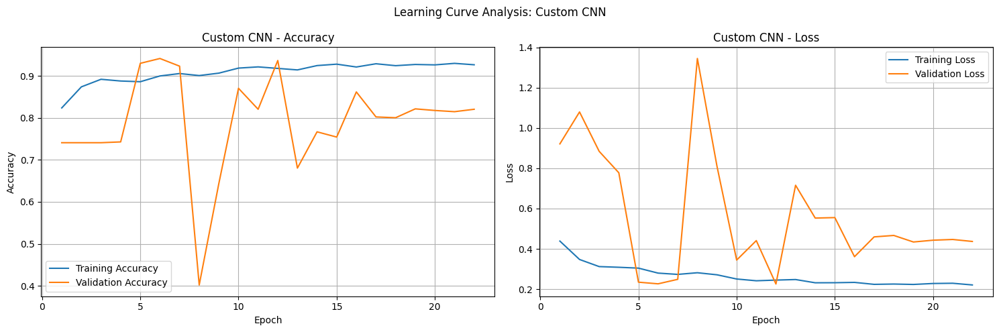

Saved: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Learning_Curve_Analysis/custom_cnn_learning_curve.png

Processing VGG16...
Available columns: ['epoch', 'accuracy', 'learning_rate', 'loss', 'val_accuracy', 'val_loss']


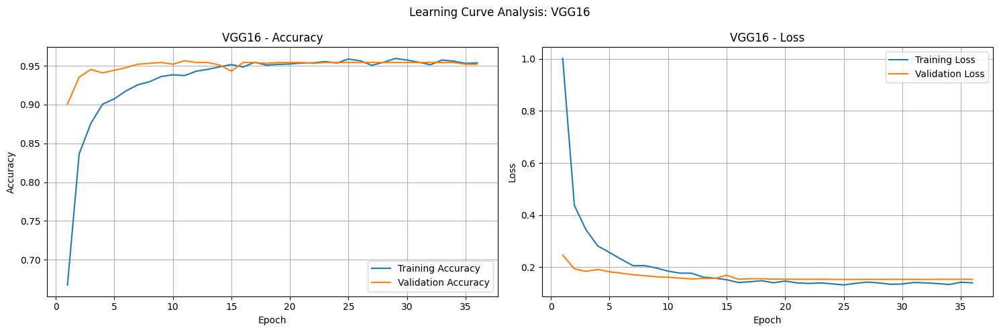

Saved: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Learning_Curve_Analysis/vgg16_learning_curve.png

Processing ResNet50...
Available columns: ['epoch', 'accuracy', 'learning_rate', 'loss', 'val_accuracy', 'val_loss']


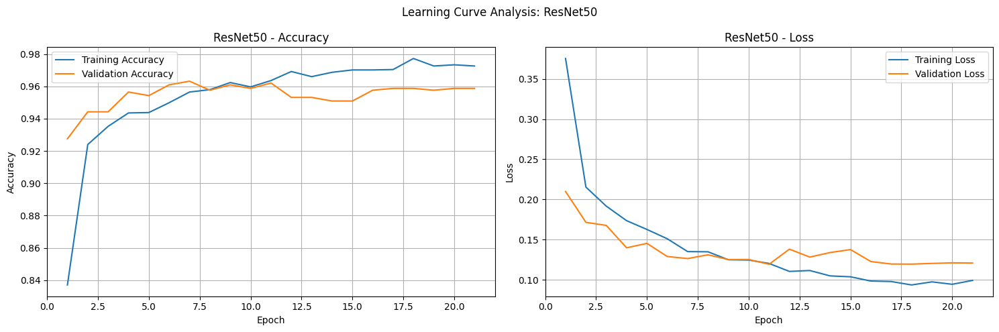

Saved: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Learning_Curve_Analysis/resnet50_learning_curve.png

Processing DenseNet121...
Available columns: ['epoch', 'accuracy', 'learning_rate', 'loss', 'val_accuracy', 'val_loss']


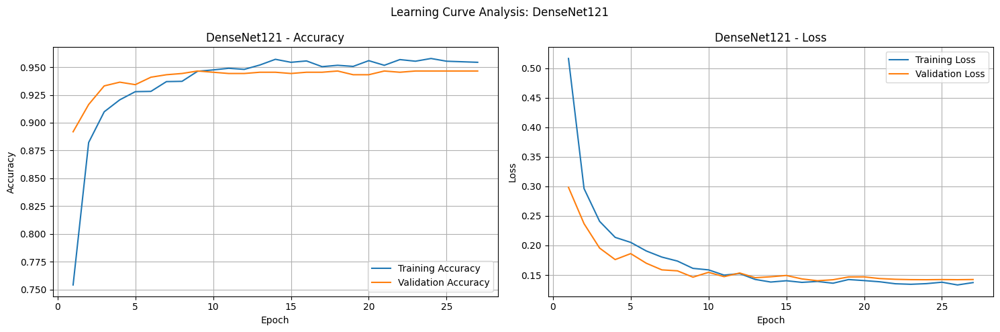

Saved: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Learning_Curve_Analysis/densenet121_learning_curve.png

Processing InceptionV3...
Available columns: ['epoch', 'accuracy', 'learning_rate', 'loss', 'val_accuracy', 'val_loss']


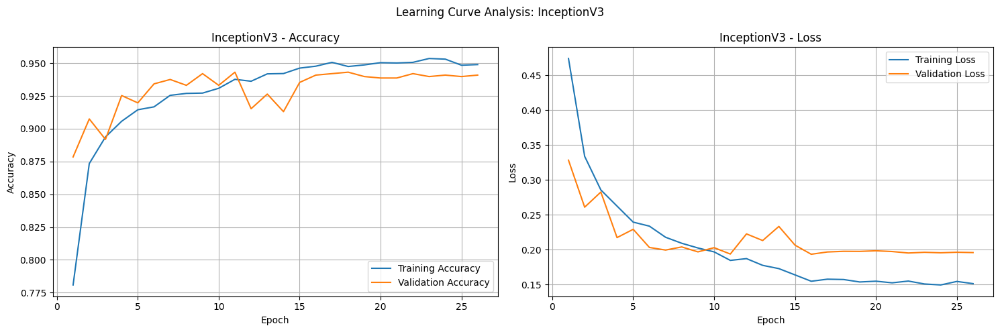

Saved: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Learning_Curve_Analysis/inceptionv3_learning_curve.png

Learning curve generation completed.
Results folder: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Learning_Curve_Analysis


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Main project directory
base = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

# Training history files
history_files = {
    "Custom CNN": os.path.join(
        base, "training_histories/pneumocnn_training_history.csv"
    ),
    "VGG16": os.path.join(
        base, "corrected_experiments/five_model_comparison/"
        "vgg16/histories/vgg16_corrected_training_history.csv"
    ),
    "ResNet50": os.path.join(
        base, "corrected_experiments/five_model_comparison/"
        "resnet50/histories/resnet50_corrected_training_history.csv"
    ),
    "DenseNet121": os.path.join(
        base, "corrected_experiments/five_model_comparison/"
        "densenet121/histories/densenet121_corrected_training_history.csv"
    ),
    "InceptionV3": os.path.join(
        base, "corrected_experiments/five_model_comparison/"
        "inceptionv3/histories/inceptionv3_corrected_training_history.csv"
    )
}

# Output directory
output_dir = os.path.join(base, "Learning_Curve_Analysis")
os.makedirs(output_dir, exist_ok=True)

for model_name, file_path in history_files.items():

    print(f"\nProcessing {model_name}...")

    if not os.path.exists(file_path):
        print("File not found:", file_path)
        continue

    df = pd.read_csv(file_path)

    print("Available columns:", list(df.columns))

    # Find accuracy and loss columns
    columns = {col.lower(): col for col in df.columns}

    acc = columns.get("accuracy") or columns.get("binary_accuracy")
    val_acc = columns.get("val_accuracy") or columns.get("val_binary_accuracy")
    loss = columns.get("loss")
    val_loss = columns.get("val_loss")

    if not all([acc, val_acc, loss, val_loss]):
        print("Required columns missing. Please inspect this CSV.")
        continue

    epochs = range(1, len(df) + 1)

    # Create learning curves
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Accuracy
    axes[0].plot(epochs, df[acc], label="Training Accuracy")
    axes[0].plot(epochs, df[val_acc], label="Validation Accuracy")
    axes[0].set_title(f"{model_name} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True)

    # Loss
    axes[1].plot(epochs, df[loss], label="Training Loss")
    axes[1].plot(epochs, df[val_loss], label="Validation Loss")
    axes[1].set_title(f"{model_name} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.suptitle(f"Learning Curve Analysis: {model_name}")
    plt.tight_layout()

    safe_name = model_name.replace(" ", "_").lower()

    # Save high-resolution graph
    graph_path = os.path.join(
        output_dir, f"{safe_name}_learning_curve.png"
    )

    plt.savefig(graph_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", graph_path)

    # Copy the source history into the output folder
    df.to_csv(
        os.path.join(output_dir, f"{safe_name}_history.csv"),
        index=False
    )

print("\nLearning curve generation completed.")
print("Results folder:", output_dir)


In [ ]:

import shutil
from google.colab import files

zip_path = "/content/Learning_Curve_Analysis.zip"

shutil.make_archive(
    "/content/Learning_Curve_Analysis",
    "zip",
    output_dir
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import os

base = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

files = {
    "Original Custom CNN": f"{base}/training_histories/pneumocnn_training_history.csv",

    "No Augmentation": f"{base}/augmentation_ablation/training_histories/pneumocnn_no_augmentation_history.csv",

    "Corrected No Augmentation": f"{base}/corrected_experiments/augmentation_ablation/training_histories/corrected_pneumocnn_no_augmentation_history.csv"
}

for name, path in files.items():
    print("\n", "=" * 50)
    print(name)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Epochs:", len(df))
        print("Columns:", list(df.columns))

        if "val_loss" in df.columns:
            print("Best validation loss epoch:", df["val_loss"].idxmin() + 1)
            print("Best validation loss:", df["val_loss"].min())
    else:
        print("File not found")



Original Custom CNN
Epochs: 22
Columns: ['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']
Best validation loss epoch: 12
Best validation loss: 0.225545659661293

No Augmentation
Epochs: 29
Columns: ['epoch', 'accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']
Best validation loss epoch: 19
Best validation loss: 0.1415592432022094

Corrected No Augmentation
Epochs: 35
Columns: ['epoch', 'accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']
Best validation loss epoch: 25
Best validation loss: 0.1928064078092575


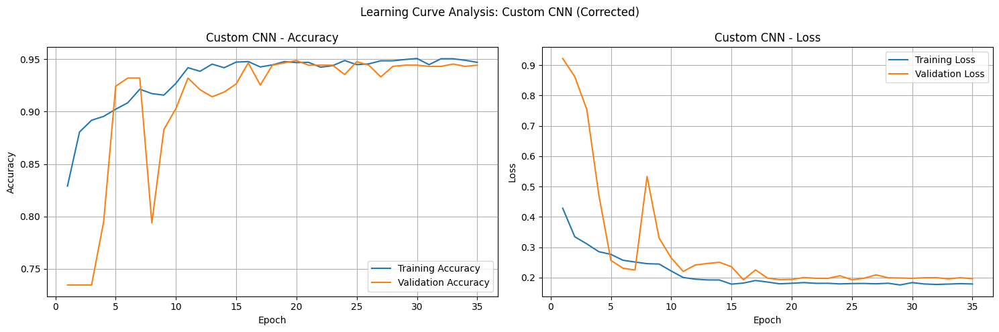

Epochs completed: 35
Best validation loss epoch: 25
Best validation loss: 0.1928064078092575
Saved graph: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/Learning_Curve_Analysis/custom_cnn_corrected_learning_curve.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

base = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

history_path = os.path.join(
    base,
    "corrected_experiments/augmentation_ablation/"
    "training_histories/corrected_pneumocnn_no_augmentation_history.csv"
)

output_dir = os.path.join(base, "Learning_Curve_Analysis")
os.makedirs(output_dir, exist_ok=True)

# Load corrected training history
df = pd.read_csv(history_path)

# Use actual epoch numbers if available
if "epoch" in df.columns:
    epochs = df["epoch"].to_numpy()
    if len(epochs) and epochs[0] == 0:
        epochs = epochs + 1
else:
    epochs = range(1, len(df) + 1)

# Create graphs
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy
axes[0].plot(epochs, df["accuracy"], label="Training Accuracy")
axes[0].plot(epochs, df["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Custom CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(epochs, df["loss"], label="Training Loss")
axes[1].plot(epochs, df["val_loss"], label="Validation Loss")
axes[1].set_title("Custom CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Learning Curve Analysis: Custom CNN (Corrected)")
plt.tight_layout()

graph_path = os.path.join(
    output_dir, "custom_cnn_corrected_learning_curve.png"
)

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Epochs completed:", len(df))
print("Best validation loss epoch:", df["val_loss"].idxmin() + 1)
print("Best validation loss:", df["val_loss"].min())
print("Saved graph:", graph_path)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

base = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

keywords = [
    "prediction",
    "probability",
    "probabilities",
    "y_test",
    "y_true",
    "y_score",
    "roc",
    "evaluation"
]

extensions = (".csv", ".npy", ".npz", ".pkl", ".pickle")

print("Searching for saved prediction and evaluation files...\n")

for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d not in [
        ".ipynb_checkpoints", "__pycache__"
    ]]

    for file in files:
        if file.lower().endswith(extensions):
            if any(word in file.lower() for word in keywords):
                print(os.path.join(root, file))


Searching for saved prediction and evaluation files...

/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/augmentation_ablation/predictions/corrected_ablation_predictions.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/vgg16/vgg16_corrected_test_predictions.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/resnet50/resnet50_corrected_test_predictions.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/densenet121/densenet121_corrected_test_predictions.csv
/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/corrected_experiments/five_model_comparison/inceptionv3/inceptionv3_corrected_test_predictions.csv


In [ ]:

import os
import pandas as pd

base = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

prediction_files = {
    "VGG16": f"{base}/corrected_experiments/five_model_comparison/vgg16/vgg16_corrected_test_predictions.csv",

    "ResNet50": f"{base}/corrected_experiments/five_model_comparison/resnet50/resnet50_corrected_test_predictions.csv",

    "DenseNet121": f"{base}/corrected_experiments/five_model_comparison/densenet121/densenet121_corrected_test_predictions.csv",

    "InceptionV3": f"{base}/corrected_experiments/five_model_comparison/inceptionv3/inceptionv3_corrected_test_predictions.csv",

    "Augmentation Ablation": f"{base}/corrected_experiments/augmentation_ablation/predictions/corrected_ablation_predictions.csv"
}

for model, path in prediction_files.items():

    print("\n" + "=" * 60)
    print(model)

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print("\nFirst five rows:")
    print(df.head().to_string(index=False))



VGG16
Shape: (866, 3)
Columns: ['actual_label', 'vgg16_probability', 'vgg16_prediction']

First five rows:
 actual_label  vgg16_probability  vgg16_prediction
            1           0.994099                 1
            1           0.998553                 1
            1           0.999568                 1
            1           0.979045                 1
            0           0.016021                 0

ResNet50
Shape: (866, 3)
Columns: ['actual_label', 'resnet50_probability', 'resnet50_prediction']

First five rows:
 actual_label  resnet50_probability  resnet50_prediction
            1              0.999821                    1
            1              0.999895                    1
            1              0.999876                    1
            1              0.956551                    1
            0              0.041478                    0

DenseNet121
Shape: (866, 3)
Columns: ['actual_label', 'densenet121_probability', 'densenet121_prediction']

First five rows:
 

In [ ]:

import os

base = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"

print("Searching for Custom CNN prediction files...\n")

for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d not in [
        ".ipynb_checkpoints", "__pycache__"
    ]]

    for file in files:
        if file.endswith(".csv") and (
            "cnn" in file.lower() or "pneumo" in file.lower()
        ):
            if "predict" in file.lower() or "test" in file.lower():
                print(os.path.join(root, file))


Searching for Custom CNN prediction files...




Custom CNN
Samples: 866
Calculated ROC-AUC: 0.987990
Confusion matrix:
[[222  16]
 [ 28 600]]
Matches recorded confusion matrix: True

VGG16
Samples: 866
Calculated ROC-AUC: 0.988305
Confusion matrix:
[[223  15]
 [ 20 608]]
Matches recorded confusion matrix: True

ResNet50
Samples: 866
Calculated ROC-AUC: 0.992480
Confusion matrix:
[[219  19]
 [ 14 614]]
Matches recorded confusion matrix: True

DenseNet121
Samples: 866
Calculated ROC-AUC: 0.989529
Confusion matrix:
[[222  16]
 [ 26 602]]
Matches recorded confusion matrix: True

InceptionV3
Samples: 866
Calculated ROC-AUC: 0.984311
Confusion matrix:
[[214  24]
 [ 22 606]]
Matches recorded confusion matrix: True


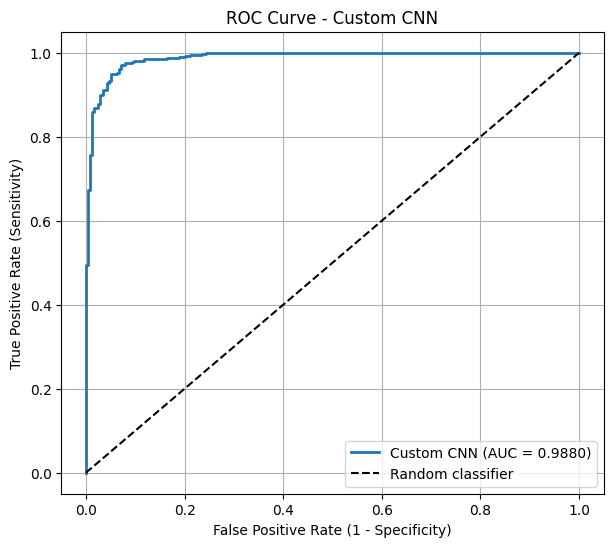

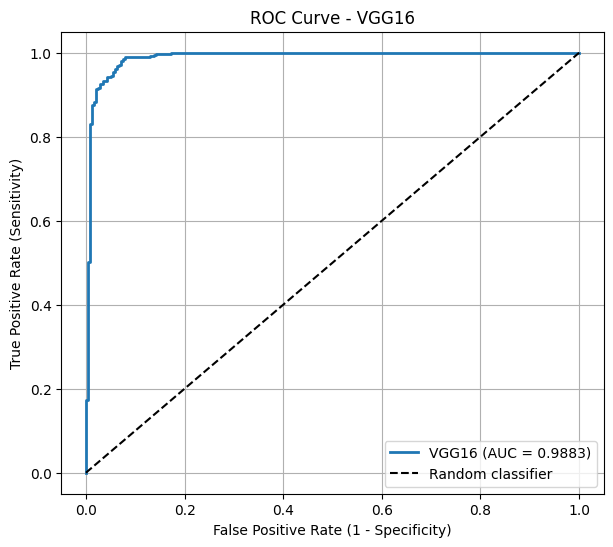

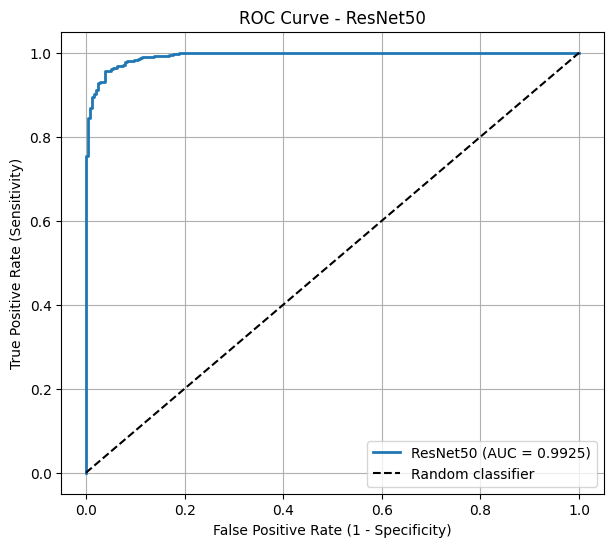

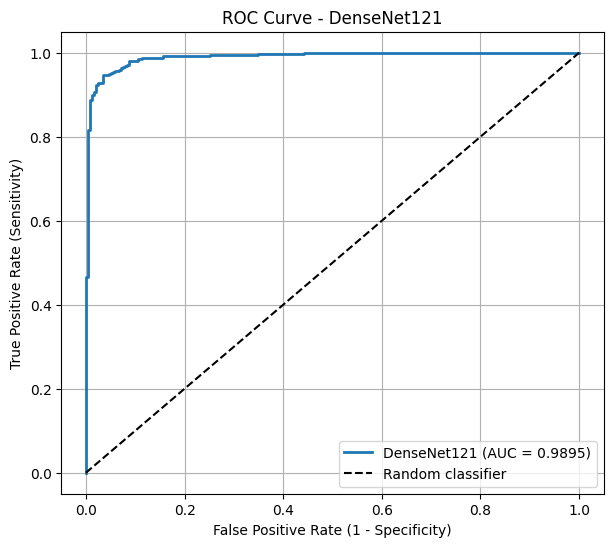

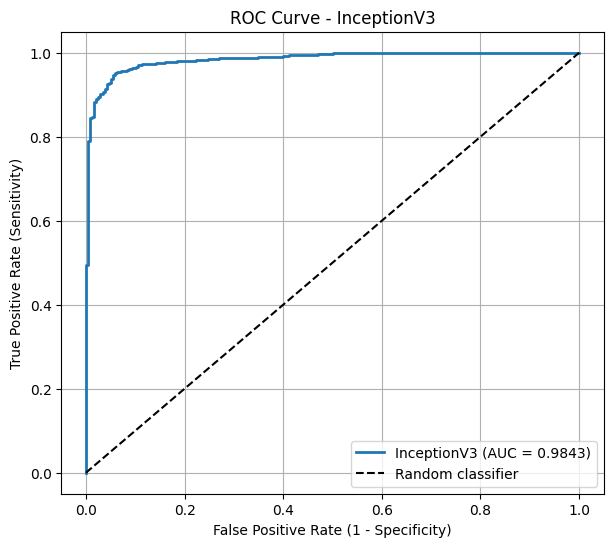

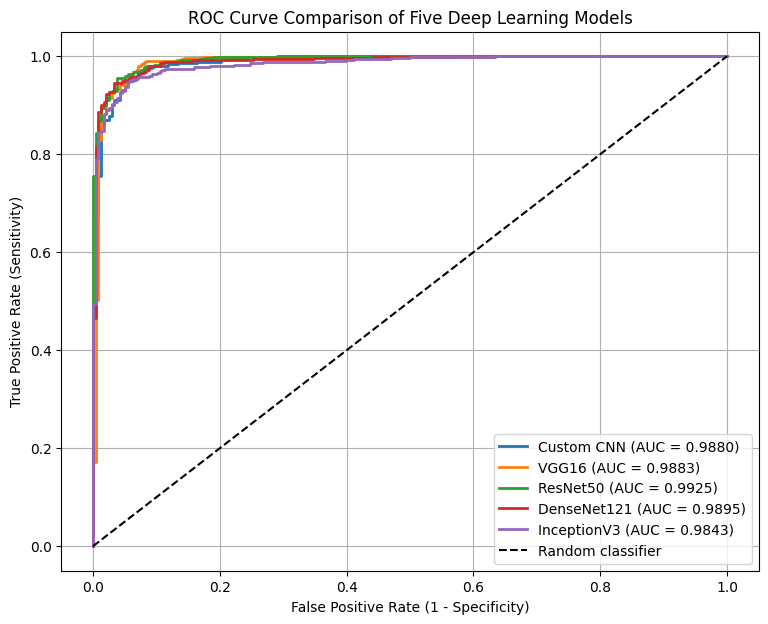


ROC analysis completed.
      Model  ROC_AUC
 Custom CNN 0.987990
      VGG16 0.988305
   ResNet50 0.992480
DenseNet121 0.989529
InceptionV3 0.984311

Saved results to: /content/drive/MyDrive/MPhil_Pneumonia_Detection_Research/ROC_Curve_Analysis


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix
)

base = "/content/drive/MyDrive/MPhil_Pneumonia_Detection_Research"
corrected = os.path.join(base, "corrected_experiments")

# Prediction file locations
files = {
    "Custom CNN": os.path.join(
        corrected, "augmentation_ablation/predictions/"
        "corrected_ablation_predictions.csv"
    ),
    "VGG16": os.path.join(
        corrected, "five_model_comparison/vgg16/"
        "vgg16_corrected_test_predictions.csv"
    ),
    "ResNet50": os.path.join(
        corrected, "five_model_comparison/resnet50/"
        "resnet50_corrected_test_predictions.csv"
    ),
    "DenseNet121": os.path.join(
        corrected, "five_model_comparison/densenet121/"
        "densenet121_corrected_test_predictions.csv"
    ),
    "InceptionV3": os.path.join(
        corrected, "five_model_comparison/inceptionv3/"
        "inceptionv3_corrected_test_predictions.csv"
    )
}

# Probability columns
probability_columns = {
    "Custom CNN": "no_augmentation_probability",
    "VGG16": "vgg16_probability",
    "ResNet50": "resnet50_probability",
    "DenseNet121": "densenet121_probability",
    "InceptionV3": "inceptionv3_probability"
}

# Expected confusion matrices from the corrected experiment
expected_cm = {
    "Custom CNN": [[222, 16], [28, 600]],
    "VGG16": [[223, 15], [20, 608]],
    "ResNet50": [[219, 19], [14, 614]],
    "DenseNet121": [[222, 16], [26, 602]],
    "InceptionV3": [[214, 24], [22, 606]]
}

predictions = {}
y_true_reference = None
verification_passed = True

# Load and verify all prediction files
for model, path in files.items():

    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing file: {path}")

    df = pd.read_csv(path)

    y_true = df["actual_label"].to_numpy()
    y_score = df[probability_columns[model]].to_numpy()

    if len(y_true) != 866:
        raise ValueError(f"{model}: Expected 866 test samples.")

    if not np.isfinite(y_score).all():
        raise ValueError(f"{model}: Invalid probability values.")

    if np.any((y_score < 0) | (y_score > 1)):
        raise ValueError(f"{model}: Probabilities must be between 0 and 1.")

    # Confirm identical test-label ordering
    if y_true_reference is None:
        y_true_reference = y_true
    elif not np.array_equal(y_true_reference, y_true):
        raise ValueError(
            f"{model}: Test labels/order do not match other models."
        )

    auc_value = roc_auc_score(y_true, y_score)

    # Verify threshold-based predictions where available
    if model == "Custom CNN":
        y_pred = df["no_augmentation_prediction"].to_numpy()
    else:
        prediction_column = {
            "VGG16": "vgg16_prediction",
            "ResNet50": "resnet50_prediction",
            "DenseNet121": "densenet121_prediction",
            "InceptionV3": "inceptionv3_prediction"
        }[model]
        y_pred = df[prediction_column].to_numpy()

    actual_cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    cm_matches = np.array_equal(
        actual_cm, np.array(expected_cm[model])
    )

    print(f"\n{model}")
    print("Samples:", len(y_true))
    print(f"Calculated ROC-AUC: {auc_value:.6f}")
    print("Confusion matrix:")
    print(actual_cm)
    print("Matches recorded confusion matrix:", cm_matches)

    if not cm_matches:
        verification_passed = False
        print("WARNING: Investigate this model before final reporting.")

    predictions[model] = y_score

if not verification_passed:
    raise ValueError(
        "At least one confusion matrix differs from the recorded results. "
        "Do not finalise the ROC figures until this is investigated."
    )

# Create output folder
output_dir = os.path.join(base, "ROC_Curve_Analysis")
os.makedirs(output_dir, exist_ok=True)

# Calculate and save ROC results
roc_results = []

for model, y_score in predictions.items():

    fpr, tpr, thresholds = roc_curve(
        y_true_reference, y_score
    )

    auc_value = roc_auc_score(
        y_true_reference, y_score
    )

    roc_results.append({
        "Model": model,
        "ROC_AUC": auc_value
    })

    # Individual ROC curve
    plt.figure(figsize=(7, 6))
    plt.plot(
        fpr, tpr,
        label=f"{model} (AUC = {auc_value:.4f})",
        linewidth=2
    )
    plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

    plt.xlabel("False Positive Rate (1 - Specificity)")
    plt.ylabel("True Positive Rate (Sensitivity)")
    plt.title(f"ROC Curve - {model}")
    plt.legend(loc="lower right")
    plt.grid(True)

    safe_name = model.replace(" ", "_").lower()

    plt.savefig(
        os.path.join(output_dir, f"{safe_name}_ROC.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# Combined ROC comparison
plt.figure(figsize=(9, 7))

for model, y_score in predictions.items():

    fpr, tpr, thresholds = roc_curve(
        y_true_reference, y_score
    )

    auc_value = roc_auc_score(
        y_true_reference, y_score
    )

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{model} (AUC = {auc_value:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve Comparison of Five Deep Learning Models")
plt.legend(loc="lower right")
plt.grid(True)

plt.savefig(
    os.path.join(output_dir, "combined_ROC_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Save AUC summary
results_df = pd.DataFrame(roc_results)
results_df.to_csv(
    os.path.join(output_dir, "ROC_AUC_summary.csv"),
    index=False
)

print("\nROC analysis completed.")
print(results_df.to_string(index=False))
print("\nSaved results to:", output_dir)


In [ ]:

import shutil
from google.colab import files

zip_path = "/content/ROC_Curve_Analysis.zip"

shutil.make_archive(
    "/content/ROC_Curve_Analysis",
    "zip",
    output_dir
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>